In [1]:
import numpy as np
import napari
import sys
#sys.path.append(r'C:\Users\carlos\Desktop\FittingDapiFeatsD106-main')
from ioMicro import*
from ioMicroPostFits import*


In [2]:
if False:
    fls = glob.glob(r'\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\DNA\H1_NC_set*\*.zarr')
    
    icol=0
    from tqdm import tqdm
    immed = np.median([np.array(read_im(fl)[icol][20],dtype=np.float32) for fl in tqdm(fls[:500])],axis=0)
    np.savez(rf'C:\Scripts\Jess\MYH67_DNA_RNA\flat_field_kiwi\Myh67kiwiDNA_med_col_raw{icol}.npz',im=immed)

In [3]:
#\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__152--H19_NC_set3--col0__Xhfits.npz

In [84]:
#analysis_folder = r'\\merfish10.ucsd.edu\volume1\20231121D110Myh67d15WT\AnalysisDeconvolveBBD110'#D110
analysis_folder = r'\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits'#D104
cp=chromatin_postfits(save_folder =analysis_folder,
                 tag = '*--H*_set1--col0__Xhfits.npz',exclude_tag = None,tag_save='',remap=True)

[42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42]
Detected fovs: 121 [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), n

In [85]:
fls = cp.dic_fls[55]
fls[10]

np.str_('\\\\merfish13\\Public\\Fugui_Jess\\Myh67_mouse_Kiwi_09_21_2026\\xfits\\Conv_zscan__055--H41_NC_set1--col0__Xhfits.npz')

In [10]:
#import torch


In [6]:
#cp.dic_fls

In [86]:
def get_R(fl,letter): 
    try:
        return int(get_Htag(fl).split('_')[0][1:])#[icol]
    except:
        return -1
def reorder_on_R(fls,letter):
    return np.array(fls)[np.argsort([get_R(fl,letter) for fl in fls])]

In [87]:
cp.save_folder

'\\\\merfish13\\Public\\Fugui_Jess\\Myh67_mouse_Kiwi_09_21_2026\\xfits'

In [92]:
def get_best_translation_points(X,X_ref,resc=10,target=2.5,return_counts=False):
    
    im,Xm = get_im_from_Xh(X,resc=resc)
    im_ref,Xm_ref = get_im_from_Xh(X_ref,resc=resc)
    
    from scipy.signal import fftconvolve
    im_cor = fftconvolve(im,im_ref[::-1,::-1,::-1])
    #plt.imshow(np.max(im_cor,0))
    tzxy = np.array(np.unravel_index(np.argmax(im_cor),im_cor.shape))-im_ref.shape+1+Xm-Xm_ref
    tzxy = tzxy*resc
    Npts=0
    tzxy,Npts = get_Xtzxy(X,X_ref,tzxy,resc=resc,target=target)
    if return_counts:
        return tzxy,Npts
    return tzxy

In [93]:
def get_best_translation_pointsV2(fl,fl_ref,resc=5,th=4.5):
    obj = np.load(fl)
    obj_Xh_plus  = obj['Xh_plus']
    obj_Xh_minus  = obj['Xh_minus']
    obj_Xh_plus = obj_Xh_plus[obj_Xh_plus[:,-1]>th]
    obj_Xh_minus = obj_Xh_minus[obj_Xh_minus[:,-1]>th]
    
    obj_ref = np.load(fl_ref)
    obj_ref_Xh_plus  = obj_ref['Xh_plus']
    obj_ref_Xh_minus  = obj_ref['Xh_minus']
    obj_ref_Xh_plus = obj_ref_Xh_plus[obj_ref_Xh_plus[:,-1]>th]
    obj_ref_Xh_minus = obj_ref_Xh_minus[obj_ref_Xh_minus[:,-1]>th]
    
    tzxyf,tzxy_plus,tzxy_minus,N_plus,N_minus = np.array([0,0,0]),np.array([0,0,0]),np.array([0,0,0]),0,0
    if (len(obj_Xh_plus)>0) and (len(obj_ref_Xh_plus)>0):
        X = obj_Xh_plus[:,:3]
        X_ref = obj_ref_Xh_plus[:,:3]
        tzxy_plus,N_plus = get_best_translation_points(X,X_ref,resc=resc,return_counts=True)
    if (len(obj_Xh_minus)>0) and (len(obj_ref_Xh_minus)>0):
        X = obj_Xh_minus[:,:3]
        X_ref = obj_ref_Xh_minus[:,:3]
        tzxy_minus,N_minus = get_best_translation_points(X,X_ref,resc=resc,return_counts=True)
    if np.max(np.abs(tzxy_minus-tzxy_plus))<=2:
        tzxyf = -(tzxy_plus*N_plus+tzxy_minus*N_minus)/(N_plus+N_minus)
    else:
        tzxyf = -[tzxy_plus,tzxy_minus][np.argmax([N_plus,N_minus])]
    return [tzxyf,tzxy_plus,tzxy_minus,N_plus,N_minus]

In [99]:

### Compute the drift for all hybes #########################
def set_fls(cp,ifov,tag_save='best_per_cell'):
    cp.ifov = ifov
    ### map the file  ##################################
    cp.set_ = ''
    fls = cp.dic_fls[cp.ifov]
    cp.fls = reorder_on_R(fls,'R')
    cp.fov = get_fullfov(fls[0])
    cp.save_fld_cell = cp.save_folder+os.sep+tag_save
    save_fld_cell = cp.save_fld_cell
    if not os.path.exists(save_fld_cell): os.makedirs(save_fld_cell)
    cp.save_fl = save_fld_cell+os.sep+cp.fov+'--'+cp.set_+'__XHfs_finedrft.npz'
def load_XH(cp,segm_tag= 'H1_NC_set1'):
    fls = cp.fls
    save_fld_cell = cp.save_fld_cell
    to_dapi_dic = {fitfl:fit_fl_TO_dapiFeat_fl(fitfl) for fitfl in fls}
    dapi_fls = np.unique(list(to_dapi_dic.values()))
    dapi_fls = list(dapi_fls)#+[r'\\merfish12.ucsd.edu\Public\20231024_RD129_N5S2heart_RNA_analysis'+os.sep+cp.fov+'--H19_Q55_56_57--dapiFeatures.npz']
    
    redo_drift=False
    drift_fl  = save_fld_cell+os.sep+'driftNew_'+cp.fov+'--'+cp.set_+'.pkl'
    cp.dapi_fls = dapi_fls
    if not os.path.exists(drift_fl) or redo_drift:
        fl_ref = dapi_fls[0]
    
        dic_drift = {}
        for fl in tqdm(dapi_fls):
            print(fl)
            print(fl_ref)
            dic_drift[fl] = get_best_translation_pointsV2(fl,fl_ref,resc=5,th=0)
            print(dic_drift[fl])
    
        pickle.dump([list(dic_drift.values()),list(dic_drift.keys()),cp.fov,fl_ref],open(drift_fl,'wb'))
    
    drifts,fls_,fov_,fl_ref = np.load(drift_fl,allow_pickle=True)
    dic_drift = {get_Htag(fl_):drft[0] for fl_,drft in zip(fls_,drifts)}
    #dic_drift = dict(zip(fls_,drifts))
    cp.drifts = drifts
    cp.driftfls = fls_
    cp.dic_drift=dic_drift
    print("Maximum drift:",np.max([np.abs(dic_drift[key][0]) for key in dic_drift],axis=0))


    
    ### load all the fitted data ##################################
    
    XH = None
    print("Load the fitted data and apply drift correction to dots...")
    for fl in tqdm(fls):
        #Xhs,dic_drift = pickle.load(open(fl,'rb'))
        Xh = np.load(fl,allow_pickle=True)['Xh']
        if len(Xh.shape)>0:
            Xh = Xh[Xh[:,-2]>0.25]
            drift = dic_drift[get_Htag(fl)]
            Xh[:,:3] = Xh[:,:3]+drift ################what sign - this is a plus on Kiwi
            iR = get_R(fl,'R')-1
            icol = get_icol(fl)
            Xh_ = np.concatenate([Xh,np.array([[icol,iR]]*len(Xh))],axis=-1)
            if XH is None:
                XH = Xh_
            else:
                XH = np.concatenate([XH,Xh_],axis=0)
    if segm_tag in dic_drift:
        tzxy_seg = np.round(dic_drift[segm_tag]).astype(int)
    else:
        assert(False)

    XH[:,:3] = XH[:,:3]-dic_drift[segm_tag]
    cp.XH = XH
    # Xim = XH[:,1:3]
    
    
    # tz,tx,ty = dic_drift[segm_tag]
    
    # XimT = Xim.copy()
    
    # XimT = XimT-(tz,tx,ty)
    
    # XH[:,1:3] = XimT
    # cp.XH = XH
    

def load_segmentation(cp,fl_structure = r'\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\segmentation\*_H1_NC_set1.npz',pix_sz=[0.5,0.1083333,0.1083333]):
    fl_seg = fl_structure.replace('*',cp.fov)
    cp.fl_seg=fl_seg
    dic_seg = np.load(fl_seg)
    segm = dic_seg['segm']
    shape = dic_seg['shape']
    resc = np.round(shape/segm.shape).astype(int)
    cp.resc=resc
    cp.segm=segm
    cp.XR = cp.XH[:,:3]/resc
    XRT=np.round(cp.XR).astype(int)
    keep = np.all((XRT>=0)&(XRT<segm.shape),axis=-1)
    cellids = np.zeros(len(XRT))
    cellids[keep] = segm[tuple(XRT[keep].T)]
    ifov_tag = cp.ifov*10**5
    cellids[cellids>0]=cellids[cellids>0]+ifov_tag
    cp.cellids = cellids
    cp.XR_um = cp.XH[:,:3]*pix_sz

In [100]:
# fl_seg = r'\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\segmentation\Conv_zscan__000_H1_NC_set2.npz'
# dic_seg = np.load(fl_seg)
# segm = dic_seg['segm']
# shape = dic_seg['shape']
# shape,segm.shape

In [101]:
#??get_best_translation_pointsV2

In [102]:
ifov= 55
set_fls(cp,ifov,tag_save='best_per_cell')


In [103]:
# dicc = np.load(r'\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__076--H12_NC_set2--dapiFeatures.npz')
# np.mean(dicc['Xh_minus'][:,:3],axis=0)

In [104]:
load_XH(cp)

Maximum drift: 8.928554826070448
Load the fitted data and apply drift correction to dots...


100%|██████████| 42/42 [10:45<00:00, 15.37s/it]


In [105]:
#load_XH(cp)
load_segmentation(cp)

In [82]:
np.min(cp.XH[:,-1])

np.float64(0.0)

100%|██████████| 931/931 [00:14<00:00, 65.11it/s]


Detected number of chromosomes:1596
Number of cells with 1 chromosomes: 204
Number of cells with 2 chromosomes: 696


100%|██████████| 1596/1596 [00:00<00:00, 3761.06it/s]


EM iteration number:  1


100%|██████████| 1596/1596 [00:08<00:00, 198.94it/s]


fraction the same: 0.6062179257667979
fraction nan: 0.08561582527747941
EM iteration number:  2


... (2 outputs left out)

100%|██████████| 1596/1596 [00:07<00:00, 216.96it/s]


fraction the same: 0.9582289055973267
fraction nan: 0.08561582527747941
EM iteration number:  4


100%|██████████| 1596/1596 [00:07<00:00, 207.81it/s]


fraction the same: 0.9816654732068266
fraction nan: 0.08561582527747941


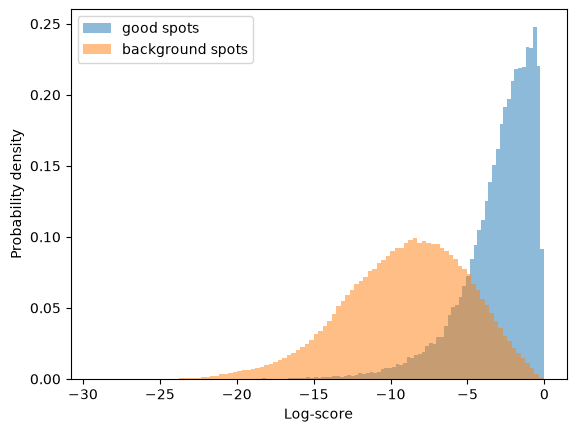

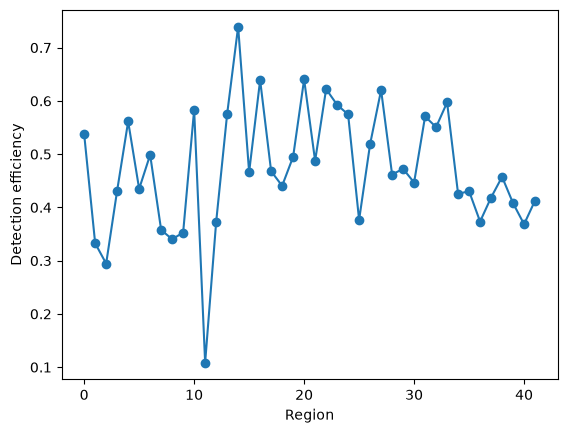

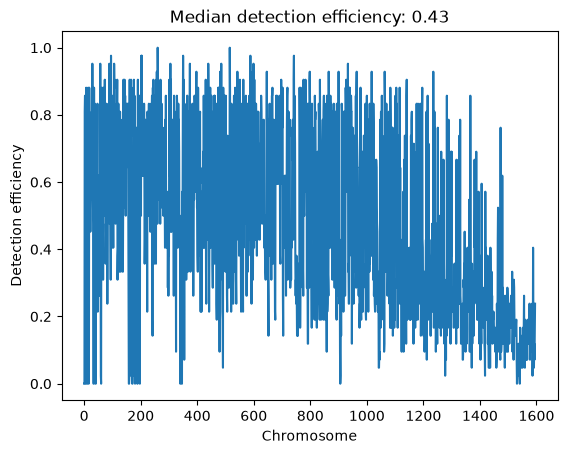

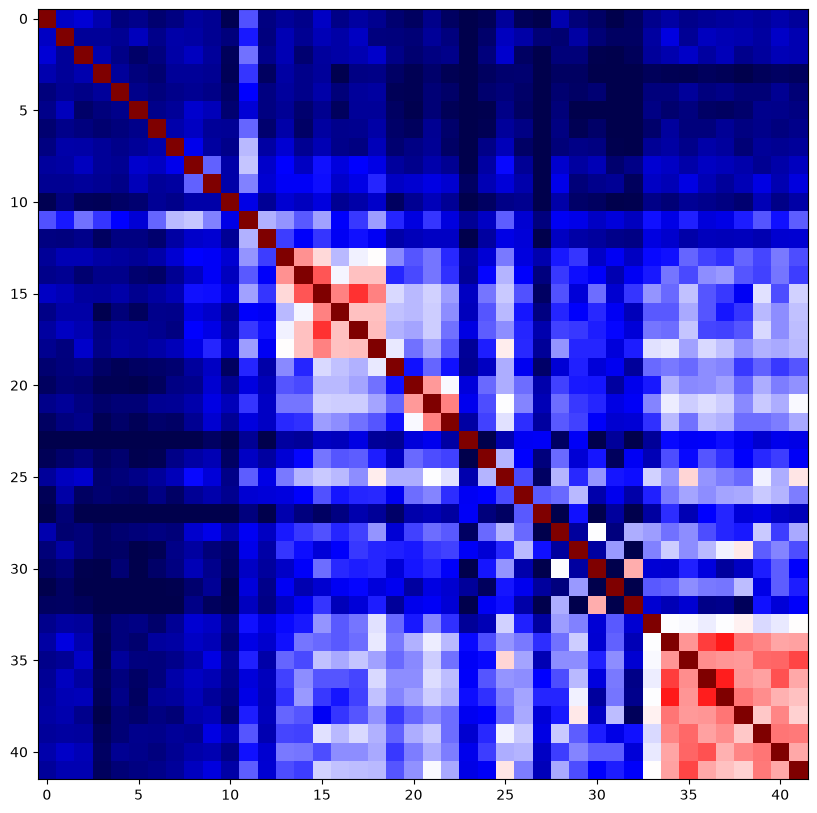

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__055--__XHfs_finedrft_save.npz


In [106]:
XH_f = np.concatenate([cp.XR_um,cp.XH,cp.cellids[:,np.newaxis]],axis=-1)
#XH_f = XH_f[XH_f[:,-2]<1000]
XH_f = XH_f[XH_f[:,-1]>0]
cp.XH_f=XH_f
XH_fs = keep_best_per_cell_fast(XH_f,nbest=100)
cp.XH_fs=XH_fs
np.savez(cp.save_fl,XH_fs=XH_fs)
cp.save_flf= cp.save_fl.replace('.npz','_save.npz')
#if not os.path.exists(cp.save_flf):

get_X_cands(cp,keep_best_per_cell_fast(XH_fs,30),nchr_=2,pix=[1,1,1],
                     radius_chr = 1.5,radius_cand =2,fr_th=0.4,nelems=5,plt_val = False)

uRs = np.arange(42)#np.unique(XH_fs[:,-2],axis=-1).astype(int)
initialize_with_max_brightness(cp,nkeep = 8000,Rs_u = uRs)

#normalize_color_brightnesses(cp)
cp.X_cands_=cp.X_cands
run_EM(cp,nkeep = 80000,niter = 4,Rs_u = uRs)

get_scores_and_threshold(cp,th_score = -2.5)
plot_matrix(cp,th_score=-2.5,lazy_color_correction = False,vmin=0,vmax=0.6)
plt.show()
np.savez(cp.save_flf,zxys_f = cp.zxys_f,hs_f = cp.hs_f,cells_f=cp.icell_cands,scores_f=cp.scores_f)
print("Saved:",cp.save_flf)

In [139]:

uRs

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33])

100%|██████████| 931/931 [00:06<00:00, 147.06it/s]


Detected number of chromosomes:1615
Number of cells with 1 chromosomes: 201
Number of cells with 2 chromosomes: 707


100%|██████████| 1615/1615 [00:00<00:00, 4723.06it/s]


EM iteration number:  1


100%|██████████| 1615/1615 [00:04<00:00, 374.81it/s]


fraction the same: 0.6463121471498816
fraction nan: 0.09266071753778911
EM iteration number:  2


... (2 outputs left out)

100%|██████████| 1615/1615 [00:04<00:00, 380.60it/s]


fraction the same: 0.9702604261518849
fraction nan: 0.09266071753778911
EM iteration number:  4


100%|██████████| 1615/1615 [00:04<00:00, 384.22it/s]


fraction the same: 0.9880349663085048
fraction nan: 0.09266071753778911


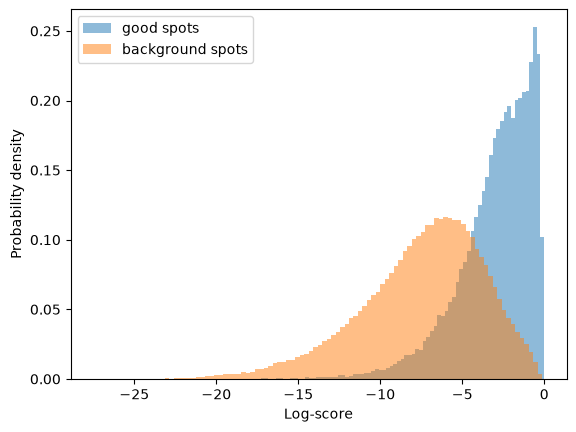

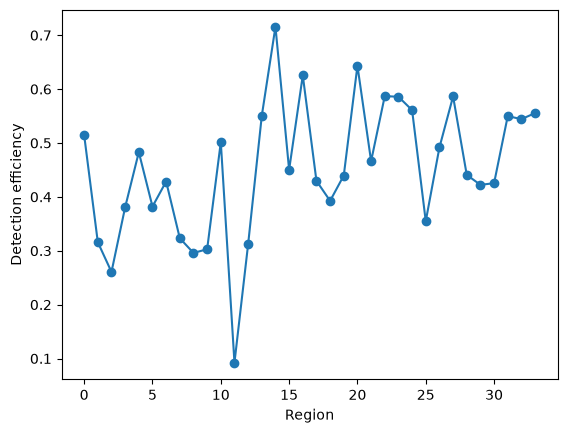

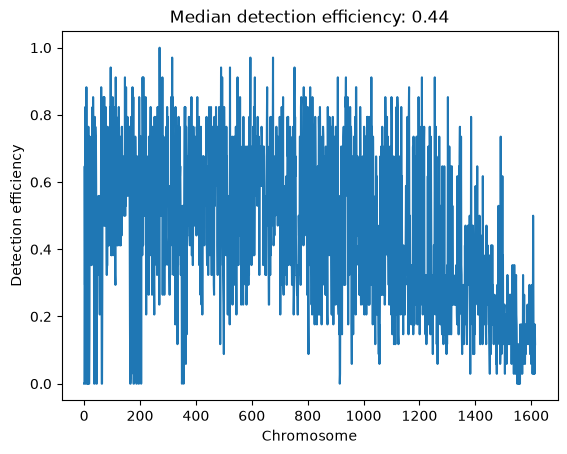

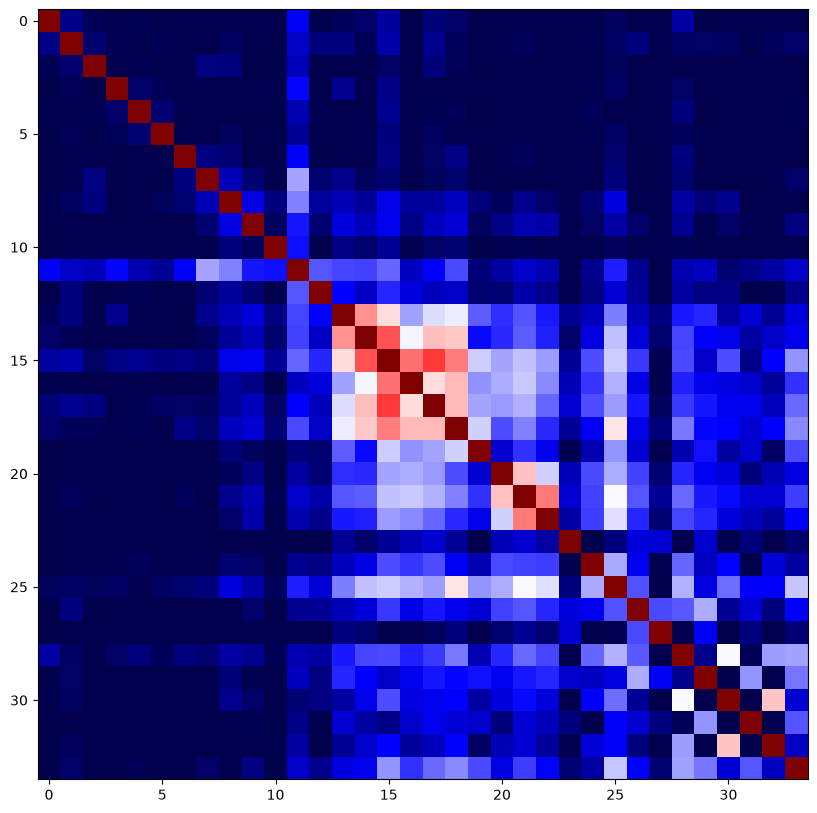

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__055--__XHfs_finedrft_save.npz


In [140]:
nRegs = 34
uRs = np.arange(nRegs)
XH_f = np.concatenate([cp.XR_um,cp.XH,cp.cellids[:,np.newaxis]],axis=-1)
XH_f = XH_f[XH_f[:,-2]<nRegs]
XH_f = XH_f[XH_f[:,-1]>0]
cp.XH_f=XH_f
XH_fs = keep_best_per_cell_fast(XH_f,nbest=100)
cp.XH_fs=XH_fs
np.savez(cp.save_fl,XH_fs=XH_fs)
cp.save_flf= cp.save_fl.replace('.npz','_save.npz')
#if not os.path.exists(cp.save_flf):

get_X_cands(cp,keep_best_per_cell_fast(XH_fs,30),nchr_=2,pix=[1,1,1],
                     radius_chr = 1.5,radius_cand =2,fr_th=0.4,nelems=5,plt_val = False)

#uRs = np.arange(42)#np.unique(XH_fs[:,-2],axis=-1).astype(int)
initialize_with_max_brightness(cp,nkeep = 8000,Rs_u = uRs)

#normalize_color_brightnesses(cp)
cp.X_cands_=cp.X_cands
run_EM(cp,nkeep = 80000,niter = 4,Rs_u = uRs)

get_scores_and_threshold(cp,th_score = -2.5)
plot_matrix(cp,th_score=-2.5,lazy_color_correction = False,vmin=0,vmax=0.6)
plt.show()
np.savez(cp.save_flf,zxys_f = cp.zxys_f,hs_f = cp.hs_f,cells_f=cp.icell_cands,scores_f=cp.scores_f)
print("Saved:",cp.save_flf)

In [131]:
self = cp
th_score=-1.5
#self.th_score = th_score
Xf = np.array(self.zxys_f)
bad = np.log(self.scores_f)<th_score
Xf[bad] = np.nan
from scipy.spatial.distance import pdist,squareform
mats = np.array([squareform(pdist(X_)) for X_ in Xf])

C:\Users\Scope7a1\AppData\Local\Temp\ipykernel_24004\238657151.py:1: RuntimeWarning: invalid value encountered in divide
  plt.imshow(np.log(np.sum(mats<0.25,axis=0)/np.sum(mats>=0.,axis=0)),cmap='seismic')
C:\Users\Scope7a1\AppData\Local\Temp\ipykernel_24004\238657151.py:1: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(np.sum(mats<0.25,axis=0)/np.sum(mats>=0.,axis=0)),cmap='seismic')


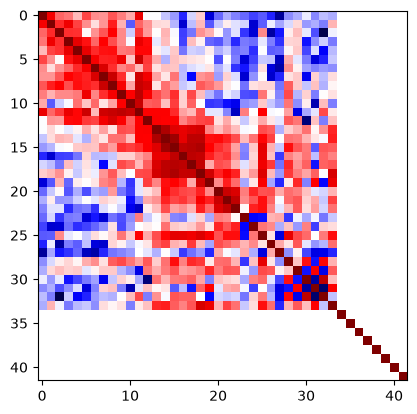

In [133]:
plt.imshow(np.log(np.sum(mats<0.25,axis=0)/np.sum(mats>=0.,axis=0)),cmap='seismic')

In [123]:
np.nanmedian(mats)

np.float64(0.3953839552696103)

In [107]:
npbs = np.array([33, 27, 25, 41, 49, 44, 42, 31, 40, 43, 45, 45, 45, 47, 47, 14, 41, 43, 22, 28, 28, 36, 38, 40, 43, 12, 48, 46, 45, 19, 35, 42, 40, 29, 0, 0, 0, 0, 0, 0, 0, 0])
np.sum(npbs>0)

np.int64(34)

In [141]:
npbs[uRs]

array([33, 27, 25, 41, 49, 44, 42, 31, 40, 43, 45, 45, 45, 47, 47, 14, 41,
       43, 22, 28, 28, 36, 38, 40, 43, 12, 48, 46, 45, 19, 35, 42, 40, 29])

In [ ]:
ifov= 55
set_fls(cp,ifov,tag_save='best_per_cell')
load_XH(cp)
XH_f = np.concatenate([cp.XR_um,cp.XH,cp.cellids[:,np.newaxis]],axis=-1)
#XH_f = XH_f[XH_f[:,-2]<1000]
XH_f = XH_f[XH_f[:,-1]>0]
cp.XH_f=XH_f
XH_fs = keep_best_per_cell_fast(XH_f,nbest=100)
cp.XH_fs=XH_fs
np.savez(cp.save_fl,XH_fs=XH_fs)
cp.save_flf= cp.save_fl.replace('.npz','_save.npz')
#if not os.path.exists(cp.save_flf):

get_X_cands(cp,keep_best_per_cell_fast(XH_fs,30),nchr_=2,pix=[1,1,1],
                     radius_chr = 1.5,radius_cand =2,fr_th=0.4,nelems=5,plt_val = False)

uRs = np.arange(42)#np.unique(XH_fs[:,-2],axis=-1).astype(int)
initialize_with_max_brightness(cp,nkeep = 8000,Rs_u = uRs)

#normalize_color_brightnesses(cp)
cp.X_cands_=cp.X_cands
run_EM(cp,nkeep = 80000,niter = 4,Rs_u = uRs)

get_scores_and_threshold(cp,th_score = -2.5)
plot_matrix(cp,th_score=-2.5,lazy_color_correction = False,vmin=0,vmax=0.6)
plt.show()
np.savez(cp.save_flf,zxys_f = cp.zxys_f,hs_f = cp.hs_f,cells_f=cp.icell_cands,scores_f=cp.scores_f)
print("Saved:",cp.save_flf)

In [ ]:
nRegs = 34
uRs = np.arange(nRegs)
XH_f = np.concatenate([cp.XR_um,cp.XH,cp.cellids[:,np.newaxis]],axis=-1)
XH_f = XH_f[XH_f[:,-2]<nRegs]
XH_f = XH_f[XH_f[:,-1]>0]
cp.XH_f=XH_f
XH_fs = keep_best_per_cell_fast(XH_f,nbest=100)
cp.XH_fs=XH_fs
np.savez(cp.save_fl,XH_fs=XH_fs)
cp.save_flf= cp.save_fl.replace('.npz','_save.npz')
#if not os.path.exists(cp.save_flf):

get_X_cands(cp,keep_best_per_cell_fast(XH_fs,30),nchr_=2,pix=[1,1,1],
                     radius_chr = 1.5,radius_cand =2,fr_th=0.4,nelems=5,plt_val = False)

#uRs = np.arange(42)#np.unique(XH_fs[:,-2],axis=-1).astype(int)
initialize_with_max_brightness(cp,nkeep = 8000,Rs_u = uRs)

#normalize_color_brightnesses(cp)
cp.X_cands_=cp.X_cands
run_EM(cp,nkeep = 80000,niter = 4,Rs_u = uRs)

get_scores_and_threshold(cp,th_score = -2.5)
plot_matrix(cp,th_score=-2.5,lazy_color_correction = False,vmin=0,vmax=0.6)
plt.show()
np.savez(cp.save_flf,zxys_f = cp.zxys_f,hs_f = cp.hs_f,cells_f=cp.icell_cands,scores_f=cp.scores_f)
print("Saved:",cp.save_flf)

  2%|▏         | 1/42 [00:00<00:07,  5.81it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H10_NC_set1--dapiFeatures.npz
[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(462), np.int64(618)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H10_NC_set1--dapiFeatures.npz



  5%|▍         | 2/42 [00:01<00:25,  1.54it/s]

[array([ 2.1823817e-01, -6.2976654e+02, -1.0497393e+01], dtype=float32), array([-1.0247843e-01,  5.7427814e+02,  1.0675439e+01], dtype=float32), array([-2.1823817e-01,  6.2976654e+02,  1.0497393e+01], dtype=float32), np.int64(67), np.int64(75)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H12_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H10_NC_set1--dapiFeatures.npz



  7%|▋         | 3/42 [00:01<00:20,  1.92it/s]

[array([-1.1740594e-01, -3.1513440e+02,  1.6593112e-01], dtype=float32), array([ -4.8890576, 229.499    , -24.849508 ], dtype=float32), array([ 1.1740594e-01,  3.1513440e+02, -1.6593112e-01], dtype=float32), np.int64(40), np.int64(65)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H13_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__000--H10_NC_set1--dapiFeatures.npz


... (99 outputs left out)

fraction the same: 0.9358974358974359
fraction nan: 0.07239819004524888
EM iteration number:  4



100%|██████████| 39/39 [00:00<00:00, 375.38it/s]


fraction the same: 0.971342383107089
fraction nan: 0.07239819004524888


C:\Scripts\Jess\MYH67_DNA_RNA\ioMicroPostFits.py:582: RuntimeWarning: All-NaN slice encountered
  plt.imshow(np.nanmedian(mats[:,keep][:,:,keep],0),vmax=vmax,vmin=vmin,cmap='seismic_r')


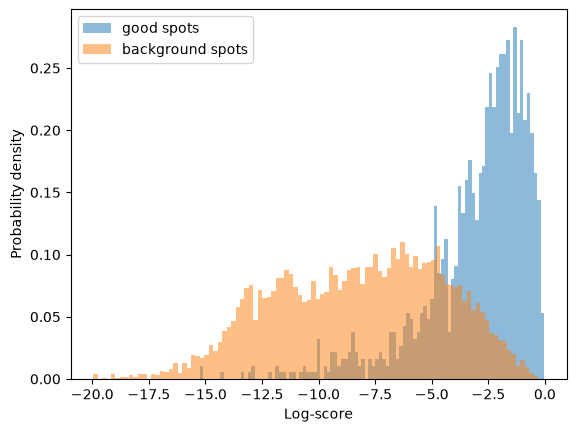

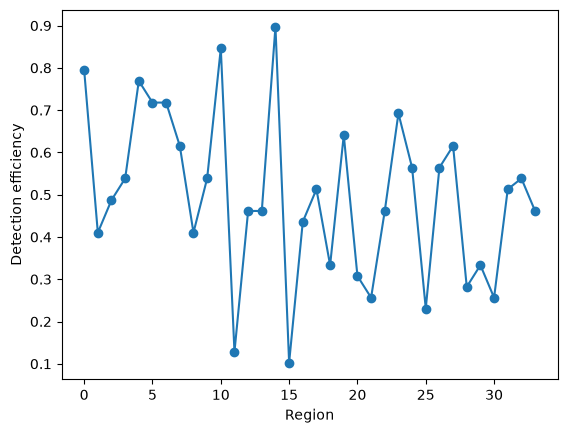

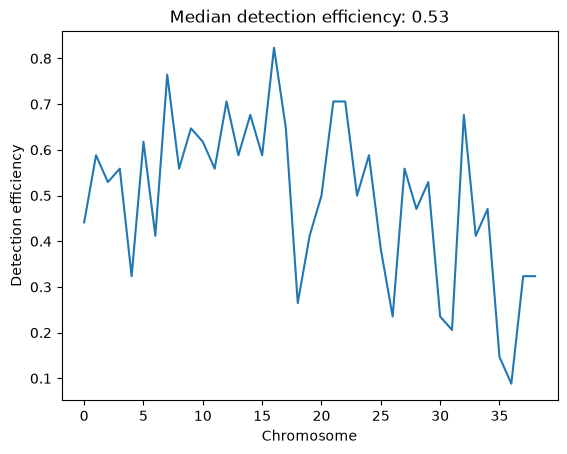

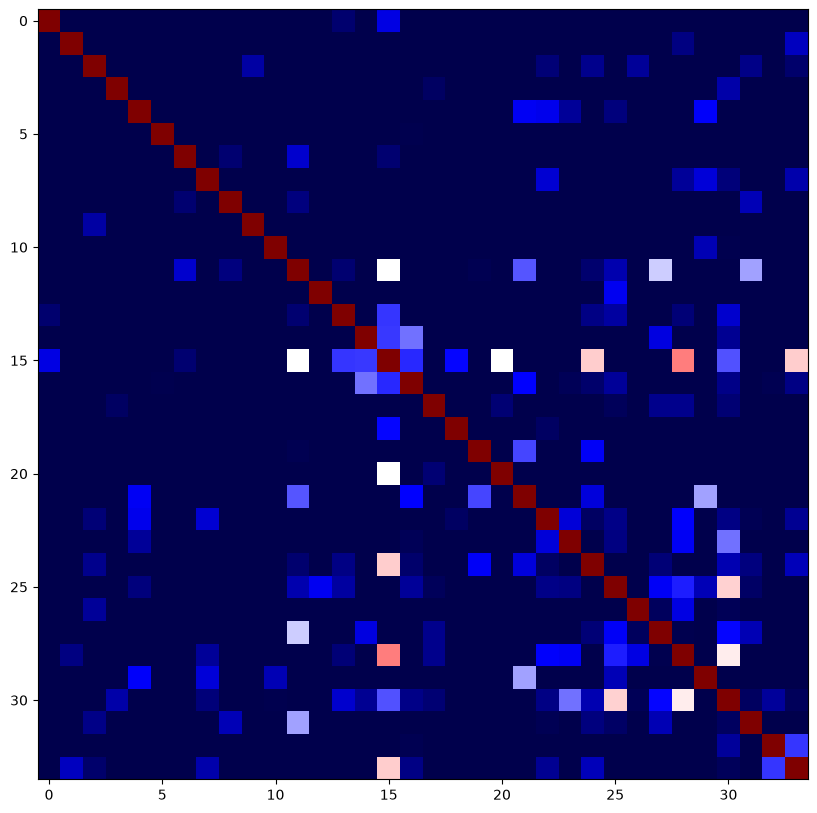

  2%|▏         | 2/121 [00:34<39:58, 20.15s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__001--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__002--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__002--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:27,  1.51it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28708), np.int64(3282)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__002--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__002--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1352/1352 [00:04<00:00, 271.28it/s]


fraction the same: 0.9391750783153499
fraction nan: 0.06861294813783501
EM iteration number:  4



100%|██████████| 1352/1352 [00:04<00:00, 271.66it/s]


fraction the same: 0.9720240167072747
fraction nan: 0.06861294813783501


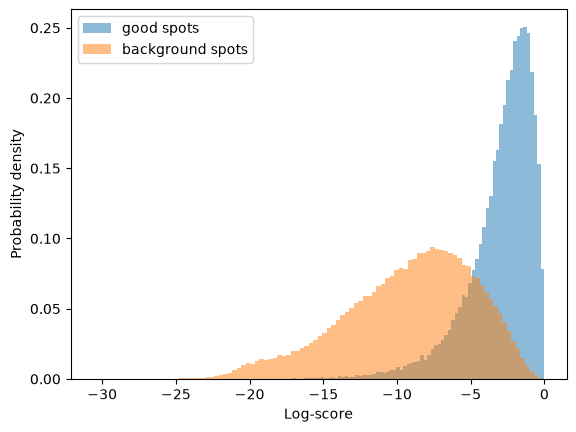

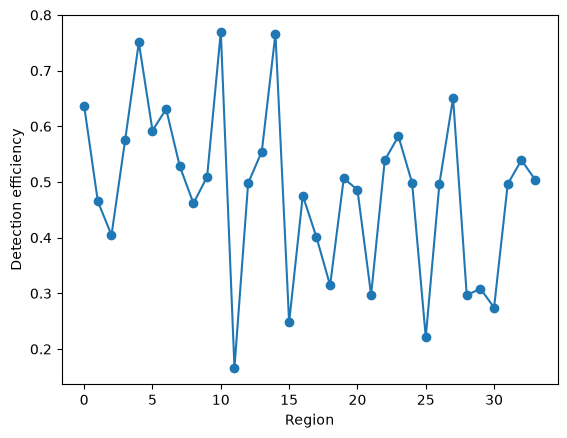

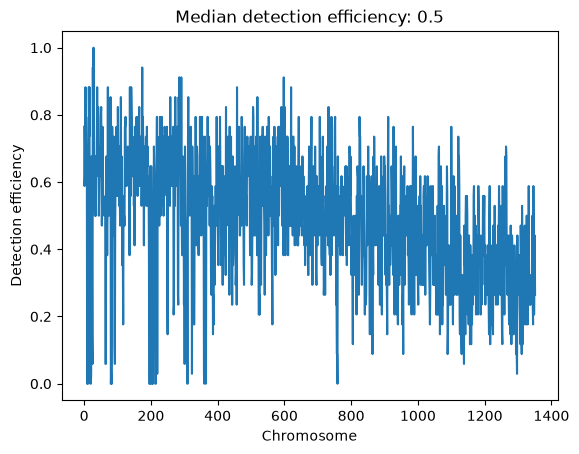

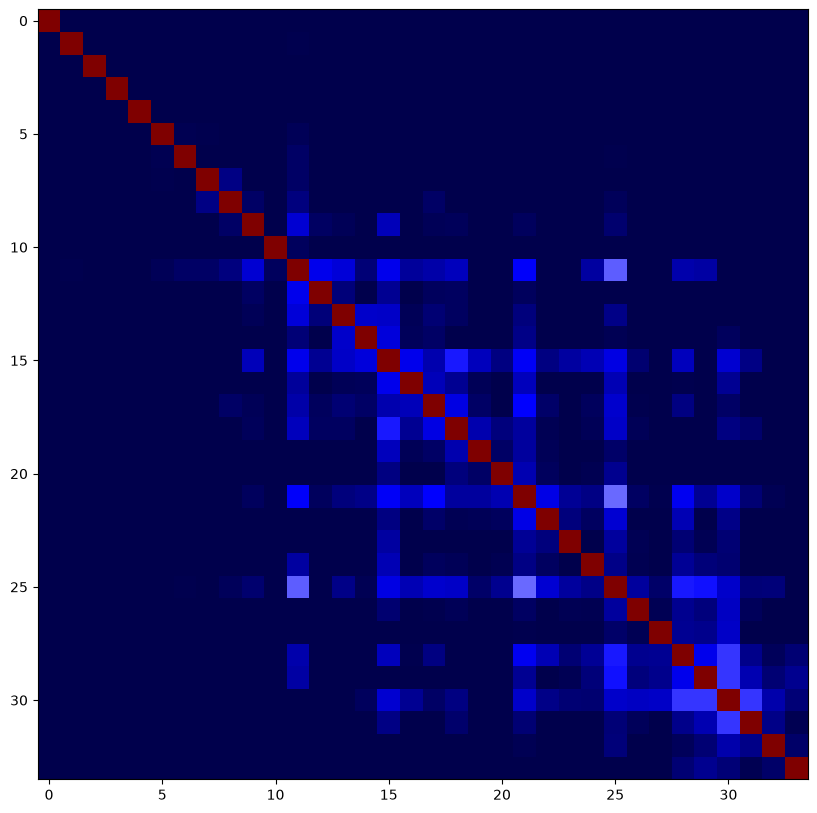

  2%|▏         | 3/121 [02:06<1:43:41, 52.72s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__002--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__003--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__003--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.24it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(30071), np.int64(3267)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__003--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__003--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1571/1571 [00:06<00:00, 260.04it/s]


fraction the same: 0.9362526678398921
fraction nan: 0.05556595649080765
EM iteration number:  4



100%|██████████| 1571/1571 [00:06<00:00, 259.28it/s]


fraction the same: 0.9718800314524282
fraction nan: 0.05556595649080765


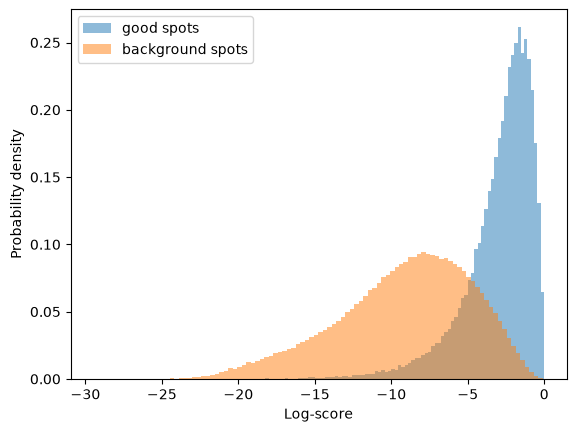

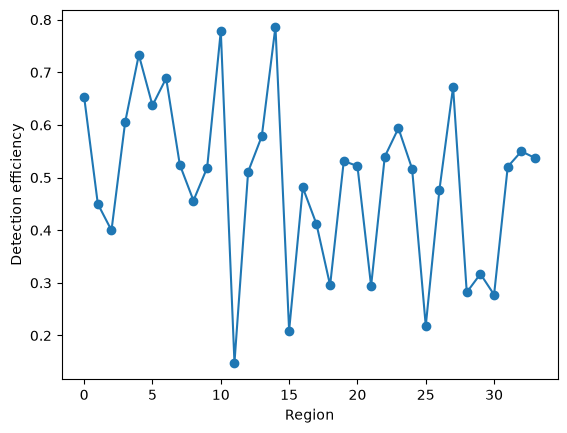

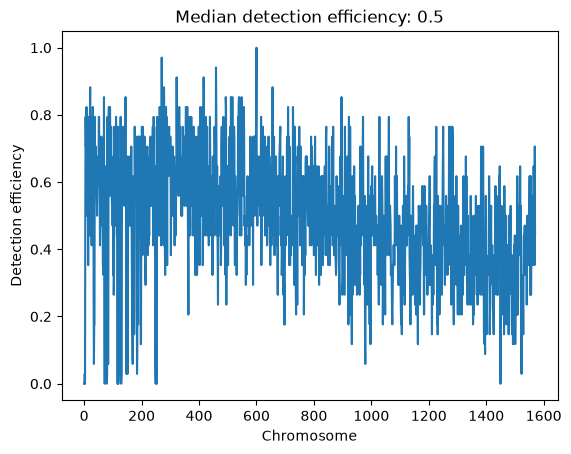

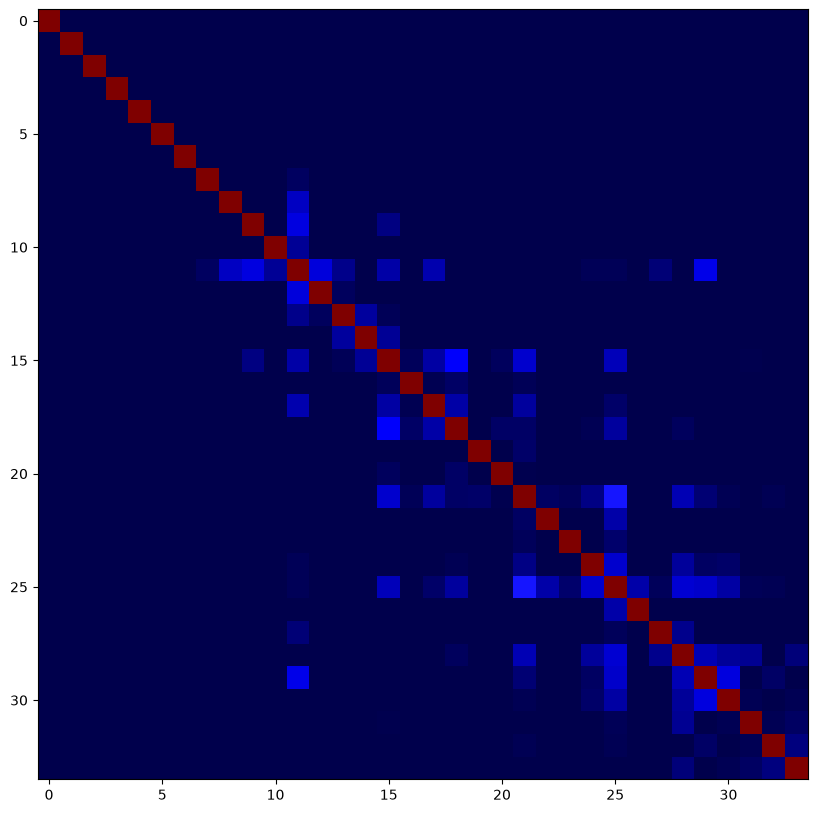

  3%|▎         | 4/121 [03:56<2:27:12, 75.49s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__003--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__004--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__004--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.38it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(9542), np.int64(3281)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__004--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__004--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 14/14 [00:00<00:00, 343.82it/s]


fraction the same: 0.9096638655462185
fraction nan: 0.008403361344537815
EM iteration number:  4



100%|██████████| 14/14 [00:00<00:00, 317.63it/s]


fraction the same: 0.9369747899159664
fraction nan: 0.008403361344537815


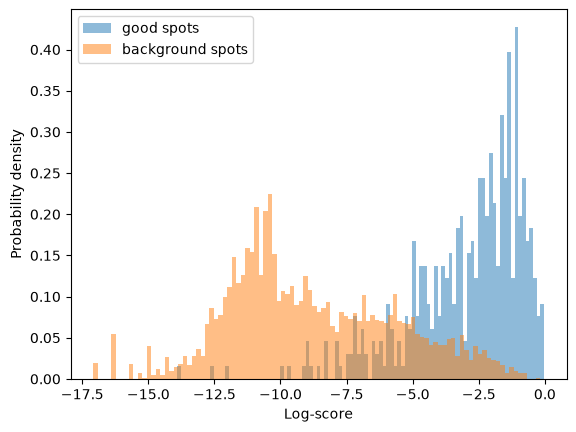

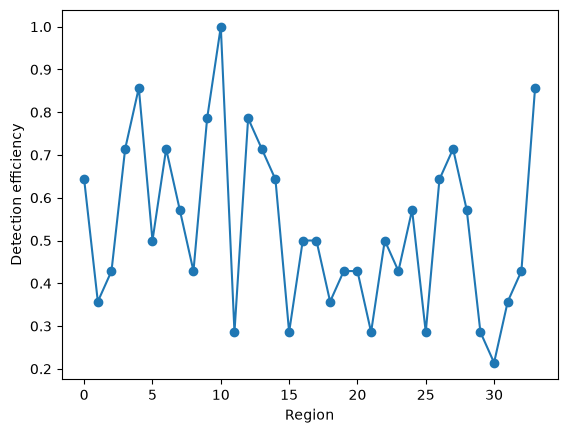

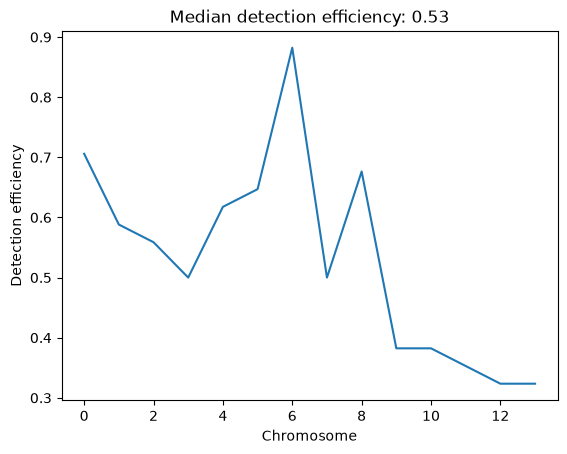

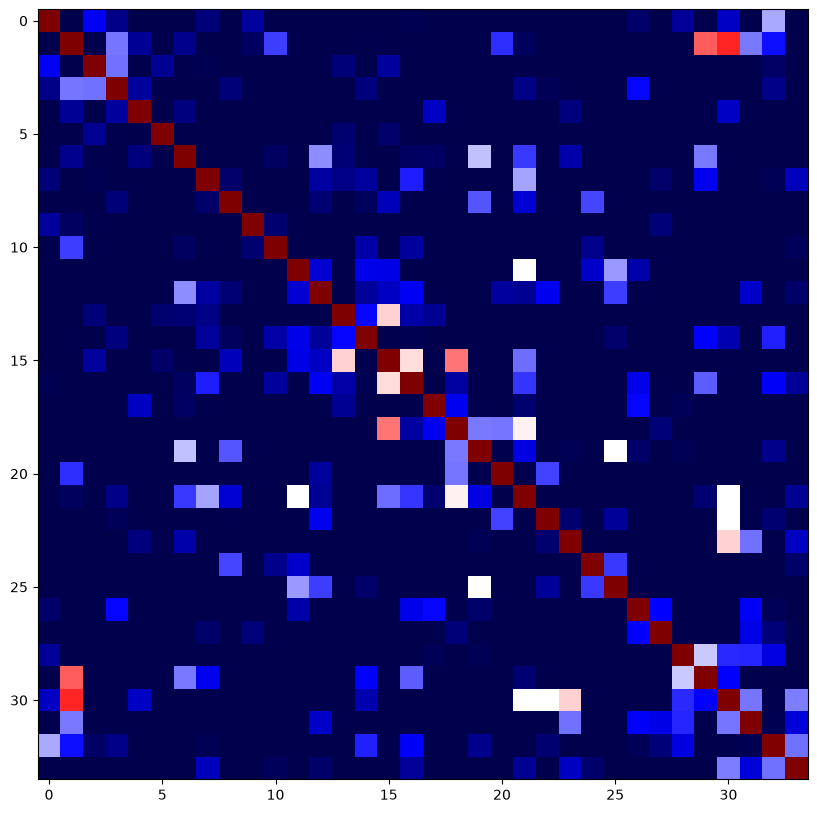

  4%|▍         | 5/121 [04:31<1:57:45, 60.91s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__004--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__005--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__005--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:26,  1.54it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(6796), np.int64(1531)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__005--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__005--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 48/48 [00:00<00:00, 417.90it/s]


fraction the same: 0.9515931372549019
fraction nan: 0.06004901960784314
EM iteration number:  4



100%|██████████| 48/48 [00:00<00:00, 407.28it/s]


fraction the same: 0.9791666666666666
fraction nan: 0.06004901960784314


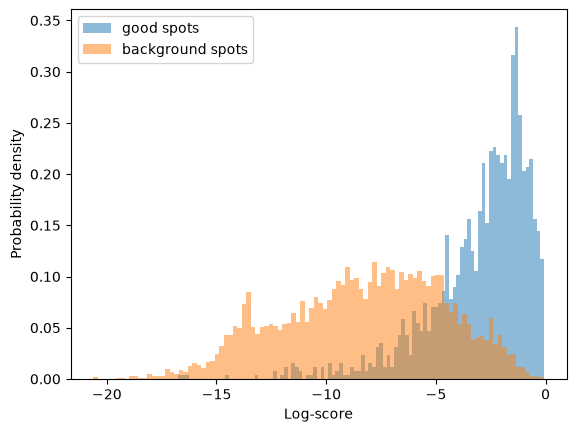

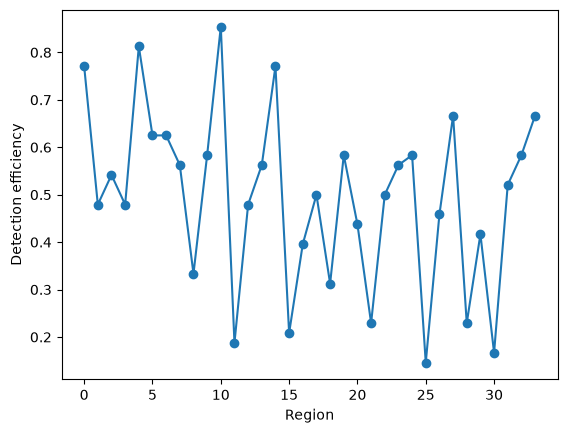

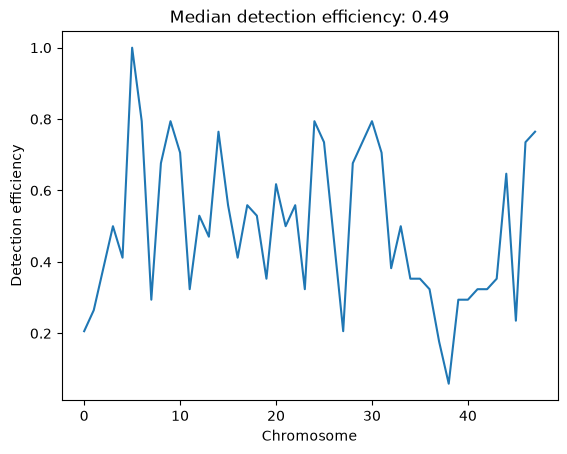

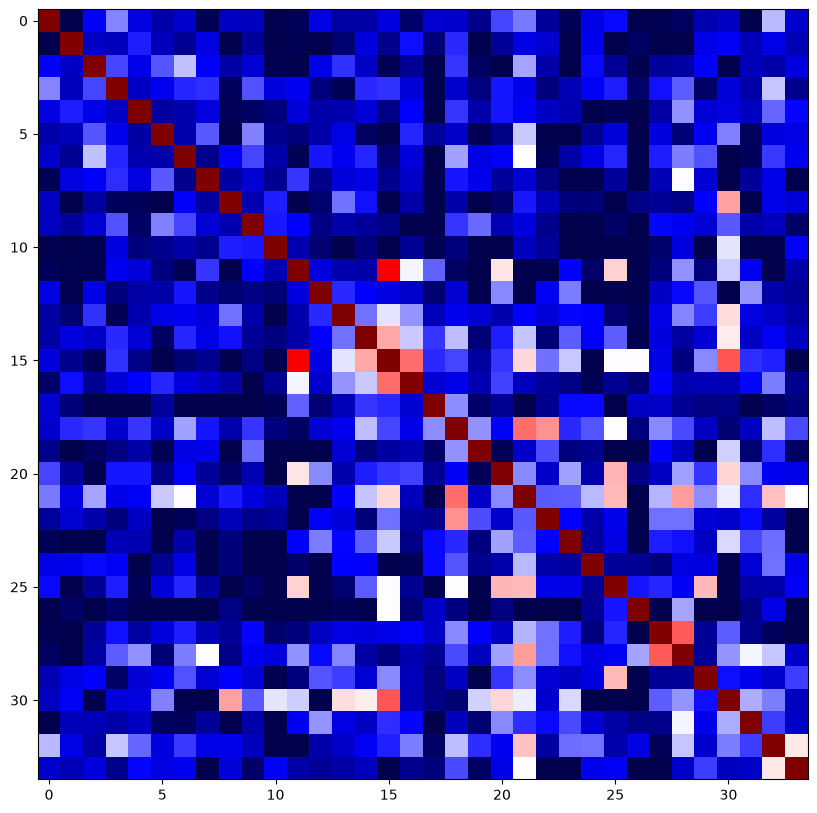

  5%|▍         | 6/121 [05:02<1:36:46, 50.49s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__005--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__006--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__006--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:33,  1.24it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(27856), np.int64(4231)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__006--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__006--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1007/1007 [00:03<00:00, 269.75it/s][A


fraction the same: 0.9378176295344354
fraction nan: 0.05195981073660845
EM iteration number:  4



100%|██████████| 1007/1007 [00:03<00:00, 253.55it/s][A


fraction the same: 0.9725159179858637
fraction nan: 0.05195981073660845


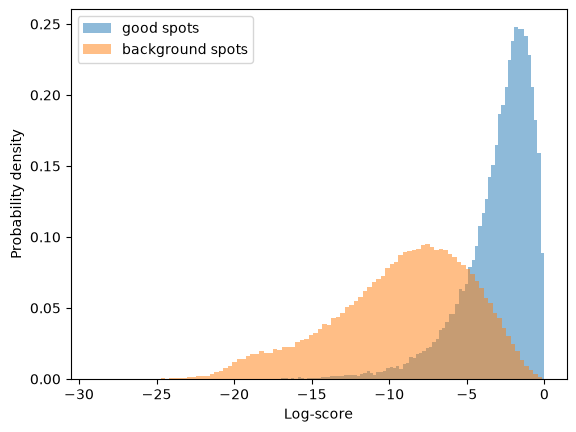

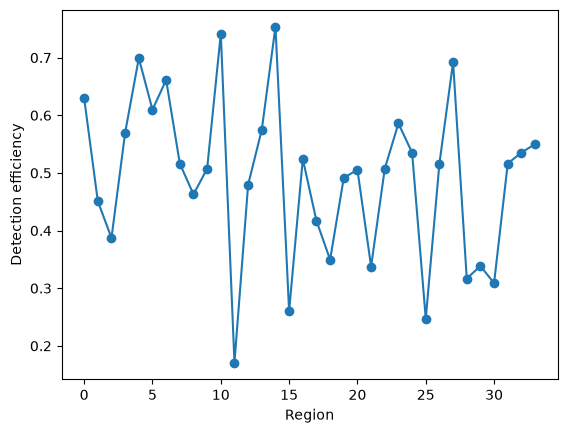

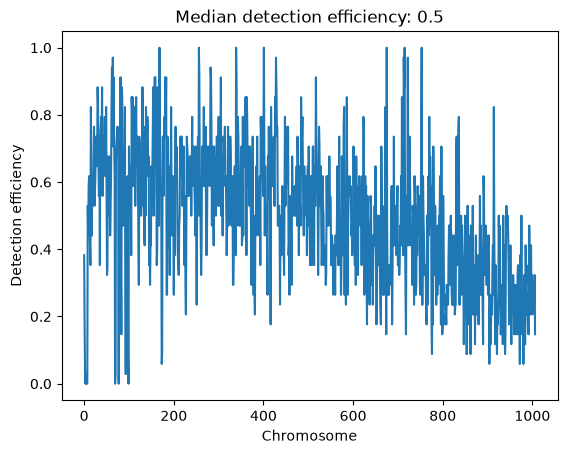

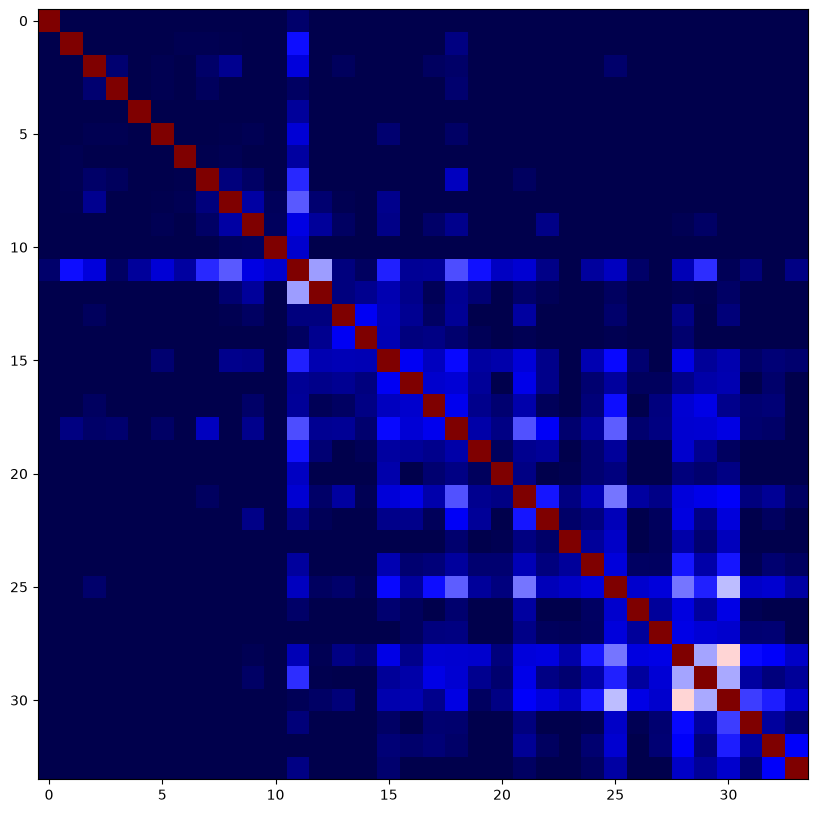

  6%|▌         | 7/121 [06:19<1:52:36, 59.27s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__006--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__007--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__007--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:23,  1.73it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(13256), np.int64(218)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__007--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__007--H10_NC_set1--dapiFeatures.npz


... (101 outputs left out)


100%|██████████| 1331/1331 [00:04<00:00, 270.75it/s]


fraction the same: 0.9404472532814779
fraction nan: 0.06249171343969594
EM iteration number:  4



100%|██████████| 1331/1331 [00:05<00:00, 256.60it/s]


fraction the same: 0.9741680293454722
fraction nan: 0.06249171343969594


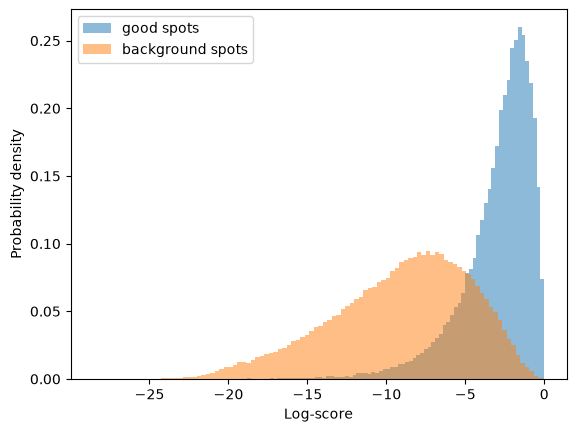

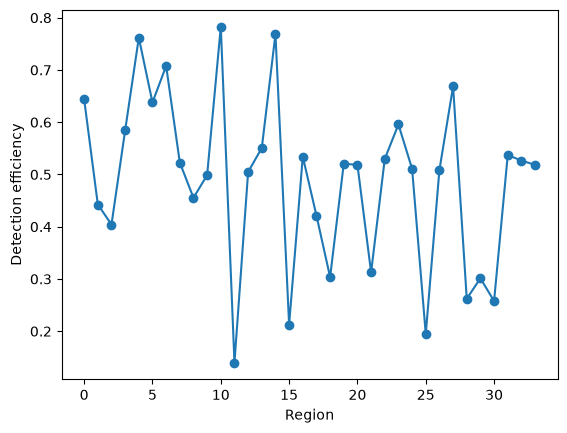

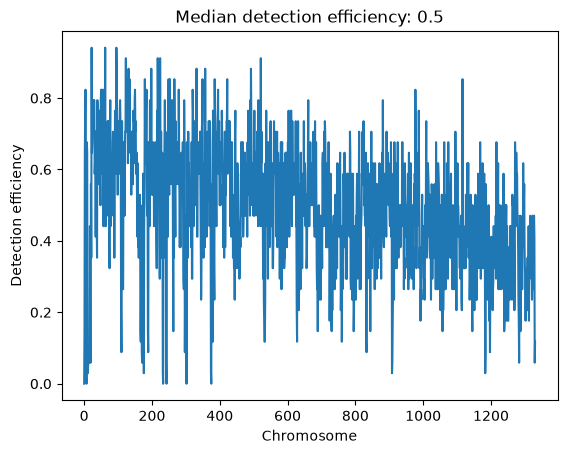

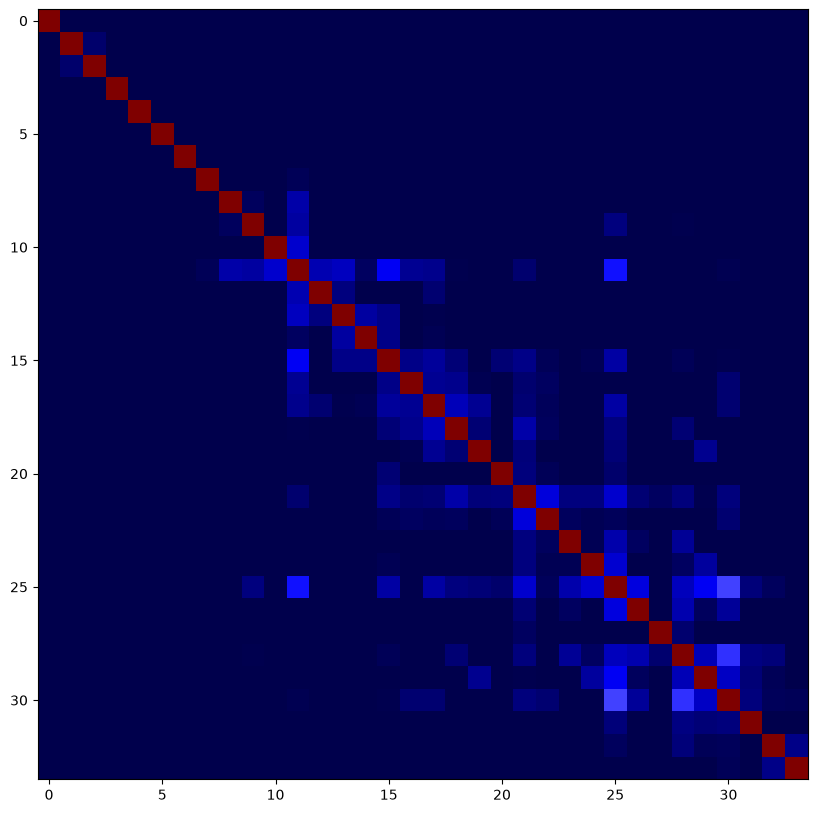

  7%|▋         | 9/121 [07:58<1:49:06, 58.45s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__008--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__009--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__009--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:12,  3.37it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(3469), np.int64(3200)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__009--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__009--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 2027/2027 [00:07<00:00, 259.36it/s]


fraction the same: 0.9430482602513132
fraction nan: 0.18614875649322382
EM iteration number:  4



100%|██████████| 2027/2027 [00:07<00:00, 260.30it/s]


fraction the same: 0.9708929452392698
fraction nan: 0.18614875649322382


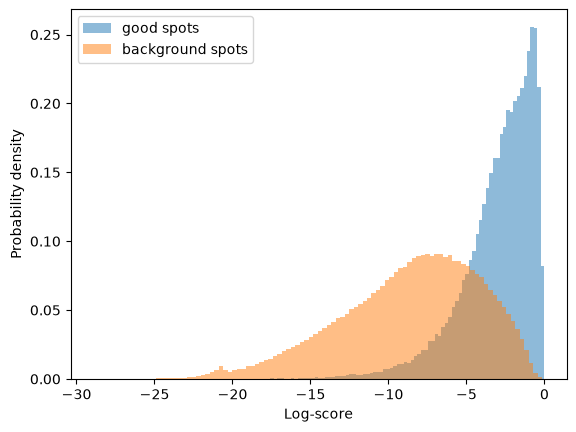

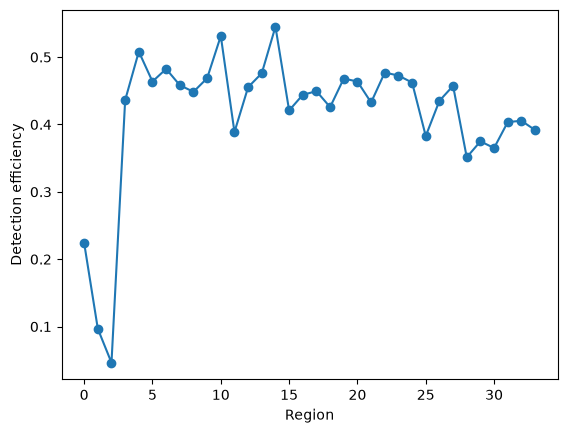

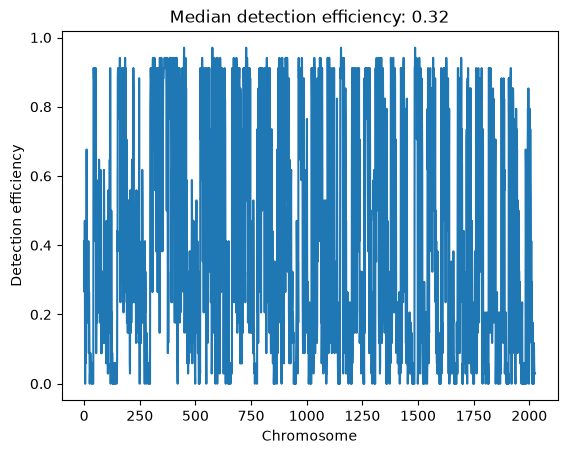

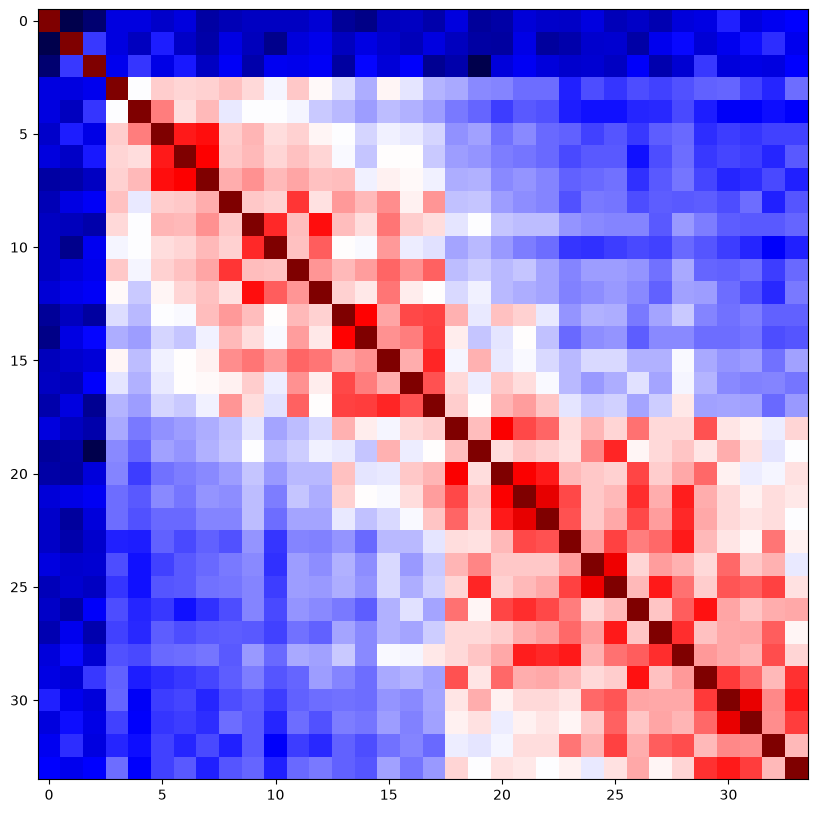

  8%|▊         | 10/121 [10:05<2:27:37, 79.80s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__009--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__010--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__010--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:01<00:45,  1.12s/it]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(29242), np.int64(2768)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__010--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__010--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 965/965 [00:03<00:00, 278.26it/s]


fraction the same: 0.9470588235294117
fraction nan: 0.08594940566900336
EM iteration number:  4



100%|██████████| 965/965 [00:03<00:00, 304.13it/s]


fraction the same: 0.9784212130448035
fraction nan: 0.08594940566900336


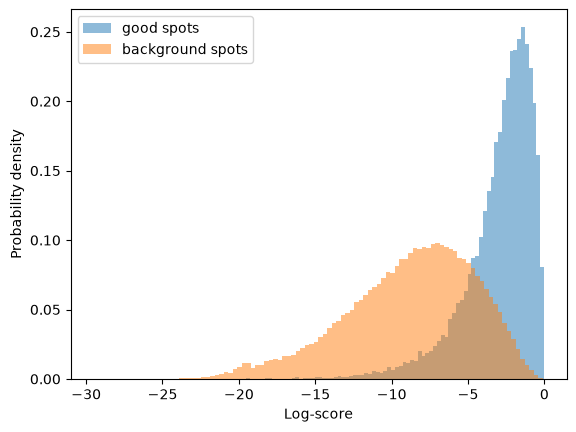

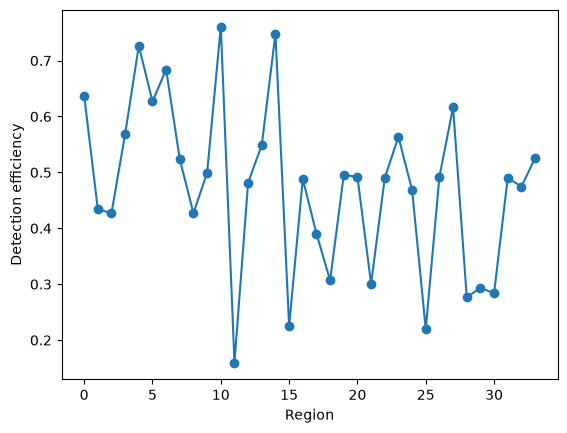

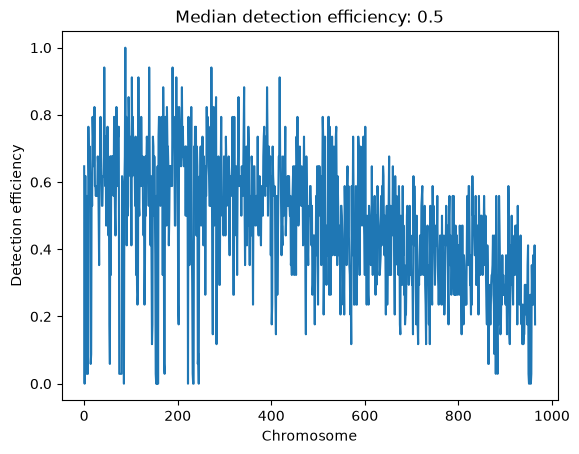

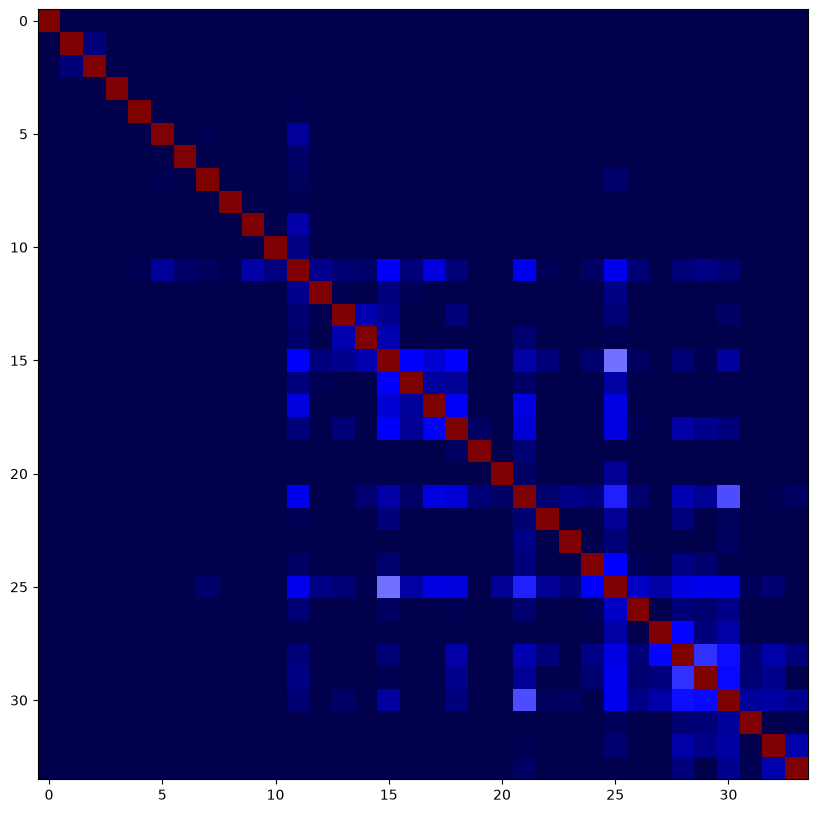

  9%|▉         | 11/121 [11:26<2:27:08, 80.26s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__010--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__011--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__011--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.36it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(31588), np.int64(4324)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__011--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__011--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1659/1659 [00:06<00:00, 254.42it/s]


fraction the same: 0.9379321348792682
fraction nan: 0.062333794277204556
EM iteration number:  4



100%|██████████| 1659/1659 [00:06<00:00, 265.36it/s]


fraction the same: 0.9725029252207212
fraction nan: 0.062333794277204556


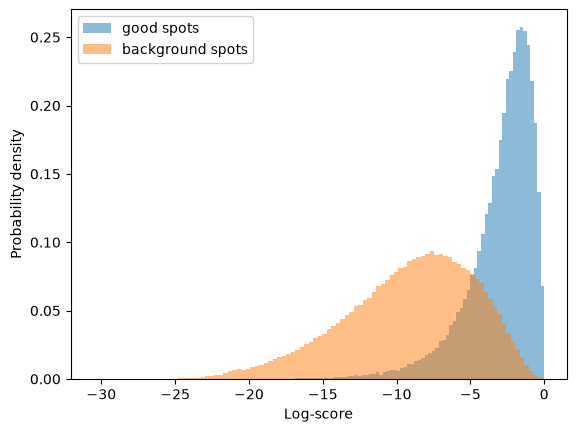

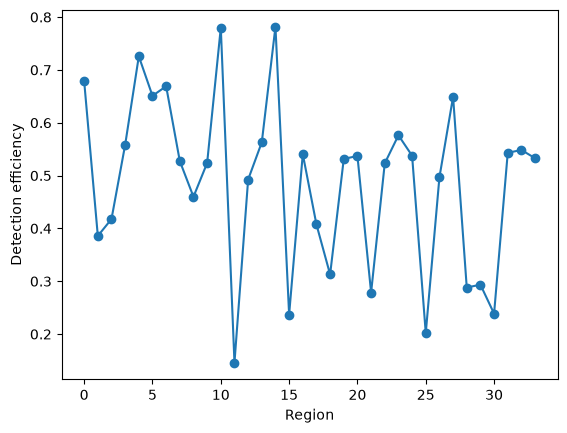

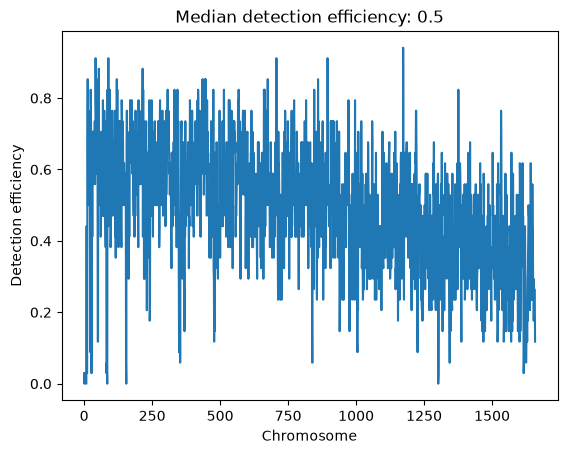

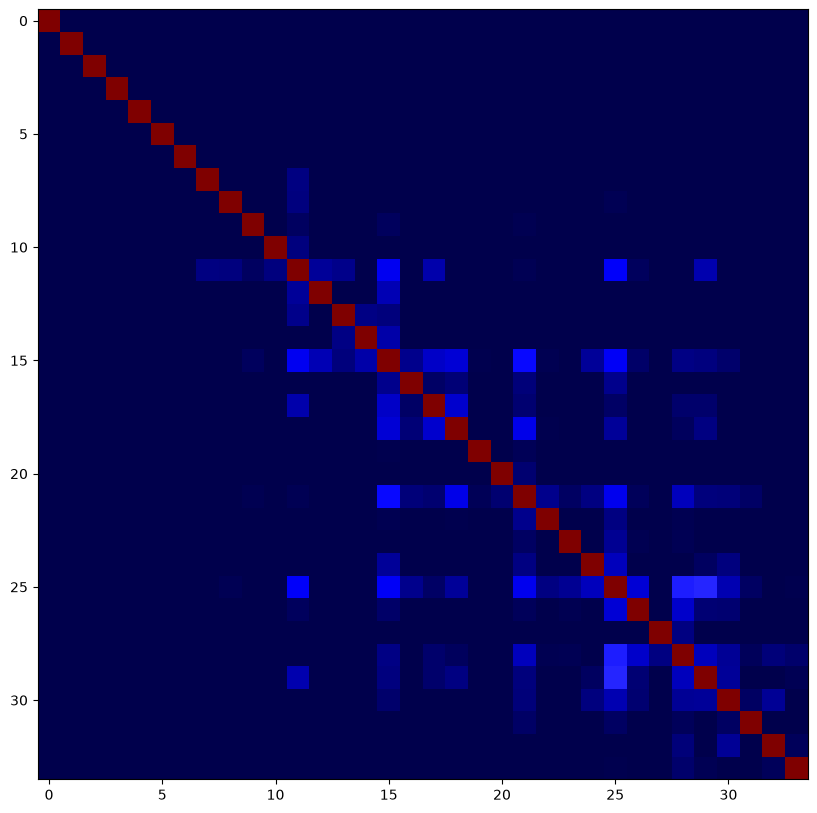

 10%|▉         | 12/121 [13:22<2:45:15, 90.97s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__011--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__012--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__012--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.27it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24082), np.int64(5164)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__012--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__012--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 564/564 [00:02<00:00, 277.12it/s]


fraction the same: 0.9376825198164372
fraction nan: 0.04104088443888194
EM iteration number:  4



100%|██████████| 564/564 [00:02<00:00, 242.72it/s]


fraction the same: 0.9722048393825615
fraction nan: 0.04104088443888194


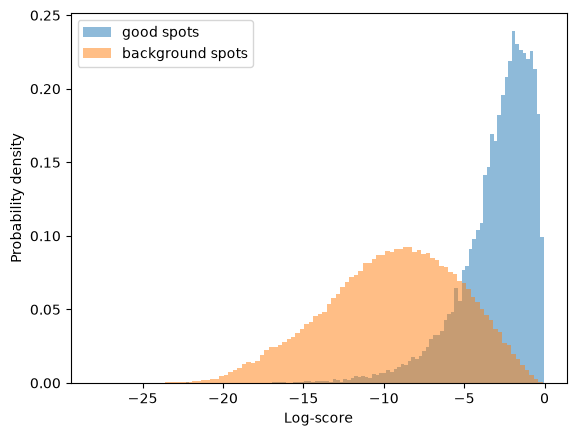

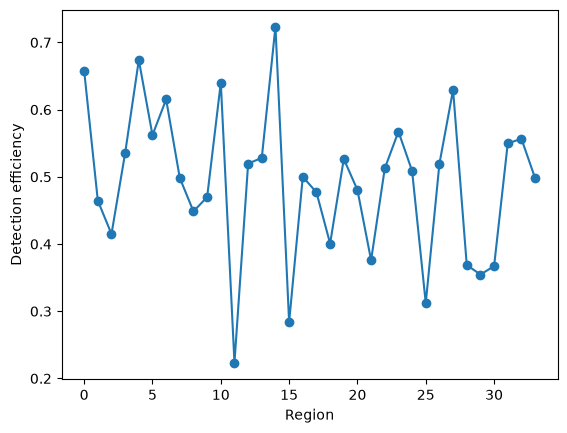

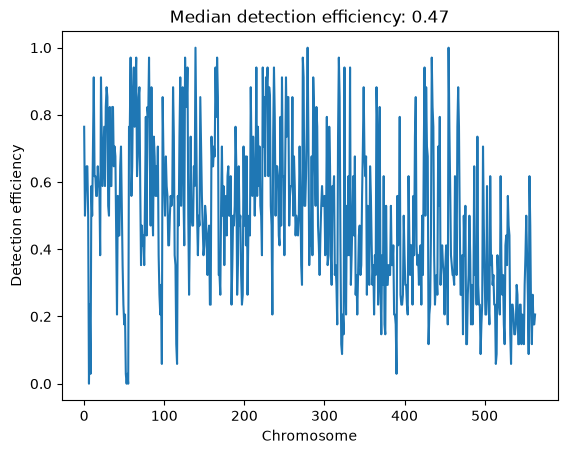

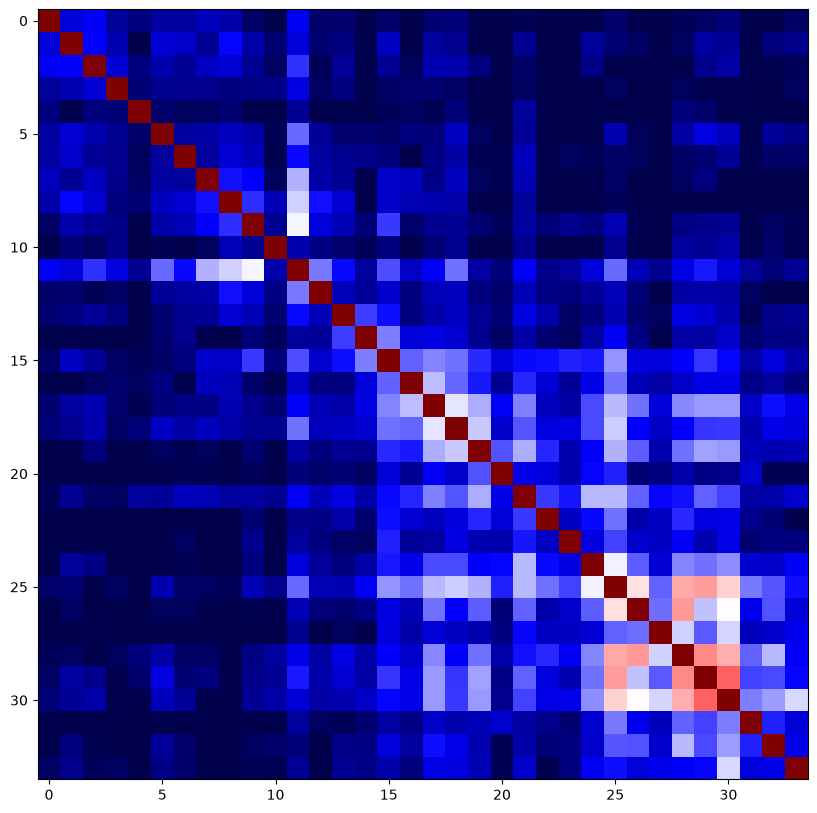

 11%|█         | 13/121 [14:25<2:28:28, 82.49s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__012--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__013--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__013--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.46it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(22071), np.int64(7618)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__013--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__013--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 468/468 [00:01<00:00, 282.15it/s]


fraction the same: 0.9478381096028154
fraction nan: 0.04989944695827049
EM iteration number:  4



100%|██████████| 468/468 [00:01<00:00, 279.96it/s]


fraction the same: 0.9741704374057315
fraction nan: 0.04989944695827049


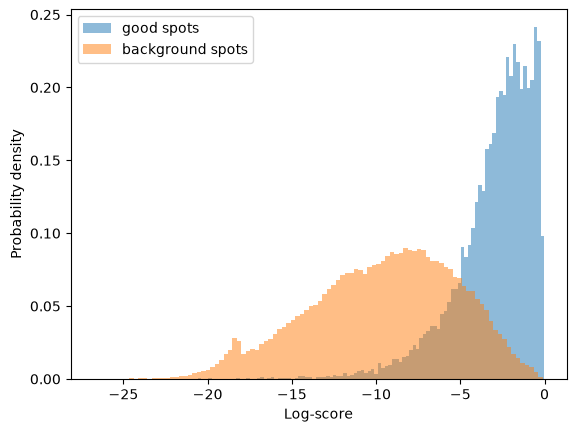

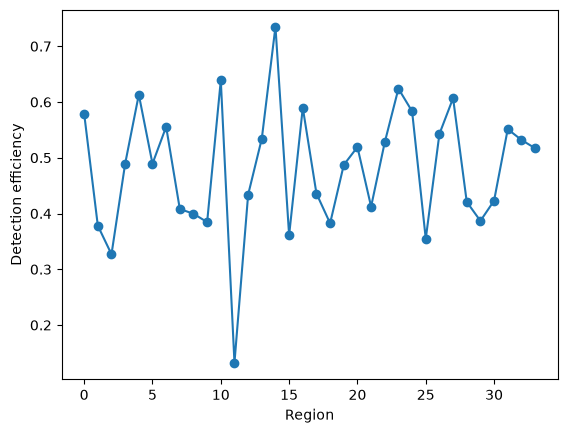

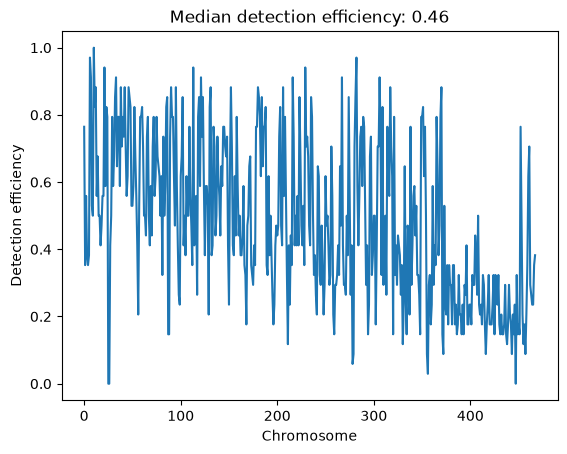

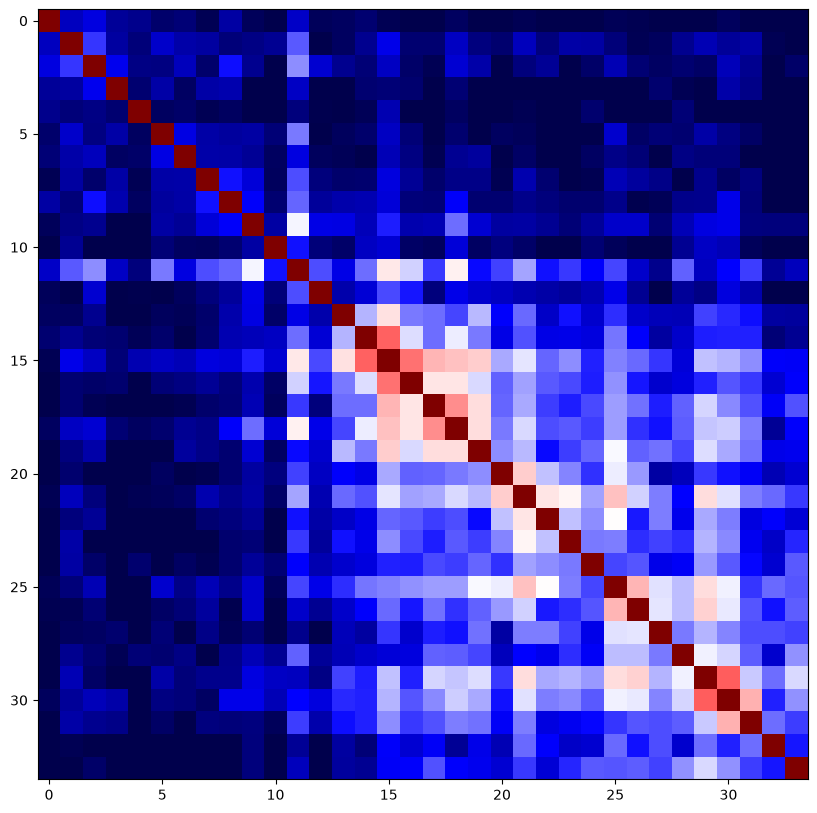

 12%|█▏        | 14/121 [15:18<2:11:01, 73.47s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__013--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__014--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__014--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.33it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(26229), np.int64(4113)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__014--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__014--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1207/1207 [00:04<00:00, 259.46it/s]


fraction the same: 0.9413226765436912
fraction nan: 0.05297529119352795
EM iteration number:  4



100%|██████████| 1207/1207 [00:04<00:00, 260.34it/s]


fraction the same: 0.974219016521273
fraction nan: 0.05297529119352795


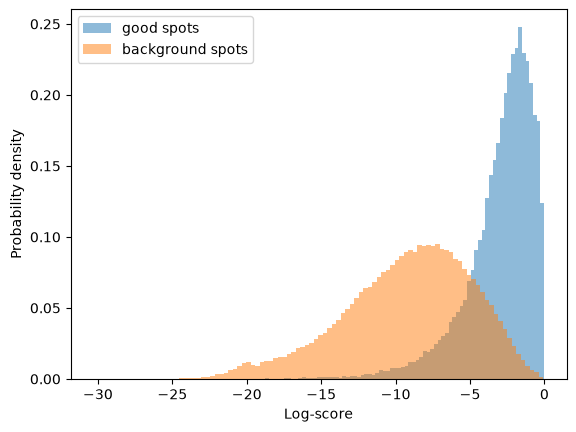

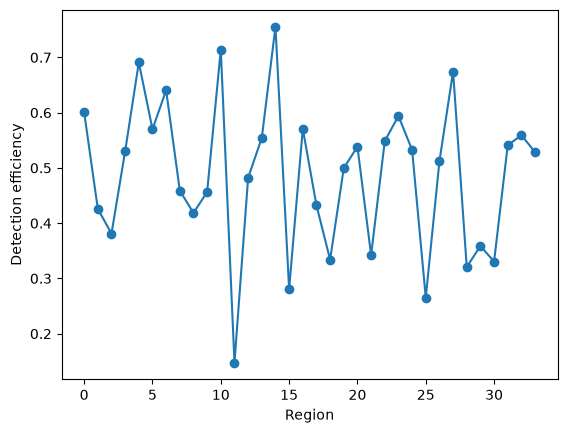

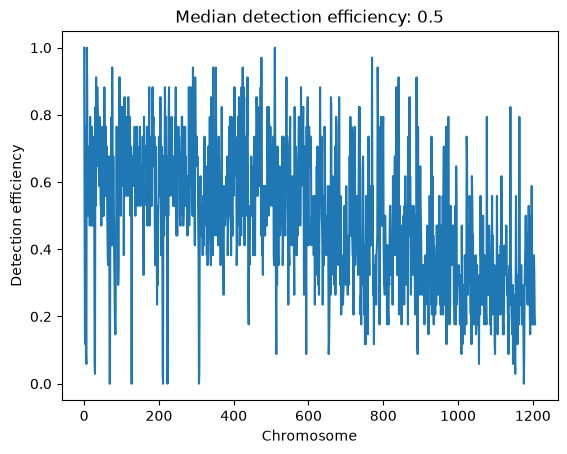

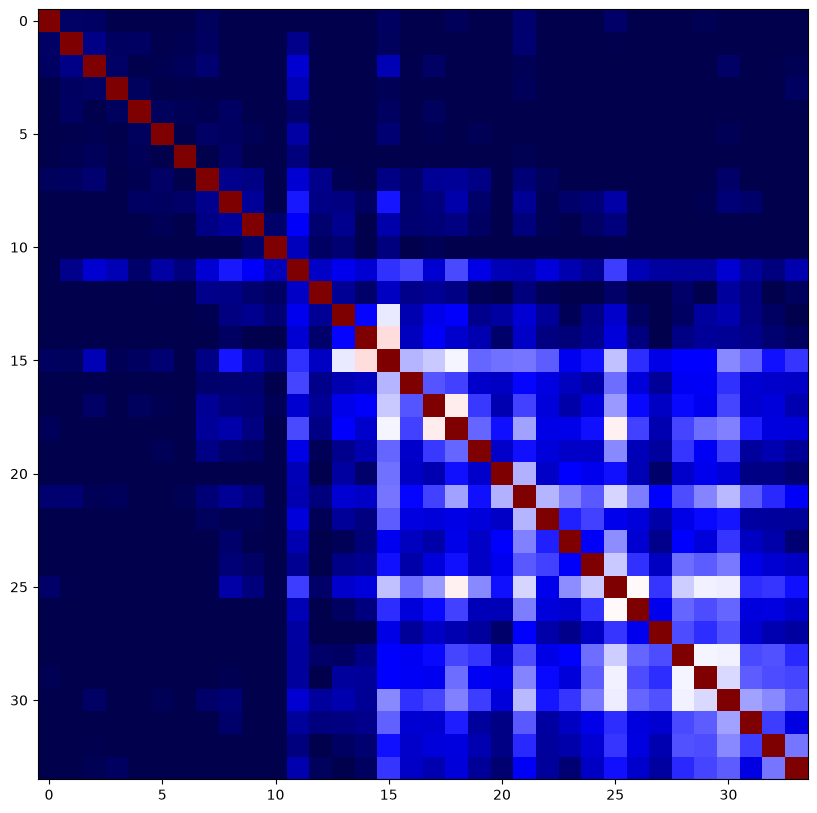

 12%|█▏        | 15/121 [16:46<2:17:54, 78.06s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__014--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__015--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__015--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.29it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(21933), np.int64(6496)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__015--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__015--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 377/377 [00:01<00:00, 297.71it/s]


fraction the same: 0.9498361678889062
fraction nan: 0.05429864253393665
EM iteration number:  4



100%|██████████| 377/377 [00:01<00:00, 301.67it/s]


fraction the same: 0.9774535809018567
fraction nan: 0.05429864253393665


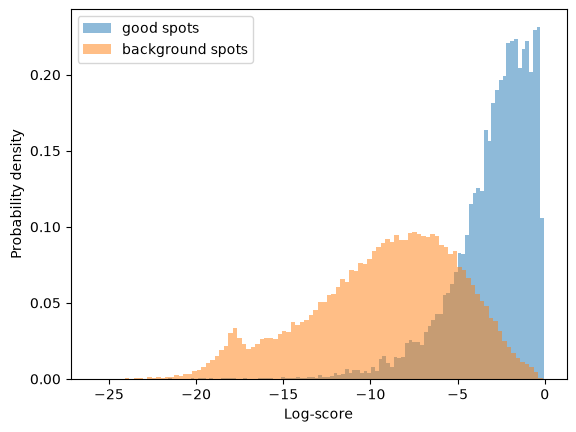

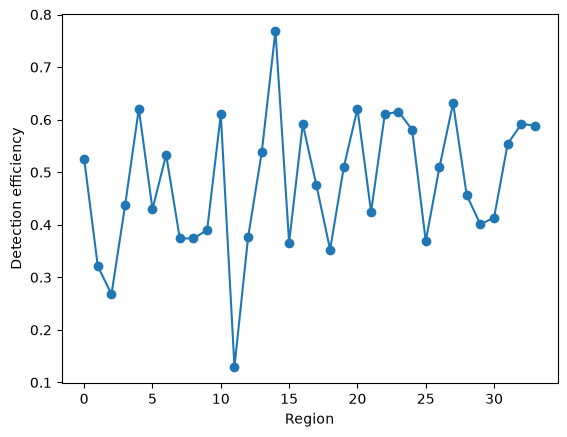

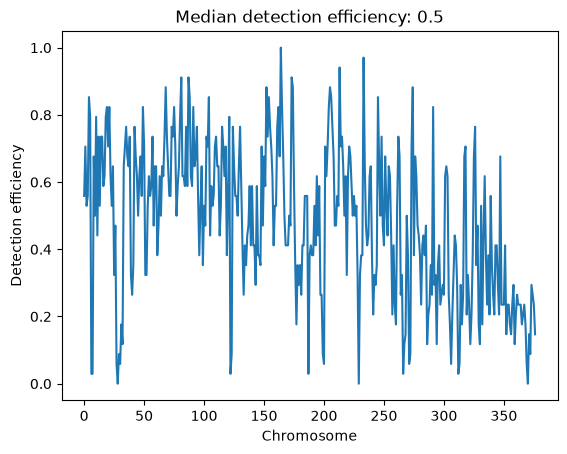

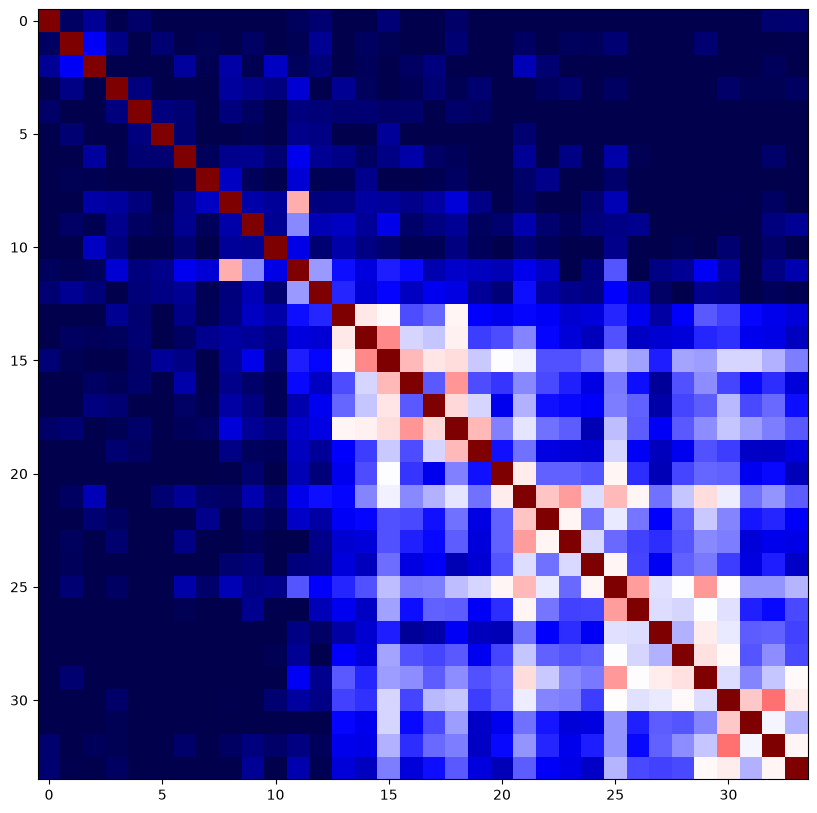

 13%|█▎        | 16/121 [17:39<2:03:10, 70.39s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__015--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__016--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__016--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.27it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28427), np.int64(3503)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__016--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__016--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1519/1519 [00:06<00:00, 233.01it/s]


fraction the same: 0.9427835650389188
fraction nan: 0.051291484335669754
EM iteration number:  4



100%|██████████| 1519/1519 [00:06<00:00, 227.20it/s]


fraction the same: 0.9744994772102389
fraction nan: 0.051291484335669754


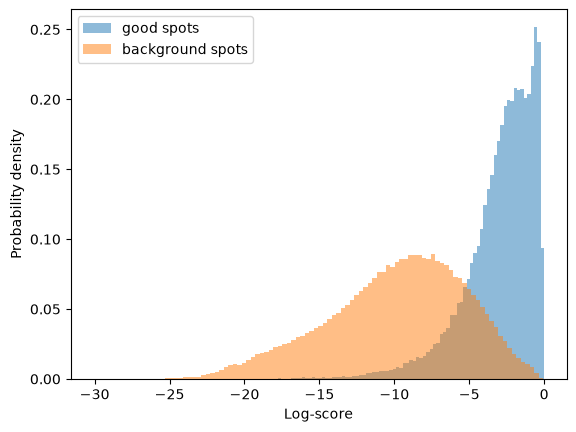

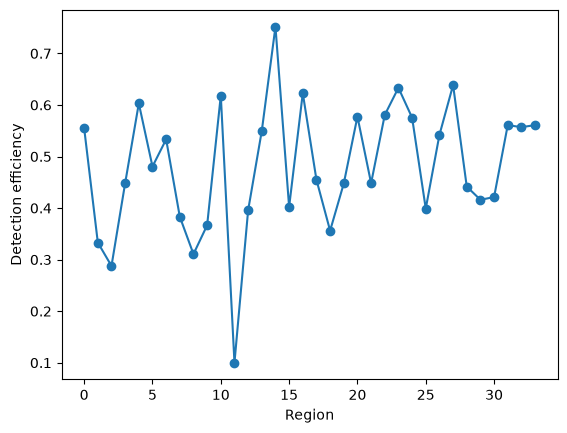

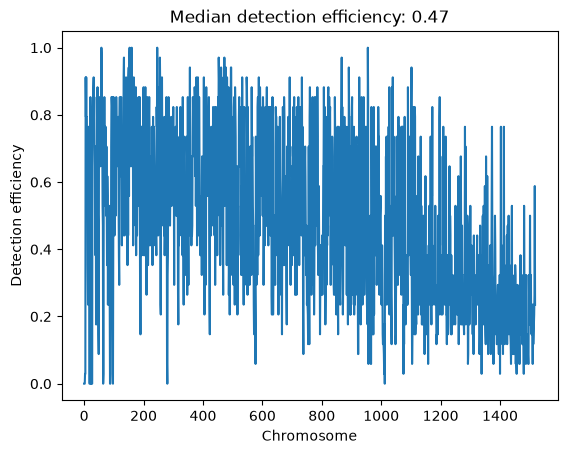

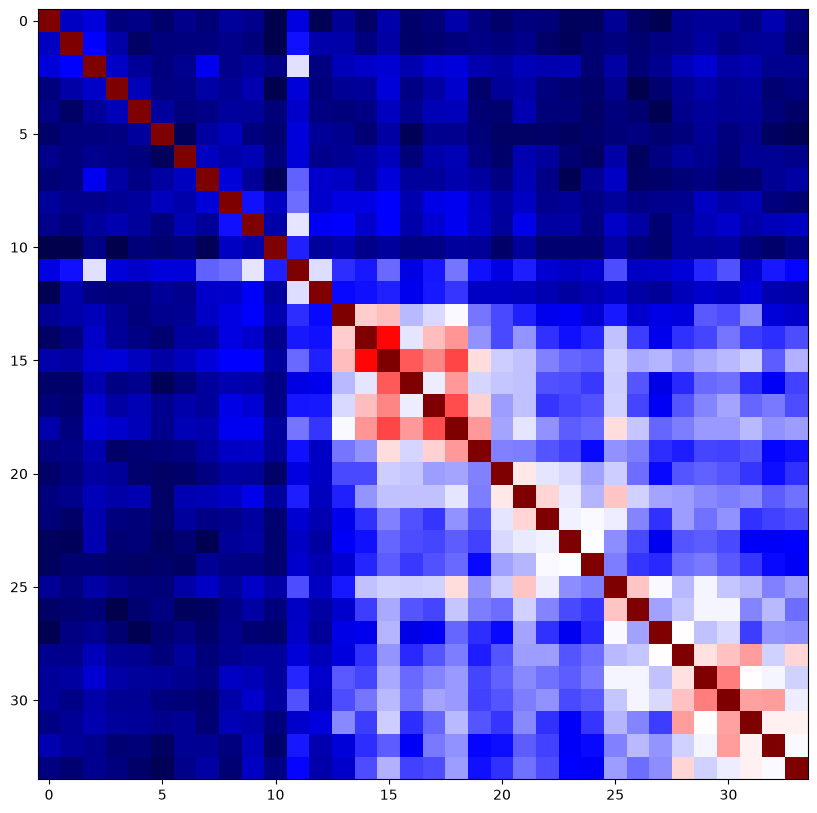

 14%|█▍        | 17/121 [19:24<2:19:58, 80.75s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__016--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__017--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__017--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.43it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(29023), np.int64(4276)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__017--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__017--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1187/1187 [00:04<00:00, 252.75it/s]


fraction the same: 0.9445958669904356
fraction nan: 0.048738787848753656
EM iteration number:  4



100%|██████████| 1187/1187 [00:04<00:00, 252.43it/s]


fraction the same: 0.9773031369245255
fraction nan: 0.048738787848753656


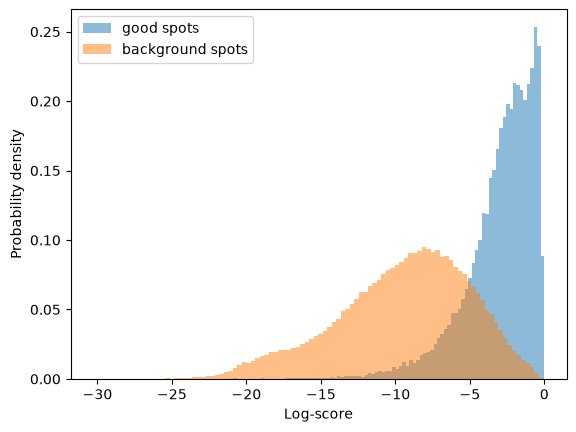

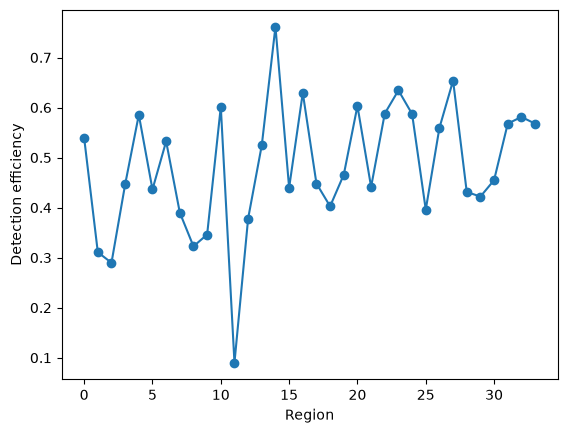

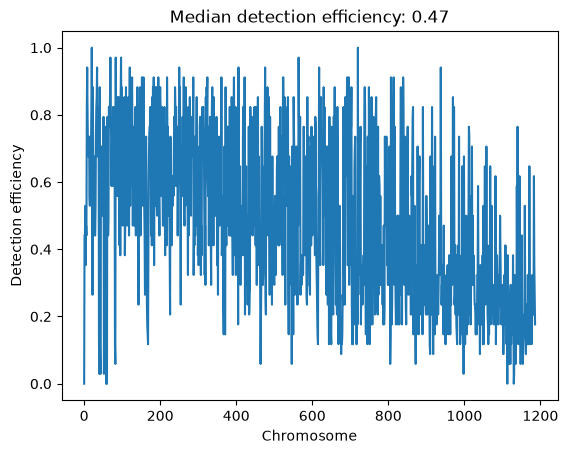

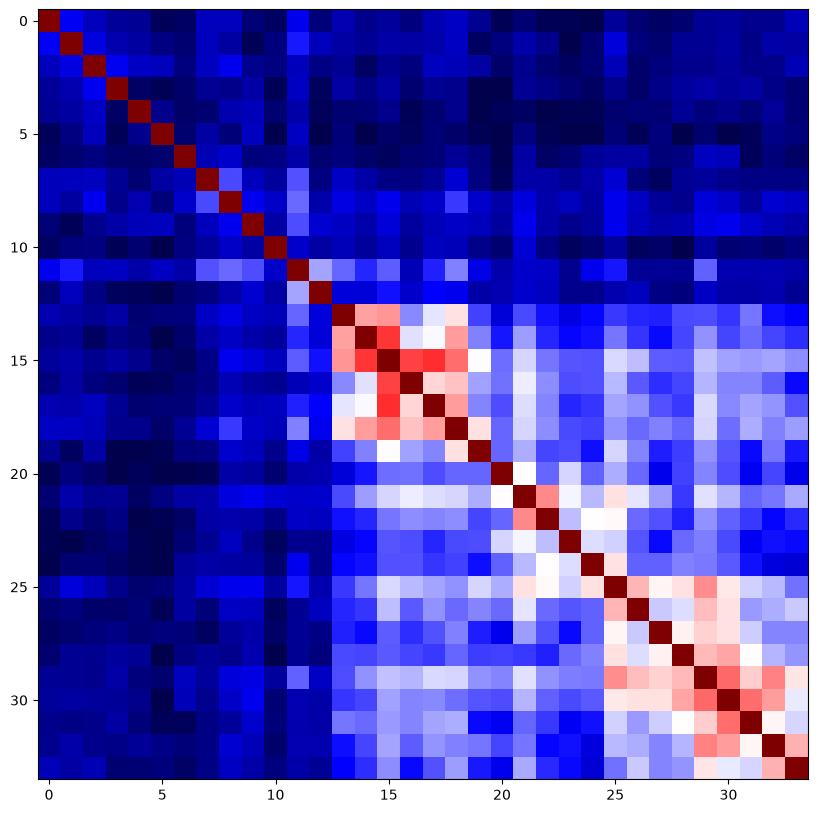

 15%|█▍        | 18/121 [20:48<2:20:25, 81.80s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__017--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__018--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__018--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:34,  1.20it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28574), np.int64(4054)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__018--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__018--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1407/1407 [00:05<00:00, 246.70it/s]


fraction the same: 0.943204147330574
fraction nan: 0.043898156277436345
EM iteration number:  4



100%|██████████| 1407/1407 [00:05<00:00, 235.35it/s]


fraction the same: 0.9738283373050712
fraction nan: 0.043898156277436345


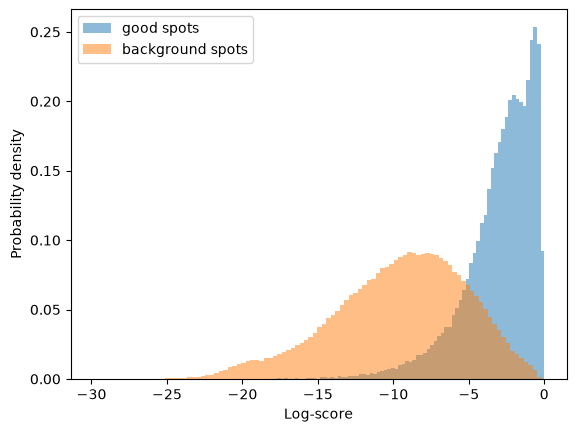

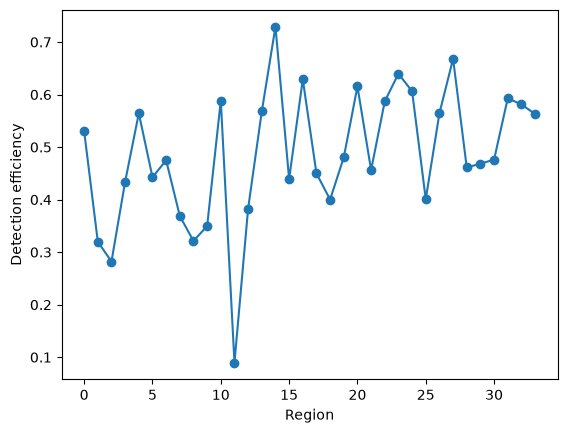

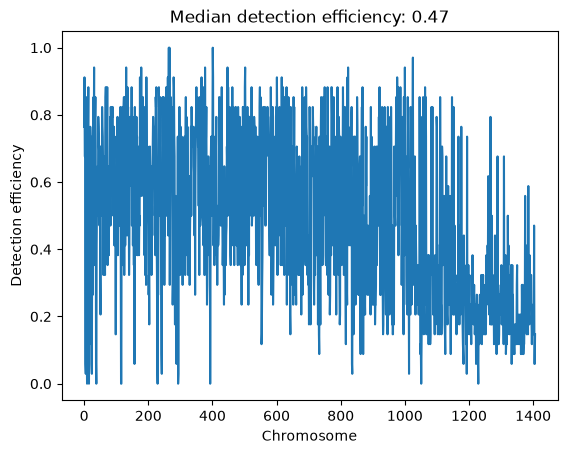

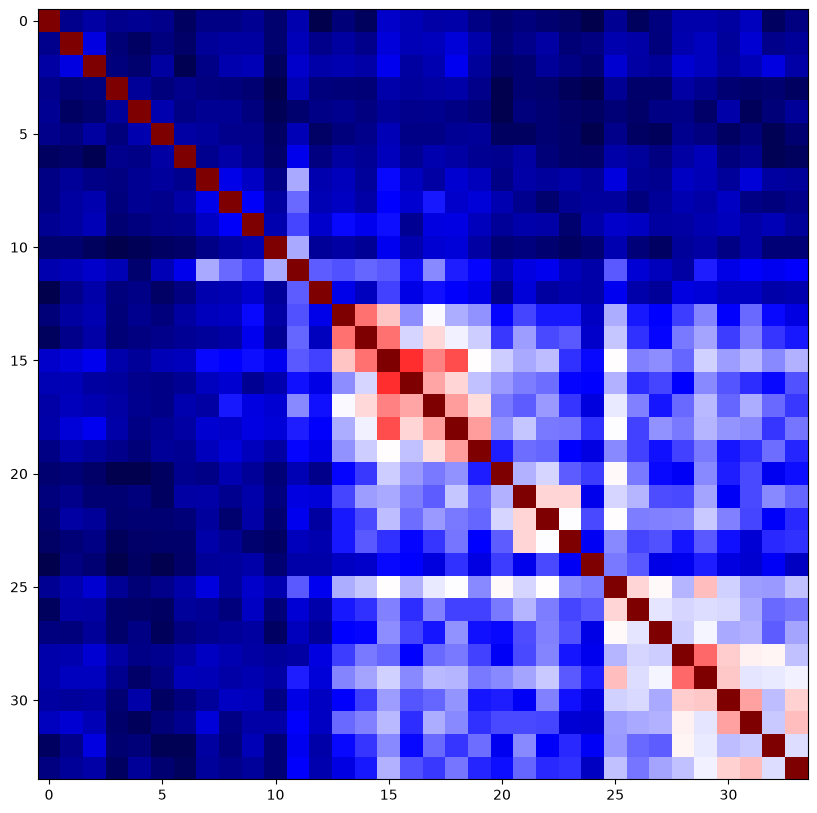

 16%|█▌        | 19/121 [22:31<2:30:08, 88.32s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__018--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__019--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__019--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:01<00:44,  1.08s/it]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(27391), np.int64(2939)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__019--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__019--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1428/1428 [00:05<00:00, 269.95it/s]


fraction the same: 0.9461814137419674
fraction nan: 0.07196407974954688
EM iteration number:  4



100%|██████████| 1428/1428 [00:05<00:00, 256.73it/s]


fraction the same: 0.976643598615917
fraction nan: 0.07196407974954688


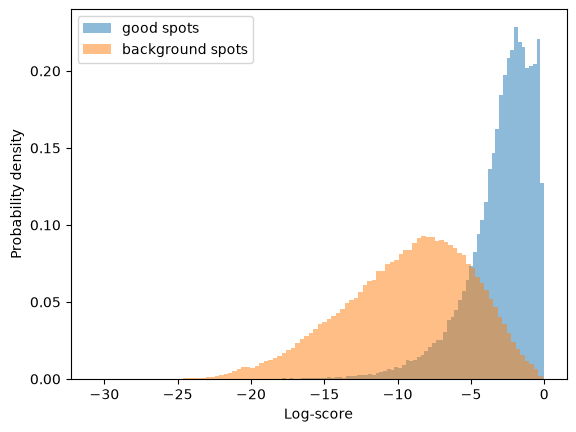

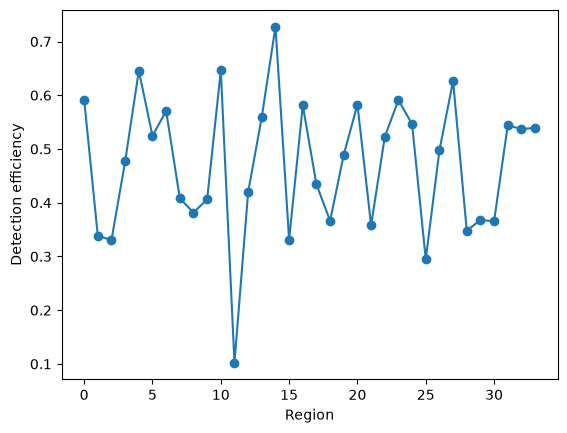

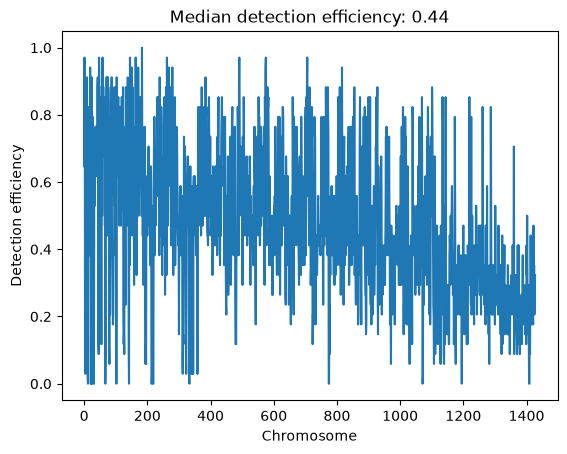

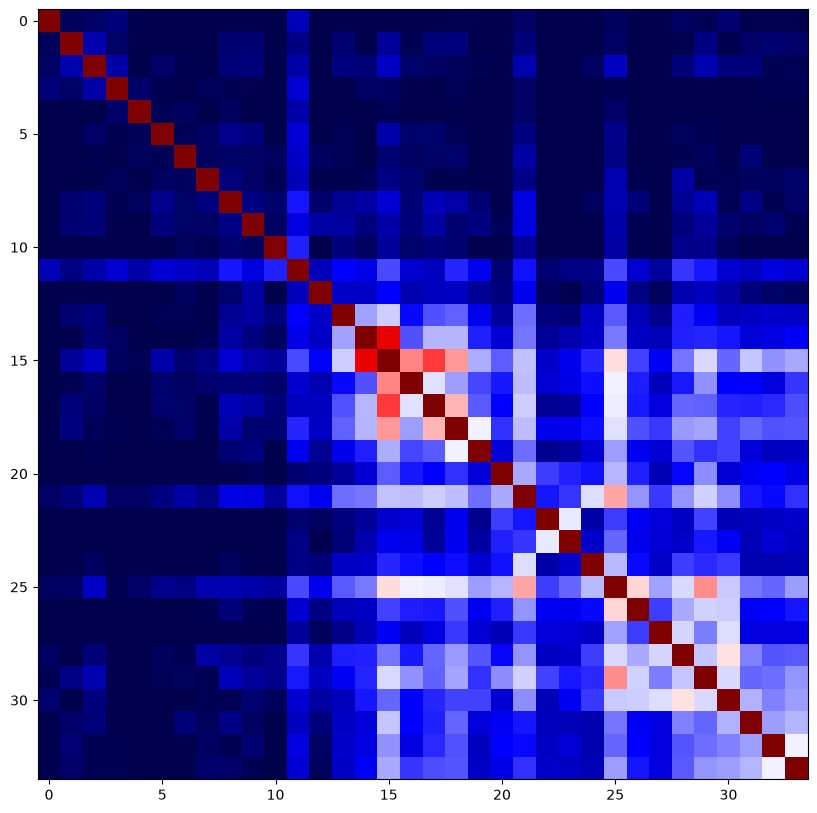

 17%|█▋        | 20/121 [24:14<2:35:45, 92.53s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__019--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__020--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__020--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.28it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(30855), np.int64(2762)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__020--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__020--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1951/1951 [00:07<00:00, 252.83it/s]


fraction the same: 0.9425181656465764
fraction nan: 0.06580335876021347
EM iteration number:  4



100%|██████████| 1951/1951 [00:07<00:00, 263.11it/s]


fraction the same: 0.9748394488497603
fraction nan: 0.06580335876021347


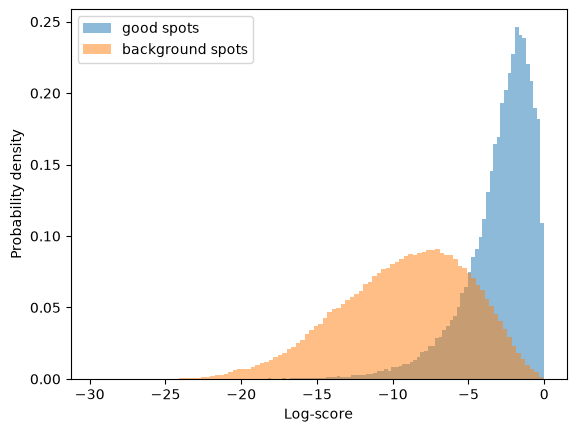

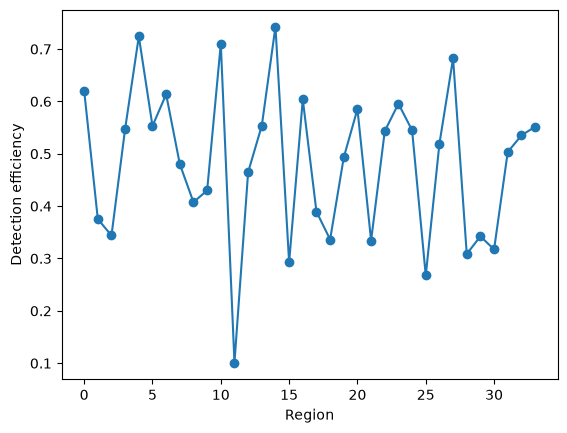

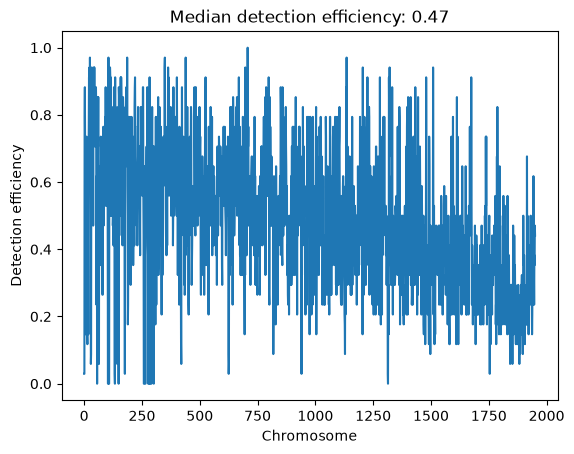

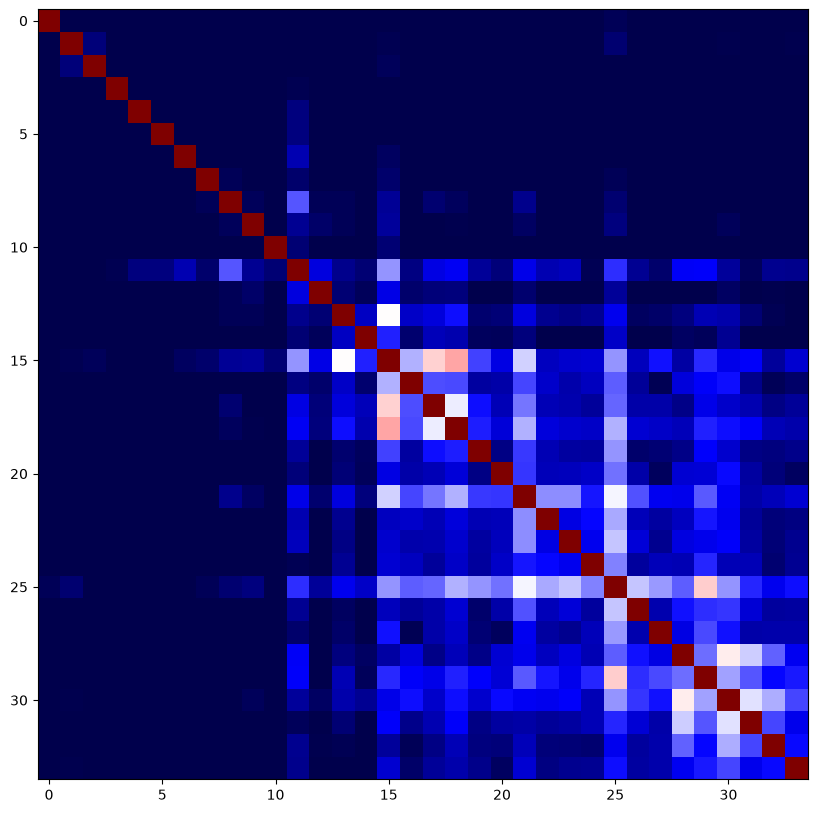

 17%|█▋        | 21/121 [26:11<2:46:34, 99.94s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__020--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__021--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__021--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.27it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(31877), np.int64(3663)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__021--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__021--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1342/1342 [00:04<00:00, 269.20it/s]


fraction the same: 0.9415271324625231
fraction nan: 0.2079424914526168
EM iteration number:  4



100%|██████████| 1342/1342 [00:04<00:00, 273.26it/s]


fraction the same: 0.9743359340755676
fraction nan: 0.2079424914526168


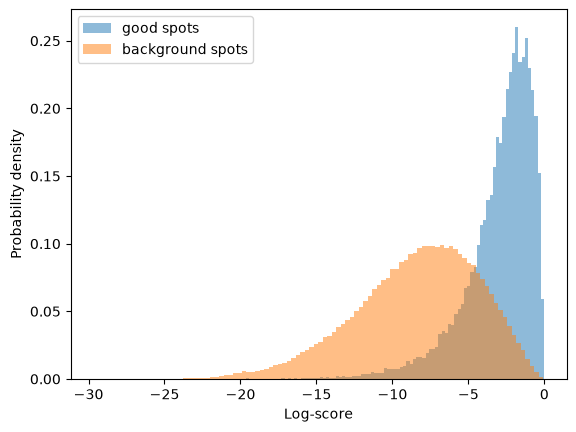

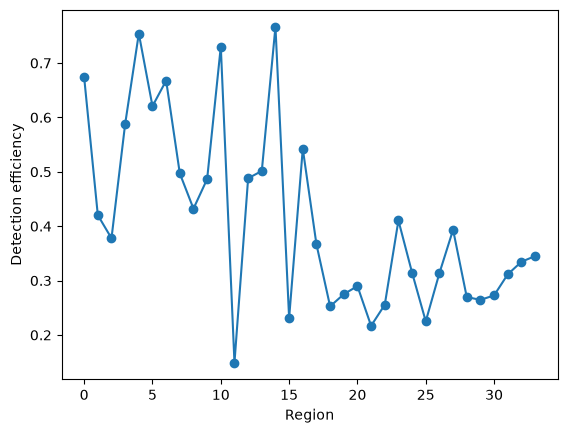

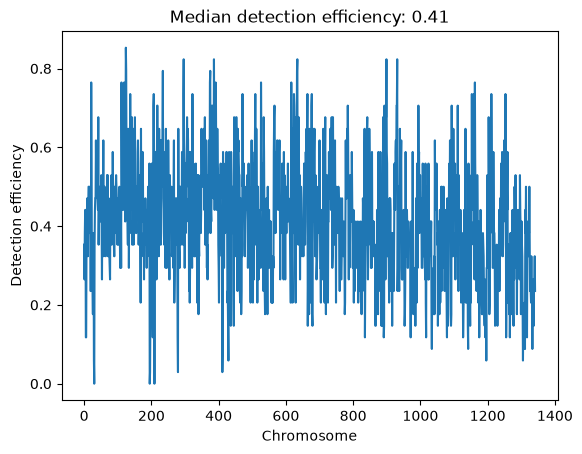

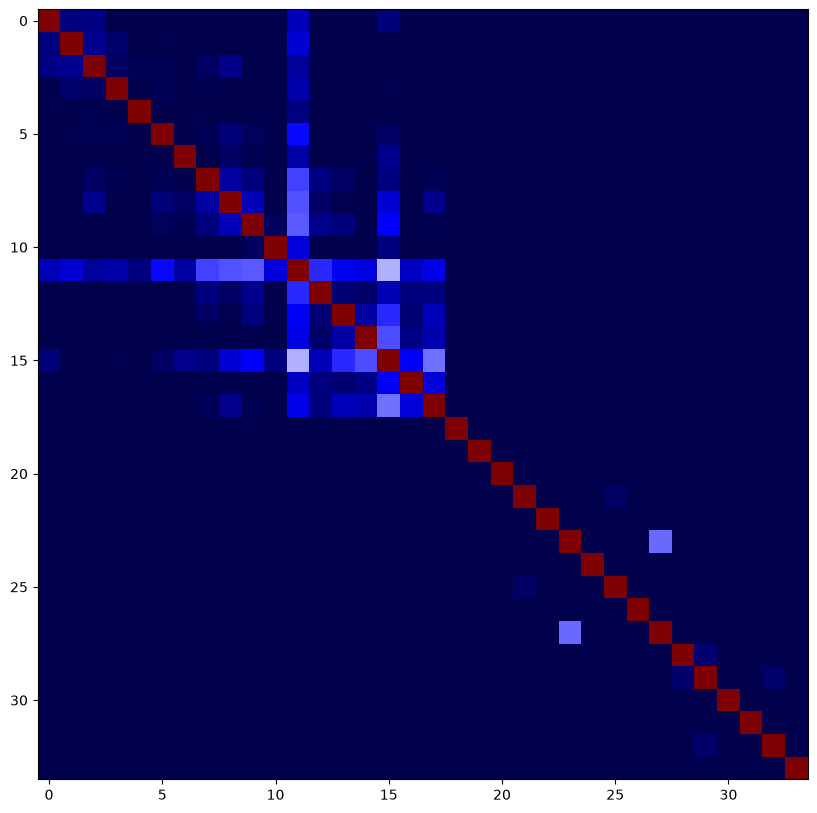

 18%|█▊        | 22/121 [28:11<2:54:53, 106.00s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__021--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__022--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__022--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:26,  1.56it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(10902), np.int64(2168)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__022--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__022--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 332/332 [00:01<00:00, 286.79it/s]


fraction the same: 0.9384301913536499
fraction nan: 0.09948618001417435
EM iteration number:  4



100%|██████████| 332/332 [00:01<00:00, 286.85it/s]


fraction the same: 0.9722714386959603
fraction nan: 0.09948618001417435


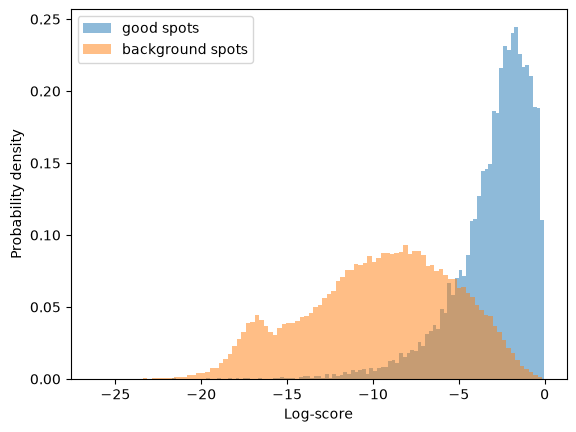

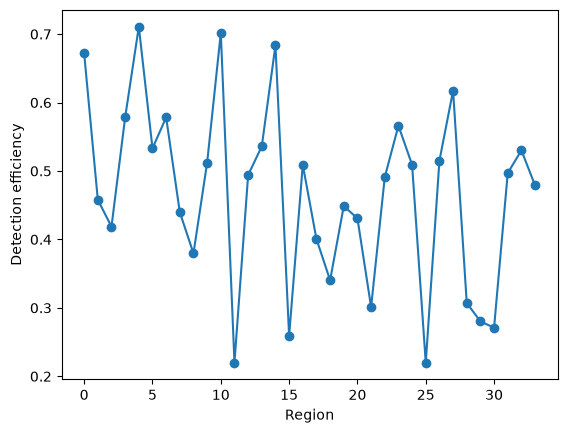

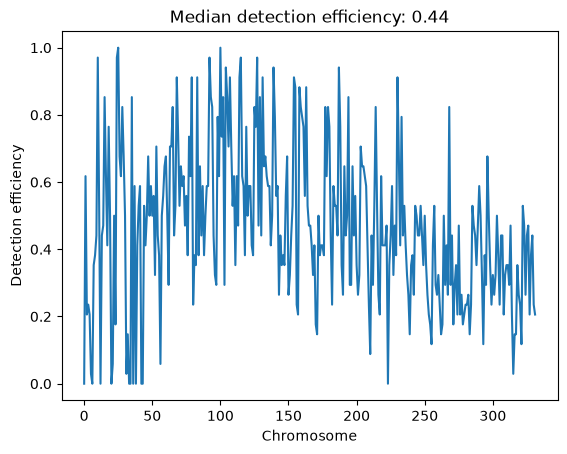

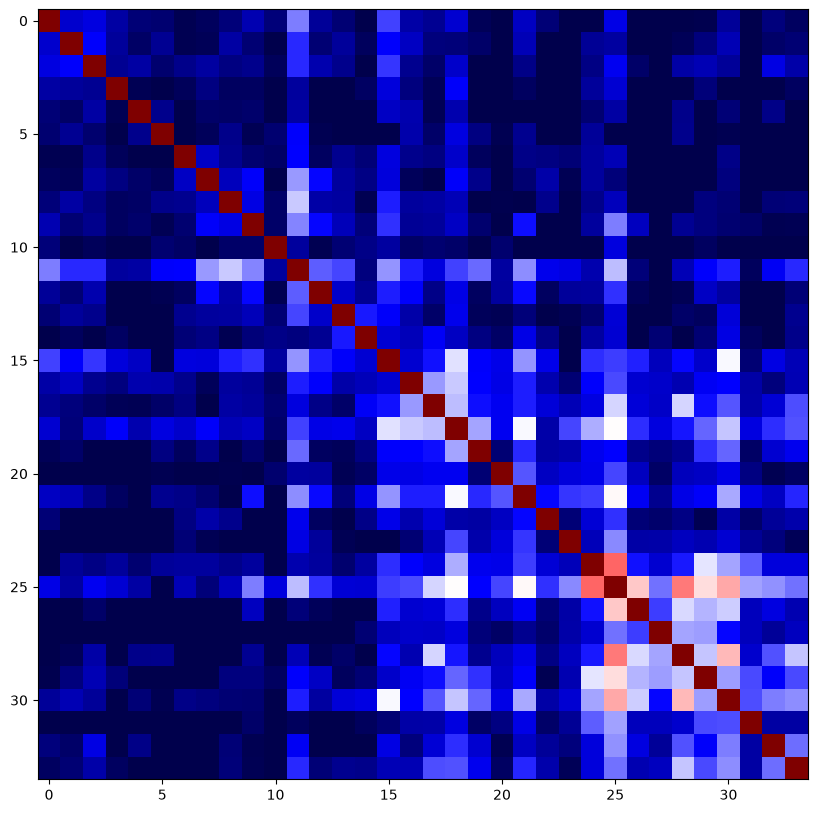

 19%|█▉        | 23/121 [29:00<2:25:05, 88.83s/it] 

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__022--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__023--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__023--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.28it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19252), np.int64(3453)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__023--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__023--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 712/712 [00:02<00:00, 268.92it/s]


fraction the same: 0.9412590879048248
fraction nan: 0.038417052214144085
EM iteration number:  4



100%|██████████| 712/712 [00:02<00:00, 267.48it/s]


fraction the same: 0.9743886318572372
fraction nan: 0.038417052214144085


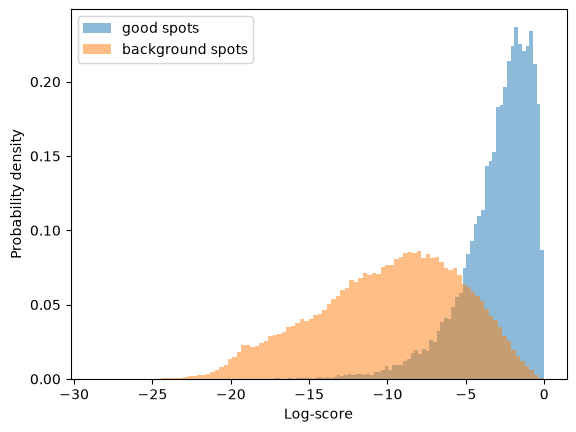

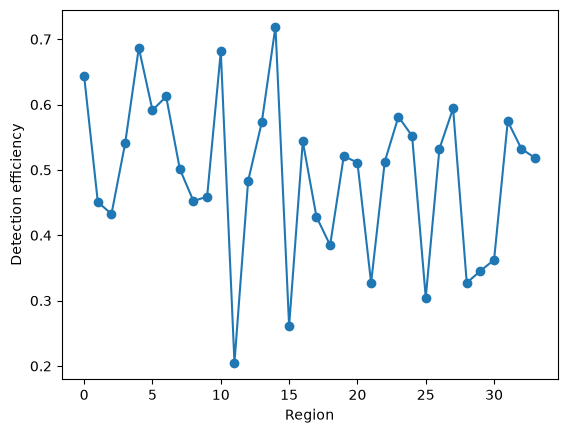

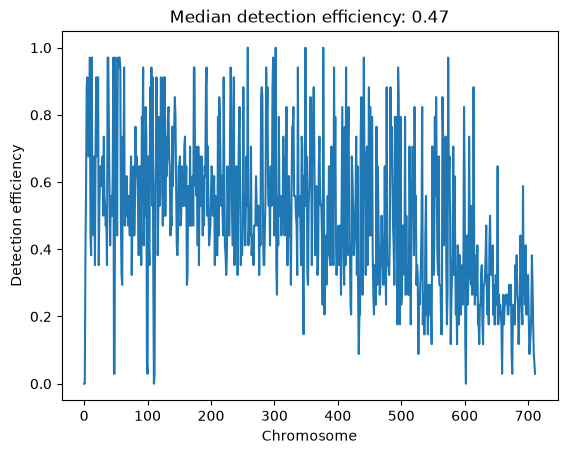

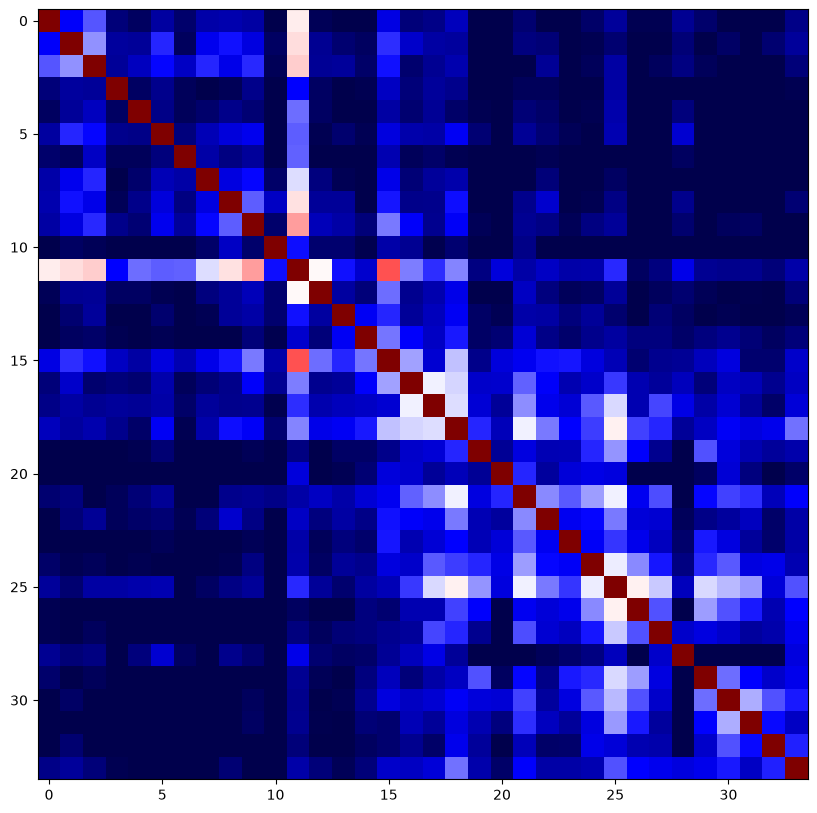

 20%|█▉        | 24/121 [30:10<2:14:43, 83.34s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__023--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__024--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__024--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.33it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(31430), np.int64(2167)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__024--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__024--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1493/1493 [00:05<00:00, 267.93it/s]


fraction the same: 0.9397580867578109
fraction nan: 0.06662464047909854
EM iteration number:  4



100%|██████████| 1493/1493 [00:05<00:00, 267.62it/s]


fraction the same: 0.9733265040778535
fraction nan: 0.06662464047909854


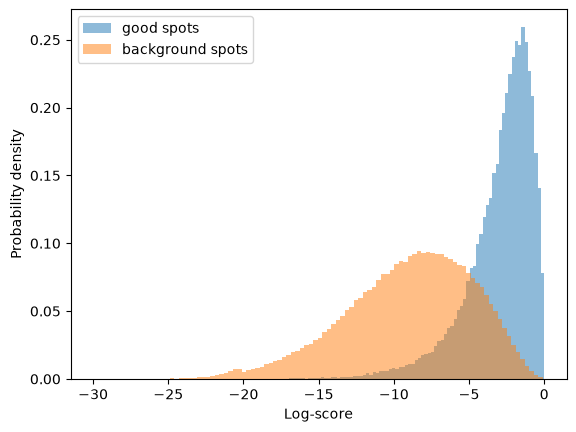

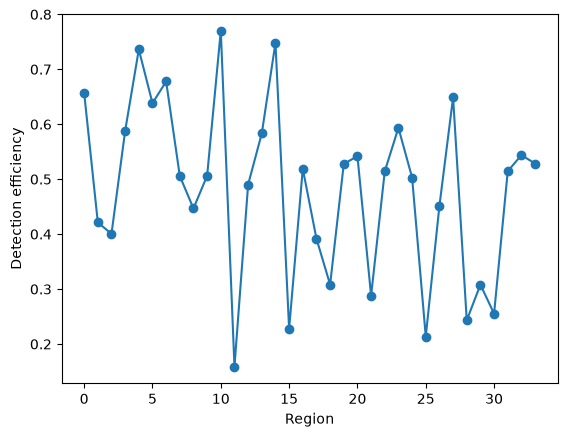

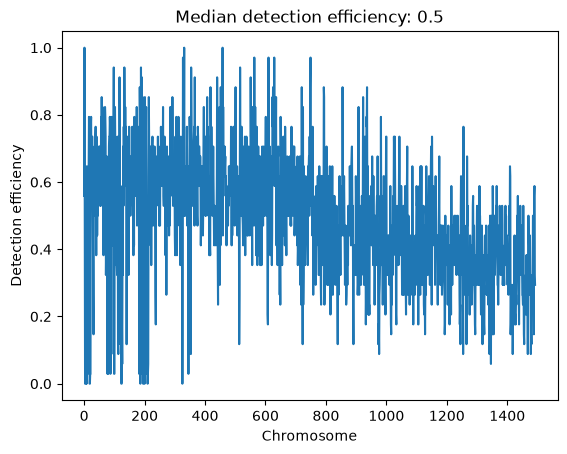

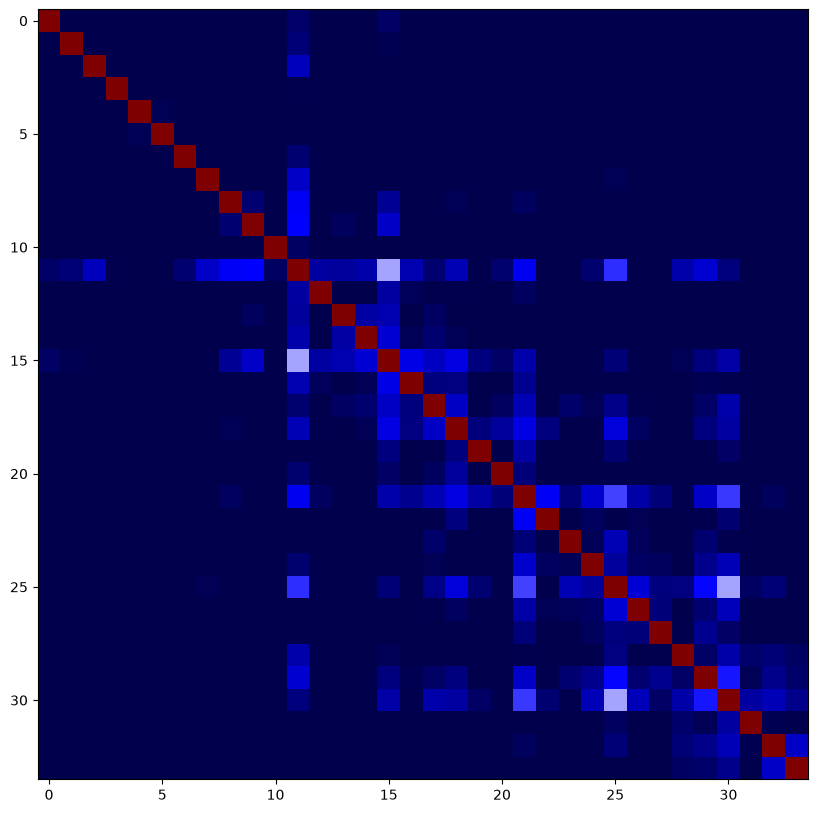

 21%|██        | 25/121 [32:02<2:26:46, 91.73s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__024--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__025--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__025--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.28it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28347), np.int64(3147)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__025--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__025--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1064/1064 [00:04<00:00, 256.54it/s]


fraction the same: 0.9315015479876161
fraction nan: 0.057579610791685096
EM iteration number:  4



100%|██████████| 1064/1064 [00:04<00:00, 256.48it/s]


fraction the same: 0.9692890314020345
fraction nan: 0.057579610791685096


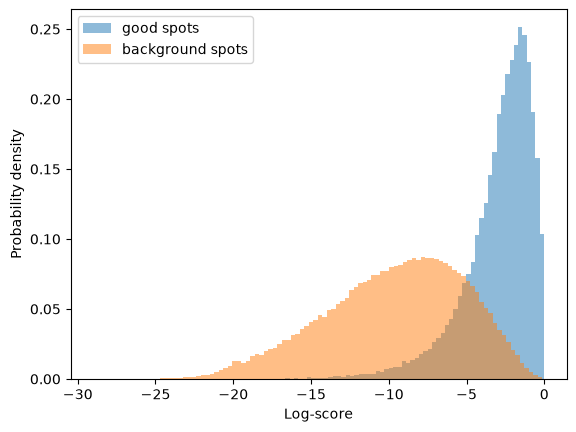

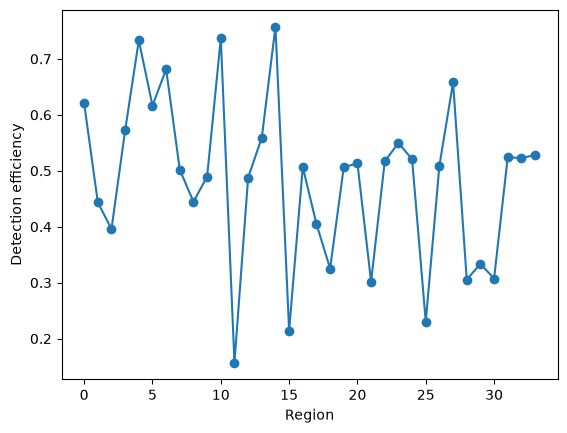

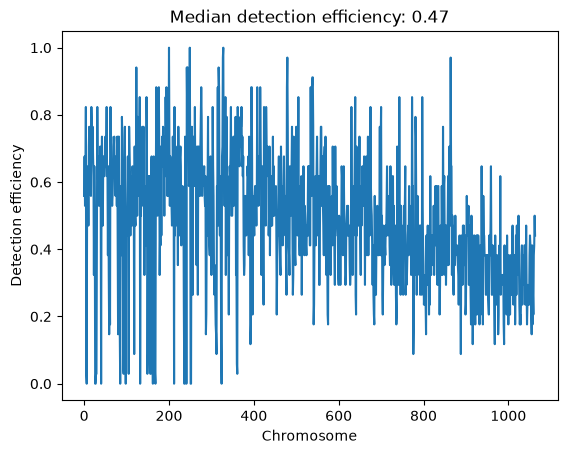

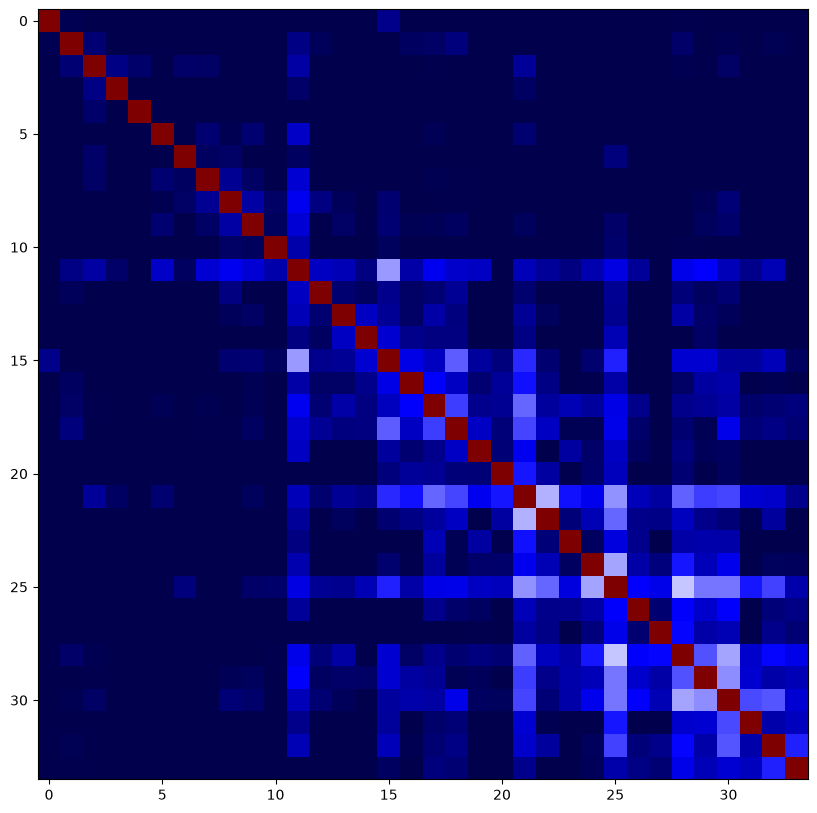

 21%|██▏       | 26/121 [33:29<2:23:17, 90.50s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__025--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__026--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__026--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.45it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24890), np.int64(5388)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__026--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__026--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 688/688 [00:02<00:00, 264.43it/s]


fraction the same: 0.9428864569083447
fraction nan: 0.06301299589603283
EM iteration number:  4



100%|██████████| 688/688 [00:02<00:00, 240.32it/s]


fraction the same: 0.9747777017783857
fraction nan: 0.06301299589603283


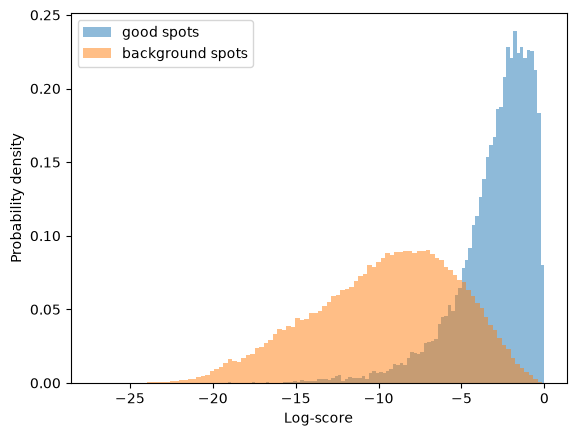

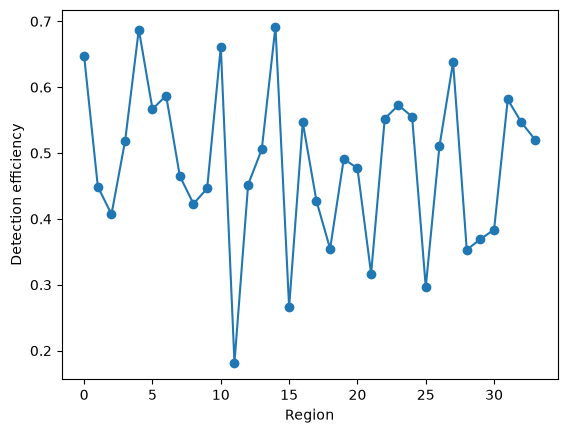

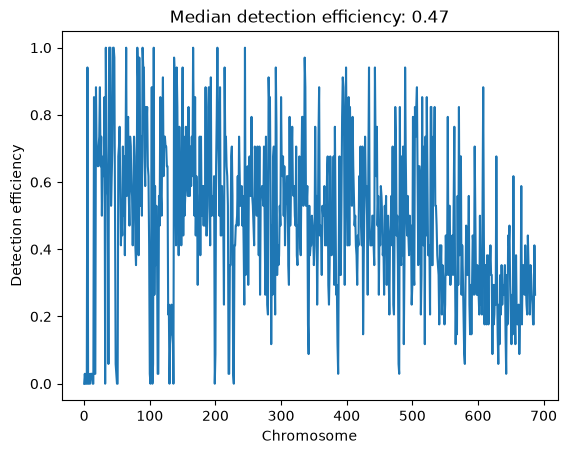

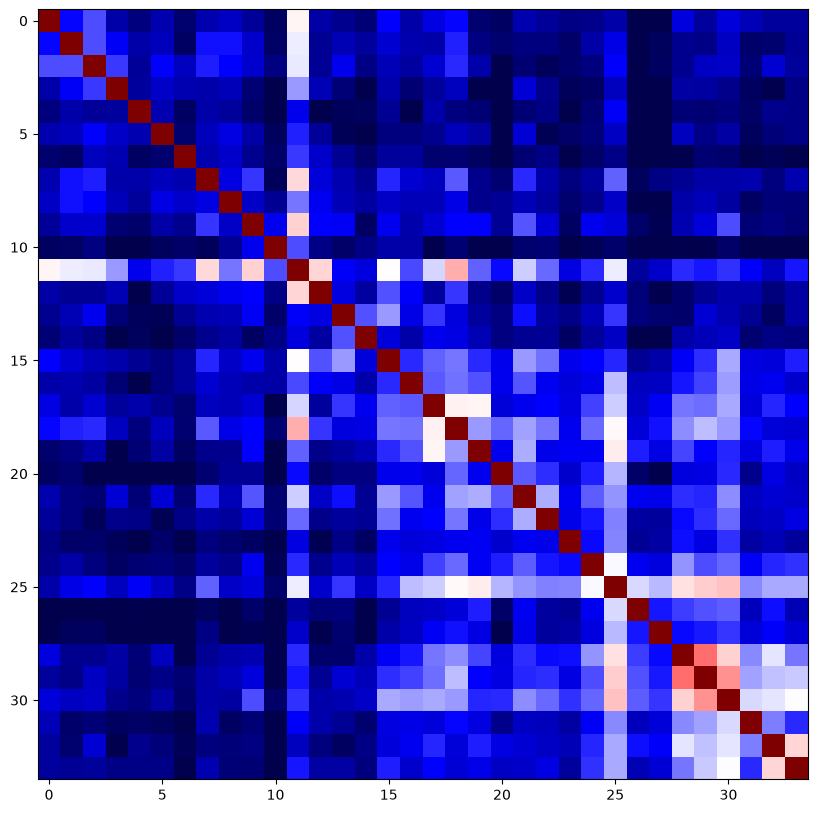

 22%|██▏       | 27/121 [34:35<2:10:00, 82.99s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__026--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__027--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__027--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(23295), np.int64(5570)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__027--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__027--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 762/762 [00:02<00:00, 280.61it/s]


fraction the same: 0.9426817971283001
fraction nan: 0.06075343523236066
EM iteration number:  4



100%|██████████| 762/762 [00:02<00:00, 280.15it/s]


fraction the same: 0.9722093561834182
fraction nan: 0.06075343523236066


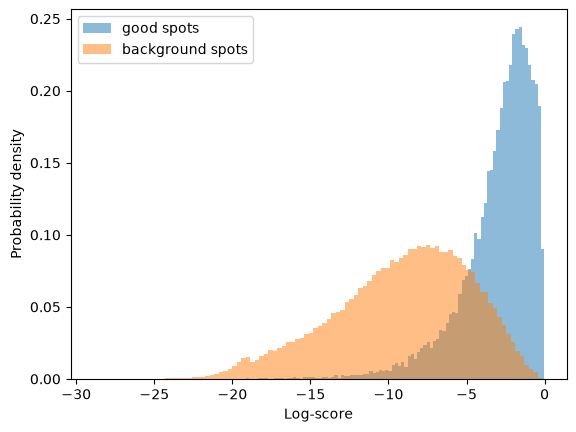

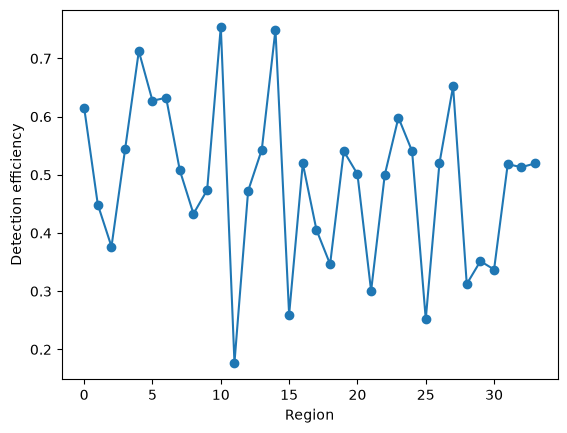

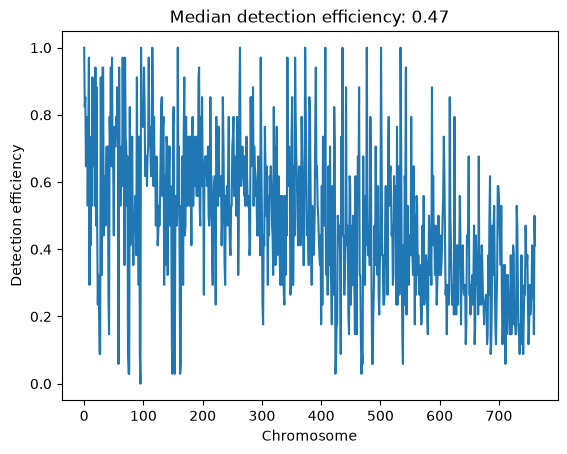

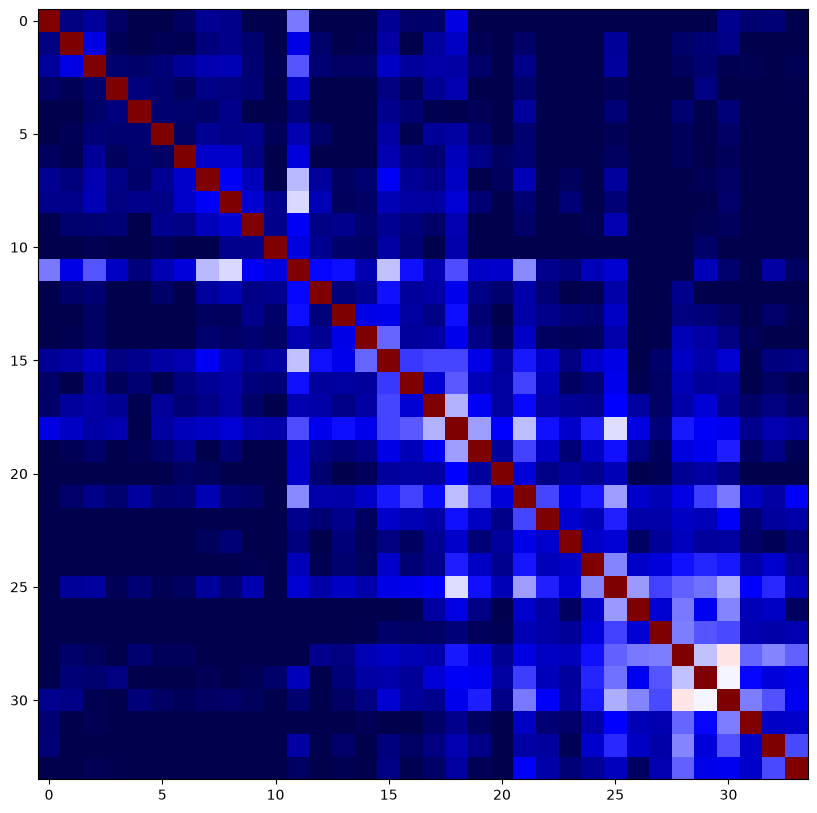

 23%|██▎       | 28/121 [35:39<2:00:05, 77.48s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__027--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__028--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__028--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:25,  1.60it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(7511), np.int64(2999)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__028--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__028--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 47/47 [00:00<00:00, 300.78it/s]


fraction the same: 0.9299123904881101
fraction nan: 0.03379224030037547
EM iteration number:  4



100%|██████████| 47/47 [00:00<00:00, 300.80it/s]


fraction the same: 0.9605757196495619
fraction nan: 0.03379224030037547


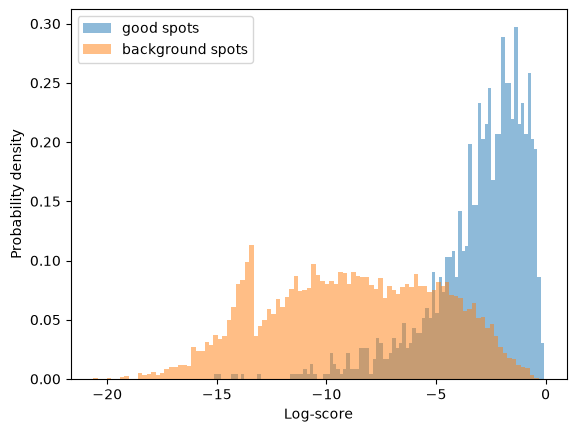

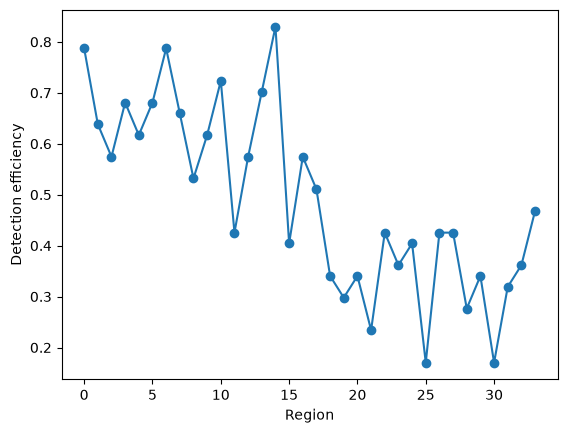

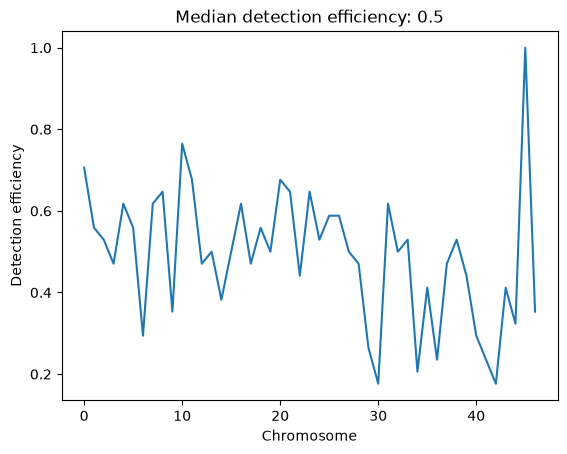

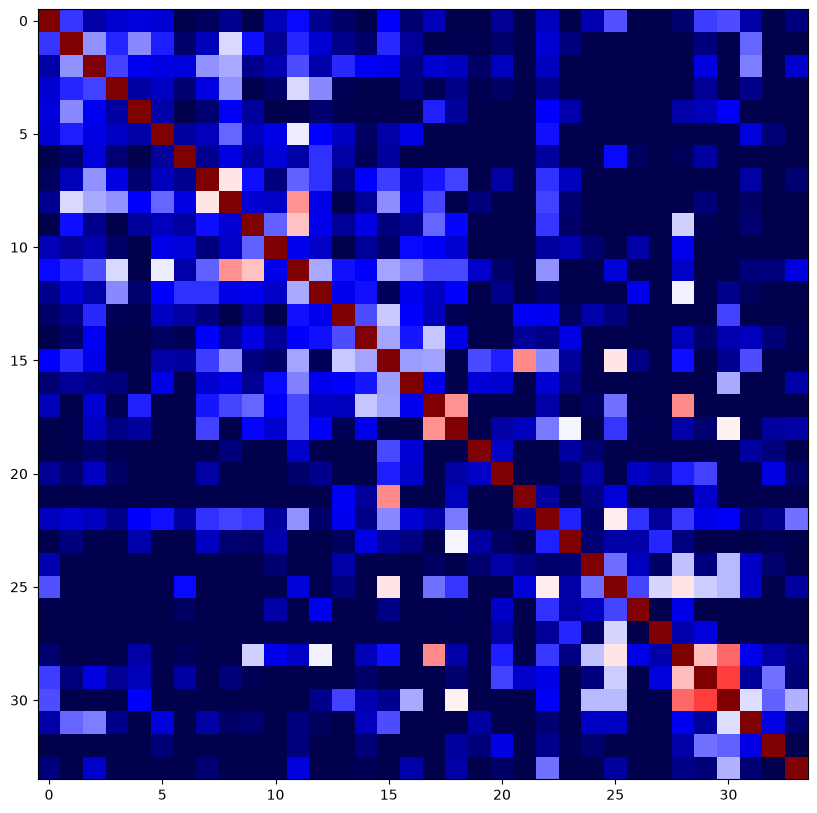

 24%|██▍       | 29/121 [36:16<1:39:51, 65.13s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__028--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__029--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__029--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(11306), np.int64(1748)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__029--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__029--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 610/610 [00:02<00:00, 278.04it/s]


fraction the same: 0.9460462873674059
fraction nan: 0.05506268081002893
EM iteration number:  4



100%|██████████| 610/610 [00:02<00:00, 276.23it/s]


fraction the same: 0.9770009643201543
fraction nan: 0.05506268081002893


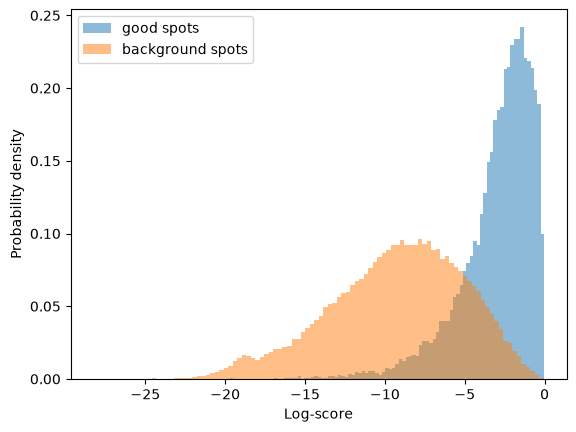

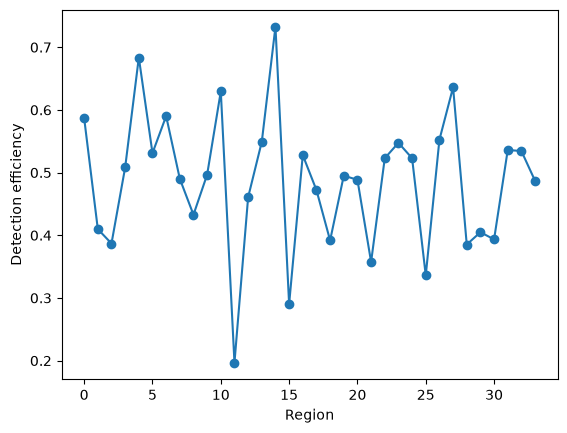

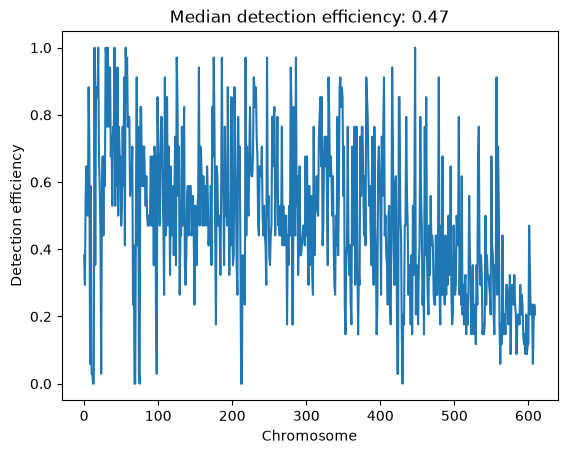

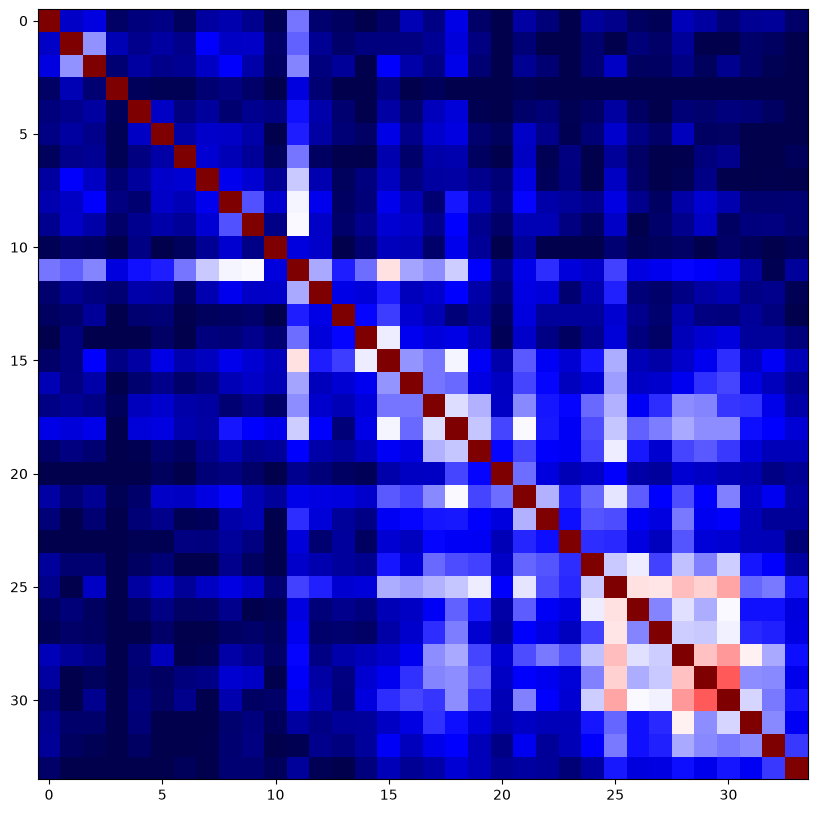

 25%|██▍       | 30/121 [37:18<1:37:36, 64.35s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__029--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__030--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__030--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:21,  1.94it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(4210), np.int64(2122)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__030--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__030--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 113/113 [00:00<00:00, 299.40it/s][A


fraction the same: 0.9380530973451328
fraction nan: 0.042165538781884435
EM iteration number:  4



100%|██████████| 113/113 [00:00<00:00, 297.86it/s][A


fraction the same: 0.9726704841228527
fraction nan: 0.042165538781884435


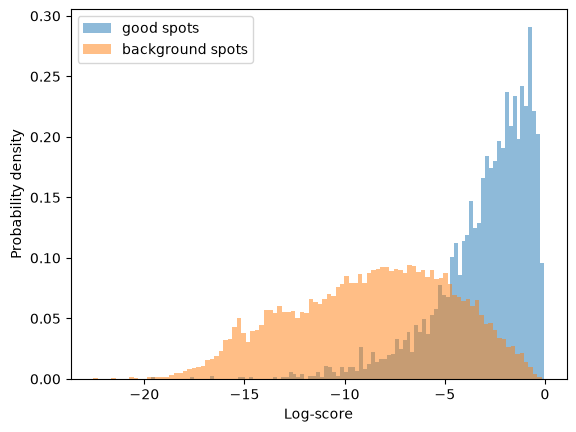

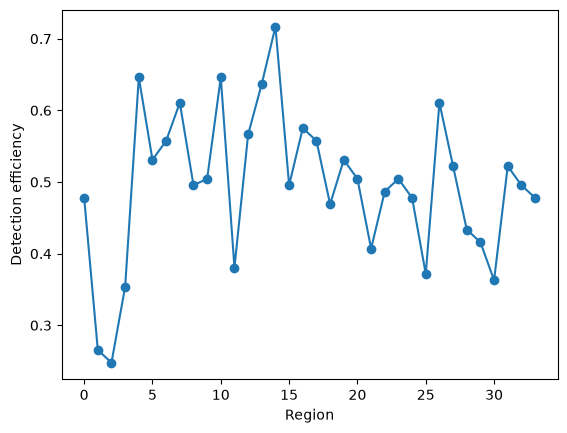

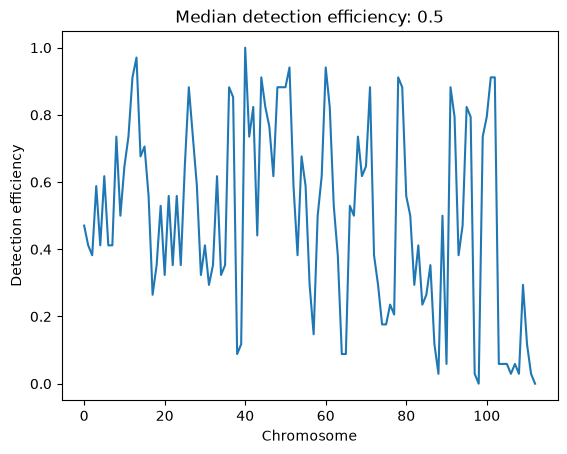

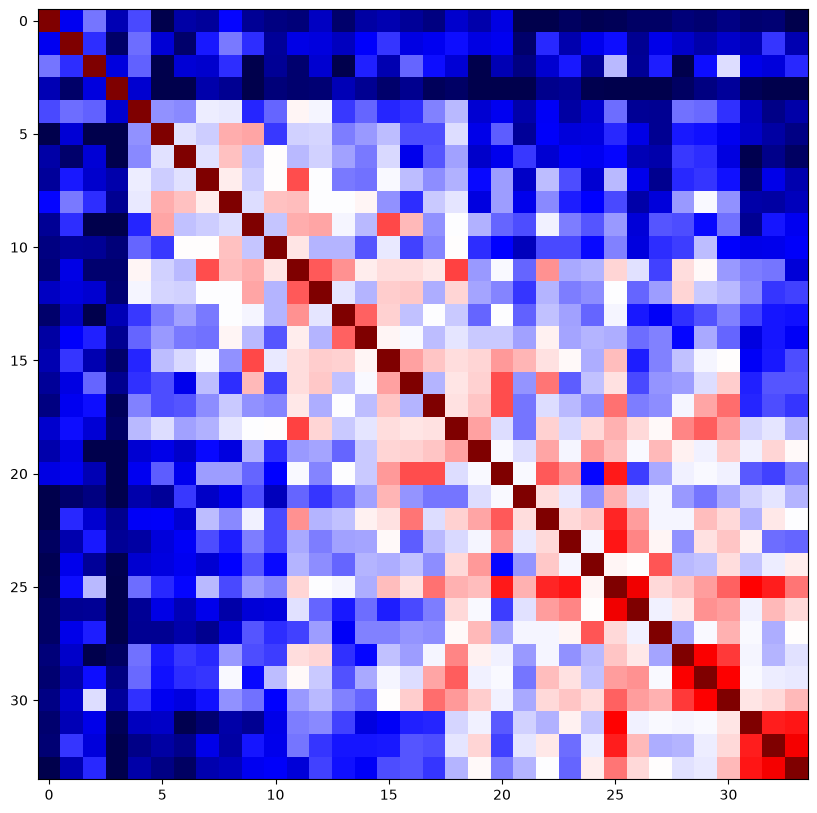

 26%|██▌       | 31/121 [37:54<1:23:47, 55.86s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__030--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__031--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__031--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.40it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19482), np.int64(6544)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__031--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__031--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 339/339 [00:01<00:00, 251.84it/s]


fraction the same: 0.9334547978483428
fraction nan: 0.03071317022384175
EM iteration number:  4



100%|██████████| 339/339 [00:01<00:00, 212.37it/s]


fraction the same: 0.9702411938226618
fraction nan: 0.03071317022384175


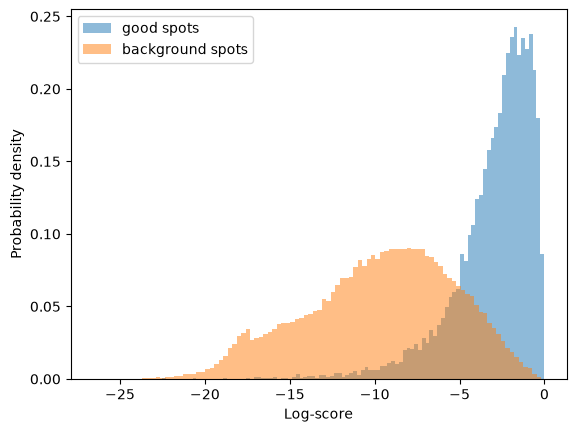

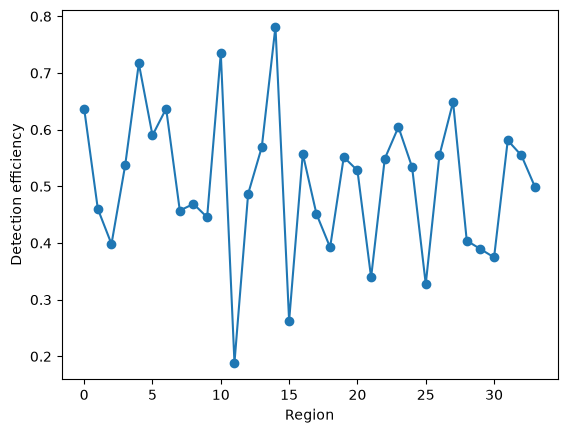

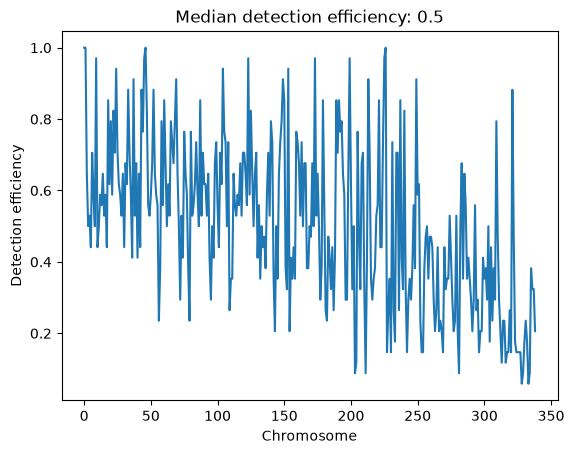

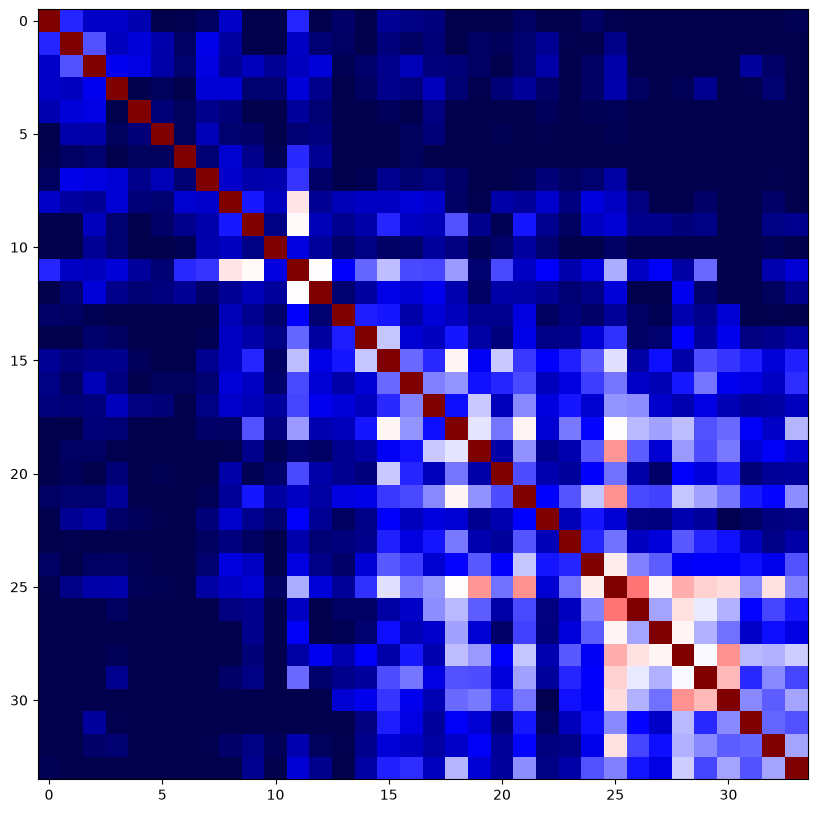

 26%|██▋       | 32/121 [38:48<1:21:41, 55.07s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__031--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__032--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__032--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.25it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19523), np.int64(6097)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__032--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__032--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 419/419 [00:01<00:00, 281.76it/s]


fraction the same: 0.9371753474659553
fraction nan: 0.0575600168468342
EM iteration number:  4



100%|██████████| 419/419 [00:01<00:00, 285.26it/s]


fraction the same: 0.9736066264214517
fraction nan: 0.0575600168468342


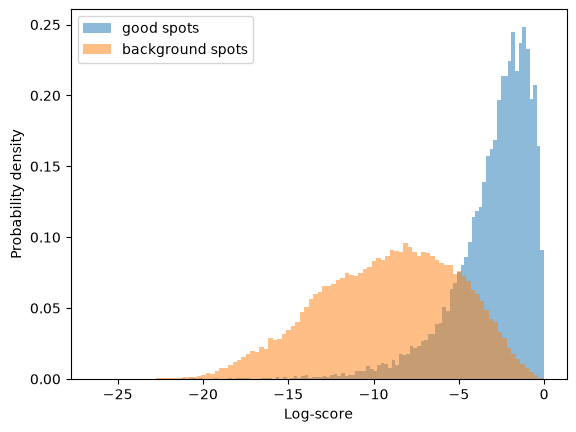

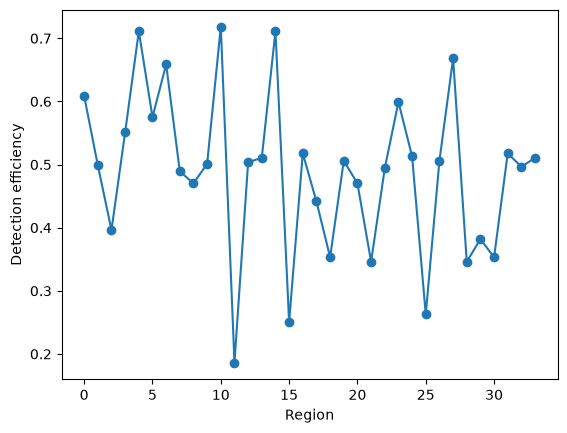

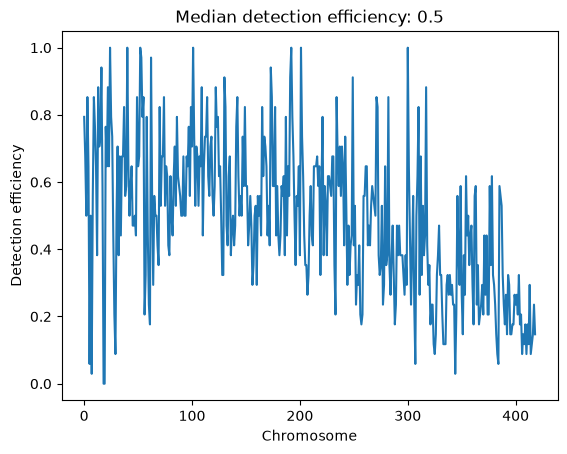

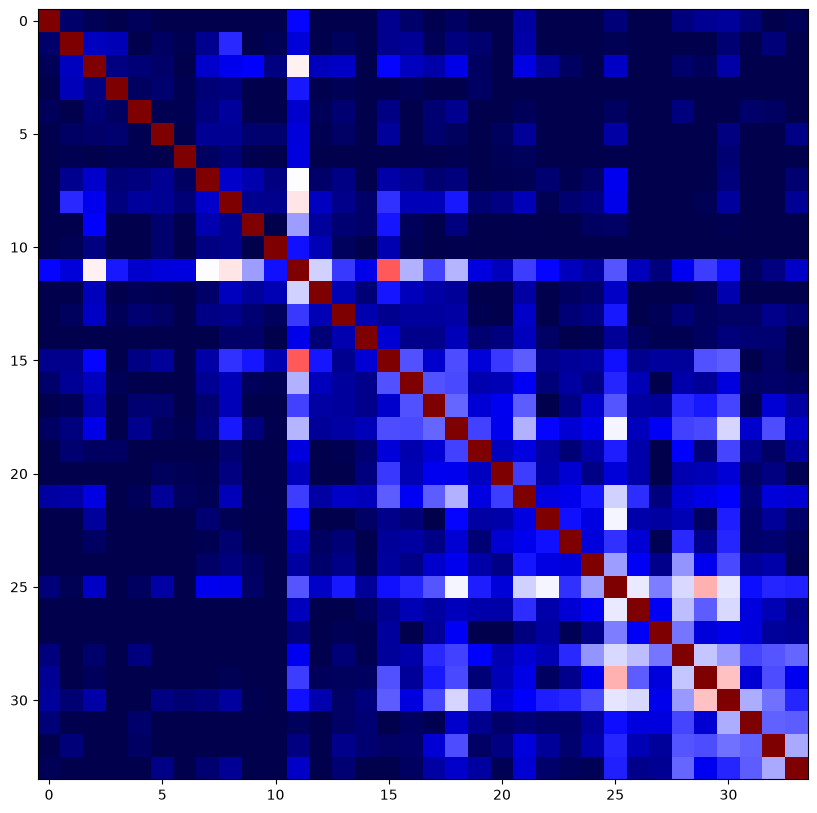

 27%|██▋       | 33/121 [39:40<1:19:49, 54.43s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__032--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__033--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__033--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:10,  3.76it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(2645), np.int64(2576)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__033--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__033--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 267/267 [00:01<00:00, 247.01it/s]


fraction the same: 0.9371006829698172
fraction nan: 0.06444150693985459
EM iteration number:  4



100%|██████████| 267/267 [00:01<00:00, 247.13it/s]


fraction the same: 0.967724168319013
fraction nan: 0.06444150693985459


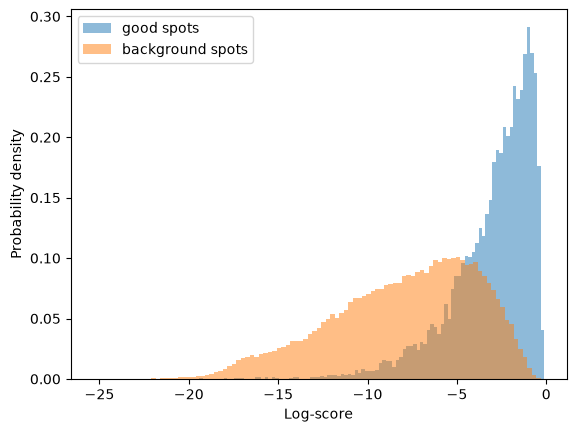

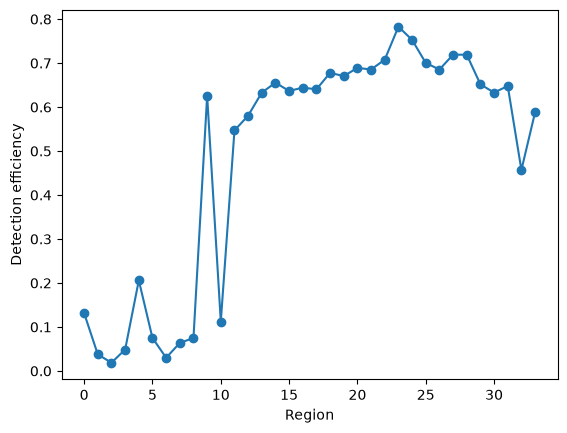

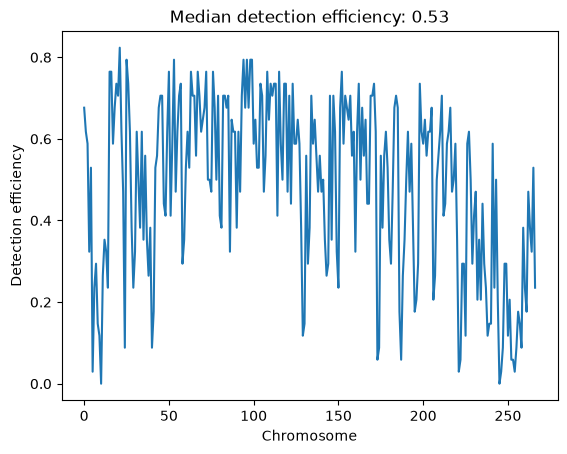

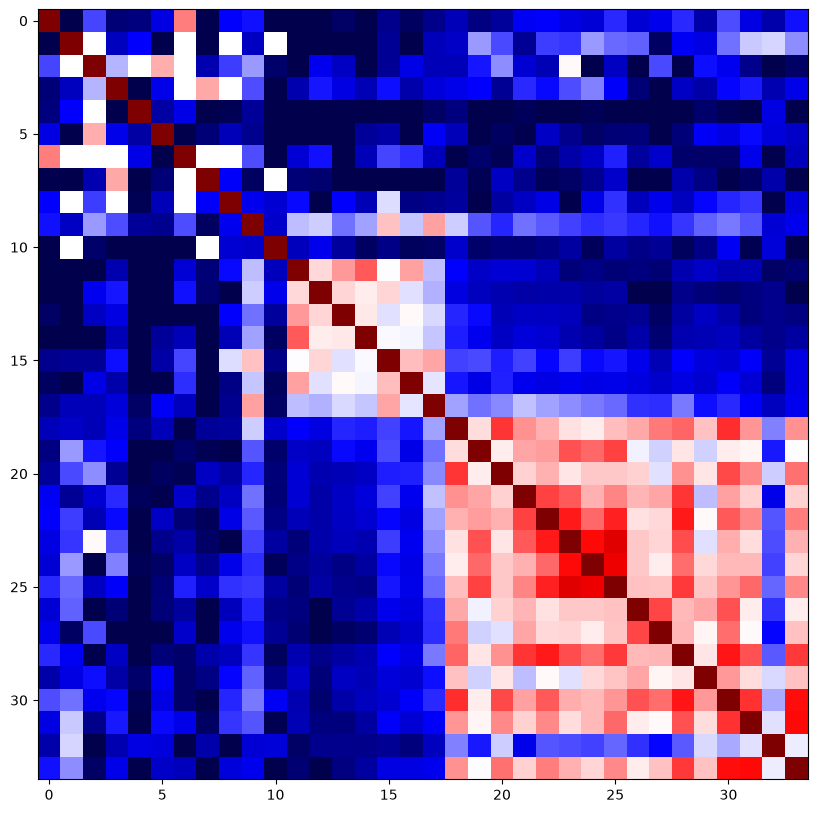

 28%|██▊       | 34/121 [40:26<1:14:54, 51.66s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__033--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__034--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__034--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:27,  1.49it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(13034), np.int64(5847)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__034--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__034--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 219/219 [00:00<00:00, 310.98it/s]


fraction the same: 0.9417136717700779
fraction nan: 0.05049691109320441
EM iteration number:  4



100%|██████████| 219/219 [00:00<00:00, 303.04it/s]


fraction the same: 0.9705882352941176
fraction nan: 0.05049691109320441


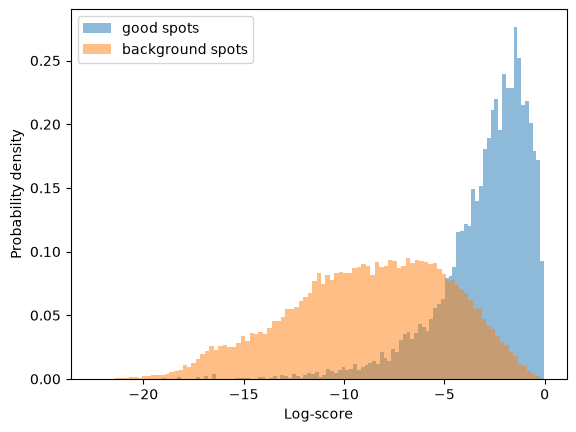

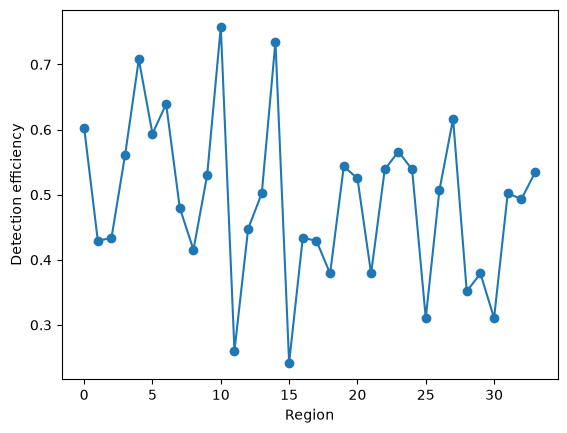

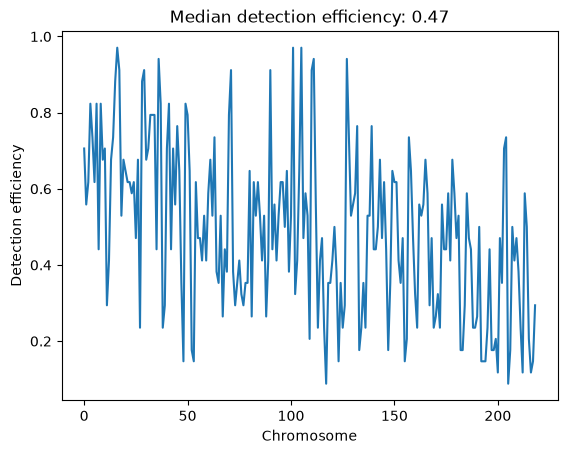

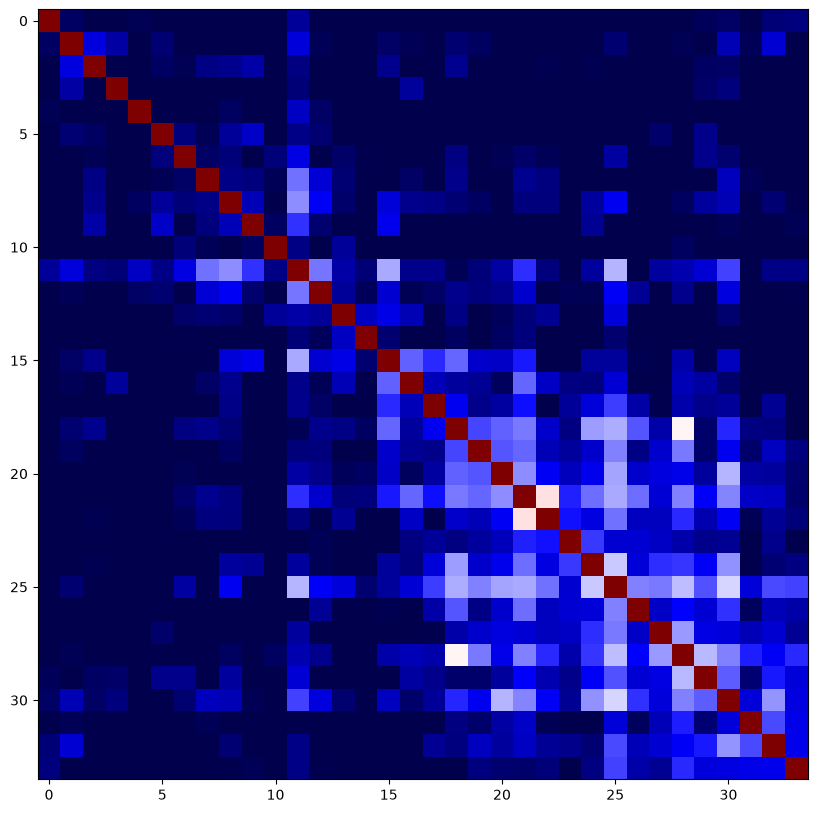

 29%|██▉       | 35/121 [41:06<1:09:12, 48.28s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__034--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__035--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__035--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:27,  1.48it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(9706), np.int64(4180)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__035--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__035--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 42/42 [00:00<00:00, 537.57it/s]


fraction the same: 0.9572829131652661
fraction nan: 0.14425770308123248
EM iteration number:  4



100%|██████████| 42/42 [00:00<00:00, 447.97it/s]

fraction the same: 0.9845938375350141
fraction nan: 0.14425770308123248


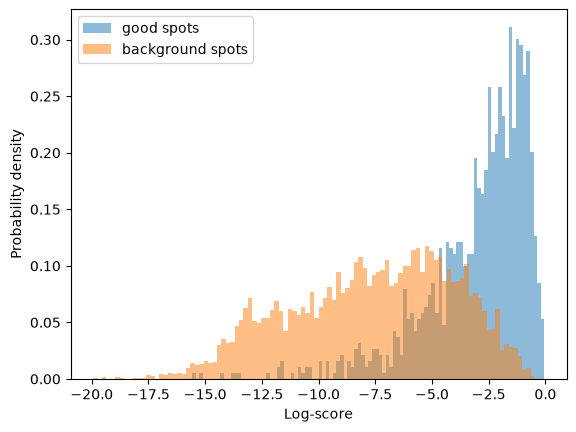

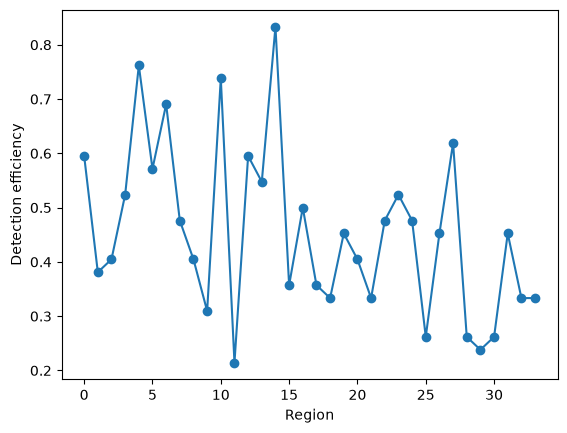

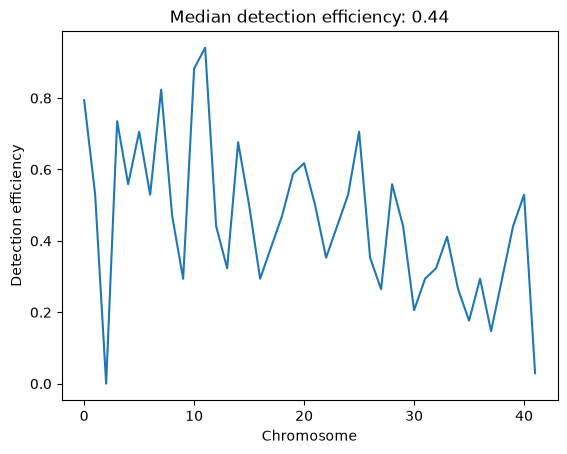

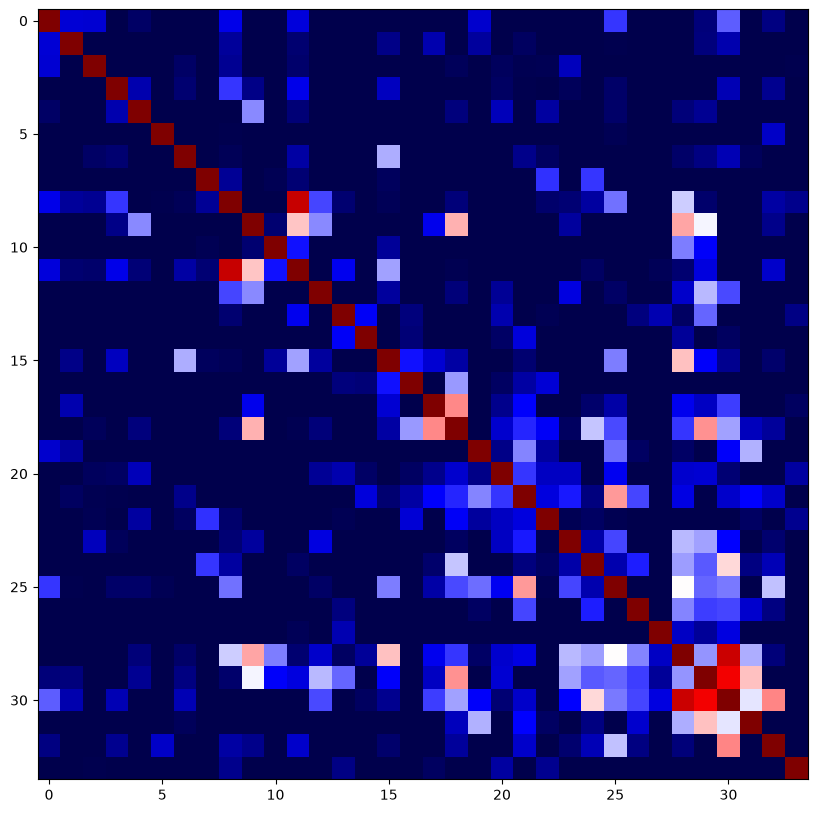

 30%|██▉       | 36/121 [41:42<1:03:19, 44.70s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__035--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__036--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__036--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.45it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19625), np.int64(4958)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__036--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__036--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 526/526 [00:01<00:00, 292.14it/s]


fraction the same: 0.9488928651308433
fraction nan: 0.06927980317602327
EM iteration number:  4



100%|██████████| 526/526 [00:01<00:00, 294.88it/s]


fraction the same: 0.9786960411541042
fraction nan: 0.06927980317602327


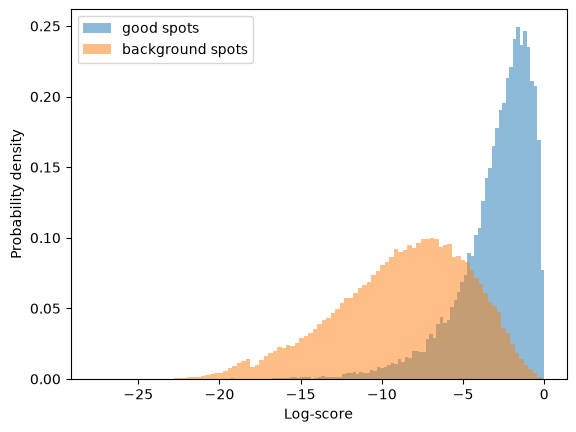

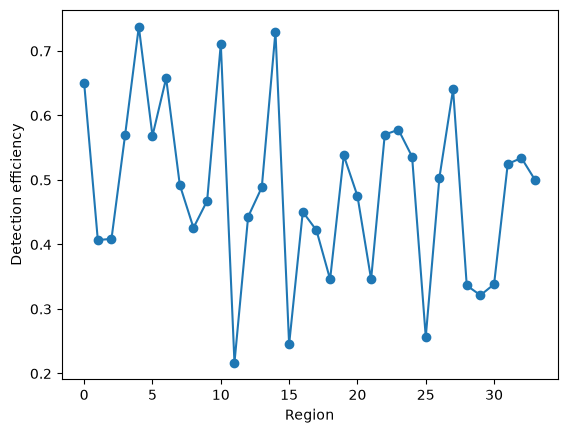

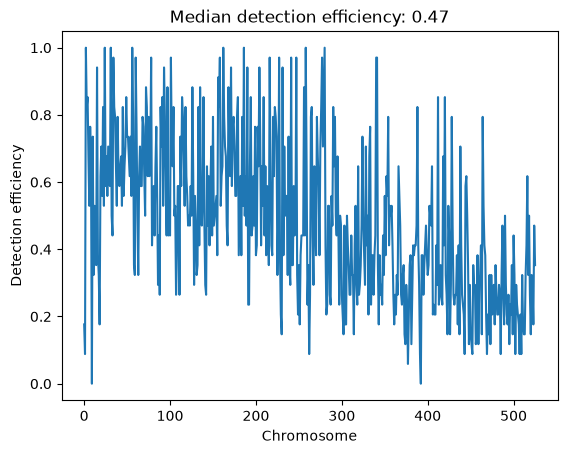

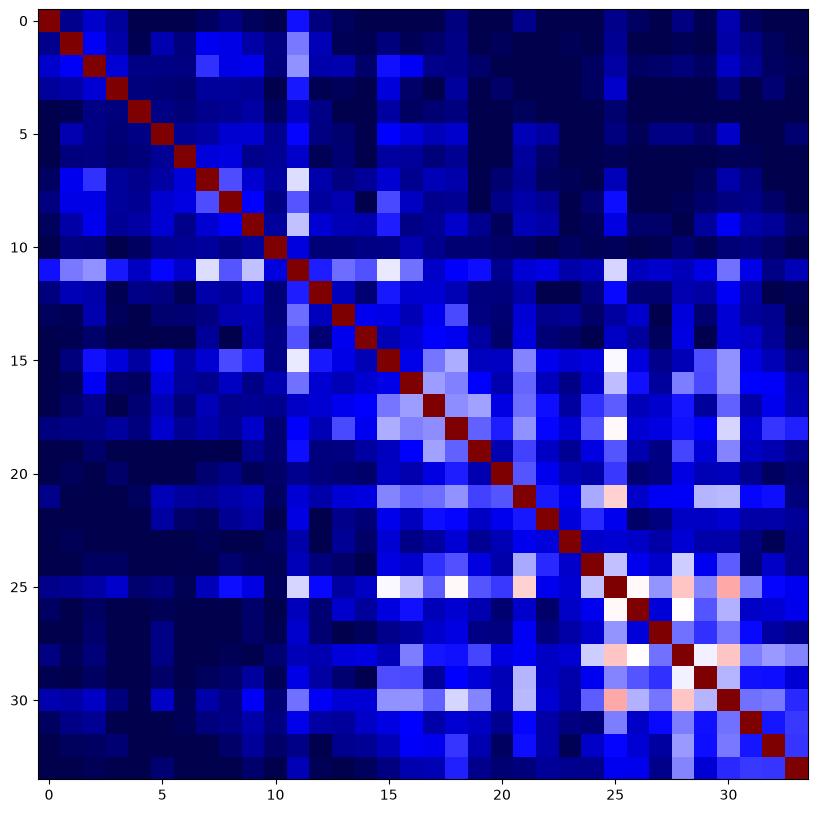

 31%|███       | 37/121 [42:35<1:05:57, 47.11s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__036--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__037--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__037--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.36it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(11373), np.int64(6665)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__037--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__037--H10_NC_set1--dapiFeatures.npz


... (180 outputs left out)


100%|██████████| 176/176 [00:00<00:00, 312.87it/s]


fraction the same: 0.9468582887700535
fraction nan: 0.07453208556149733
EM iteration number:  4



100%|██████████| 176/176 [00:00<00:00, 211.89it/s]


fraction the same: 0.9789438502673797
fraction nan: 0.07453208556149733


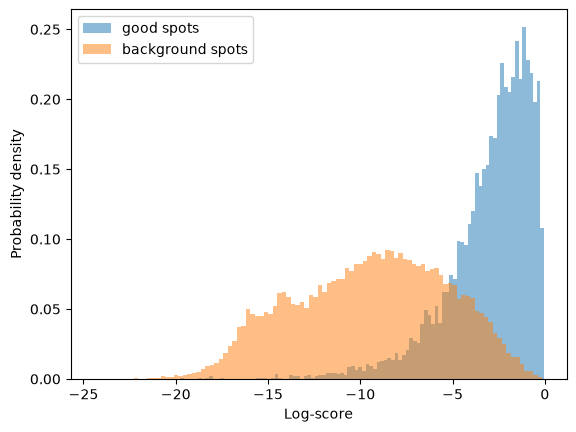

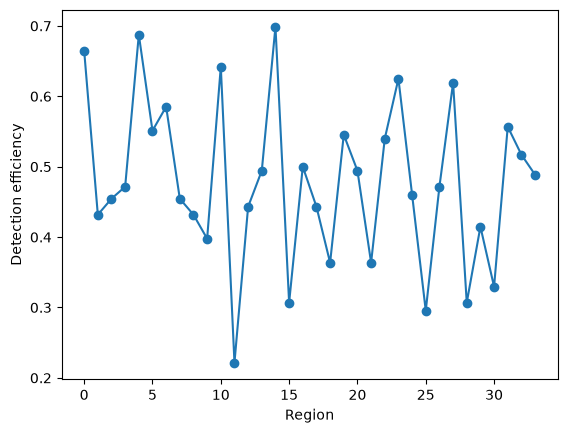

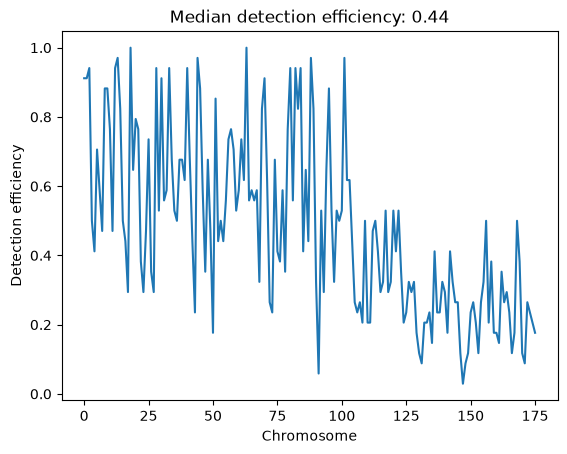

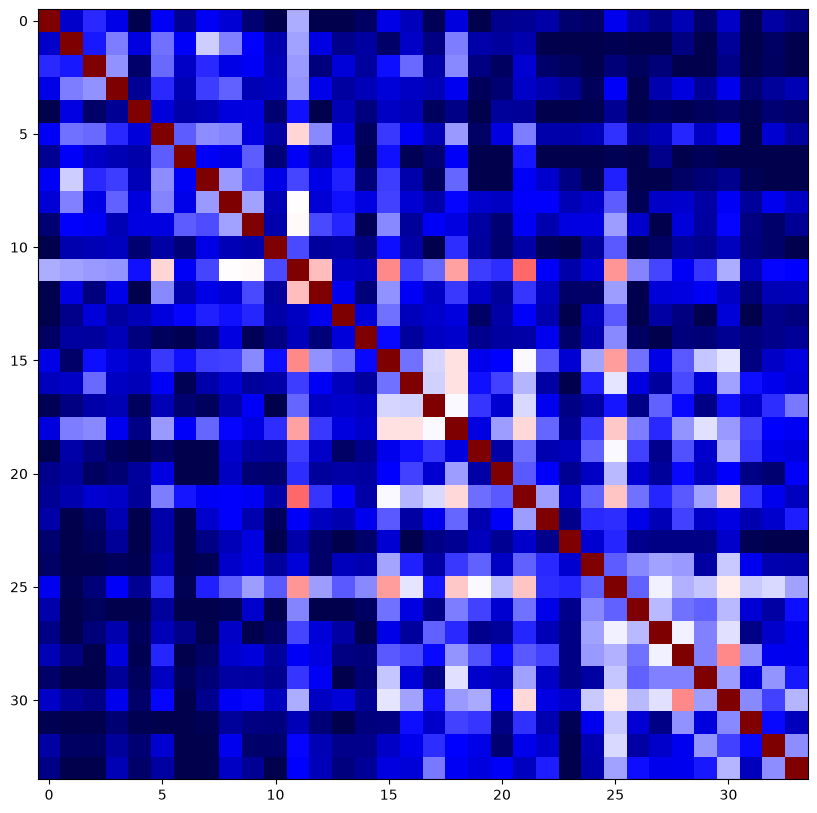

 32%|███▏      | 39/121 [43:52<58:57, 43.14s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__038--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__039--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__039--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:18,  2.20it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(1852), np.int64(1734)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__039--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__039--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 368/368 [00:00<00:00, 444.35it/s]


fraction the same: 0.9760230179028133
fraction nan: 0.396019820971867
EM iteration number:  4



100%|██████████| 368/368 [00:00<00:00, 443.02it/s]


fraction the same: 0.9868126598465473
fraction nan: 0.396019820971867


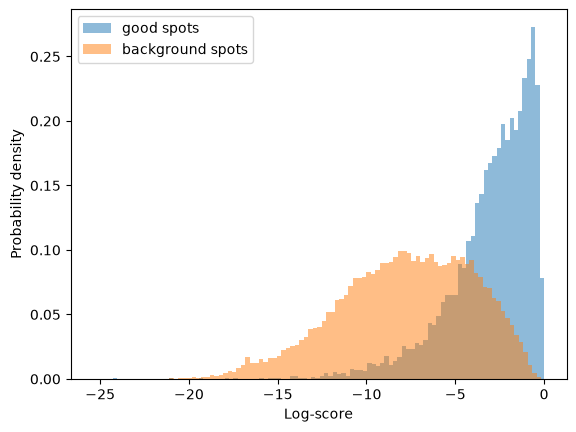

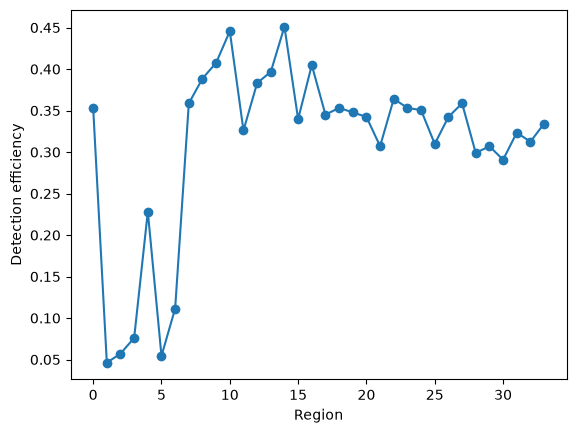

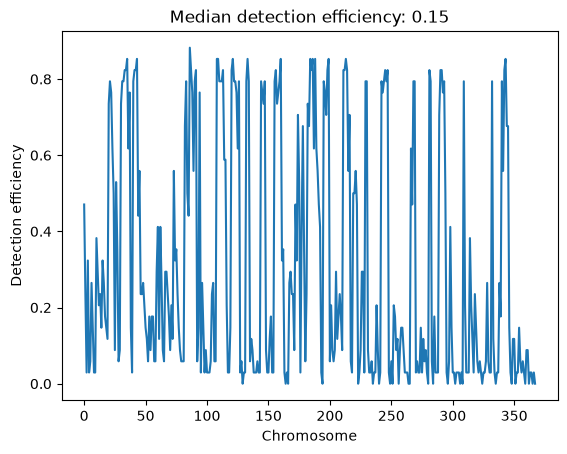

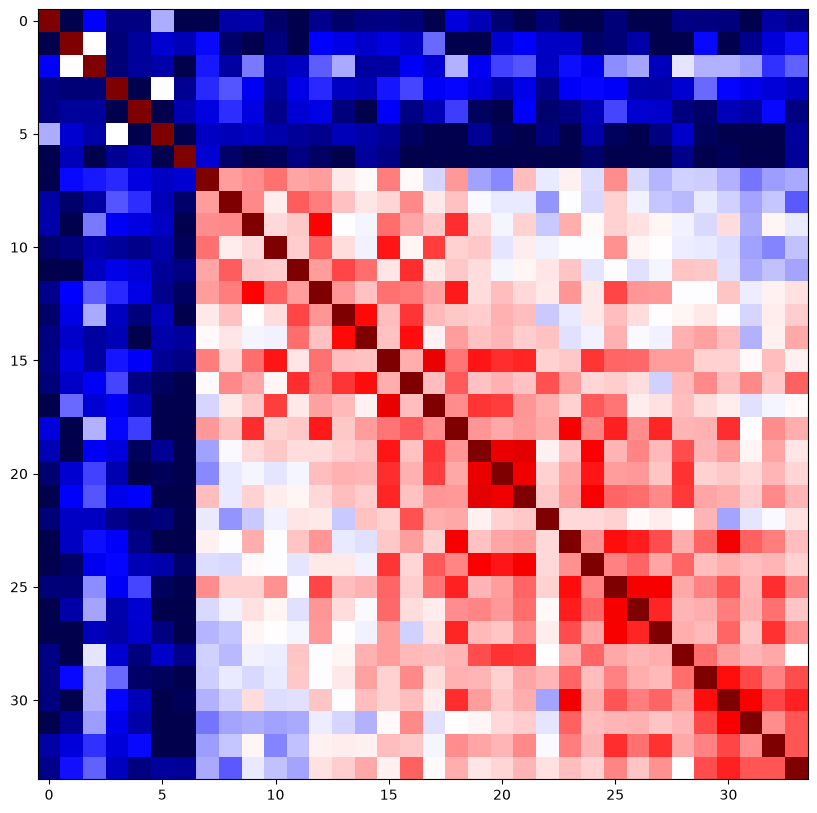

 33%|███▎      | 40/121 [44:29<55:53, 41.40s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__039--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__040--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__040--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(21806), np.int64(4236)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__040--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__040--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 673/673 [00:02<00:00, 285.90it/s]


fraction the same: 0.9451970981557556
fraction nan: 0.07560527925880604
EM iteration number:  4



100%|██████████| 673/673 [00:02<00:00, 286.51it/s]


fraction the same: 0.9763132593304781
fraction nan: 0.07560527925880604


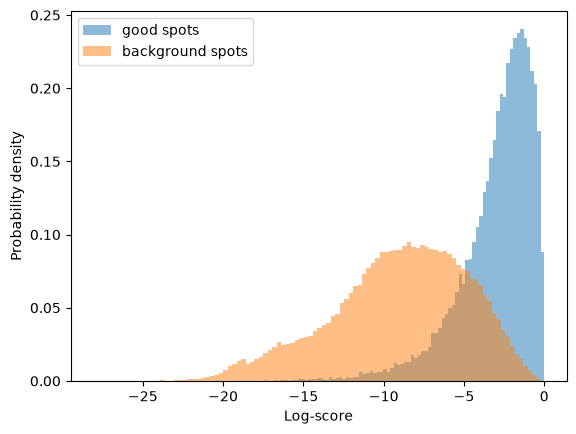

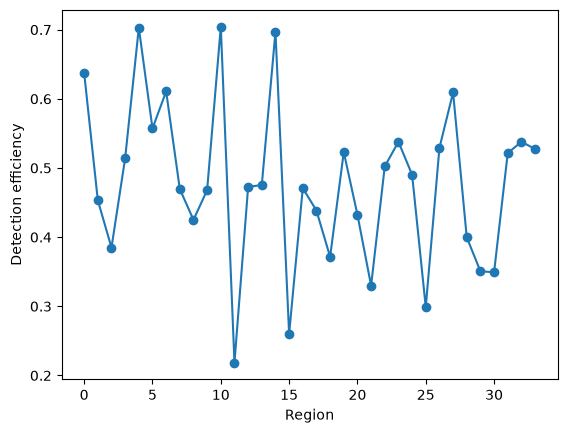

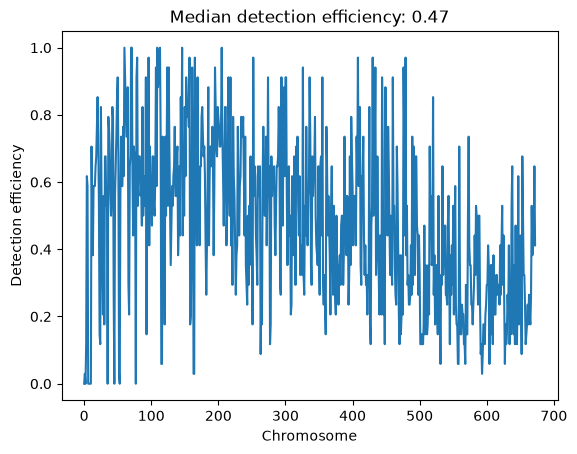

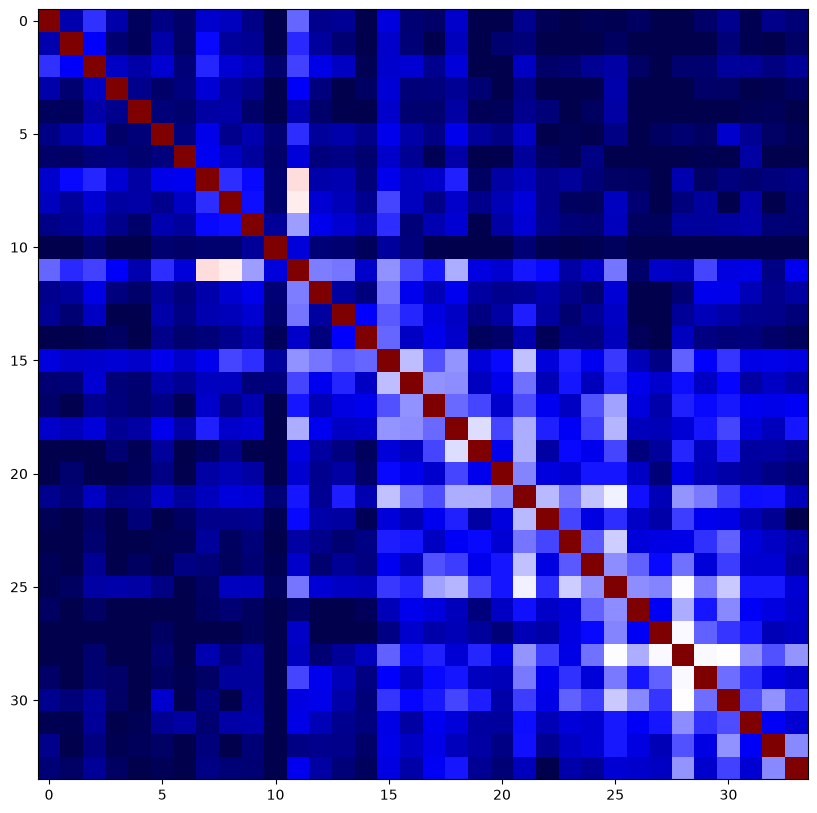

 34%|███▍      | 41/121 [45:29<1:02:27, 46.85s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__040--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__041--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__041--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:10,  3.75it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(1921), np.int64(1459)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__041--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__041--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 650/650 [00:01<00:00, 471.88it/s]


fraction the same: 0.9675565610859729
fraction nan: 0.4515837104072398
EM iteration number:  4



100%|██████████| 650/650 [00:01<00:00, 466.57it/s]


fraction the same: 0.9855203619909503
fraction nan: 0.4515837104072398


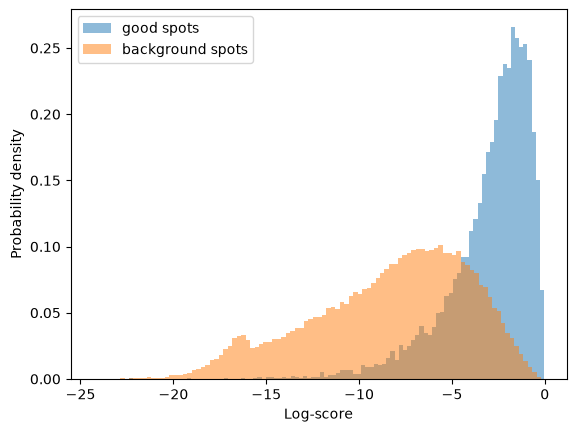

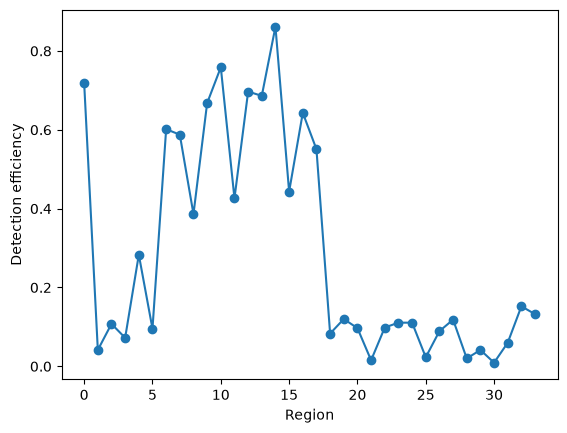

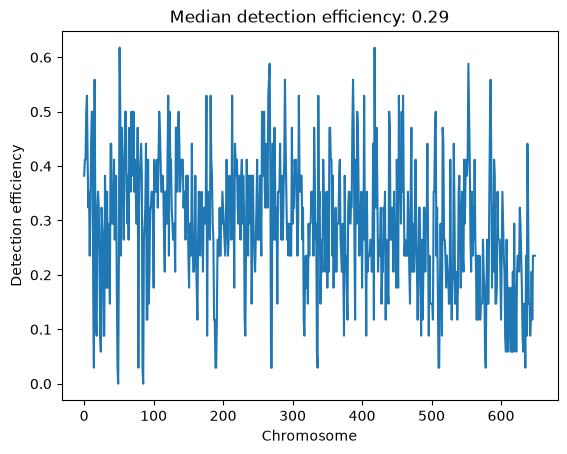

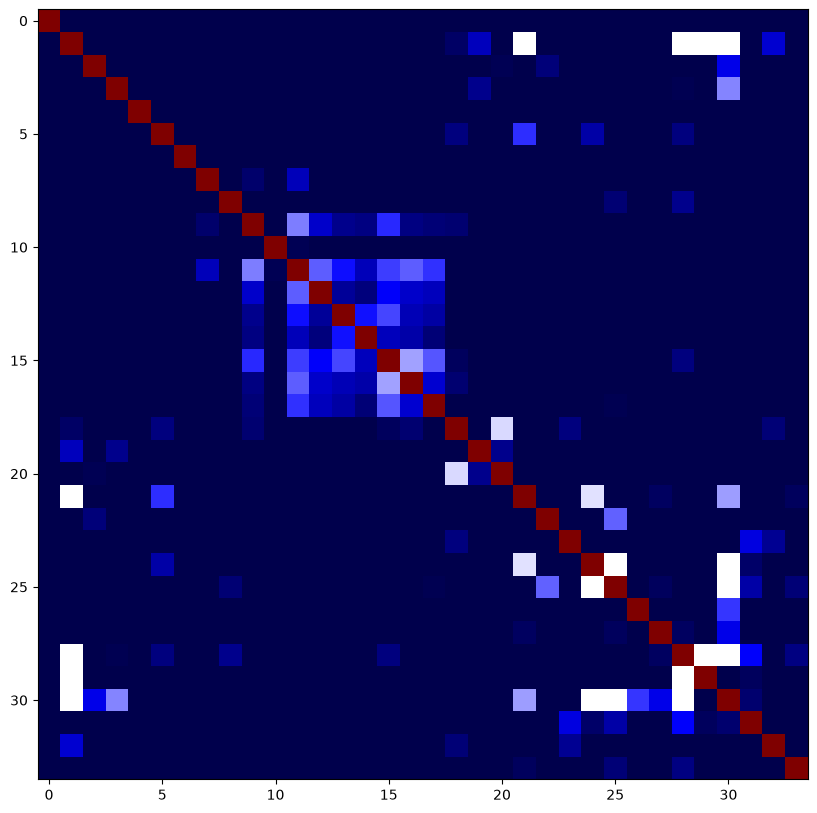

 35%|███▍      | 42/121 [46:19<1:03:00, 47.86s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__041--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__042--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__042--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.33it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(26275), np.int64(3760)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__042--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__042--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 974/974 [00:03<00:00, 247.65it/s]


fraction the same: 0.9505073076458509
fraction nan: 0.05939727020171518
EM iteration number:  4



100%|██████████| 974/974 [00:03<00:00, 265.49it/s]


fraction the same: 0.9775637154245682
fraction nan: 0.05939727020171518


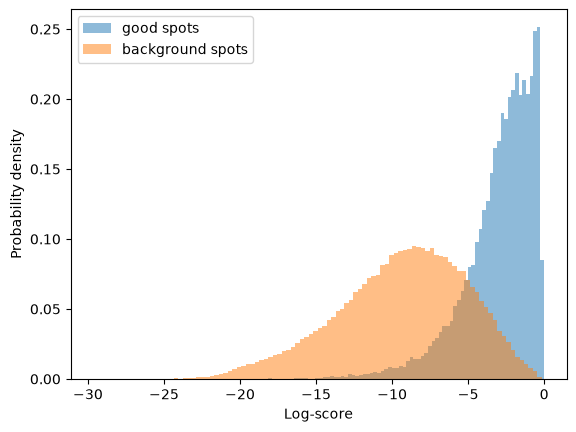

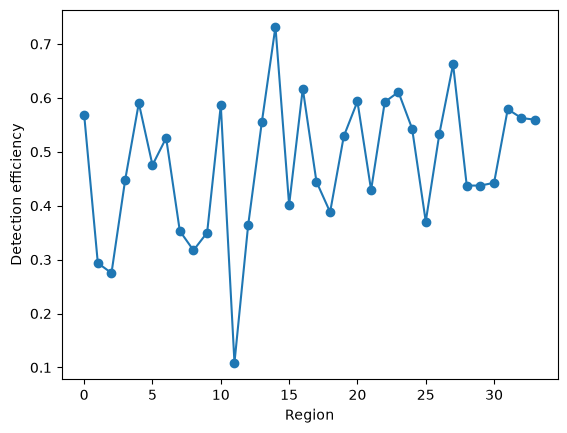

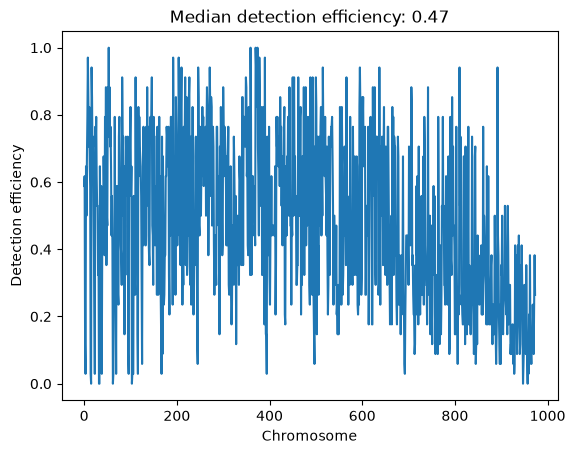

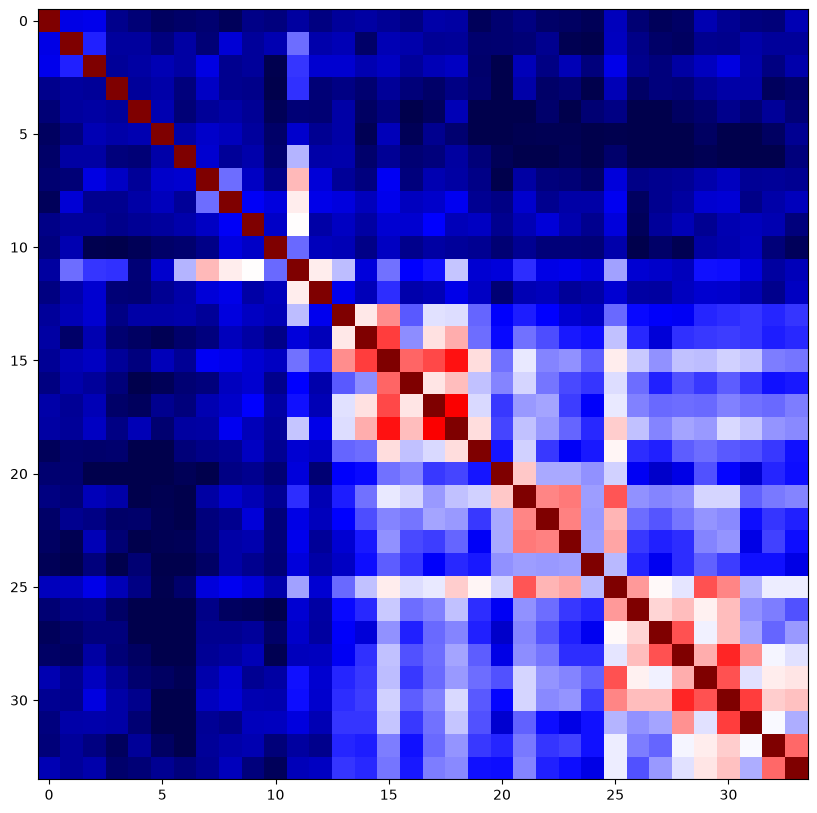

 36%|███▌      | 43/121 [47:33<1:12:27, 55.74s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__042--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__043--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__043--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:18,  2.27it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(2070), np.int64(1986)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__043--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__043--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 879/879 [00:01<00:00, 543.37it/s]


fraction the same: 0.9745365723081041
fraction nan: 0.4792545004349863
EM iteration number:  4



100%|██████████| 879/879 [00:01<00:00, 544.38it/s]


fraction the same: 0.9885565147560731
fraction nan: 0.4792545004349863


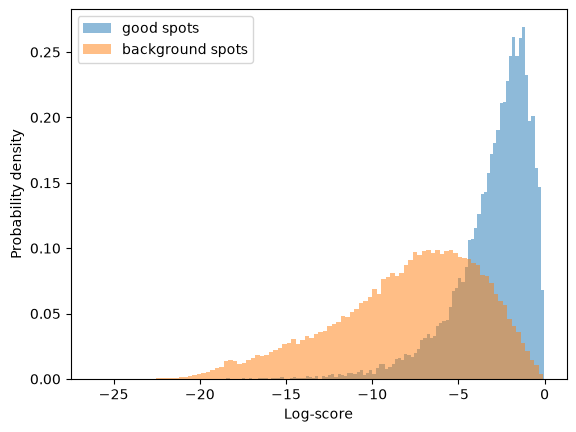

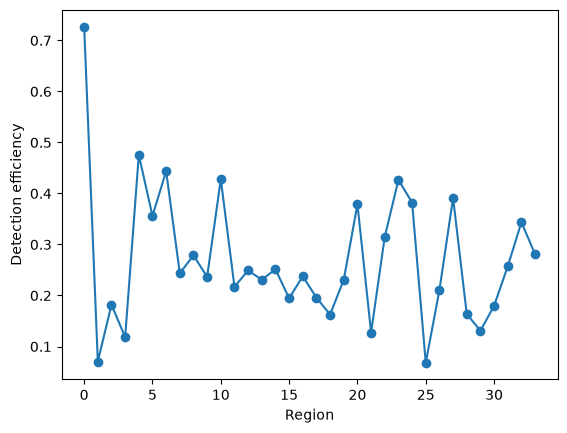

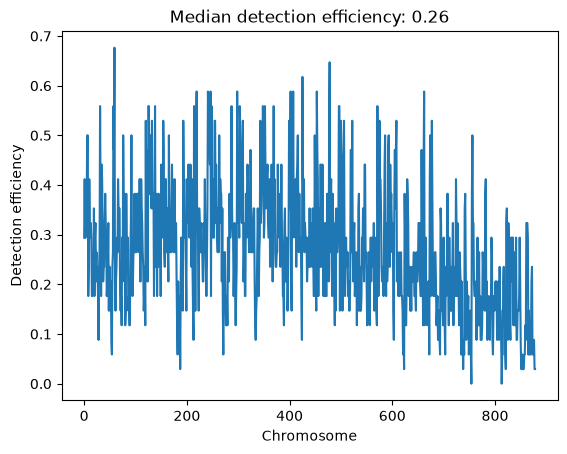

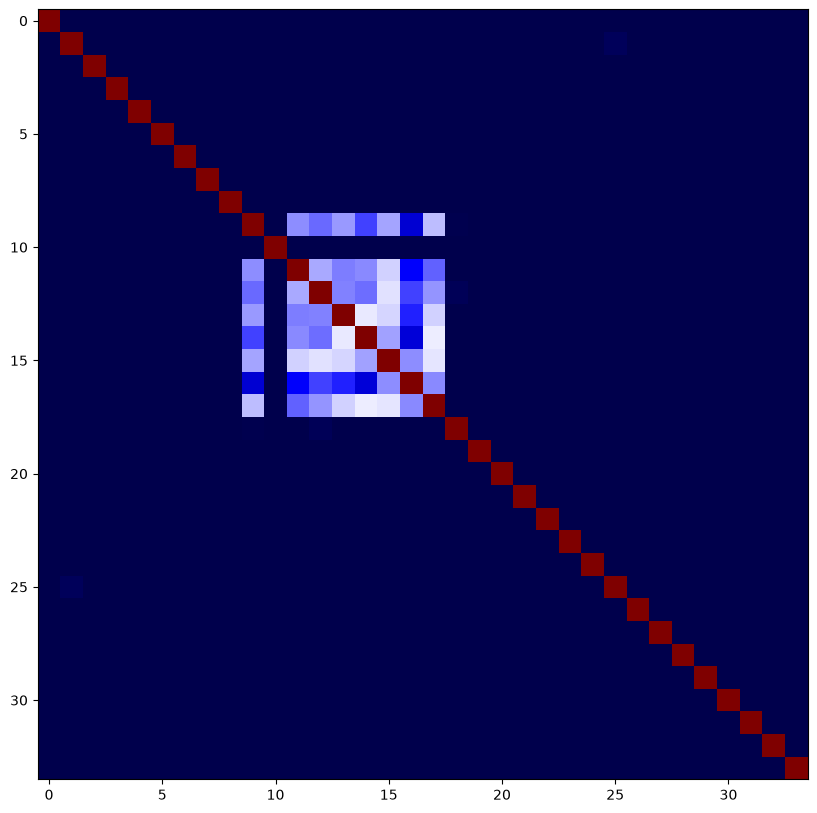

 36%|███▋      | 44/121 [48:43<1:16:47, 59.84s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__043--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__044--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__044--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:25,  1.64it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(23297), np.int64(5692)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__044--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__044--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 758/758 [00:02<00:00, 274.06it/s]


fraction the same: 0.9414480831910601
fraction nan: 0.04380723265559522
EM iteration number:  4



100%|██████████| 758/758 [00:02<00:00, 272.04it/s]


fraction the same: 0.9741191991308397
fraction nan: 0.04380723265559522


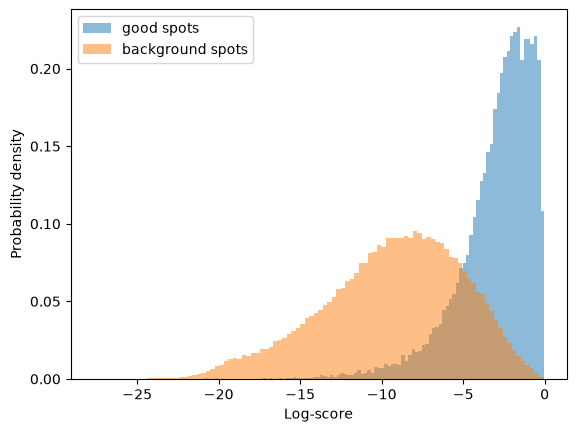

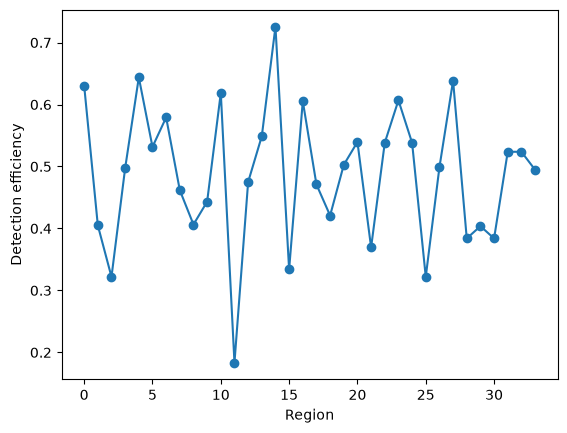

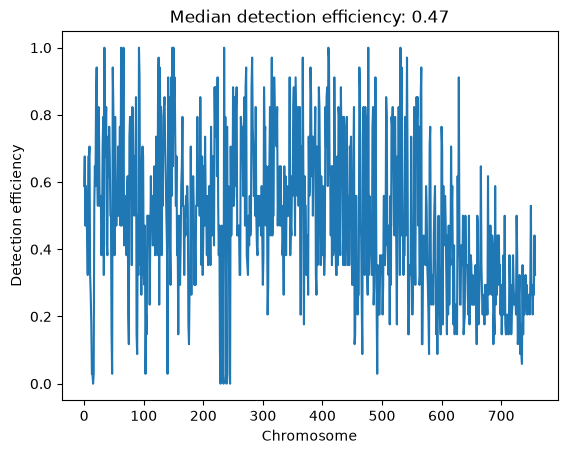

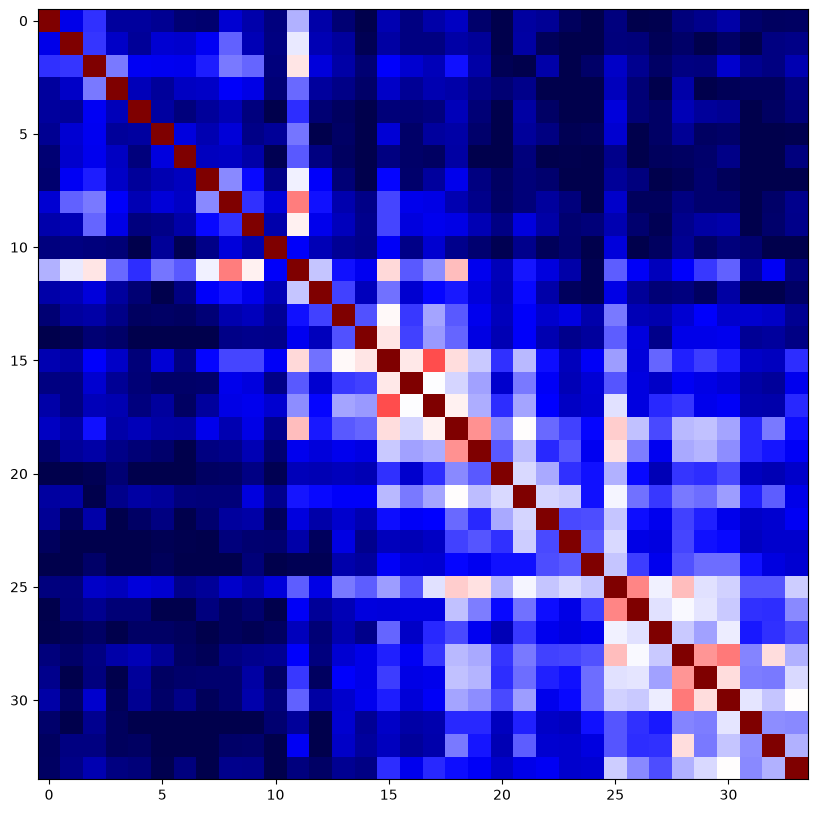

 37%|███▋      | 45/121 [49:49<1:18:17, 61.82s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__044--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__045--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__045--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.28it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(30695), np.int64(4498)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__045--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__045--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1317/1317 [00:05<00:00, 257.14it/s]


fraction the same: 0.9455312876859172
fraction nan: 0.04868462191254634
EM iteration number:  4



100%|██████████| 1317/1317 [00:05<00:00, 259.29it/s]


fraction the same: 0.9761490017419269
fraction nan: 0.04868462191254634


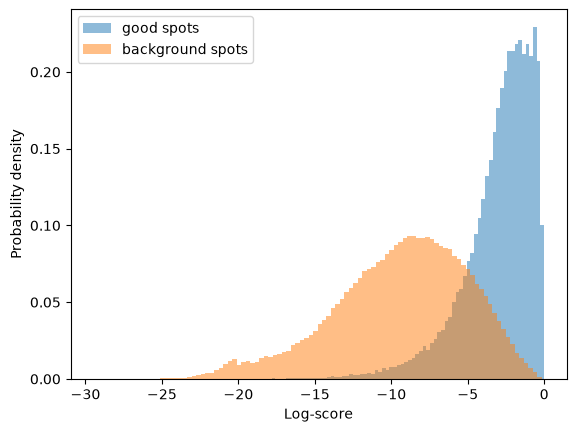

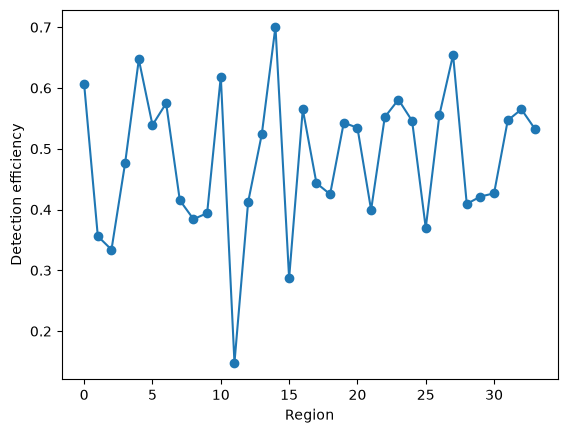

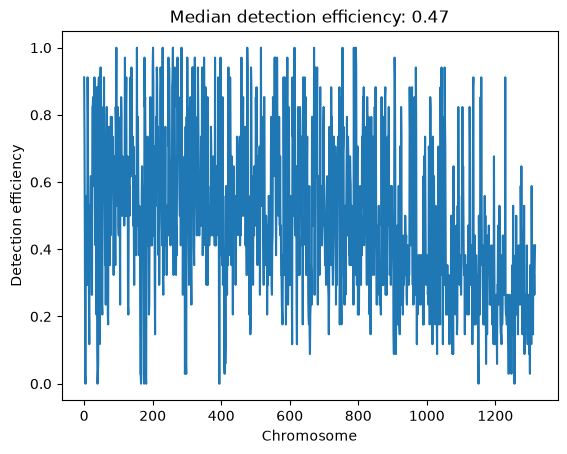

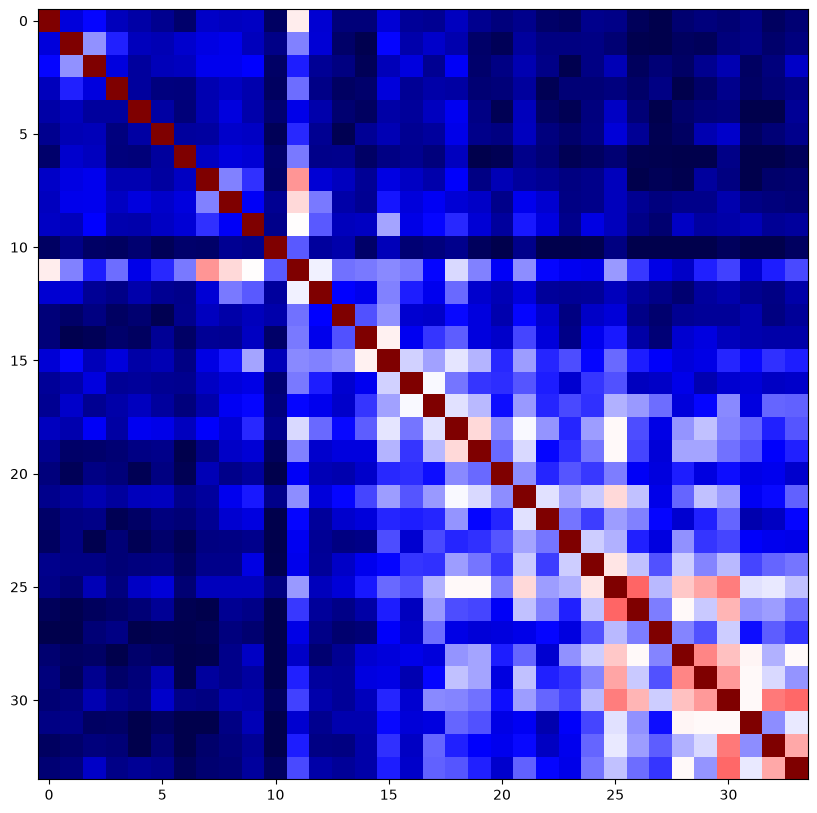

 38%|███▊      | 46/121 [51:30<1:31:49, 73.46s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__045--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__046--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__046--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.30it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28533), np.int64(2462)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__046--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__046--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1726/1726 [00:06<00:00, 279.79it/s]


fraction the same: 0.9445504737236725
fraction nan: 0.1354883784336446
EM iteration number:  4



100%|██████████| 1726/1726 [00:06<00:00, 269.51it/s]


fraction the same: 0.9761945334333038
fraction nan: 0.1354883784336446


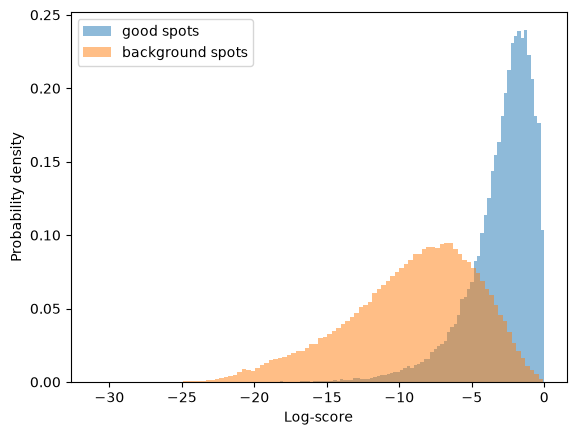

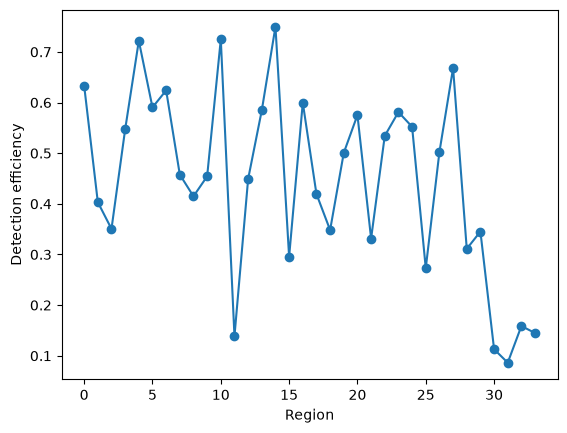

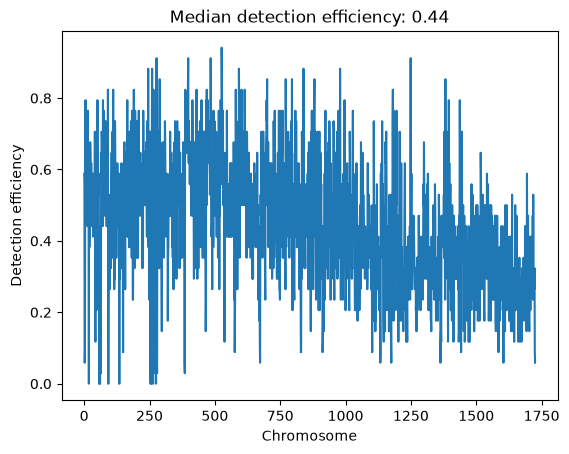

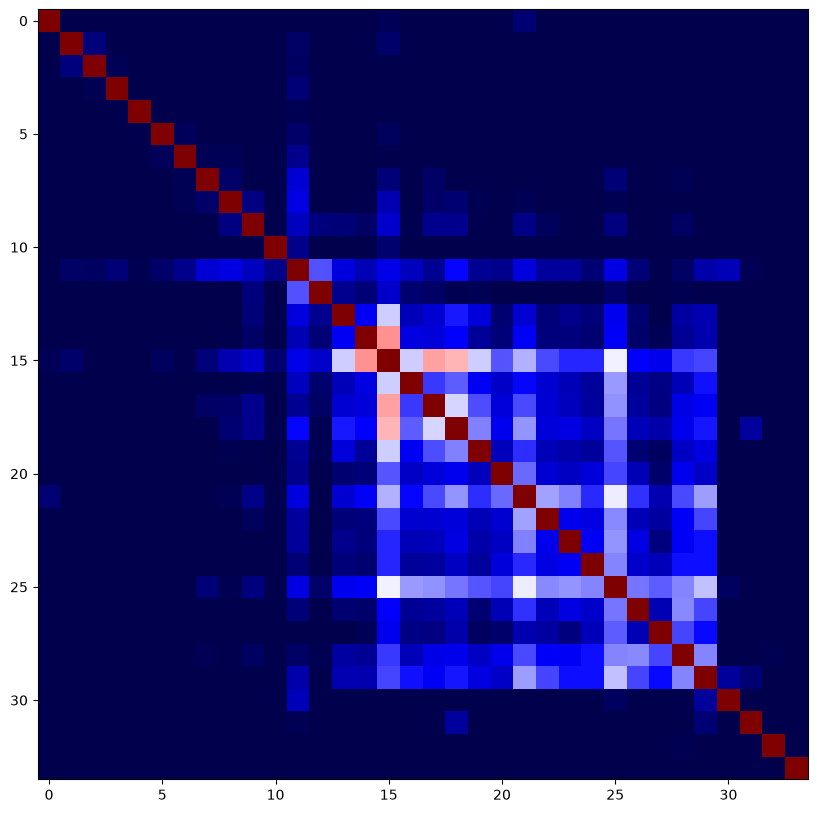

 39%|███▉      | 47/121 [53:25<1:46:02, 85.98s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__046--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__047--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__047--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:34,  1.20it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(30839), np.int64(3172)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__047--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__047--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1300/1300 [00:04<00:00, 260.99it/s]


fraction the same: 0.9497511312217195
fraction nan: 0.05239819004524887
EM iteration number:  4



100%|██████████| 1300/1300 [00:04<00:00, 261.04it/s]


fraction the same: 0.9779638009049774
fraction nan: 0.05239819004524887


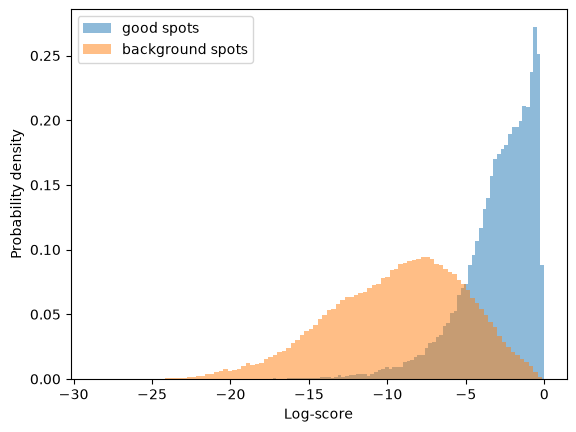

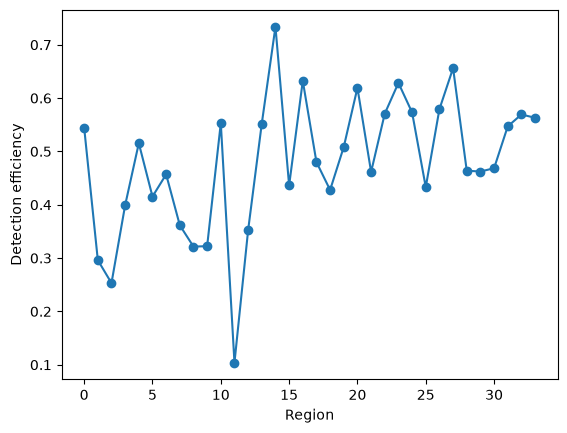

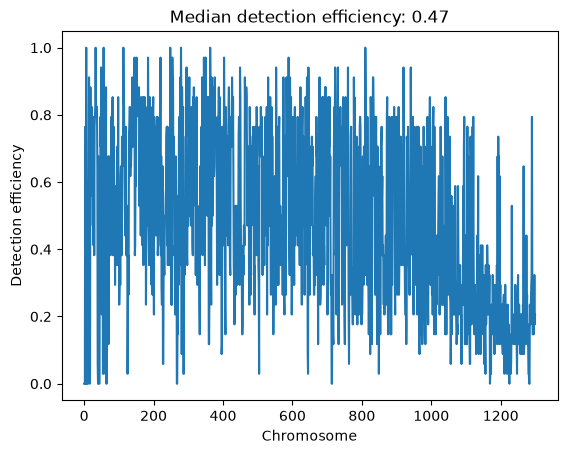

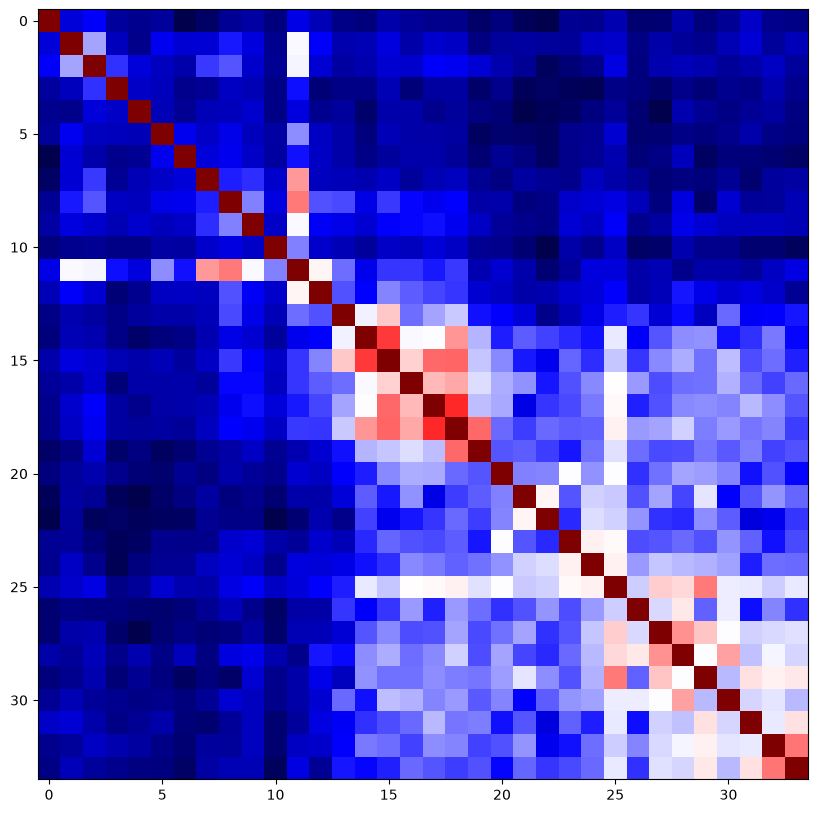

 40%|███▉      | 48/121 [55:02<1:48:42, 89.35s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__047--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__048--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__048--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.28it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(22609), np.int64(6408)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__048--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__048--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 689/689 [00:02<00:00, 272.54it/s]


fraction the same: 0.9470673610518228
fraction nan: 0.06548279689234185
EM iteration number:  4



100%|██████████| 689/689 [00:02<00:00, 273.28it/s]


fraction the same: 0.9761803124733203
fraction nan: 0.06548279689234185


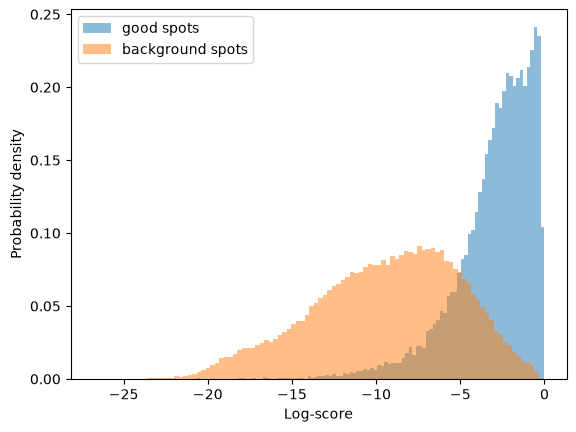

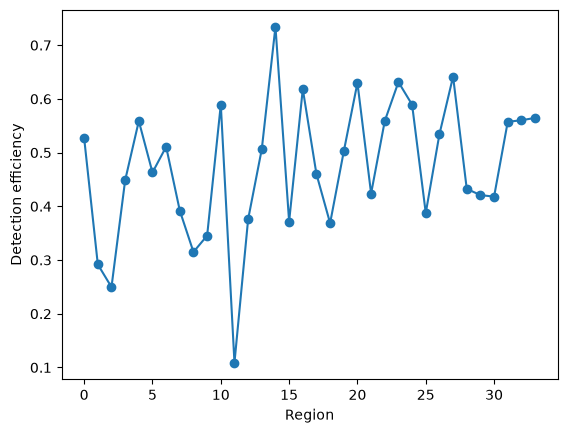

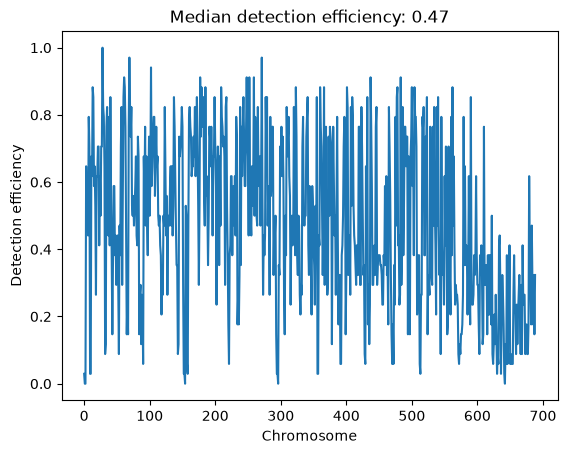

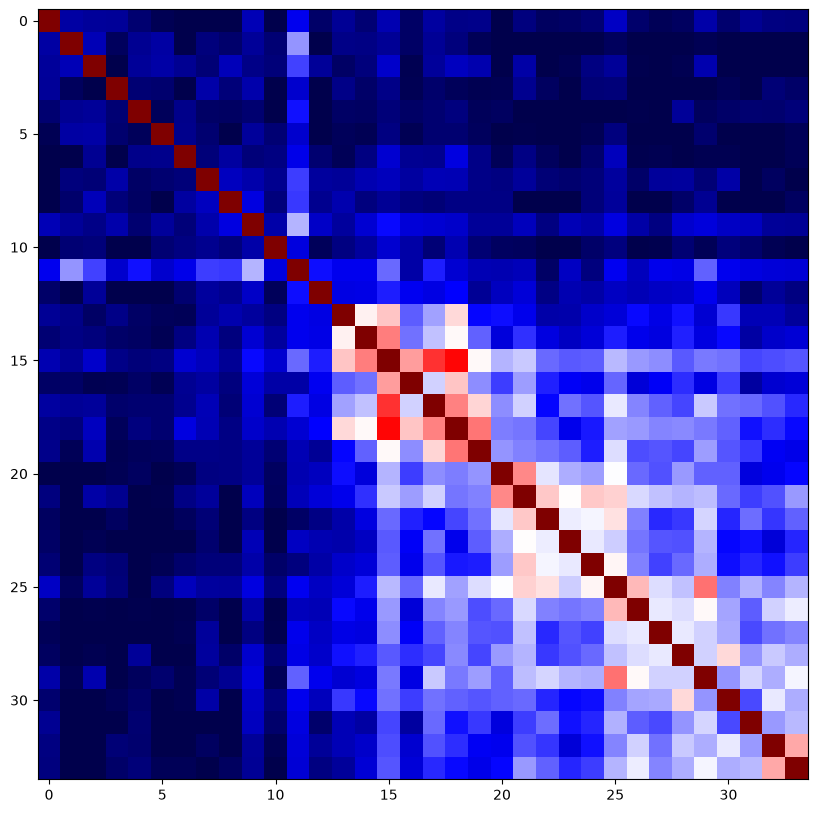

 40%|████      | 49/121 [56:09<1:38:58, 82.48s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__048--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__049--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__049--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.36it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28323), np.int64(3641)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__049--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__049--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1186/1186 [00:04<00:00, 252.48it/s]


fraction the same: 0.9427140164666203
fraction nan: 0.053020533677214564
EM iteration number:  4



100%|██████████| 1186/1186 [00:04<00:00, 251.59it/s]


fraction the same: 0.9750768772939192
fraction nan: 0.053020533677214564


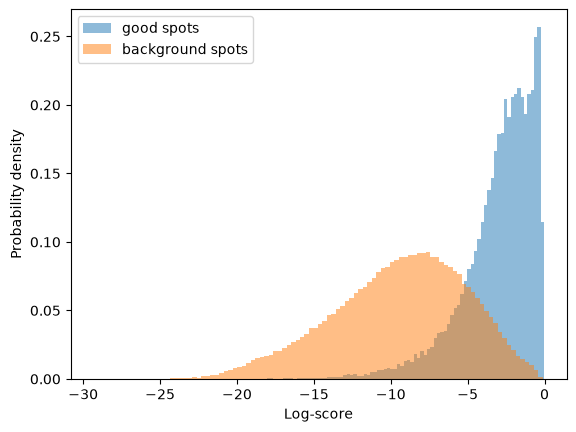

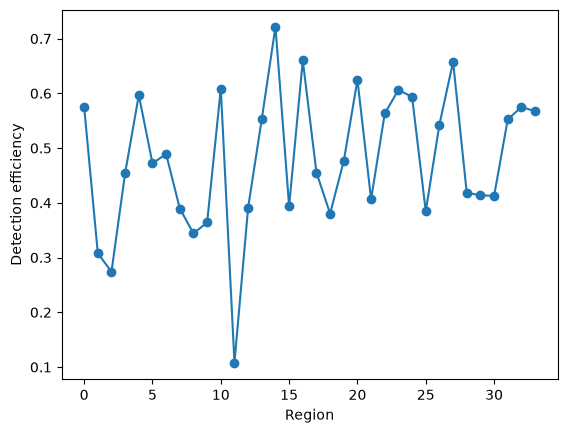

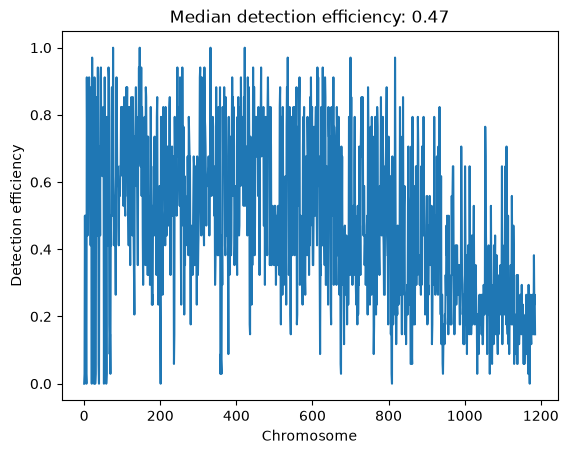

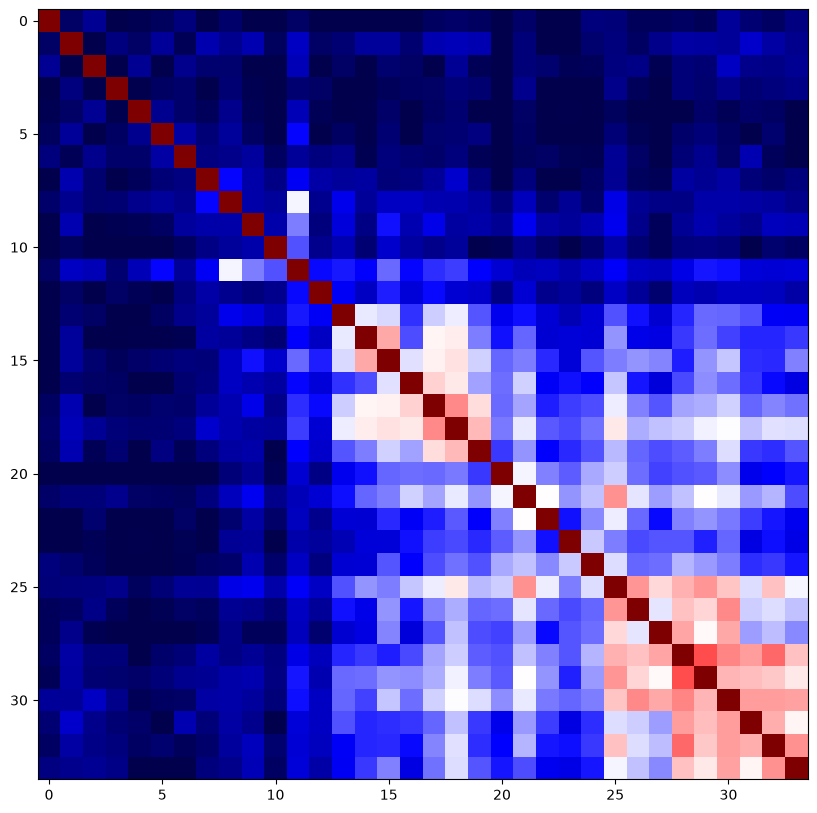

 41%|████▏     | 50/121 [57:40<1:40:46, 85.16s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__049--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__050--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__050--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24582), np.int64(5366)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__050--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__050--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 595/595 [00:02<00:00, 275.07it/s]


fraction the same: 0.9502718734552644
fraction nan: 0.060009886307464164
EM iteration number:  4



100%|██████████| 595/595 [00:02<00:00, 241.83it/s]


fraction the same: 0.9776075135936728
fraction nan: 0.060009886307464164


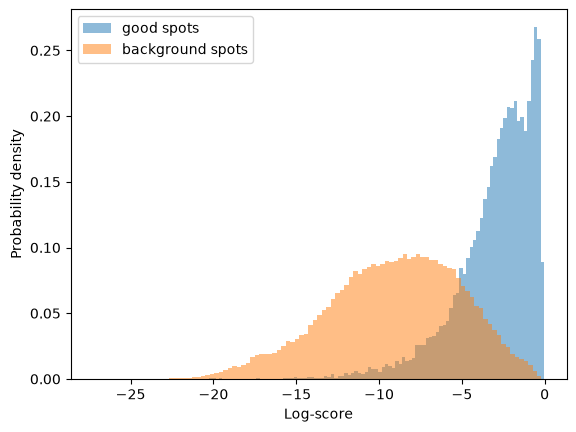

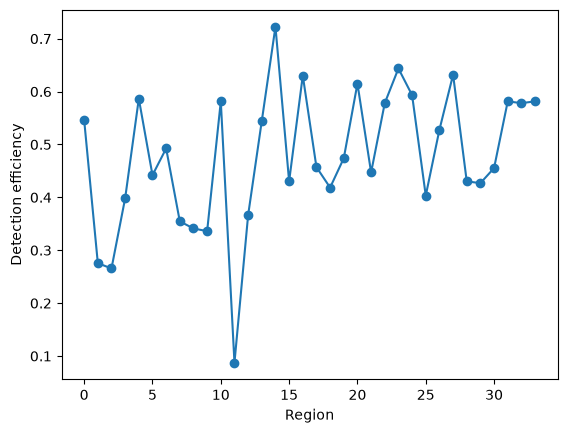

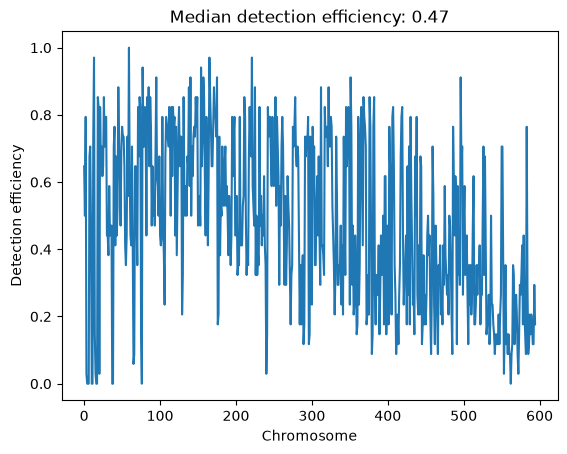

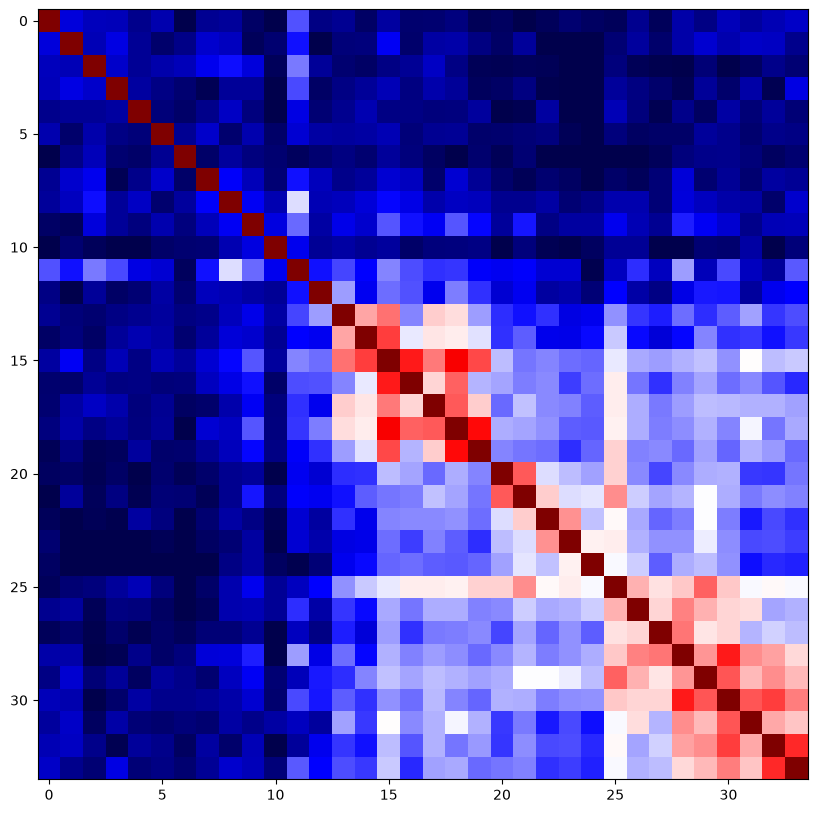

 42%|████▏     | 51/121 [58:40<1:30:32, 77.61s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__050--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__051--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__051--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.33it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(25981), np.int64(4454)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__051--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__051--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 993/993 [00:04<00:00, 248.15it/s]


fraction the same: 0.9477519104318465
fraction nan: 0.04336236004976009
EM iteration number:  4



100%|██████████| 993/993 [00:03<00:00, 248.86it/s]


fraction the same: 0.977222913334518
fraction nan: 0.04336236004976009


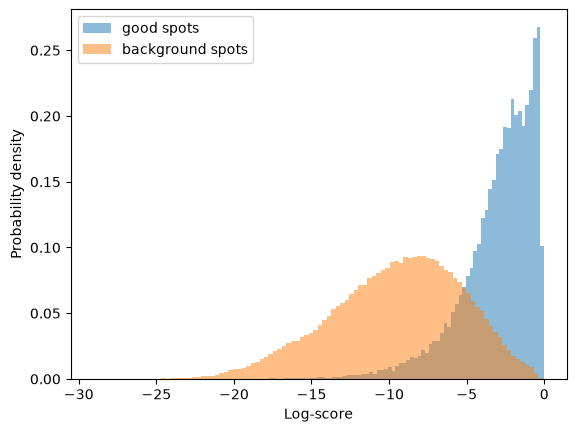

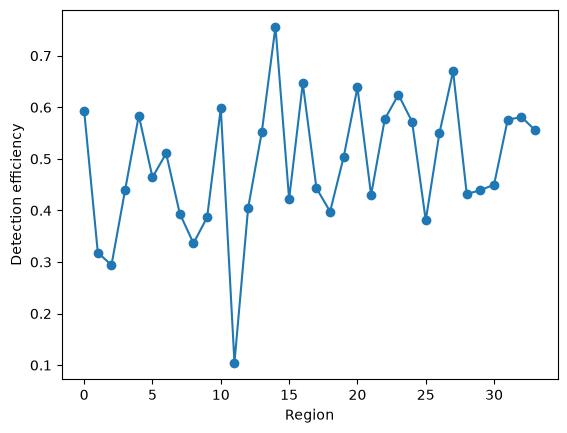

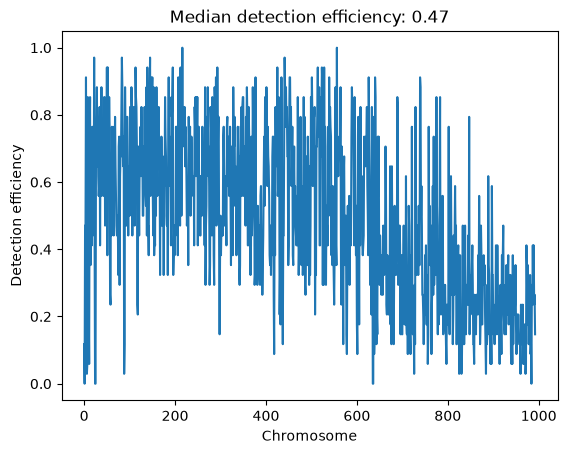

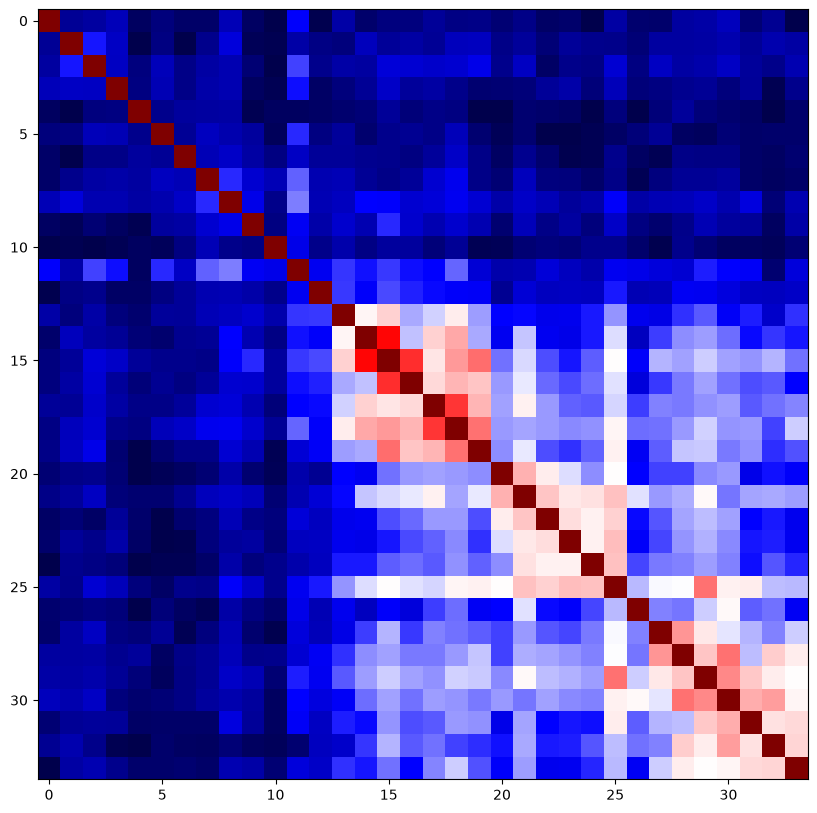

 43%|████▎     | 52/121 [59:58<1:29:16, 77.62s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__051--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__052--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__052--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:33,  1.23it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(26825), np.int64(4139)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__052--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__052--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1121/1121 [00:04<00:00, 257.34it/s]


fraction the same: 0.9474208952091095
fraction nan: 0.0518444666001994
EM iteration number:  4



100%|██████████| 1121/1121 [00:04<00:00, 257.55it/s]


fraction the same: 0.9758356509419112
fraction nan: 0.0518444666001994


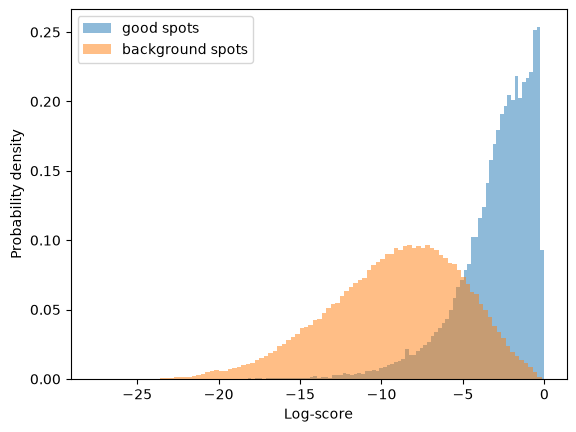

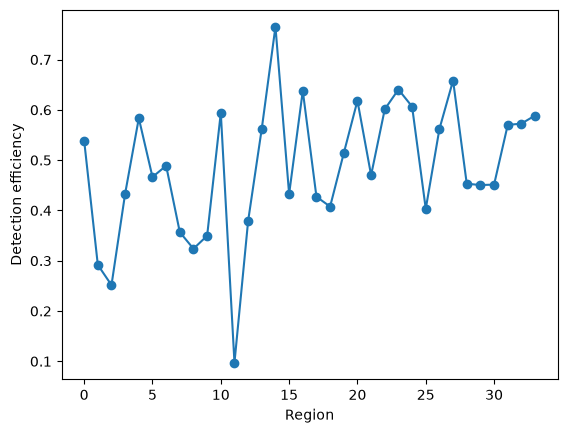

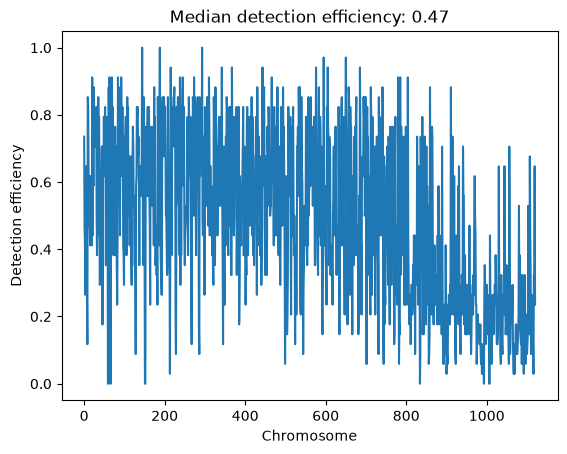

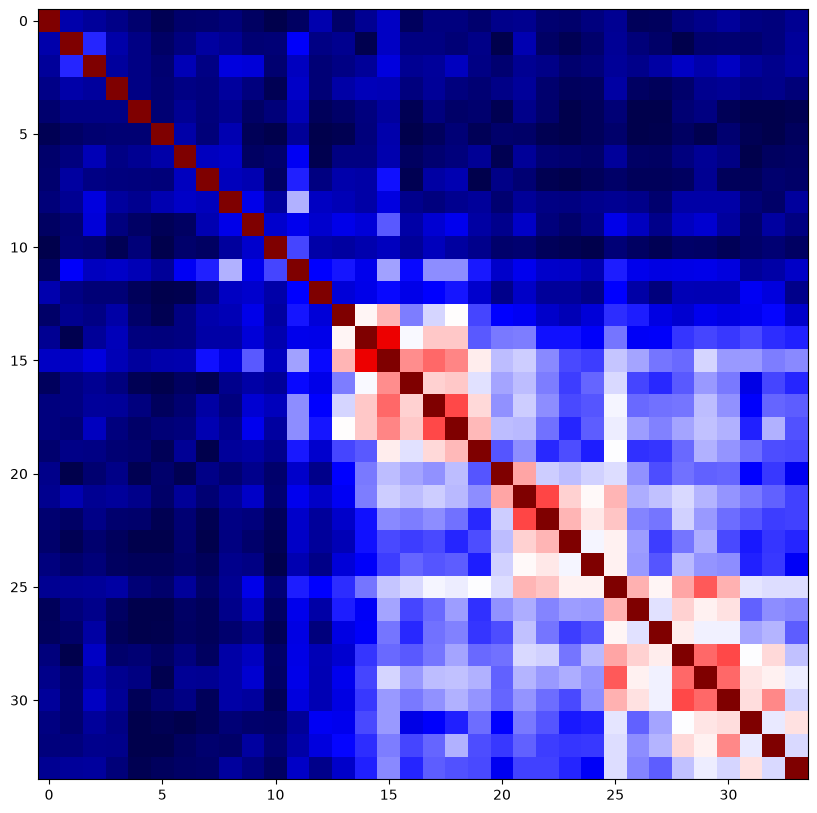

 44%|████▍     | 53/121 [1:01:23<1:30:39, 79.99s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__052--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__053--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__053--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.38it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(21477), np.int64(4687)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__053--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__053--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 464/464 [00:01<00:00, 311.52it/s]


fraction the same: 0.9544244421906694
fraction nan: 0.07917089249492901
EM iteration number:  4



100%|██████████| 464/464 [00:01<00:00, 312.00it/s]


fraction the same: 0.9809837728194726
fraction nan: 0.07917089249492901


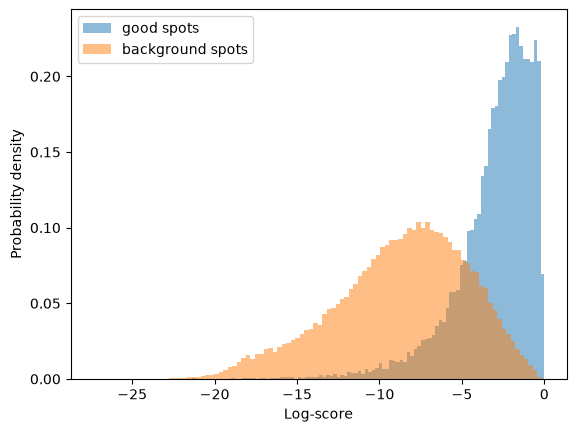

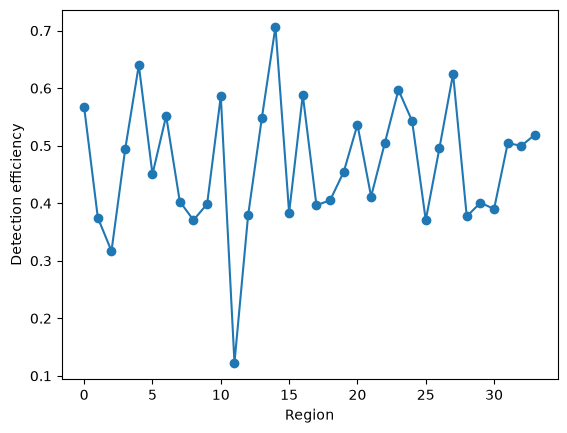

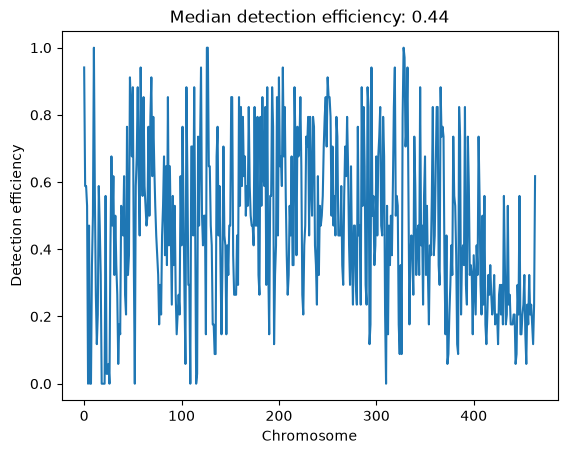

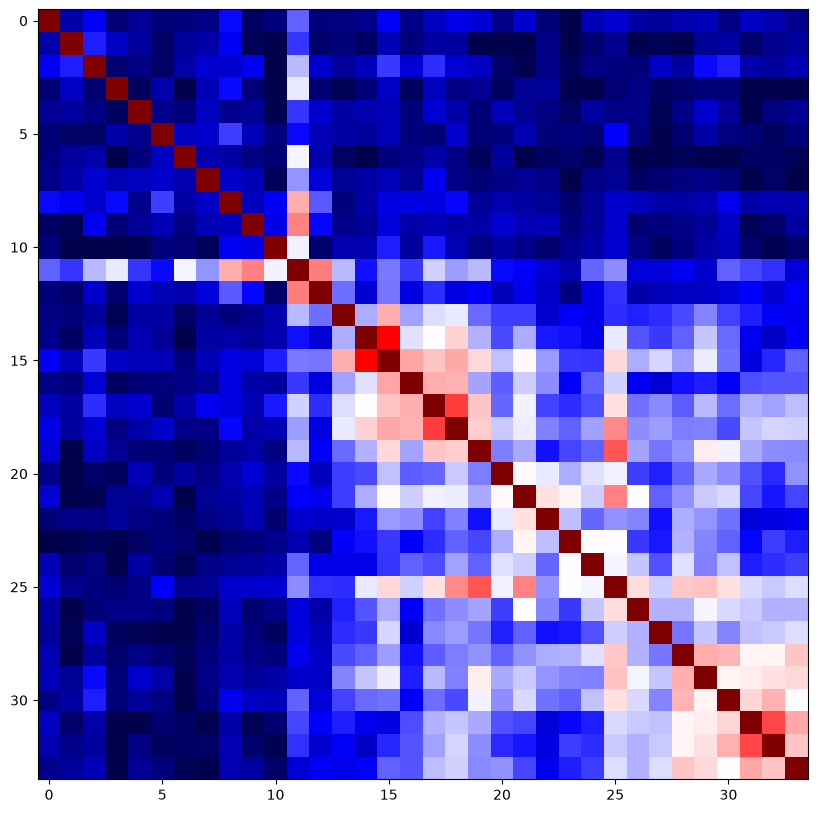

 45%|████▍     | 54/121 [1:02:18<1:20:43, 72.30s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__053--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__054--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__054--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.31it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19749), np.int64(6666)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__054--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__054--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 308/308 [00:01<00:00, 264.65it/s]


fraction the same: 0.9442322383498855
fraction nan: 0.038579067990832695
EM iteration number:  4



100%|██████████| 308/308 [00:01<00:00, 266.12it/s]


fraction the same: 0.9751718869365928
fraction nan: 0.038579067990832695


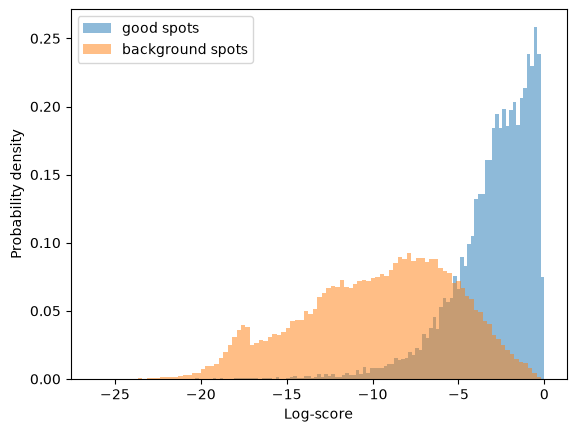

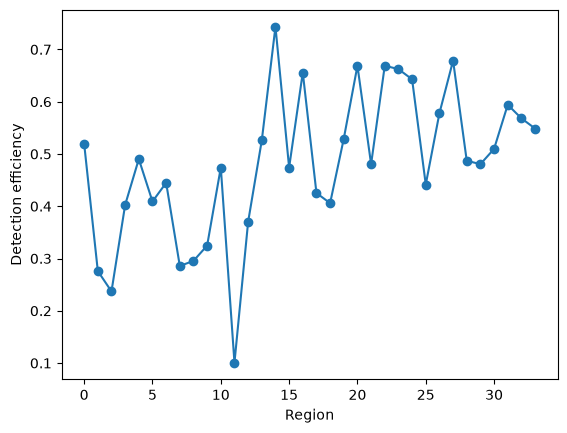

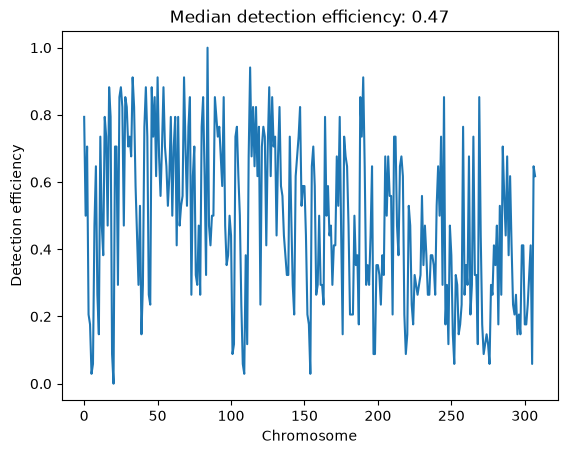

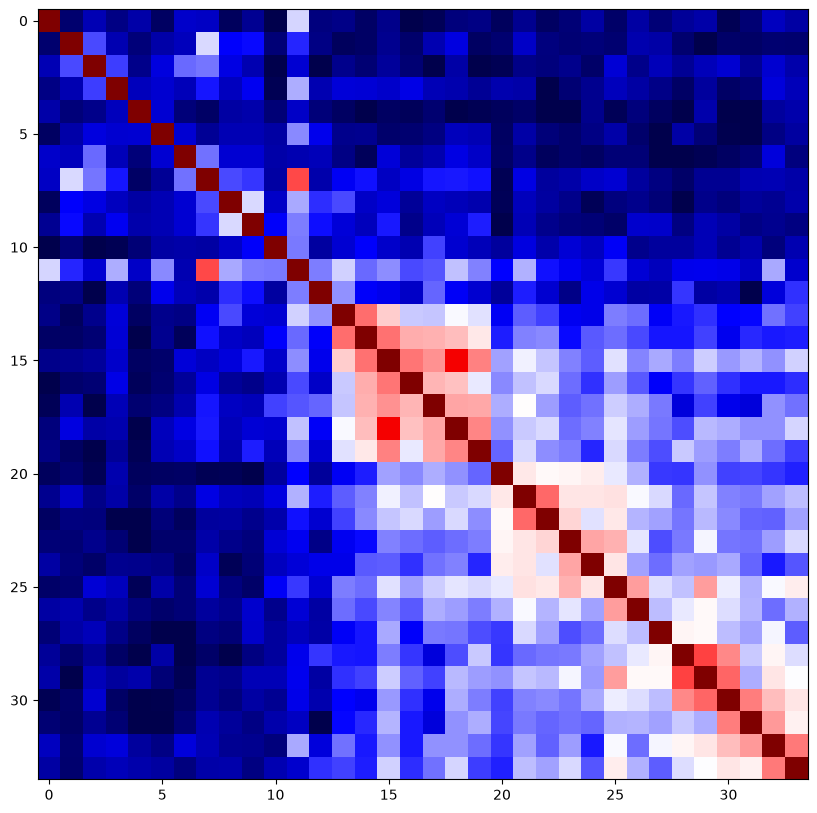

 45%|████▌     | 55/121 [1:03:08<1:12:18, 65.73s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__054--__XHfs_finedrft_save.npz


 46%|████▋     | 56/121 [1:03:10<50:38, 46.75s/it]  

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__055--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__056--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__056--H10_NC_set1--dapiFeatures.npz


... (94 outputs left out)


100%|██████████| 680/680 [00:02<00:00, 253.93it/s]


fraction the same: 0.9475778546712803
fraction nan: 0.039965397923875434
EM iteration number:  4



100%|██████████| 680/680 [00:02<00:00, 255.50it/s]


fraction the same: 0.9763840830449827
fraction nan: 0.039965397923875434


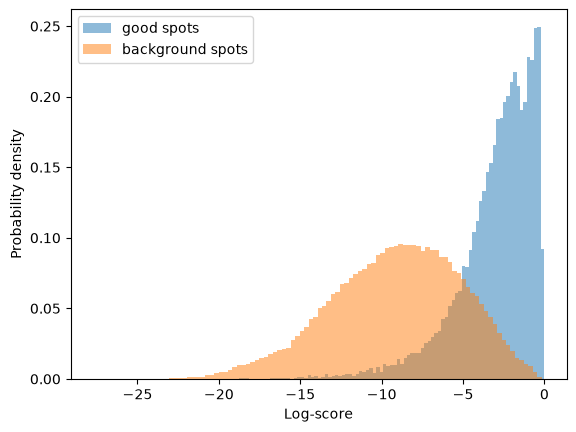

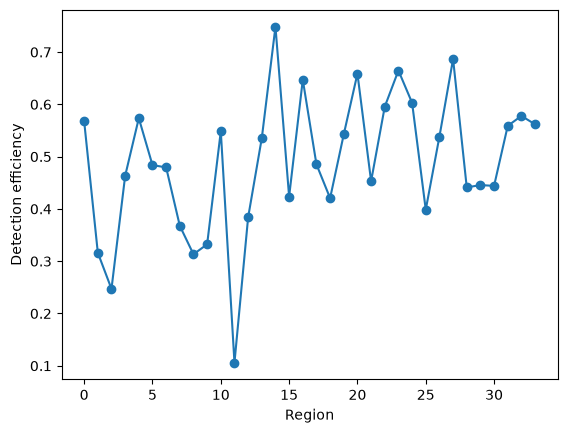

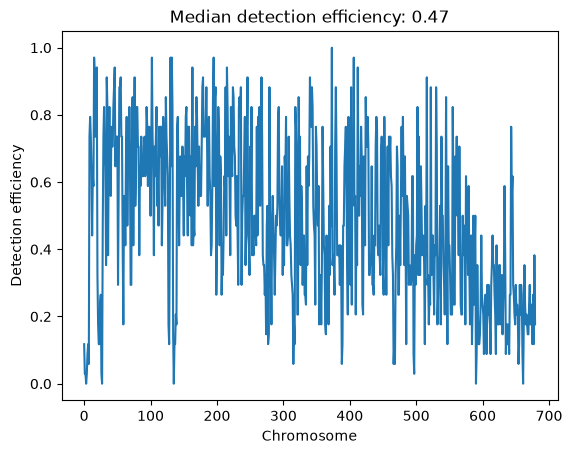

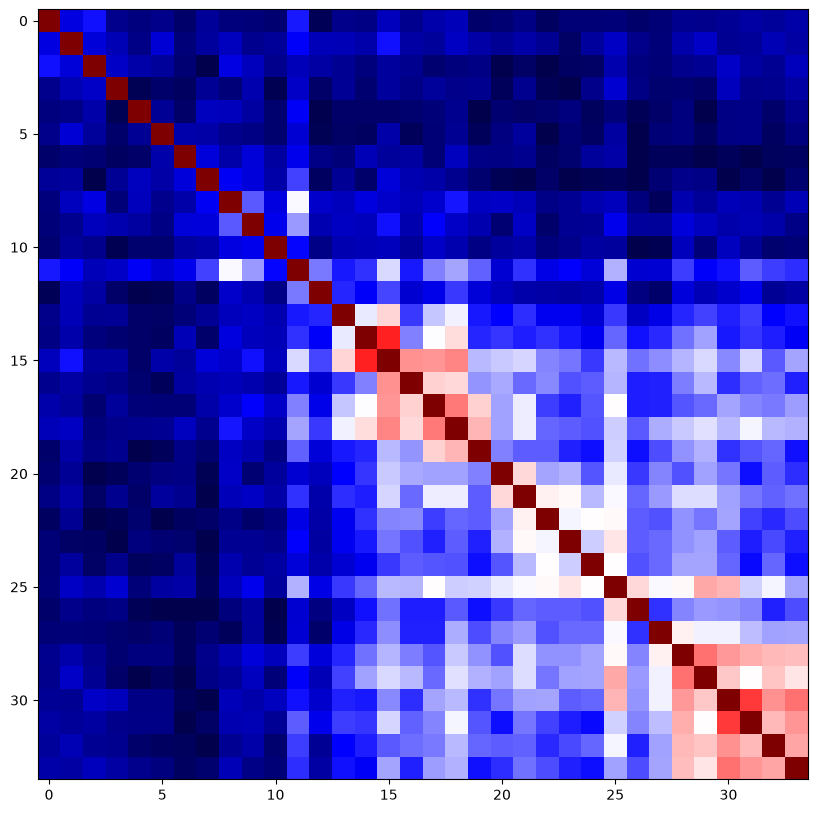

 47%|████▋     | 57/121 [1:04:19<56:54, 53.35s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__056--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__057--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__057--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.45it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(17126), np.int64(1395)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__057--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__057--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 937/937 [00:03<00:00, 308.33it/s]


fraction the same: 0.9562747190658547
fraction nan: 0.20446983489233472
EM iteration number:  4



100%|██████████| 937/937 [00:03<00:00, 307.94it/s]


fraction the same: 0.9804758616360097
fraction nan: 0.20446983489233472


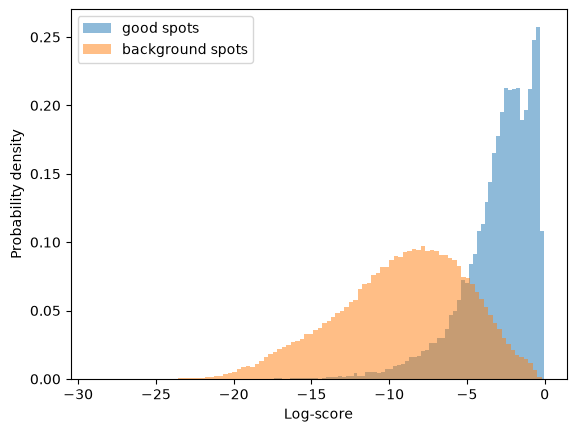

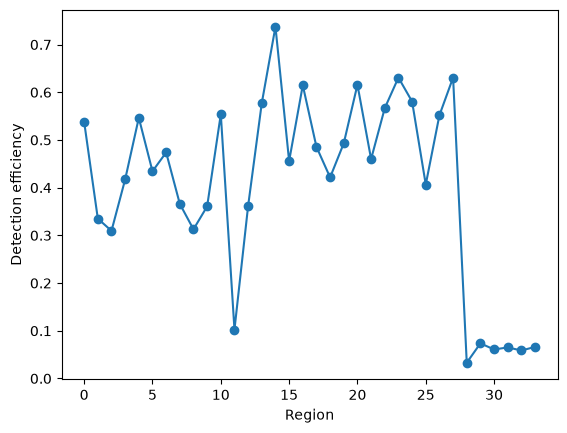

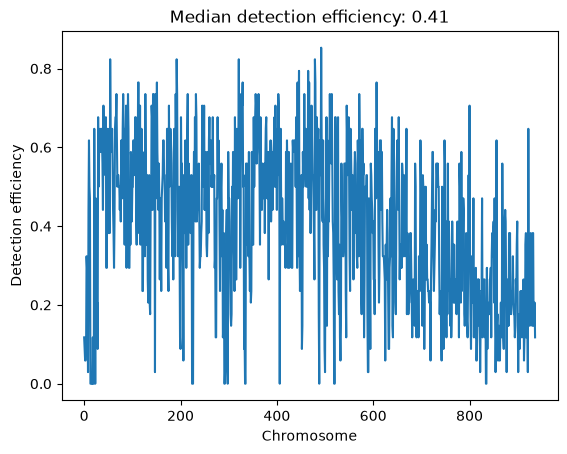

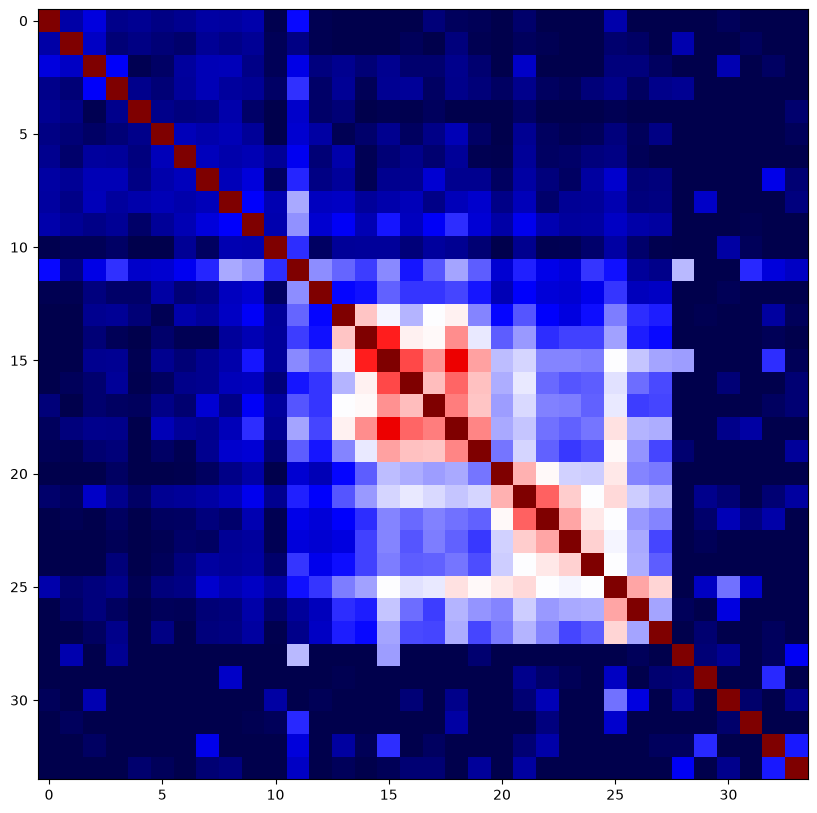

 48%|████▊     | 58/121 [1:05:36<1:03:32, 60.52s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__057--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__058--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__058--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:34,  1.18it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24997), np.int64(4690)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__058--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__058--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 812/812 [00:02<00:00, 283.50it/s]


fraction the same: 0.9516444508838018
fraction nan: 0.09048101999420458
EM iteration number:  4



100%|██████████| 812/812 [00:02<00:00, 283.13it/s]


fraction the same: 0.9784844972471747
fraction nan: 0.09048101999420458


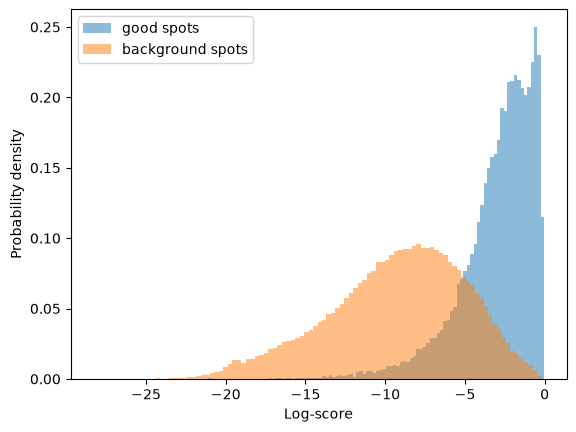

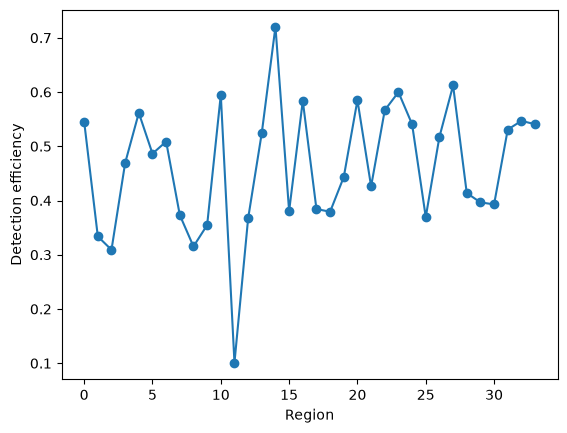

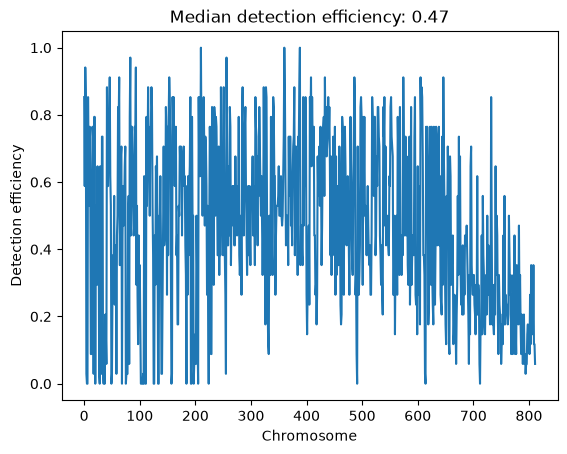

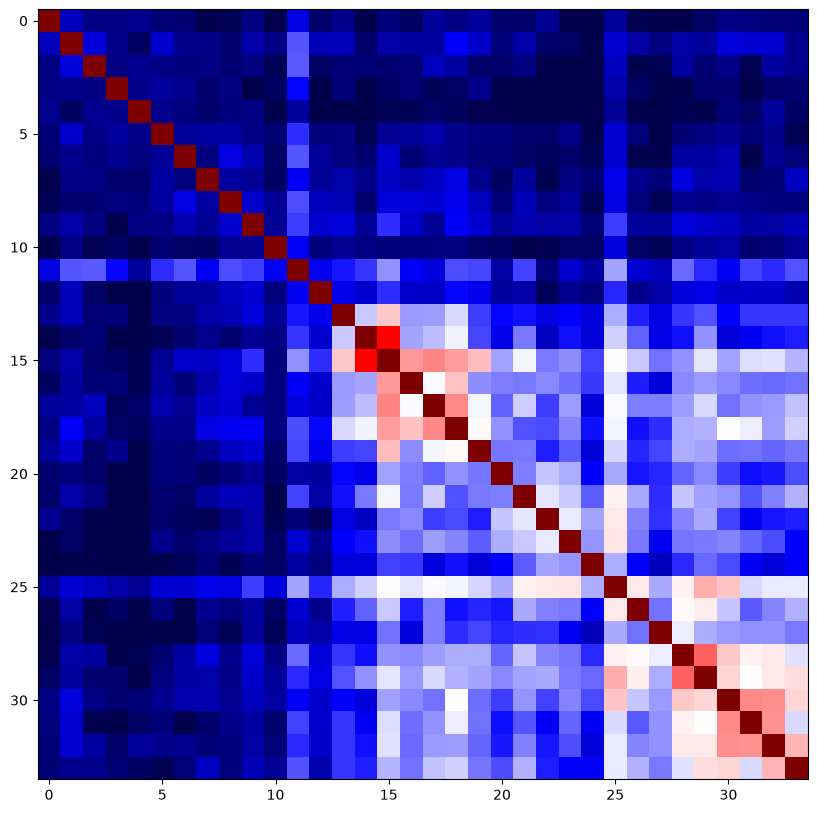

 49%|████▉     | 59/121 [1:06:46<1:05:18, 63.20s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__058--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__059--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__059--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.27it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24167), np.int64(4880)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__059--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__059--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 998/998 [00:03<00:00, 283.27it/s]


fraction the same: 0.9542909348107981
fraction nan: 0.0730873511729341
EM iteration number:  4



100%|██████████| 998/998 [00:03<00:00, 283.56it/s]


fraction the same: 0.9794883885417894
fraction nan: 0.0730873511729341


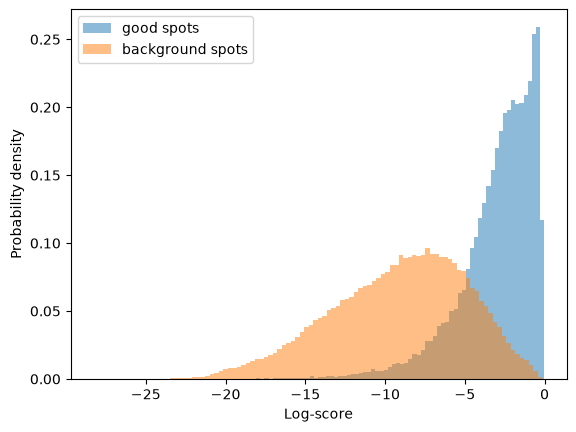

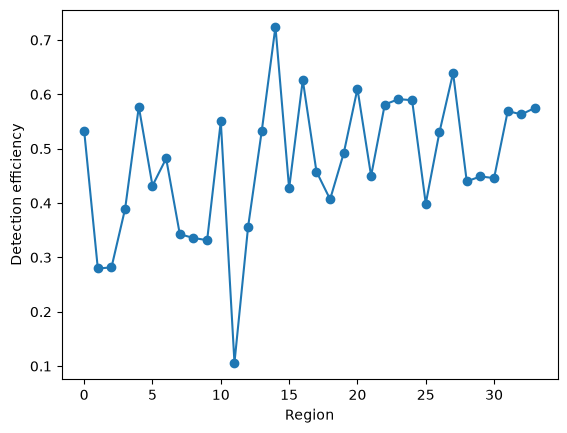

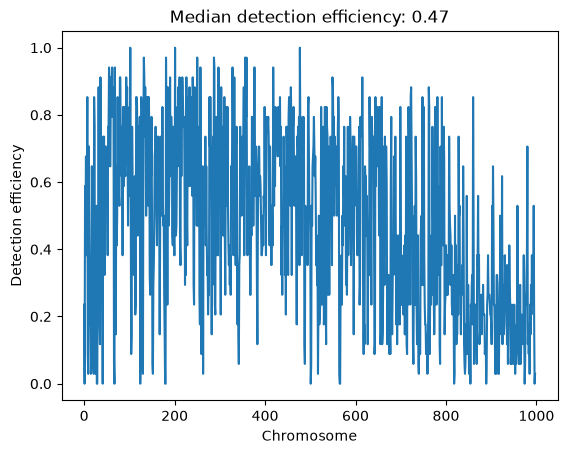

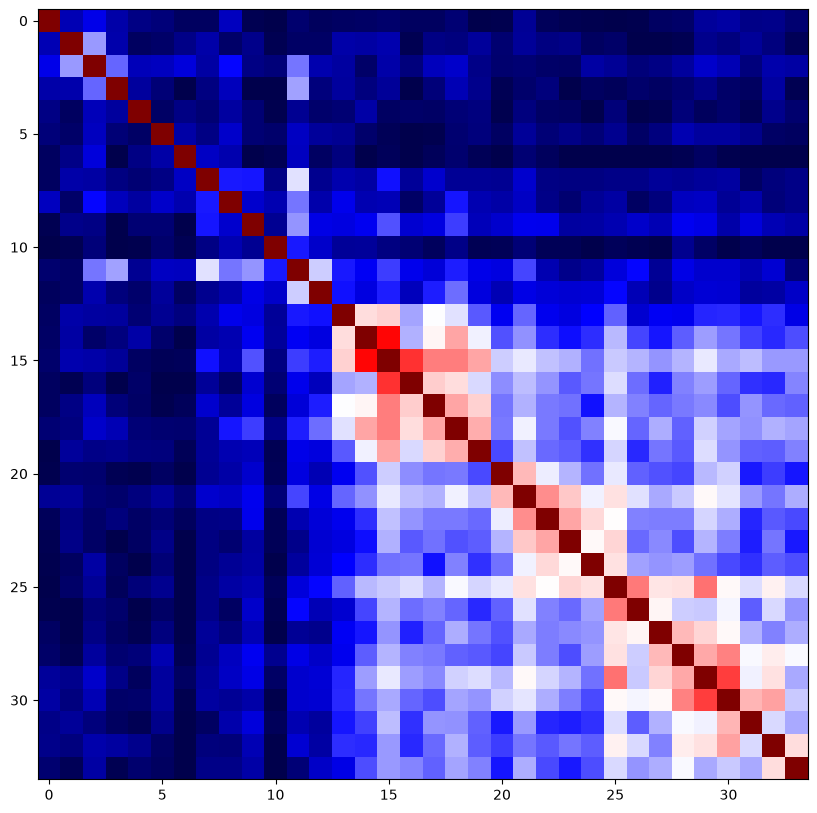

 50%|████▉     | 60/121 [1:08:00<1:07:35, 66.49s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__059--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__060--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__060--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(8785), np.int64(2045)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__060--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__060--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 355/355 [00:01<00:00, 306.36it/s]


fraction the same: 0.9513670256835128
fraction nan: 0.06495443247721625
EM iteration number:  4



100%|██████████| 355/355 [00:01<00:00, 301.62it/s]


fraction the same: 0.980115990057995
fraction nan: 0.06495443247721625


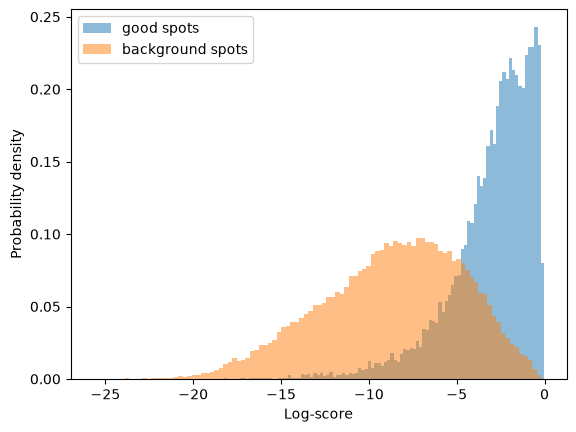

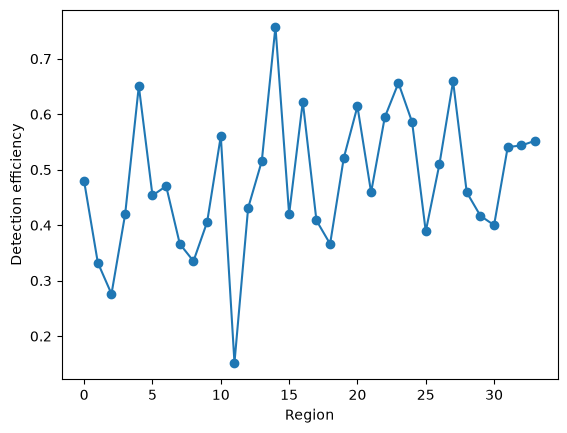

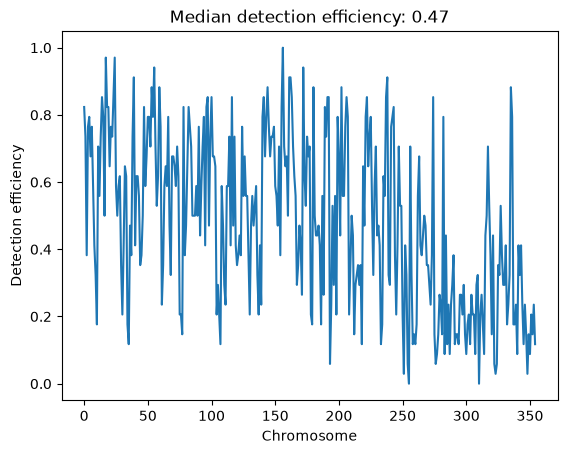

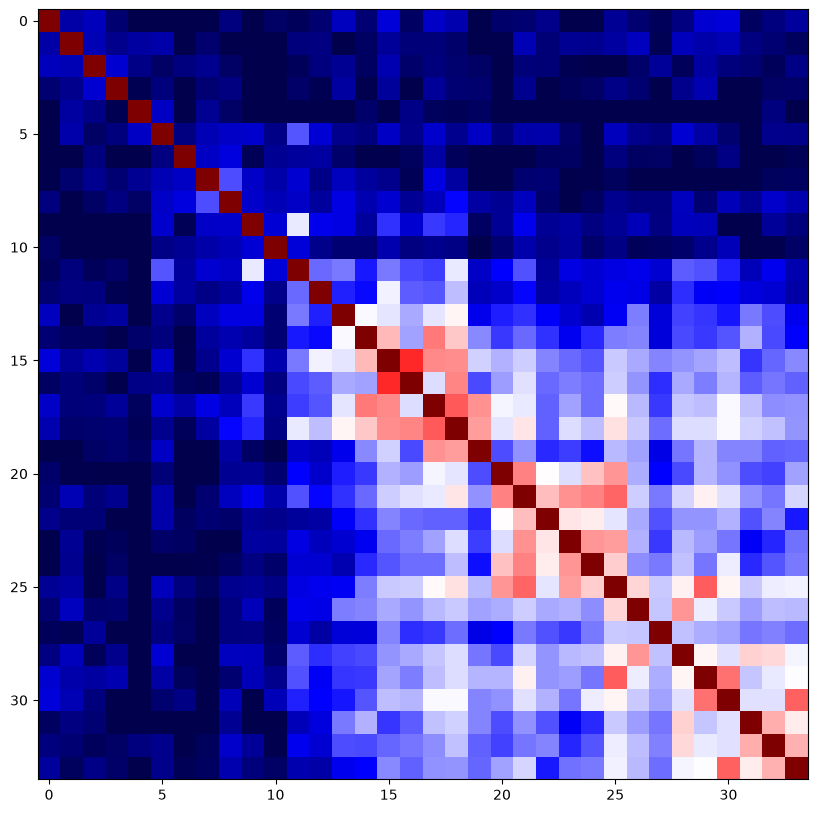

 50%|█████     | 61/121 [1:08:46<1:00:14, 60.24s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__060--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__061--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__061--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:18,  2.27it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(4446), np.int64(3866)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__061--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__061--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1237/1237 [00:03<00:00, 344.66it/s]


fraction the same: 0.9628845879499739
fraction nan: 0.2766655570878311
EM iteration number:  4



100%|██████████| 1237/1237 [00:03<00:00, 346.16it/s]


fraction the same: 0.9828332303010129
fraction nan: 0.2766655570878311


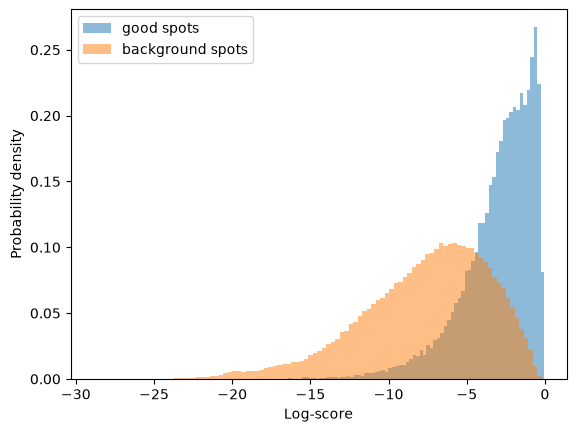

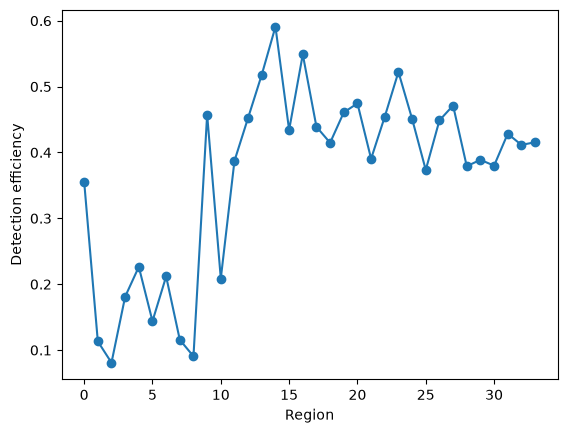

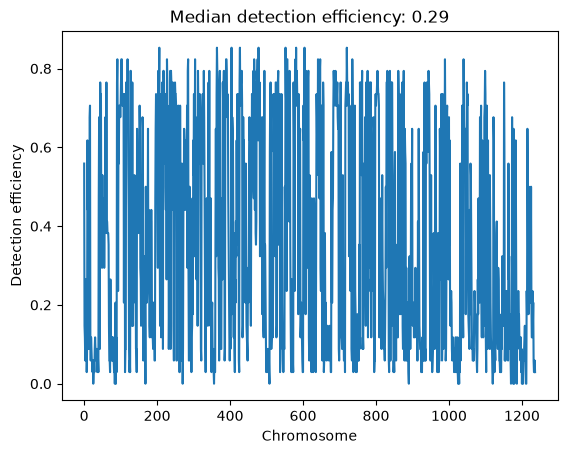

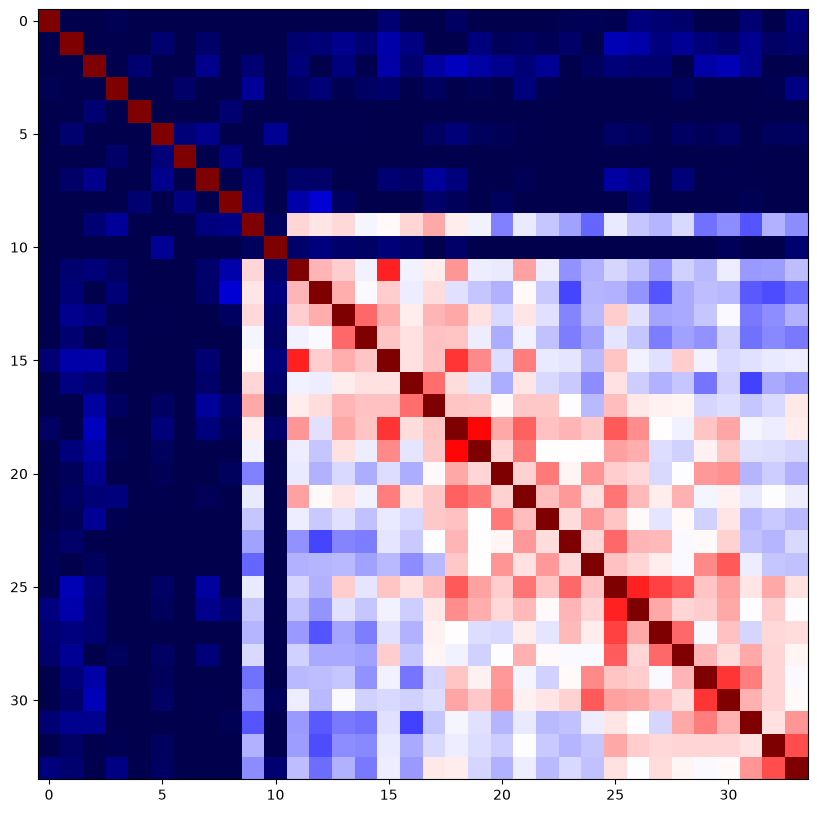

 51%|█████     | 62/121 [1:10:15<1:07:55, 69.07s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__061--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__062--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__062--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:23,  1.73it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(14751), np.int64(679)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__062--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__062--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1202/1202 [00:04<00:00, 269.26it/s]


fraction the same: 0.9520162474307526
fraction nan: 0.0640109621219536
EM iteration number:  4



100%|██████████| 1202/1202 [00:04<00:00, 269.47it/s]


fraction the same: 0.9792502691592444
fraction nan: 0.0640109621219536


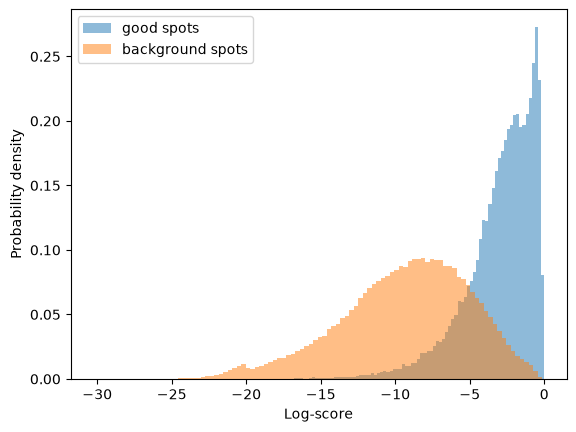

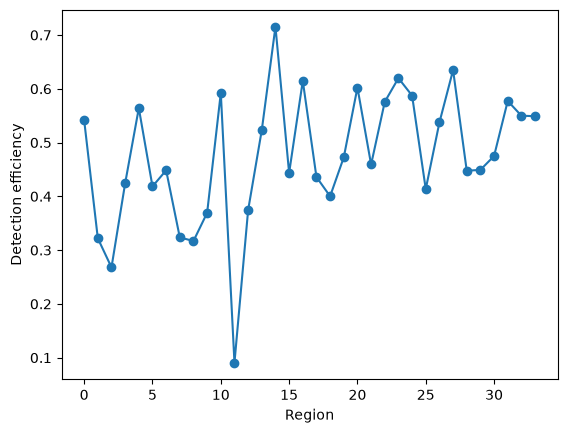

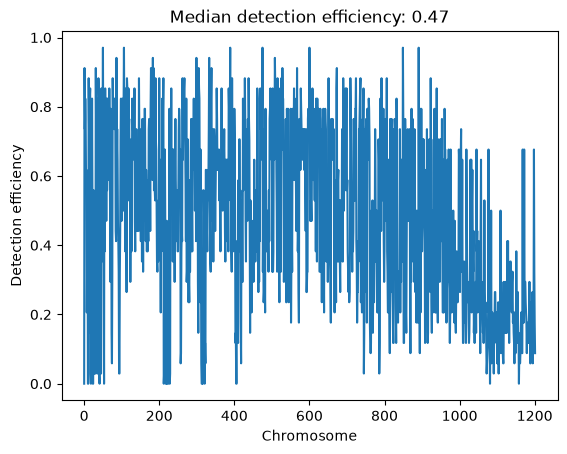

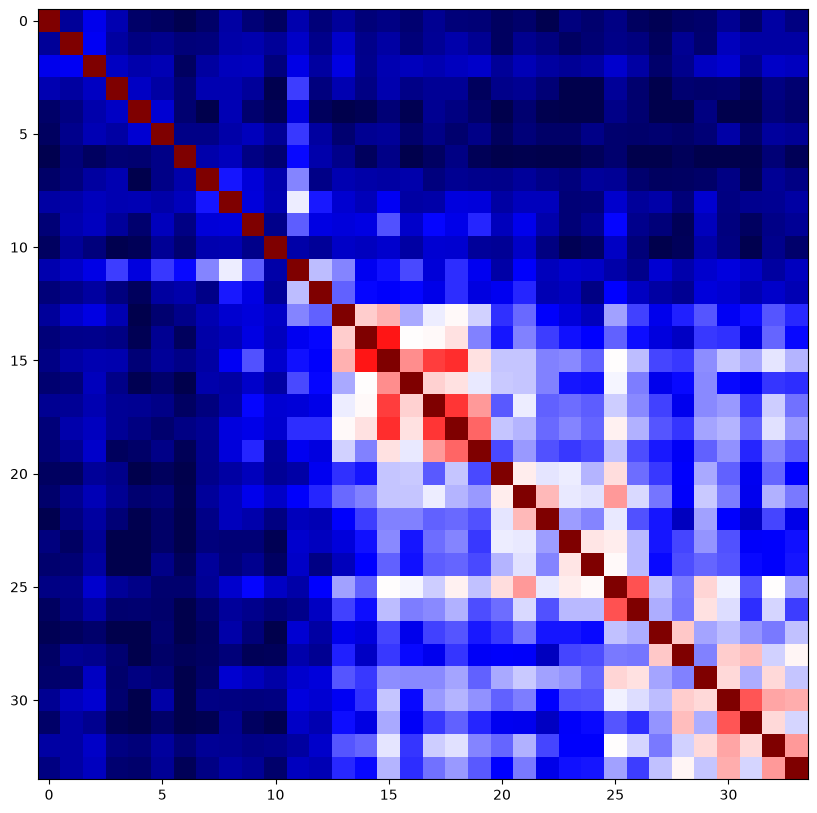

 52%|█████▏    | 63/121 [1:11:41<1:11:29, 73.95s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__062--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__063--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__063--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.25it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28778), np.int64(3035)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__063--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__063--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1557/1557 [00:06<00:00, 252.90it/s]


fraction the same: 0.9513581926026673
fraction nan: 0.05190978125354188
EM iteration number:  4



100%|██████████| 1557/1557 [00:06<00:00, 243.00it/s]


fraction the same: 0.9783142544108202
fraction nan: 0.05190978125354188


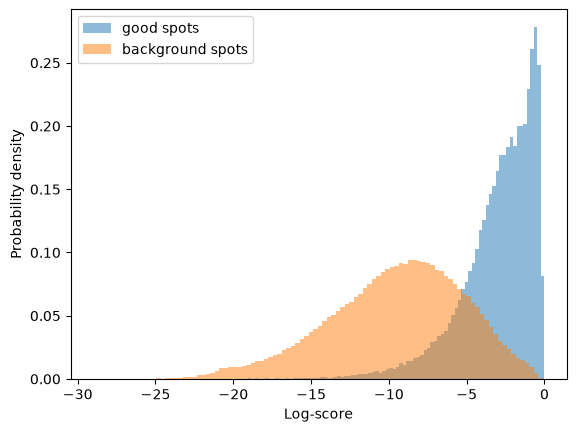

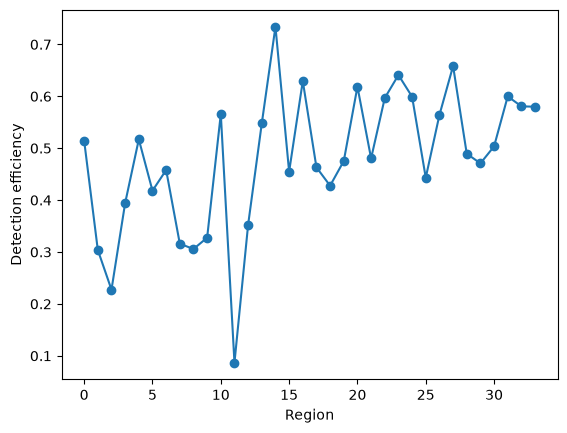

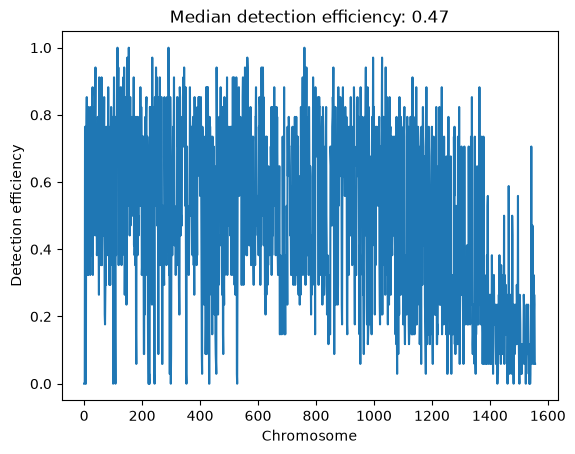

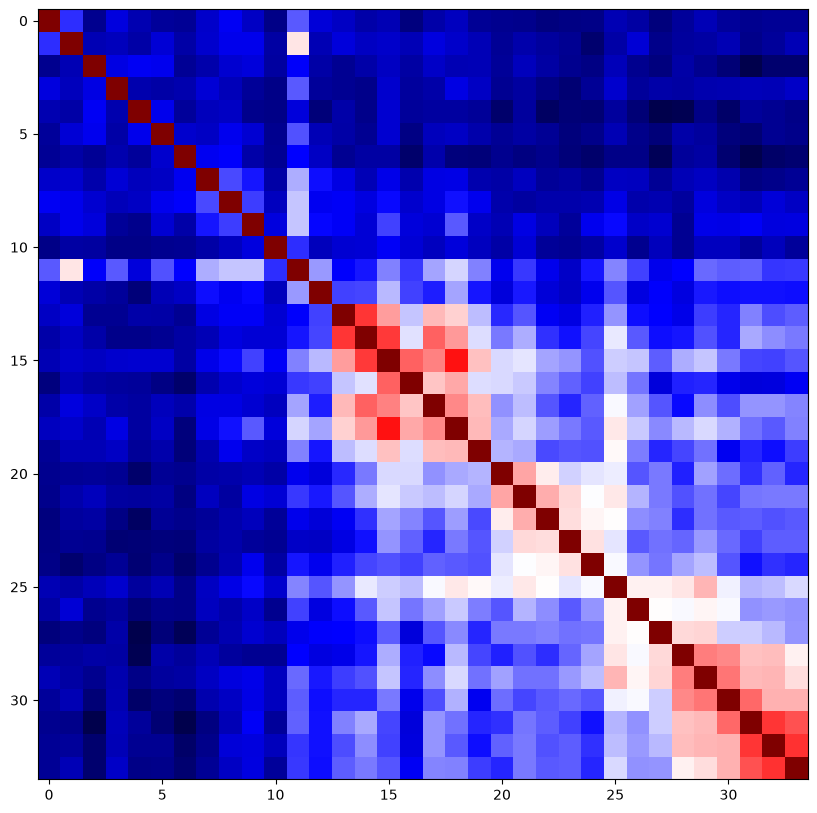

 53%|█████▎    | 64/121 [1:13:35<1:21:52, 86.18s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__063--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__064--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__064--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.25it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(26681), np.int64(3174)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__064--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__064--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1495/1495 [00:06<00:00, 247.78it/s]


fraction the same: 0.9505606925044265
fraction nan: 0.05290182962817234
EM iteration number:  4



100%|██████████| 1495/1495 [00:05<00:00, 260.22it/s]


fraction the same: 0.9785953177257525
fraction nan: 0.05290182962817234


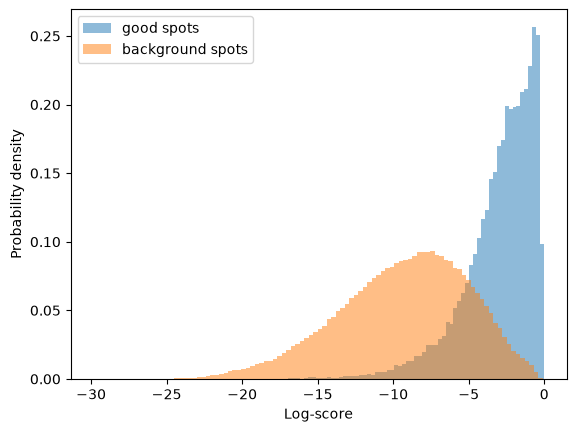

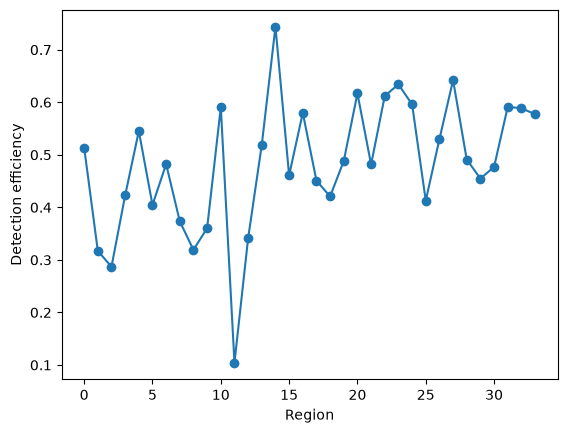

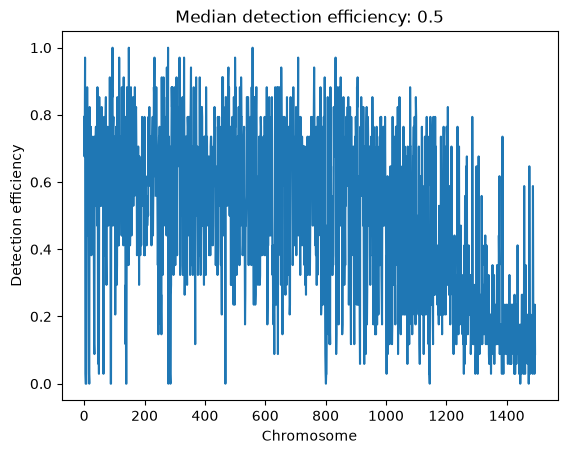

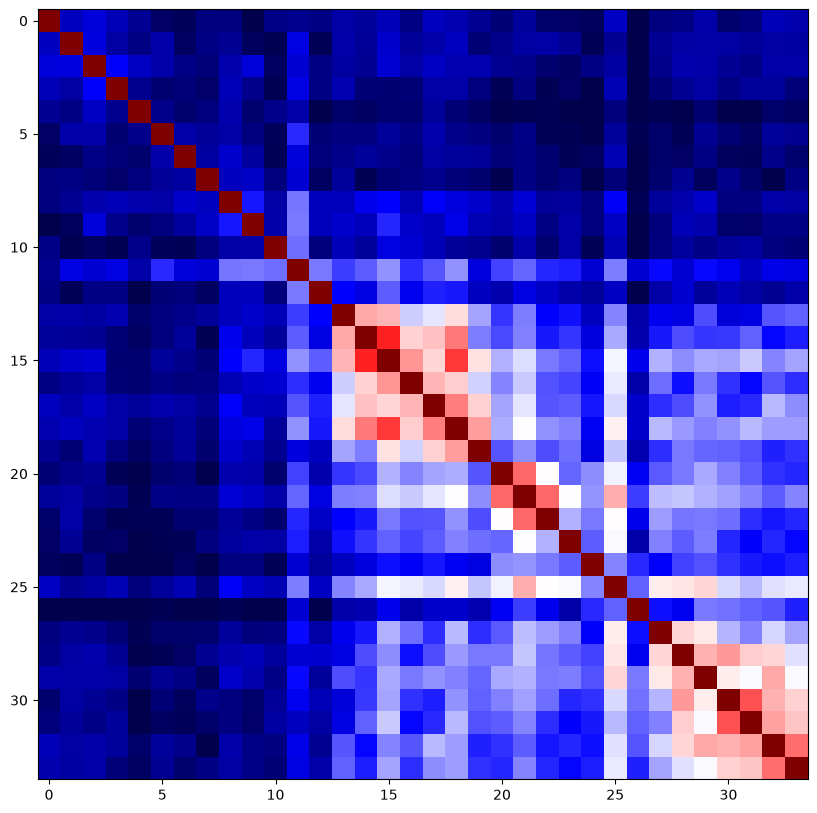

 54%|█████▎    | 65/121 [1:15:18<1:25:03, 91.14s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__064--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__065--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__065--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.31it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(18360), np.int64(5123)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__065--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__065--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 363/363 [00:01<00:00, 356.58it/s]


fraction the same: 0.9545454545454546
fraction nan: 0.10160427807486631
EM iteration number:  4



100%|██████████| 363/363 [00:01<00:00, 356.61it/s]


fraction the same: 0.982498784637822
fraction nan: 0.10160427807486631


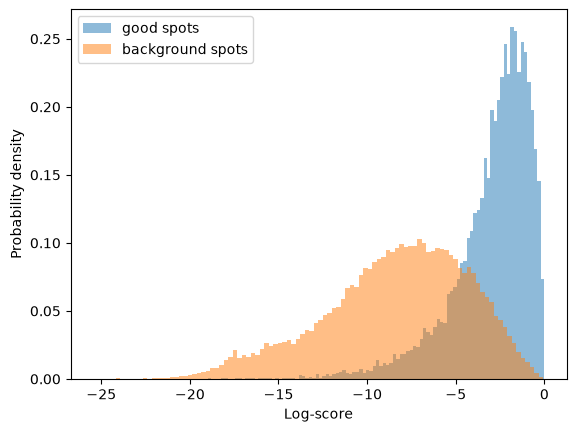

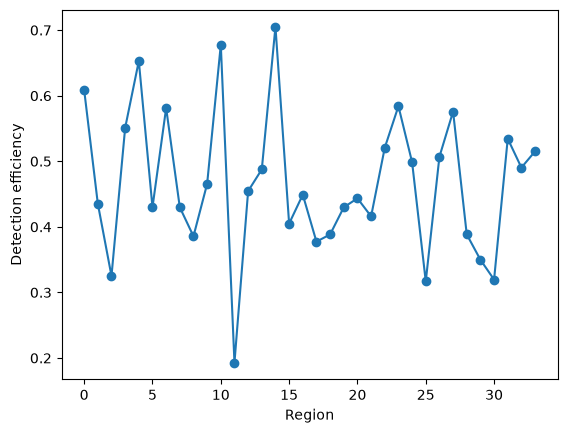

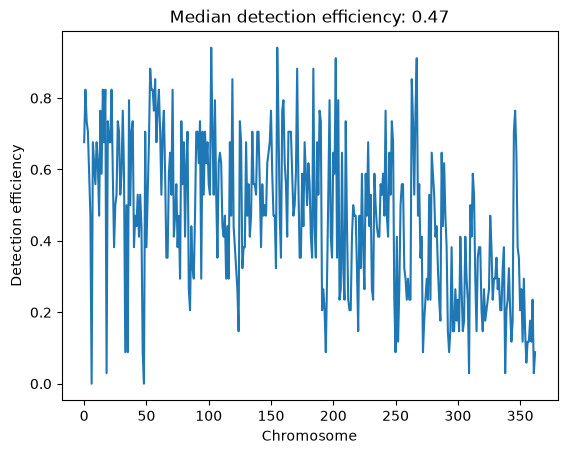

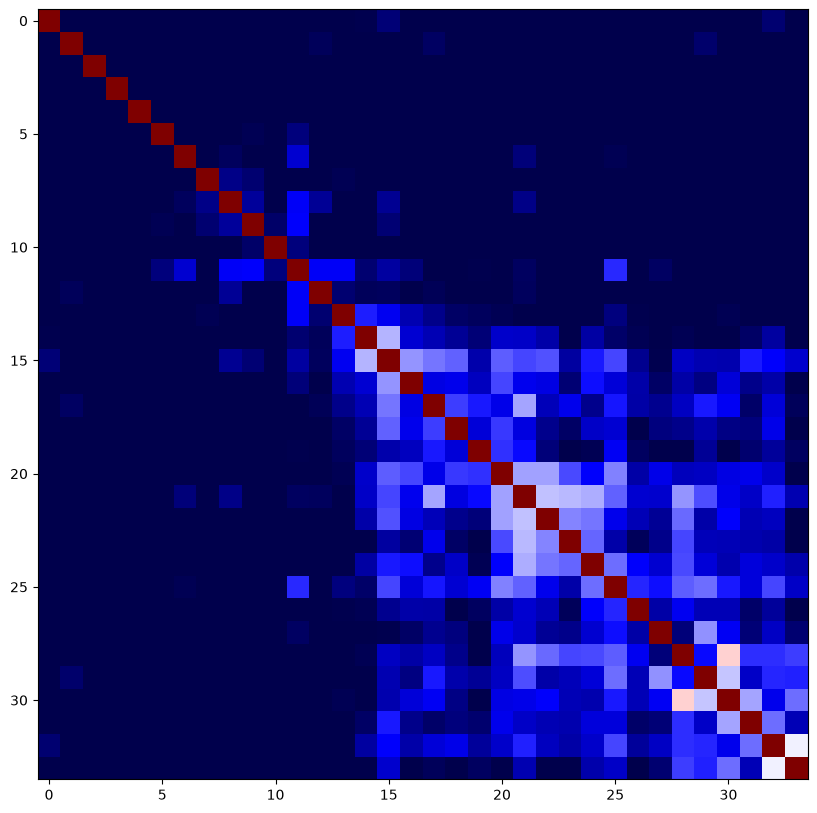

 55%|█████▍    | 66/121 [1:16:05<1:11:13, 77.71s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__065--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__066--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__066--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.36it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(18293), np.int64(3523)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__066--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__066--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 661/661 [00:02<00:00, 292.48it/s]


fraction the same: 0.9509655602029011
fraction nan: 0.06661030524161253
EM iteration number:  4



100%|██████████| 661/661 [00:02<00:00, 261.89it/s]


fraction the same: 0.978241523538311
fraction nan: 0.06661030524161253


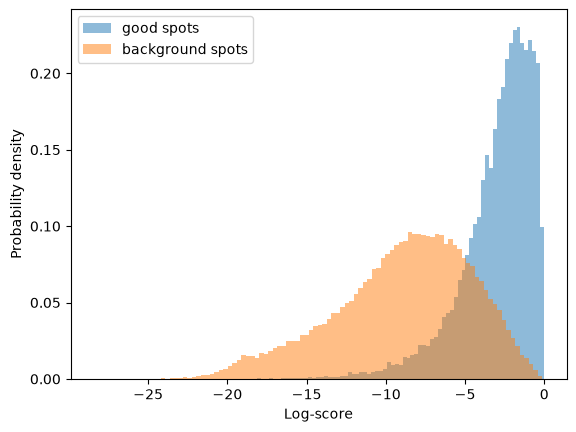

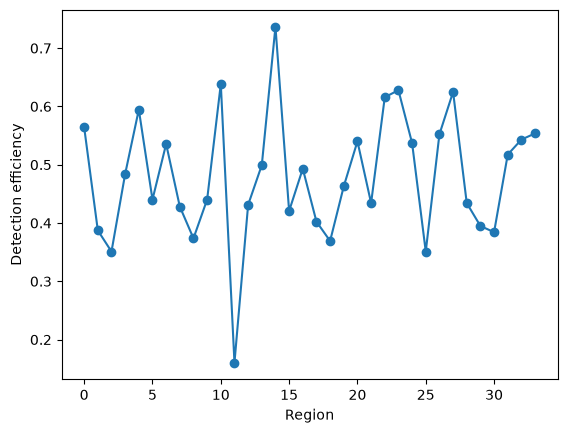

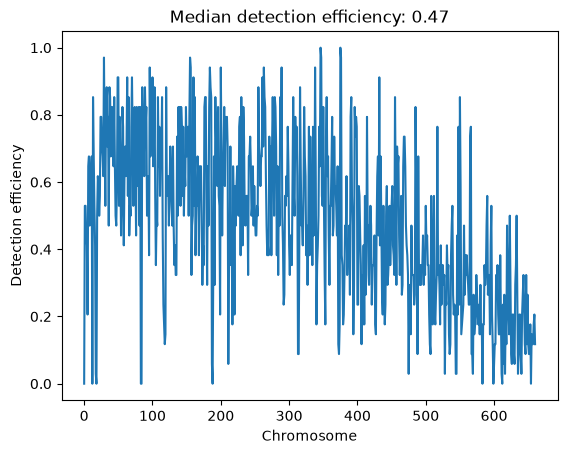

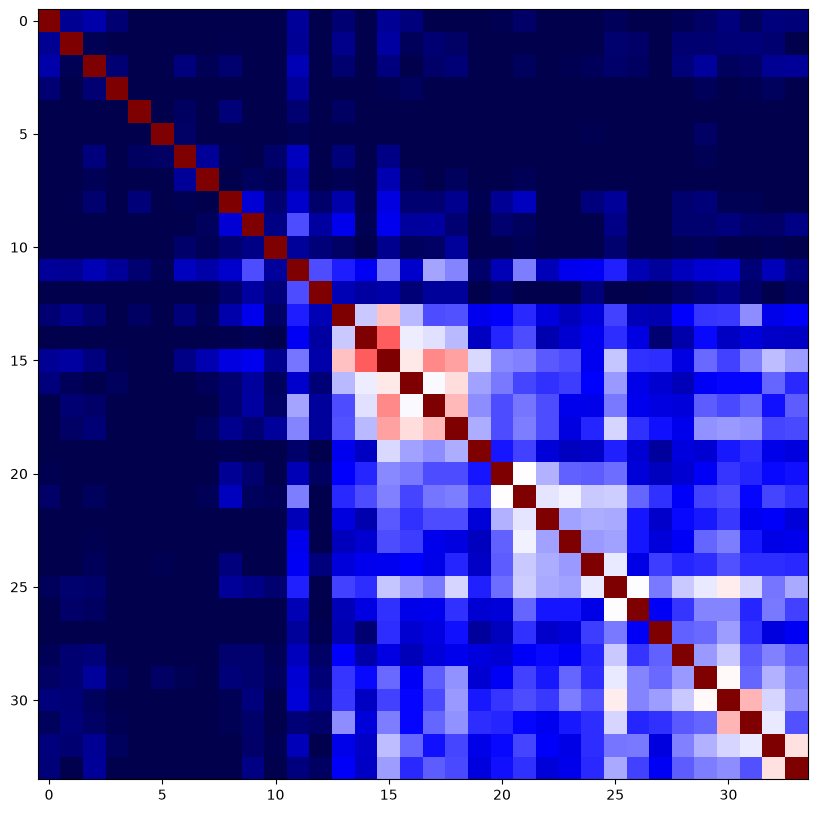

 55%|█████▌    | 67/121 [1:17:03<1:04:40, 71.85s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__066--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__067--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__067--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(23780), np.int64(3388)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__067--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__067--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1087/1087 [00:04<00:00, 252.40it/s]


fraction the same: 0.9428811082850803
fraction nan: 0.05173440121218681
EM iteration number:  4



100%|██████████| 1087/1087 [00:04<00:00, 253.28it/s]


fraction the same: 0.9760809567617296
fraction nan: 0.05173440121218681


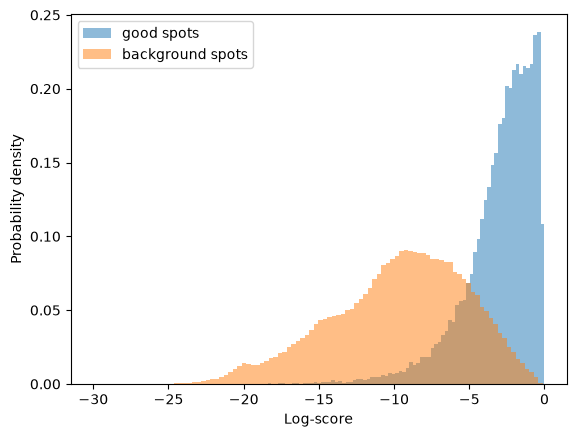

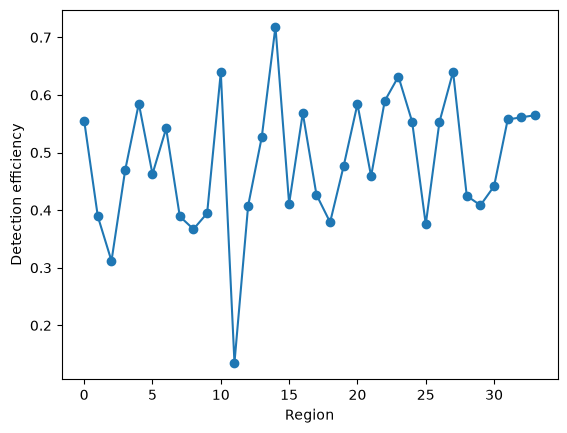

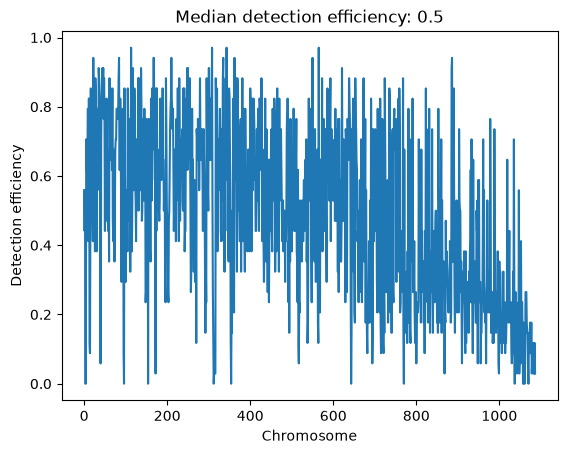

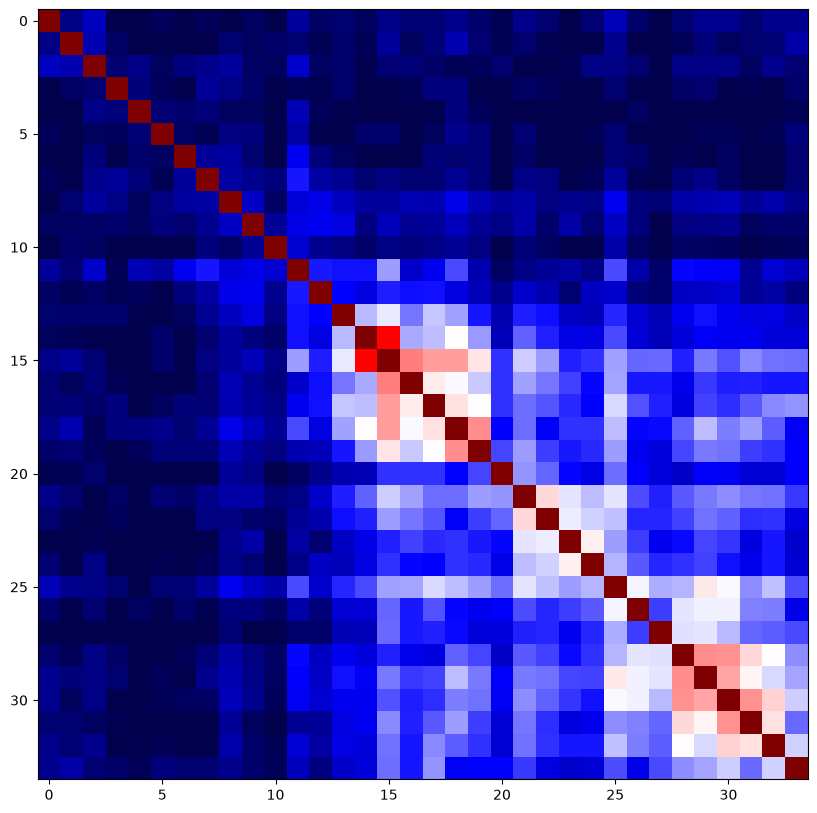

 56%|█████▌    | 68/121 [1:18:25<1:06:17, 75.04s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__067--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__068--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__068--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.30it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(23228), np.int64(3270)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__068--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__068--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1537/1537 [00:05<00:00, 257.02it/s]


fraction the same: 0.9477017872861572
fraction nan: 0.053388954801178765
EM iteration number:  4



100%|██████████| 1537/1537 [00:06<00:00, 246.21it/s]


fraction the same: 0.9768073787745417
fraction nan: 0.053388954801178765


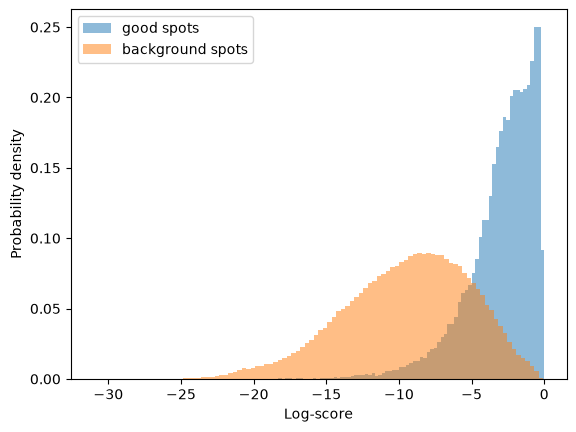

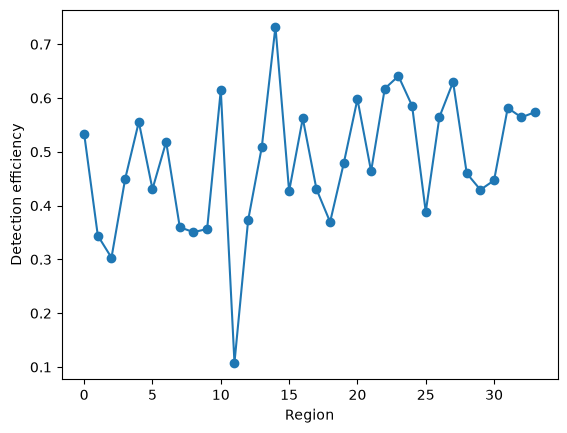

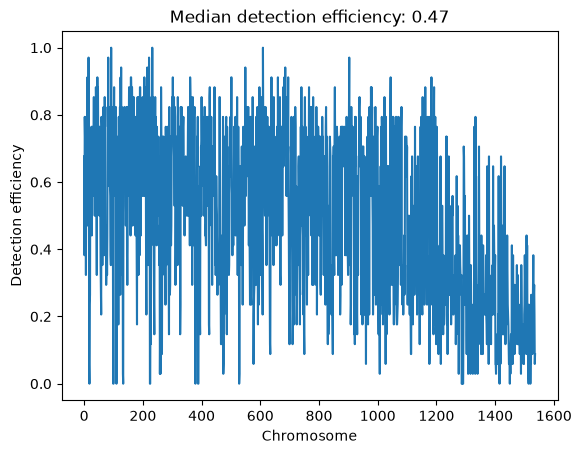

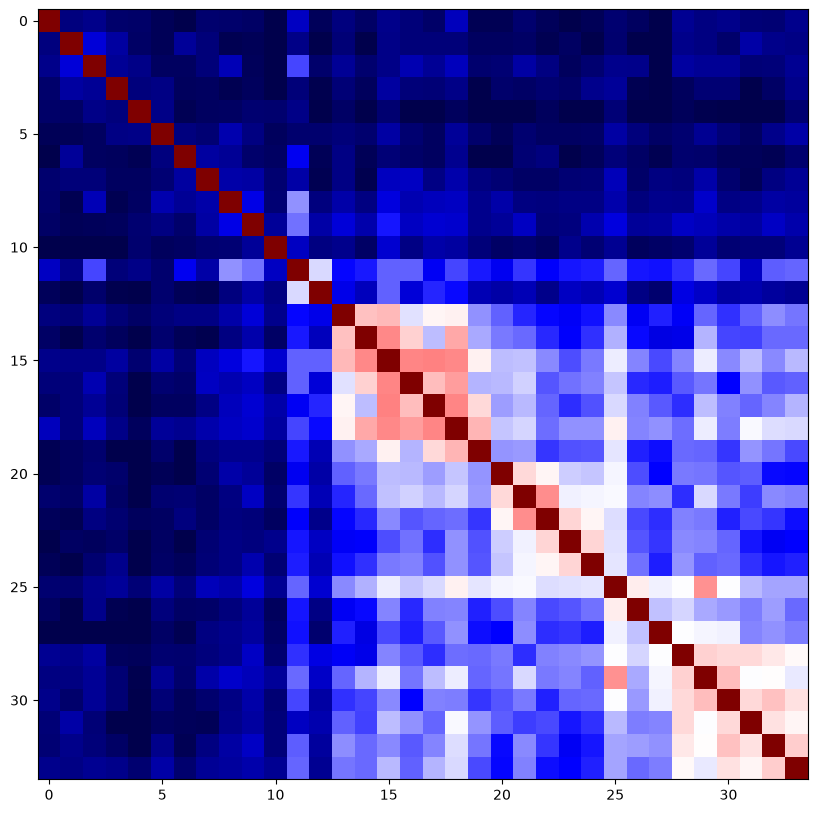

 57%|█████▋    | 69/121 [1:20:08<1:12:19, 83.45s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__068--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__069--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__069--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.33it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(25214), np.int64(4352)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__069--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__069--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1686/1686 [00:06<00:00, 256.83it/s]


fraction the same: 0.9504570511478613
fraction nan: 0.060812225245970276
EM iteration number:  4



100%|██████████| 1686/1686 [00:06<00:00, 268.18it/s]


fraction the same: 0.9789965808387412
fraction nan: 0.060812225245970276


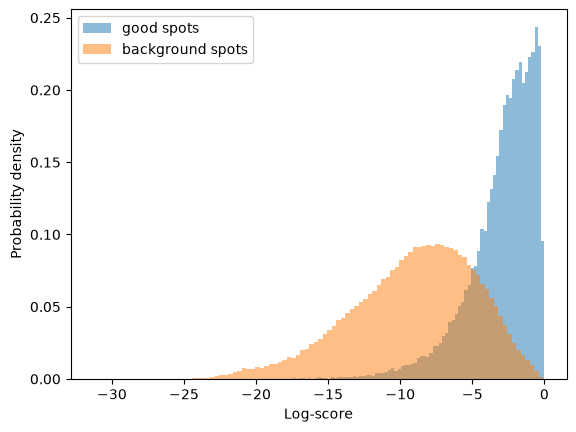

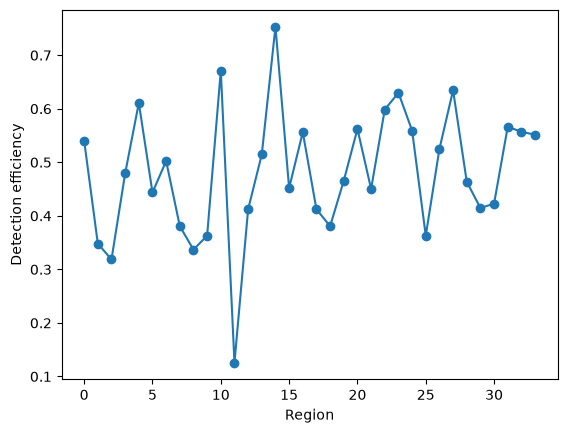

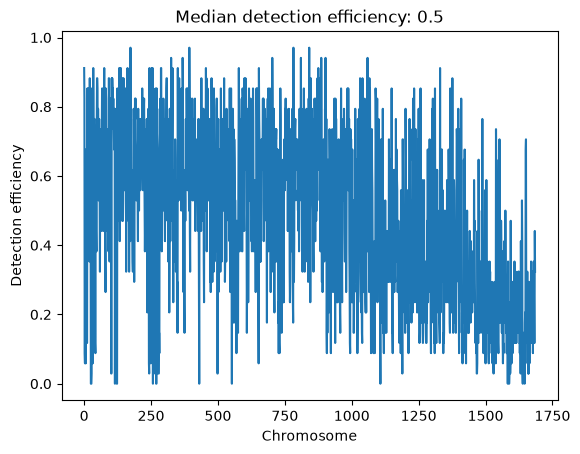

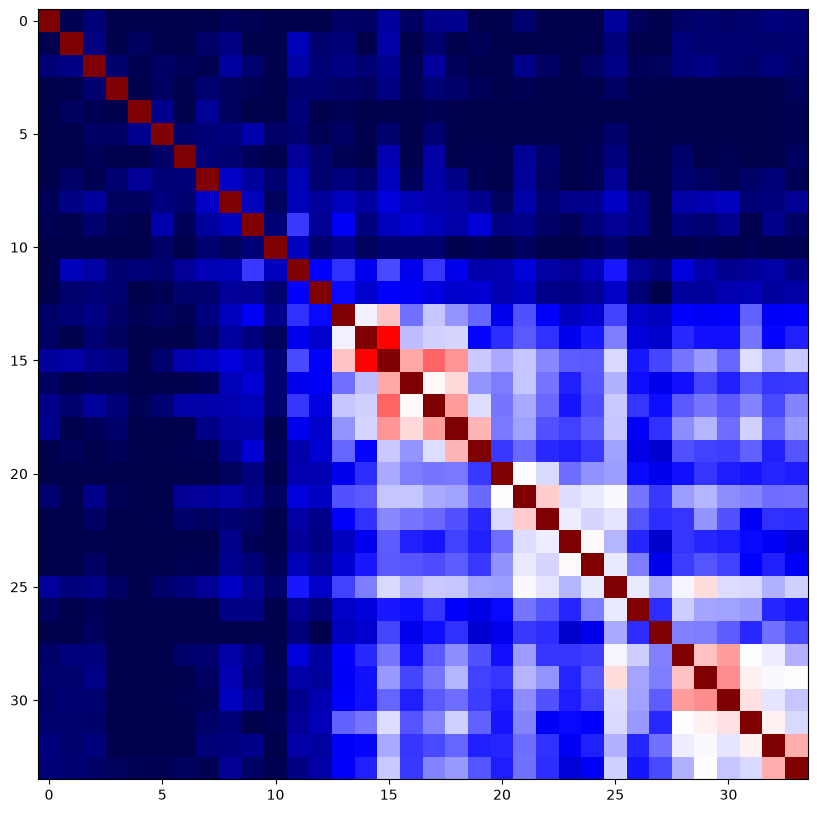

 58%|█████▊    | 70/121 [1:21:50<1:15:40, 89.03s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__069--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__070--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__070--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19695), np.int64(3483)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__070--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__070--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1159/1159 [00:04<00:00, 271.11it/s]


fraction the same: 0.948434248591585
fraction nan: 0.054966248794599805
EM iteration number:  4



100%|██████████| 1159/1159 [00:04<00:00, 270.93it/s]


fraction the same: 0.980053798913871
fraction nan: 0.054966248794599805


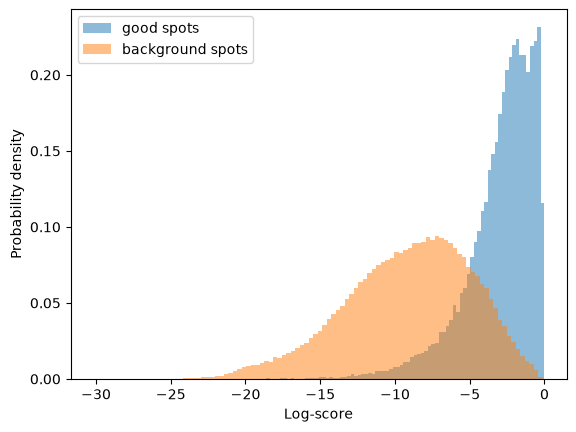

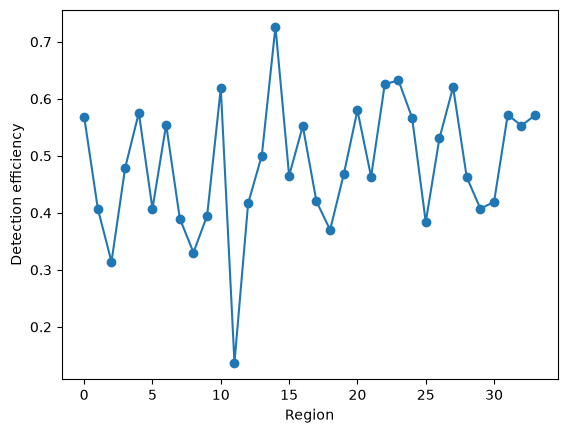

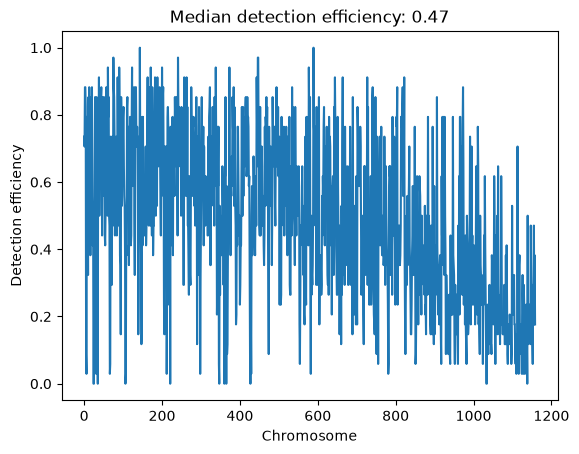

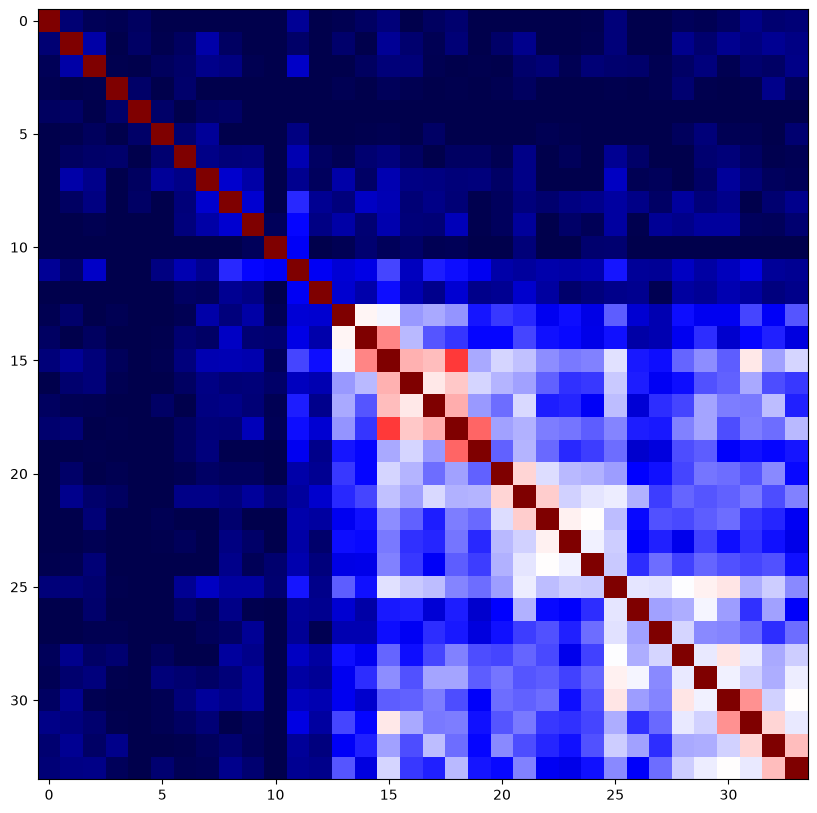

 59%|█████▊    | 71/121 [1:23:09<1:11:43, 86.06s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__070--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__071--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__071--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24929), np.int64(4514)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__071--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__071--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1798/1798 [00:06<00:00, 268.14it/s]


fraction the same: 0.9517601256297847
fraction nan: 0.057678466269711445
EM iteration number:  4



100%|██████████| 1798/1798 [00:06<00:00, 269.36it/s]


fraction the same: 0.9796669502061114
fraction nan: 0.057678466269711445


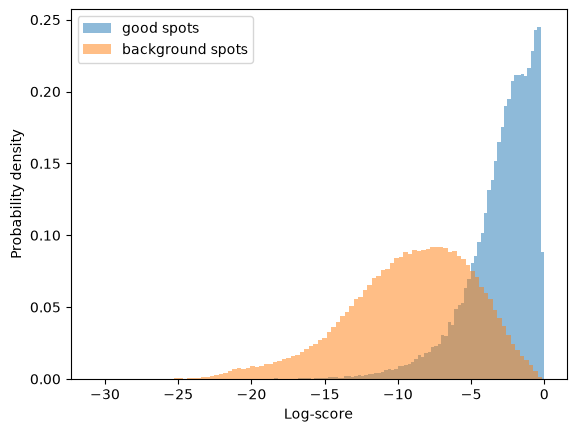

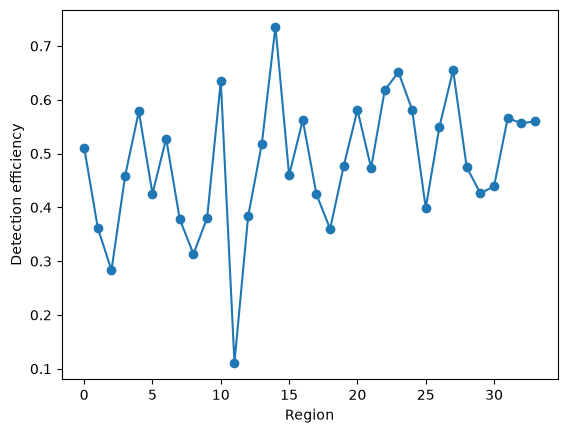

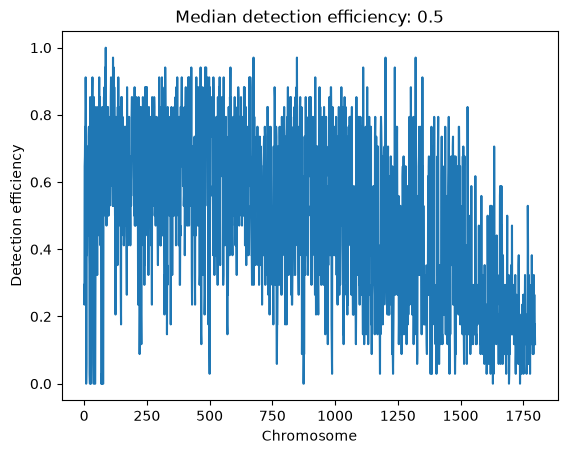

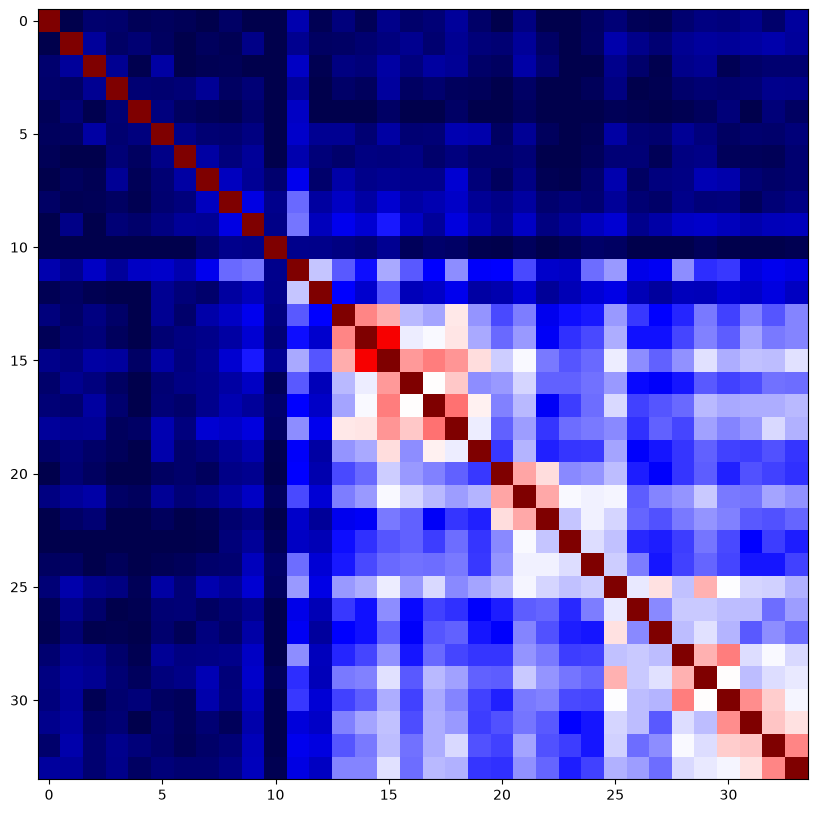

 60%|█████▉    | 72/121 [1:24:57<1:15:36, 92.57s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__071--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__072--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__072--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.30it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(18771), np.int64(3781)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__072--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__072--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1226/1226 [00:03<00:00, 320.43it/s]


fraction the same: 0.9545629018328375
fraction nan: 0.216246041646675
EM iteration number:  4



100%|██████████| 1226/1226 [00:03<00:00, 322.07it/s]


fraction the same: 0.980520103636887
fraction nan: 0.216246041646675


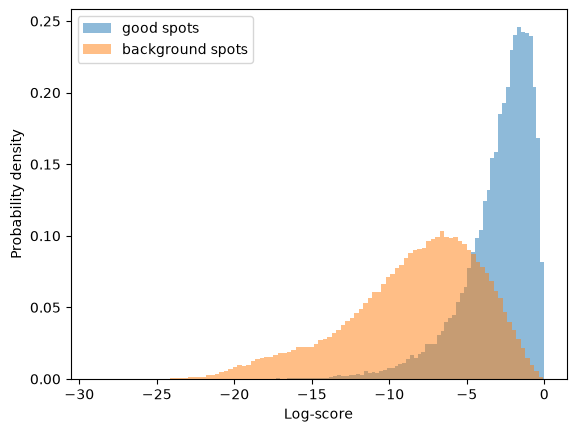

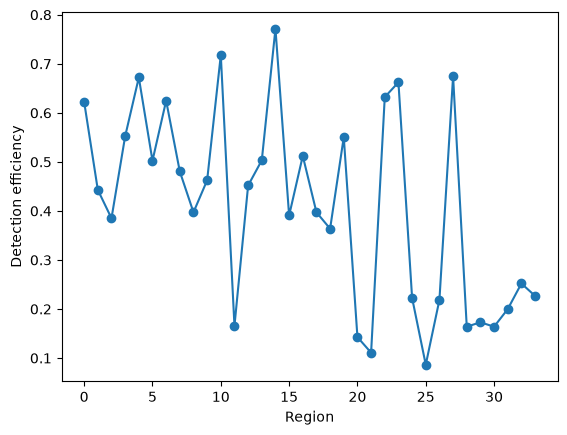

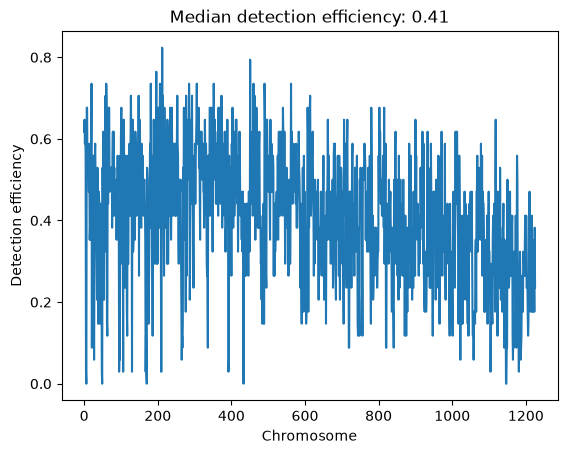

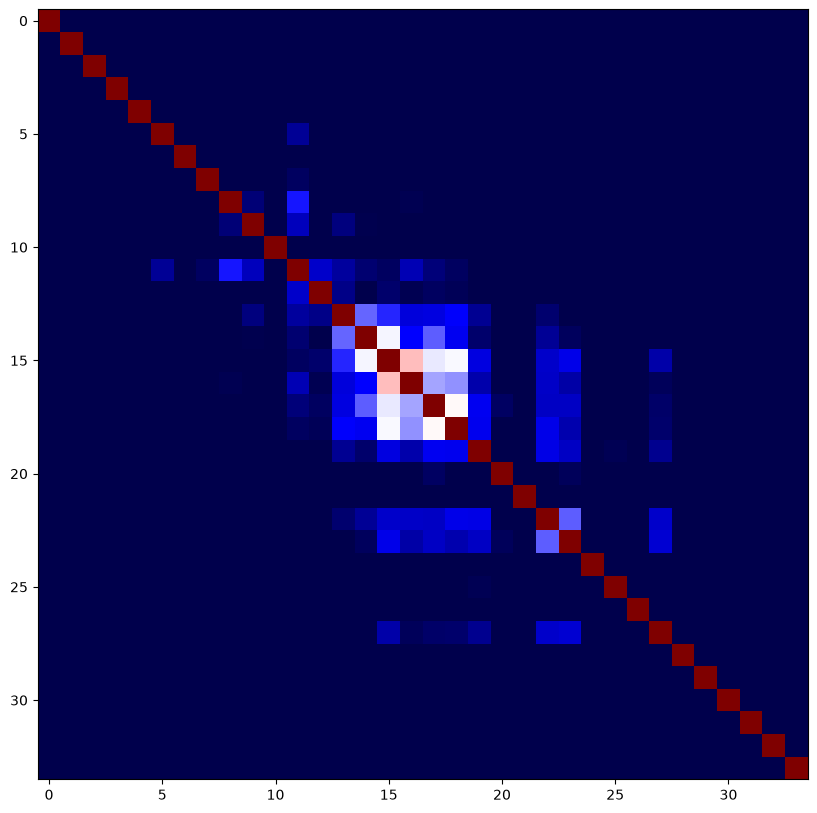

 60%|██████    | 73/121 [1:26:32<1:14:37, 93.29s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__072--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__073--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__073--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.33it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(16434), np.int64(3905)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__073--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__073--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 629/629 [00:01<00:00, 349.28it/s]


fraction the same: 0.9517441316749276
fraction nan: 0.10394650706069392
EM iteration number:  4



100%|██████████| 629/629 [00:02<00:00, 304.23it/s]


fraction the same: 0.980127186009539
fraction nan: 0.10394650706069392


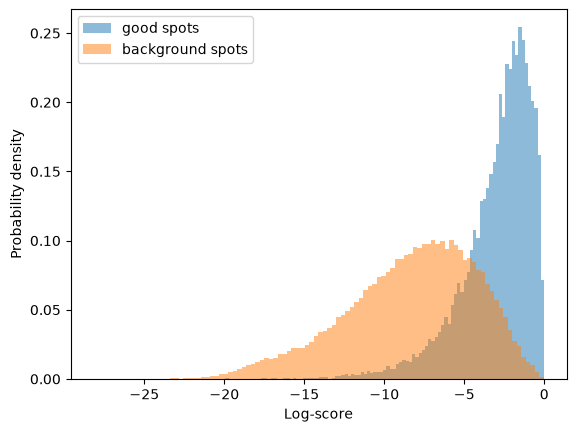

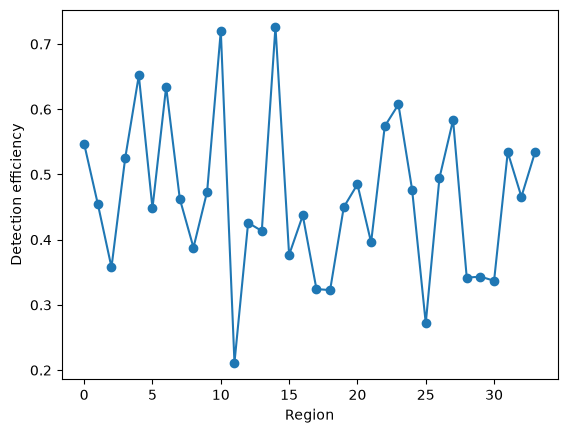

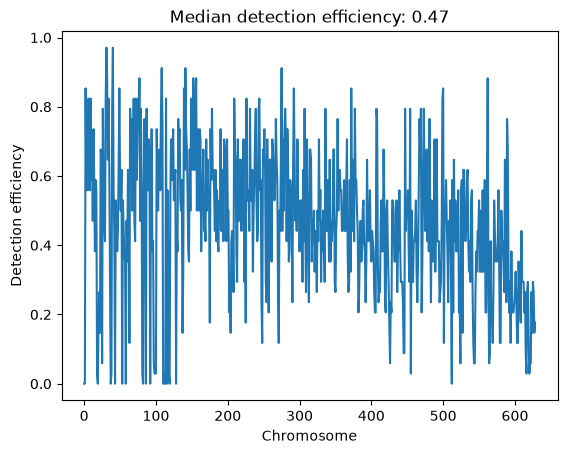

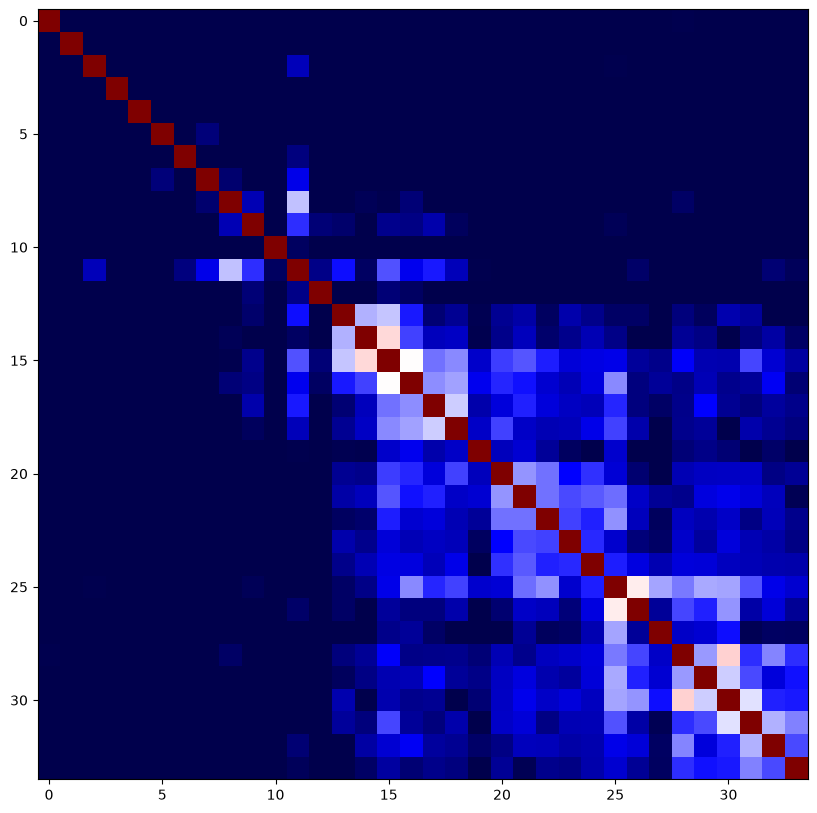

 61%|██████    | 74/121 [1:27:28<1:04:20, 82.13s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__073--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__074--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__074--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.25it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(22398), np.int64(3808)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__074--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__074--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1438/1438 [00:05<00:00, 265.18it/s]


fraction the same: 0.9483555591916878
fraction nan: 0.05976437863045079
EM iteration number:  4



100%|██████████| 1438/1438 [00:05<00:00, 252.33it/s]


fraction the same: 0.9760083449235049
fraction nan: 0.05976437863045079


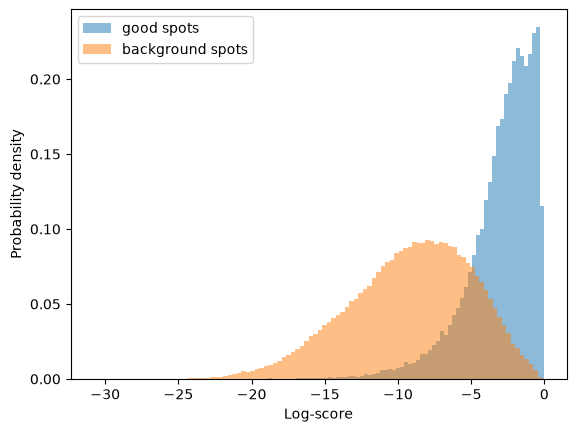

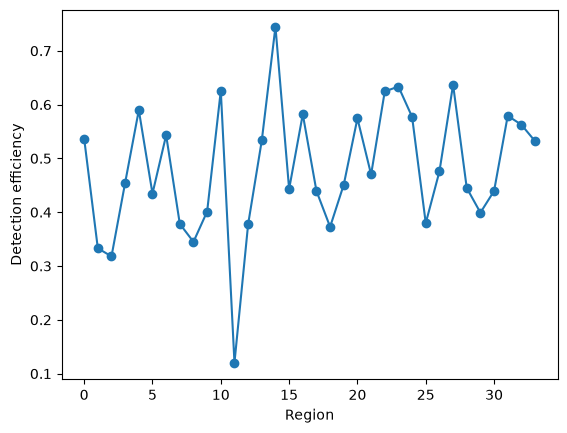

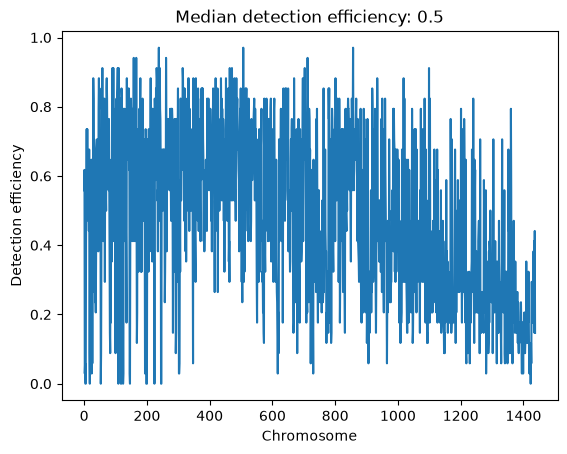

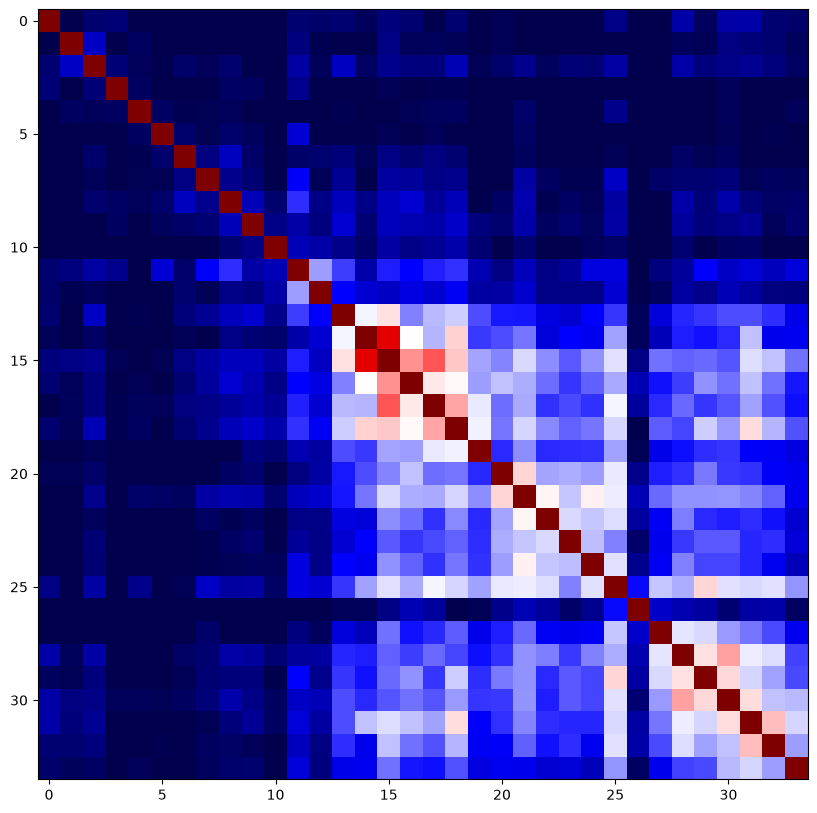

 62%|██████▏   | 75/121 [1:29:00<1:05:12, 85.05s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__074--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__075--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__075--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:15,  2.66it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(2446), np.int64(2191)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__075--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__075--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1447/1447 [00:03<00:00, 436.77it/s]


fraction the same: 0.9720313833895686
fraction nan: 0.3693239562583845
EM iteration number:  4



100%|██████████| 1447/1447 [00:03<00:00, 401.23it/s]


fraction the same: 0.9872555794951015
fraction nan: 0.3693239562583845


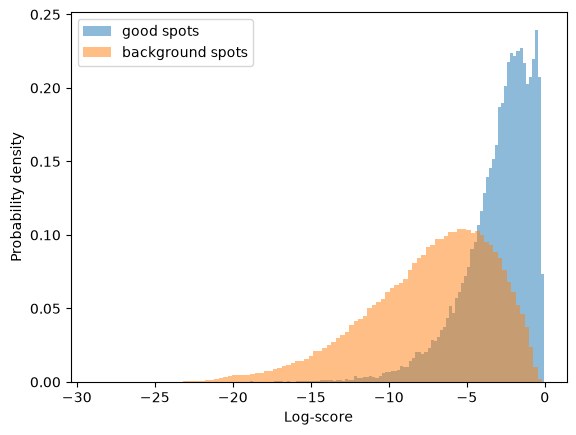

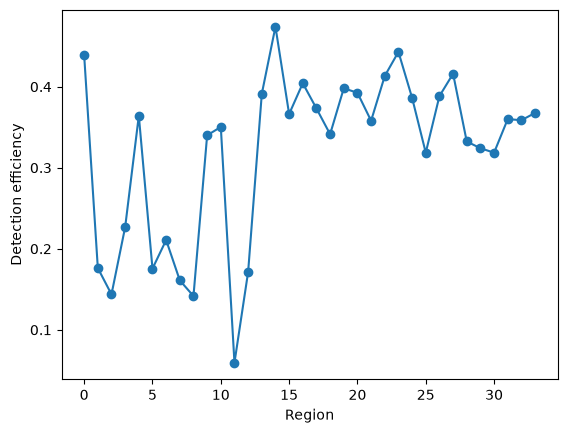

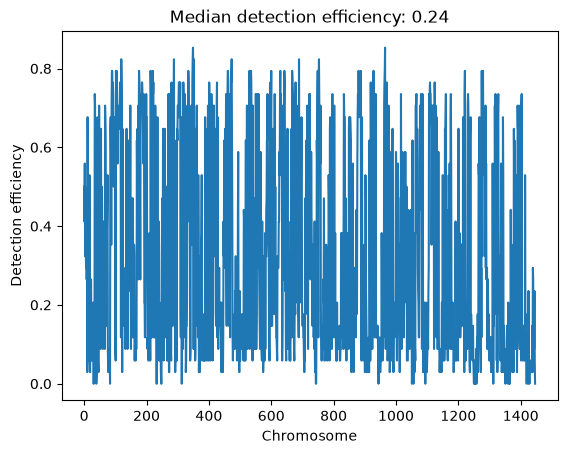

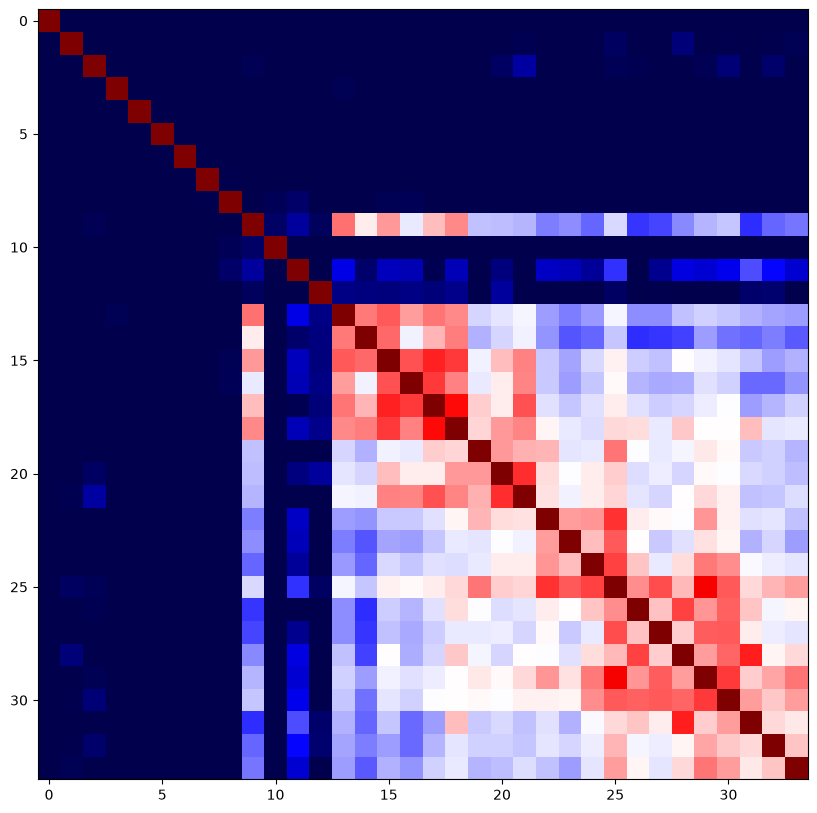

 63%|██████▎   | 76/121 [1:30:16<1:01:47, 82.39s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__075--__XHfs_finedrft_save.npz


 64%|██████▎   | 77/121 [1:30:19<42:49, 58.41s/it]  

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__076--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__077--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__077--H10_NC_set1--dapiFeatures.npz


... (94 outputs left out)


100%|██████████| 1331/1331 [00:04<00:00, 285.11it/s]


fraction the same: 0.9566668139832943
fraction nan: 0.07152958854465903
EM iteration number:  4



100%|██████████| 1331/1331 [00:04<00:00, 268.74it/s]


fraction the same: 0.9809961550360189
fraction nan: 0.07152958854465903


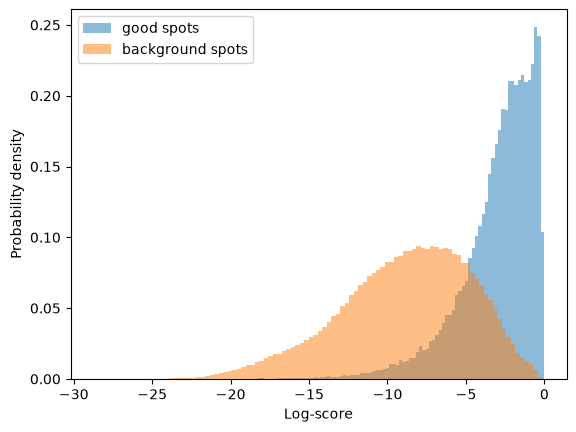

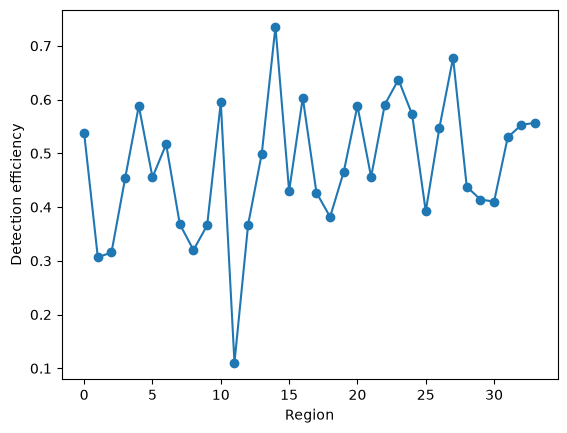

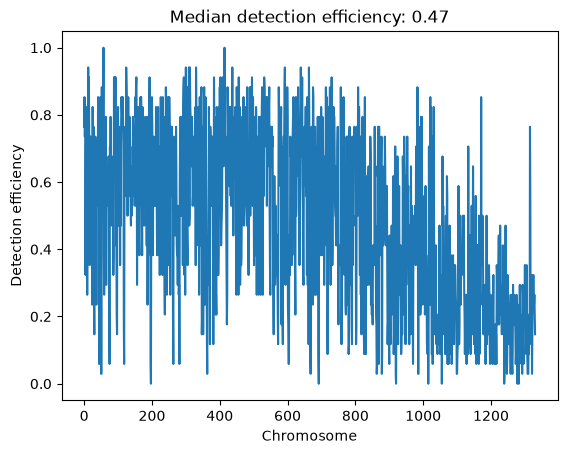

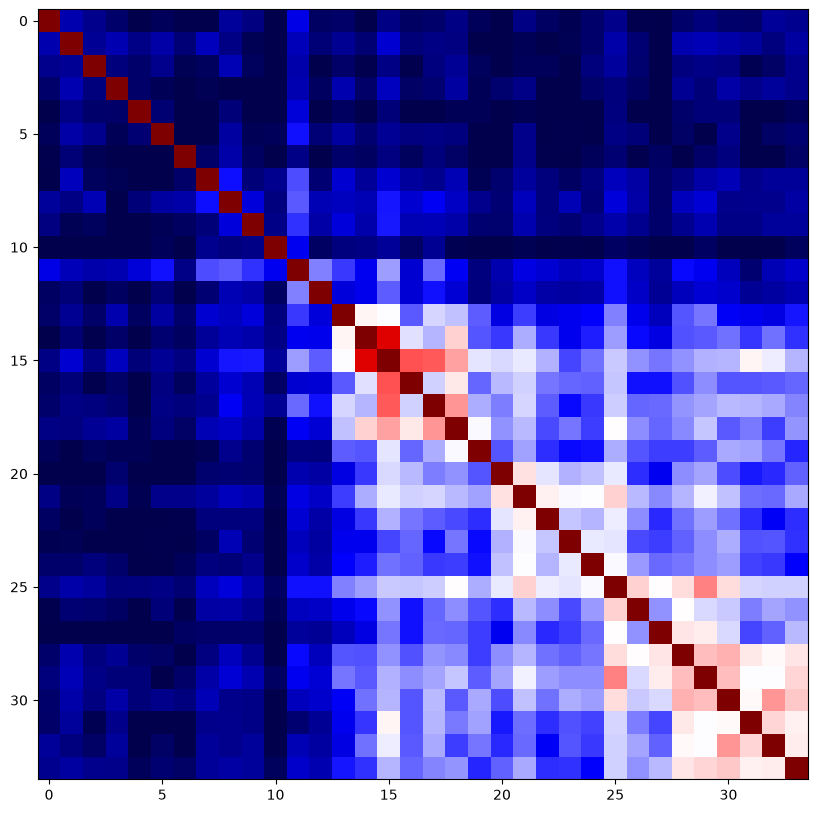

 64%|██████▍   | 78/121 [1:31:43<47:23, 66.12s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__077--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__078--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__078--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(9706), np.int64(4363)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__078--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__078--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 2/2 [00:00<00:00, 127.99it/s]


fraction the same: 1.0
fraction nan: 0.29411764705882354
EM iteration number:  4



100%|██████████| 2/2 [00:00<?, ?it/s]

fraction the same: 1.0
fraction nan: 0.29411764705882354


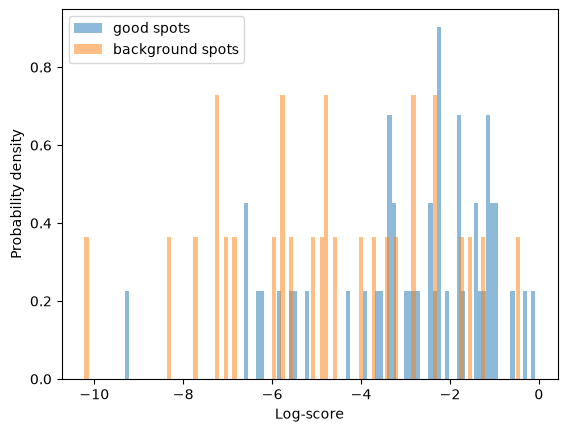

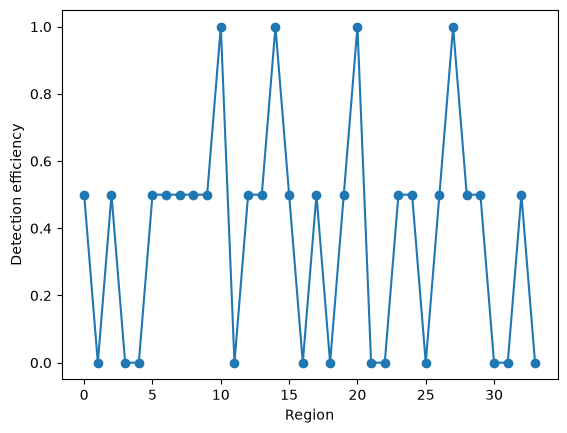

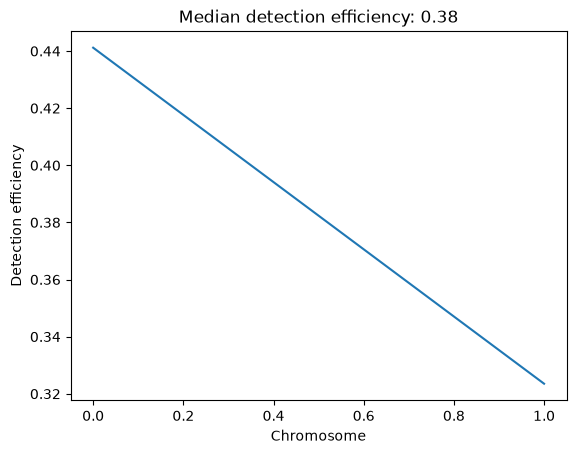

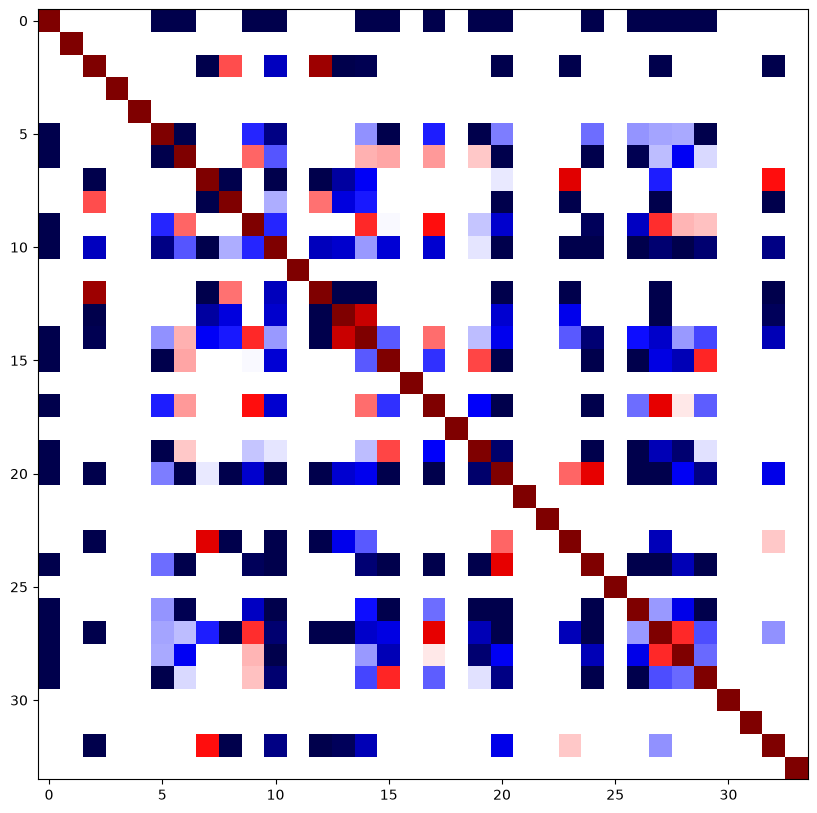

 65%|██████▌   | 79/121 [1:32:16<39:18, 56.15s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__078--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__079--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__079--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.45it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(11679), np.int64(4865)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__079--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__079--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 248/248 [00:00<00:00, 367.56it/s]


fraction the same: 0.9650142314990512
fraction nan: 0.09724857685009487
EM iteration number:  4



100%|██████████| 248/248 [00:00<00:00, 360.70it/s]


fraction the same: 0.9845825426944972
fraction nan: 0.09724857685009487


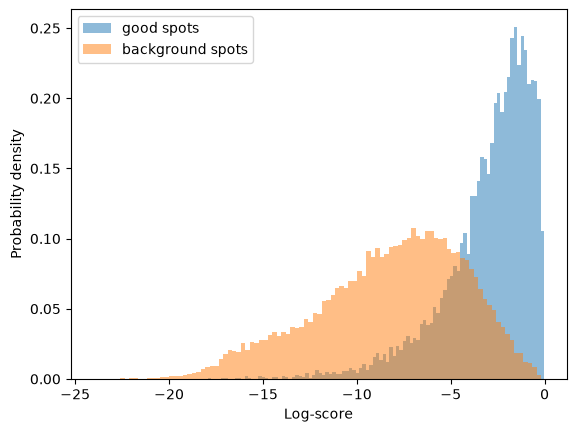

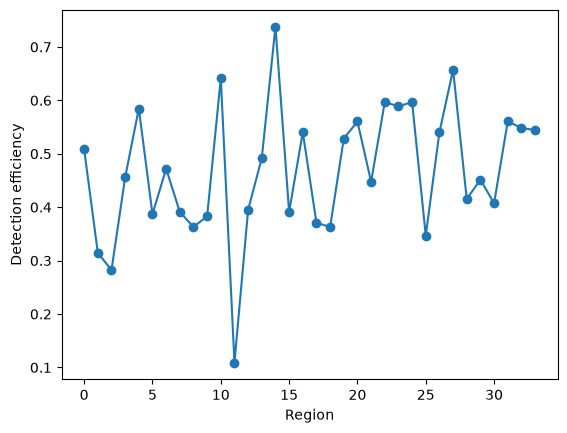

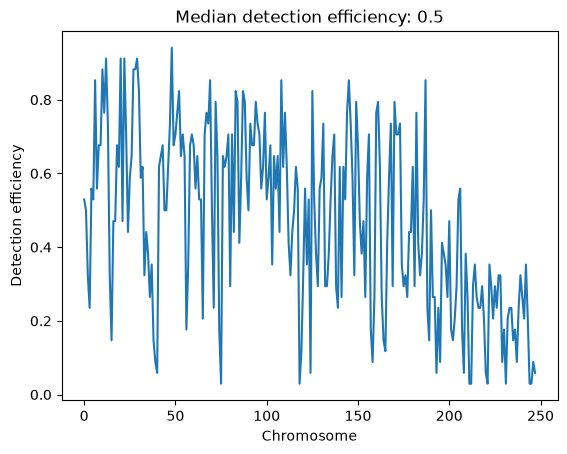

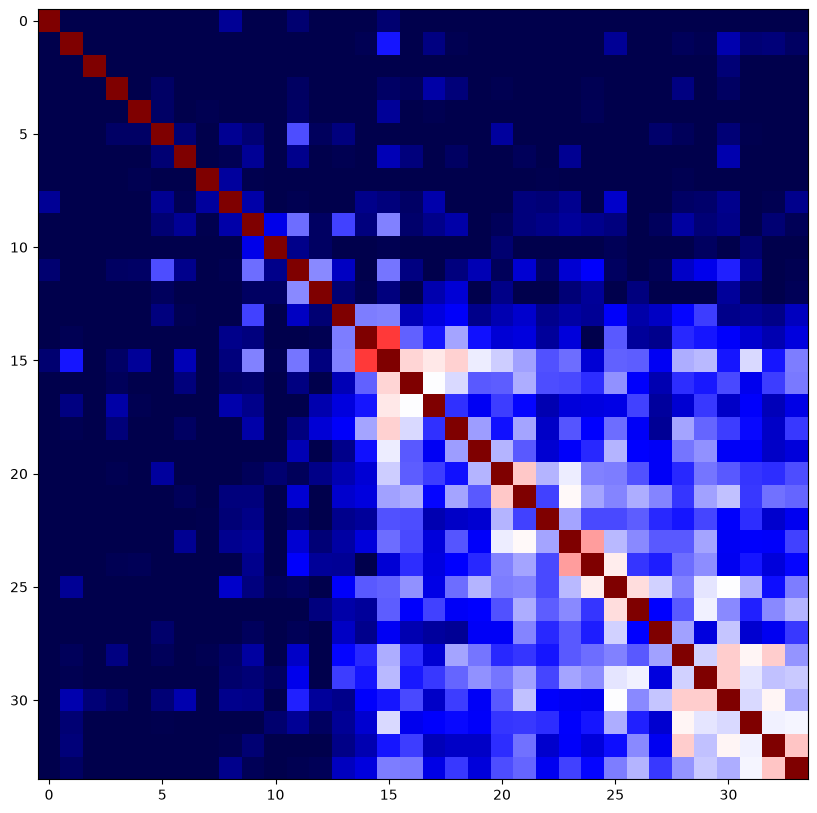

 66%|██████▌   | 80/121 [1:32:56<35:09, 51.45s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__079--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__080--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__080--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.28it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(20280), np.int64(7610)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__080--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__080--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1075/1075 [00:03<00:00, 303.67it/s]


fraction the same: 0.9594801641586868
fraction nan: 0.09173734610123119
EM iteration number:  4



100%|██████████| 1075/1075 [00:03<00:00, 330.56it/s]


fraction the same: 0.9822435020519836
fraction nan: 0.09173734610123119


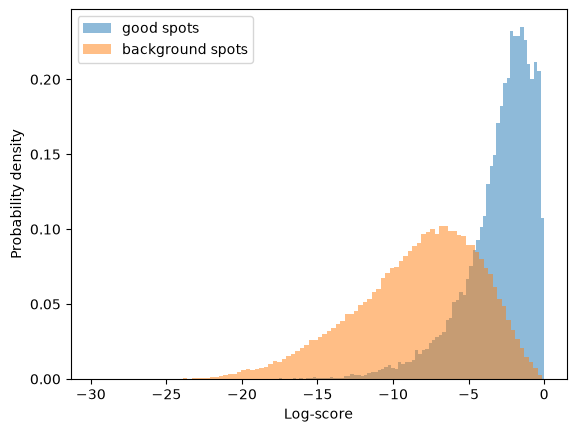

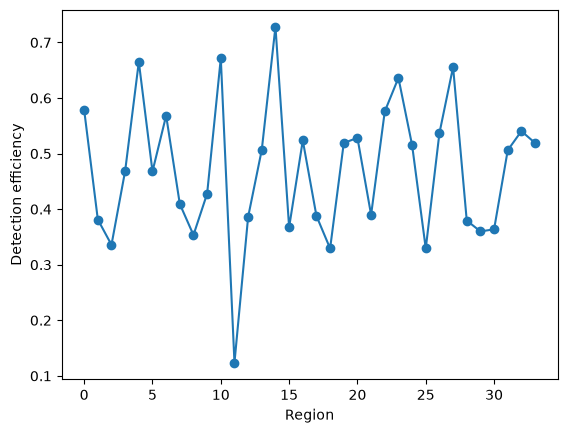

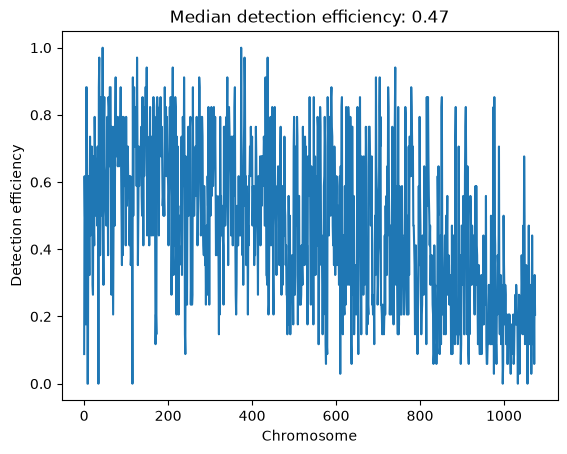

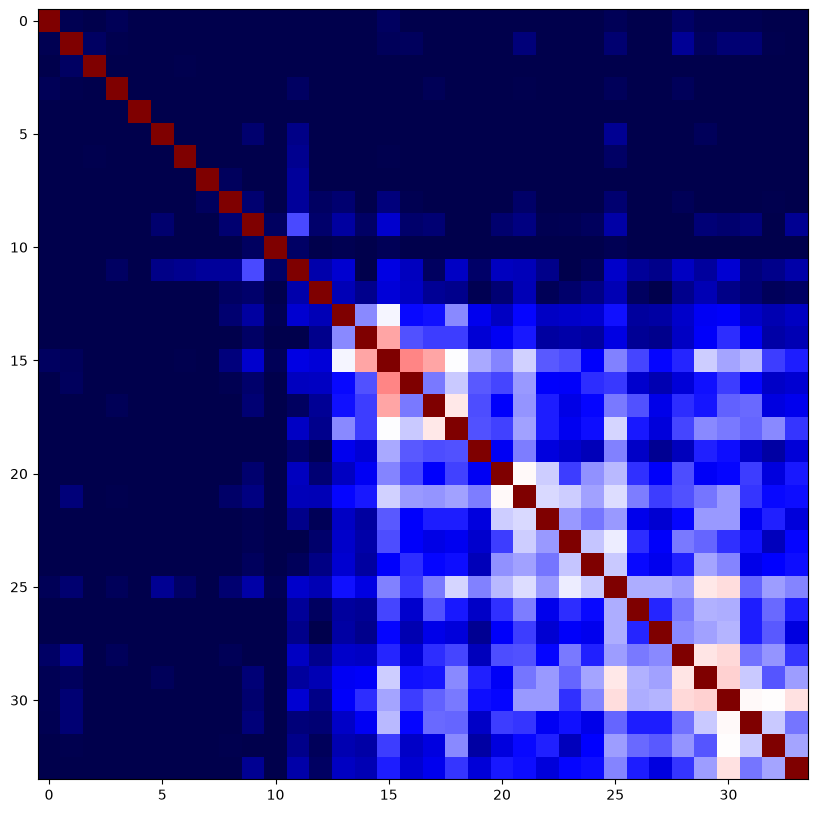

 67%|██████▋   | 81/121 [1:34:03<37:26, 56.17s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__080--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__081--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__081--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:25,  1.64it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(5383), np.int64(958)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__081--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__081--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 4/4 [00:00<00:00, 255.99it/s]


fraction the same: 0.9632352941176471
fraction nan: 0.04411764705882353
EM iteration number:  4



100%|██████████| 4/4 [00:00<00:00, 255.98it/s]

fraction the same: 0.9632352941176471
fraction nan: 0.04411764705882353


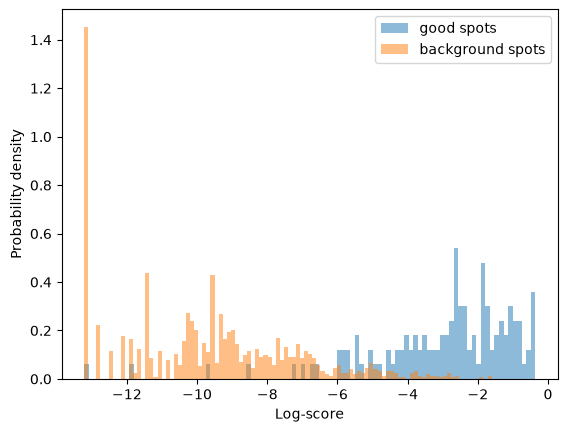

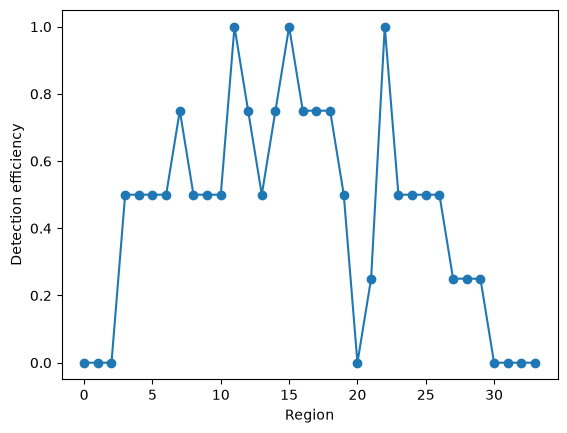

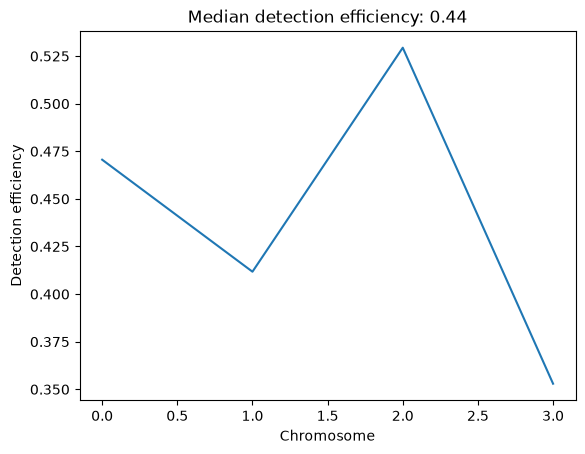

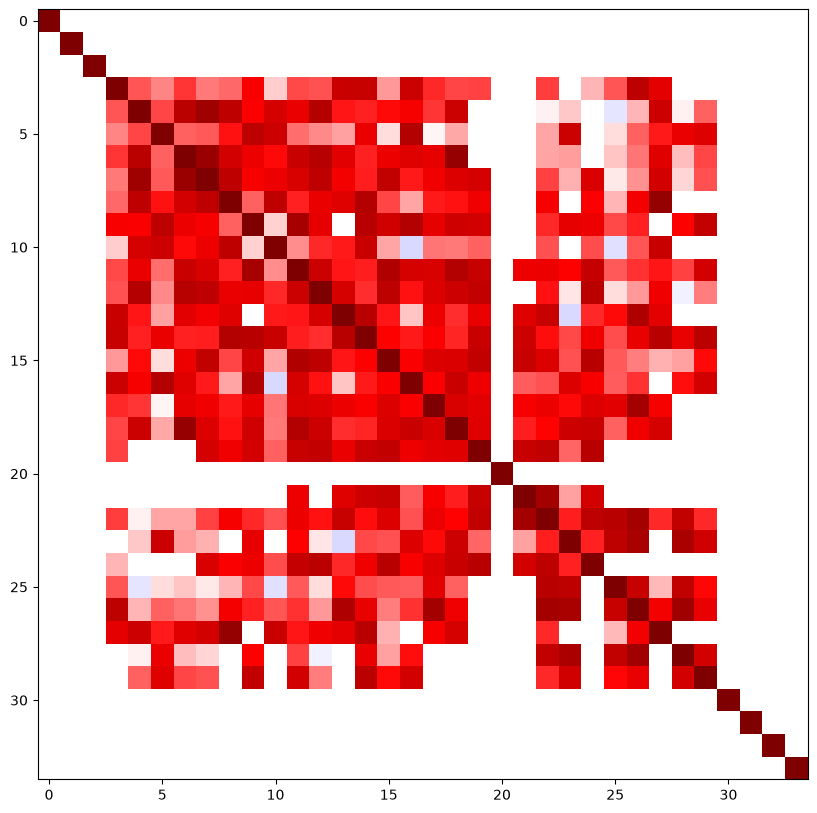

 68%|██████▊   | 82/121 [1:34:34<31:35, 48.61s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__081--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__082--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__082--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.25it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(20386), np.int64(7550)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__082--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__082--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1046/1046 [00:03<00:00, 309.14it/s]


fraction the same: 0.9630244067034079
fraction nan: 0.10204139016983467
EM iteration number:  4



100%|██████████| 1046/1046 [00:03<00:00, 337.42it/s]


fraction the same: 0.9839444381959285
fraction nan: 0.10204139016983467


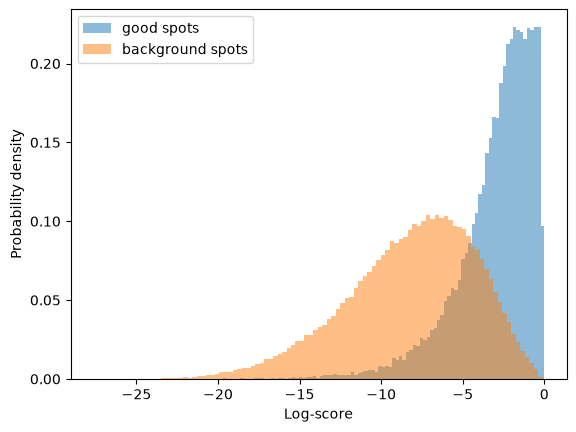

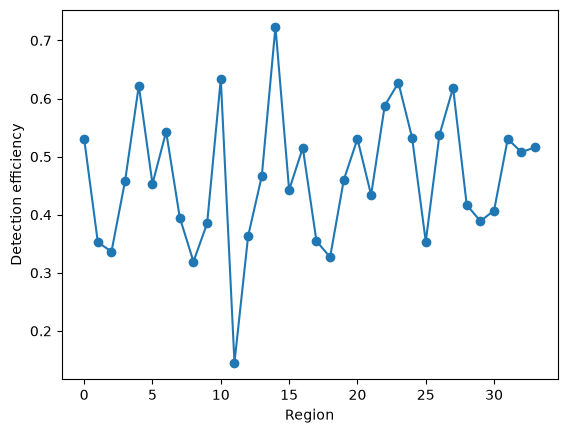

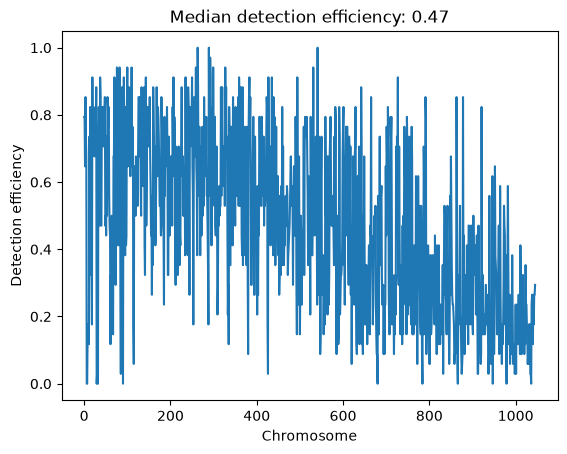

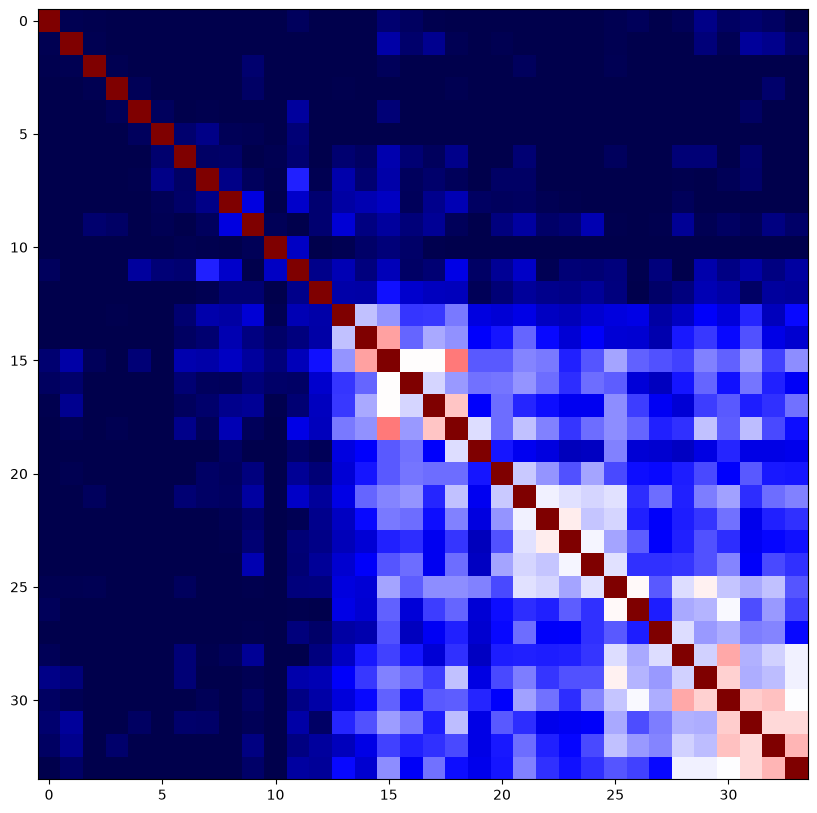

 69%|██████▊   | 83/121 [1:35:39<33:54, 53.54s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__082--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__083--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__083--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.31it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(20509), np.int64(8243)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__083--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__083--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1054/1054 [00:03<00:00, 323.45it/s]


fraction the same: 0.95914722625293
fraction nan: 0.14806339993302825
EM iteration number:  4



100%|██████████| 1054/1054 [00:03<00:00, 297.85it/s]


fraction the same: 0.9823641031365108
fraction nan: 0.14806339993302825


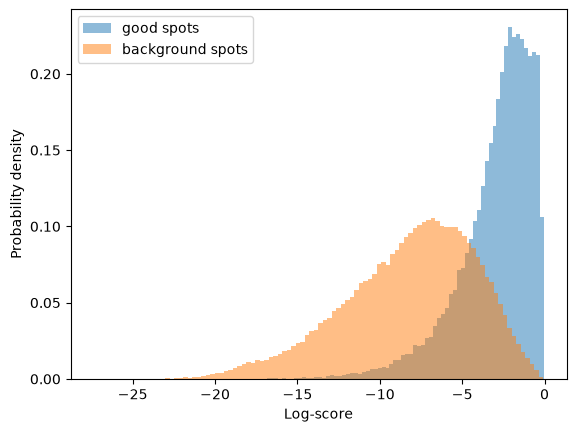

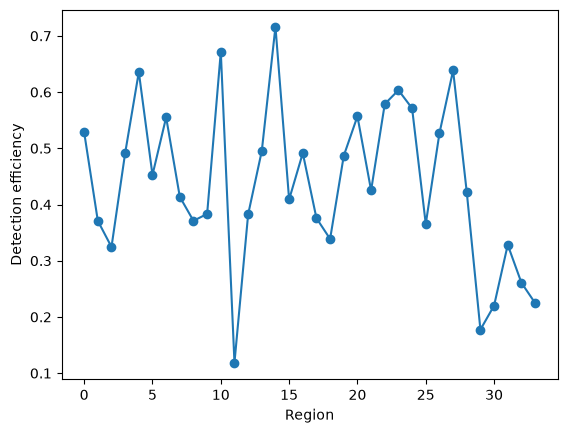

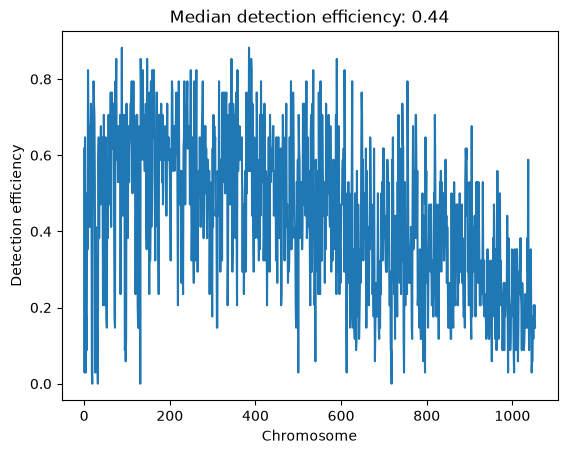

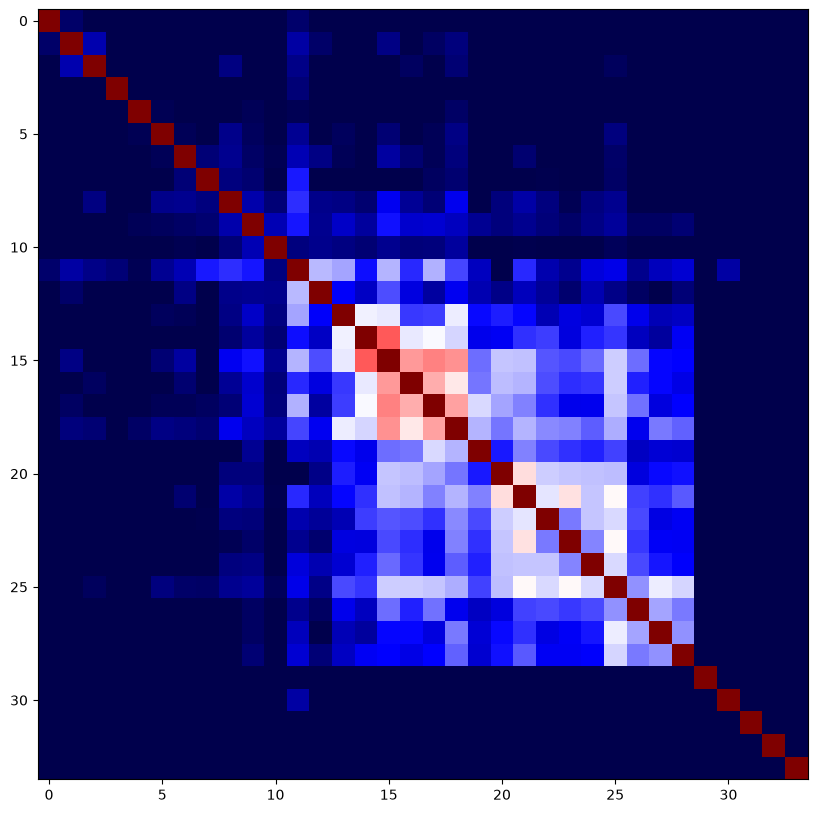

 69%|██████▉   | 84/121 [1:36:51<36:17, 58.84s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__083--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__084--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__084--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:35,  1.16it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(9645), np.int64(4573)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__084--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__084--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 175/175 [00:00<00:00, 373.31it/s]


fraction the same: 0.9605042016806723
fraction nan: 0.10873949579831933
EM iteration number:  4



100%|██████████| 175/175 [00:00<00:00, 386.26it/s]


fraction the same: 0.9850420168067227
fraction nan: 0.10873949579831933


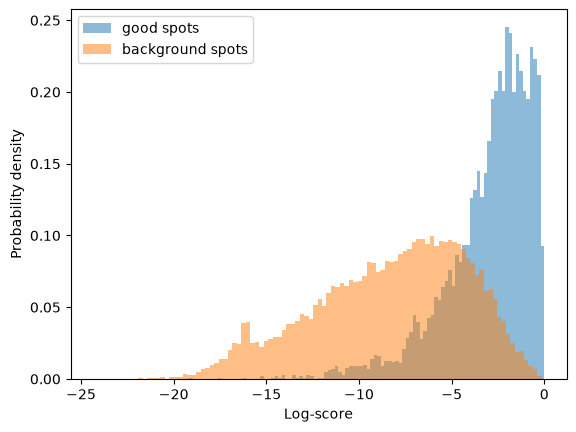

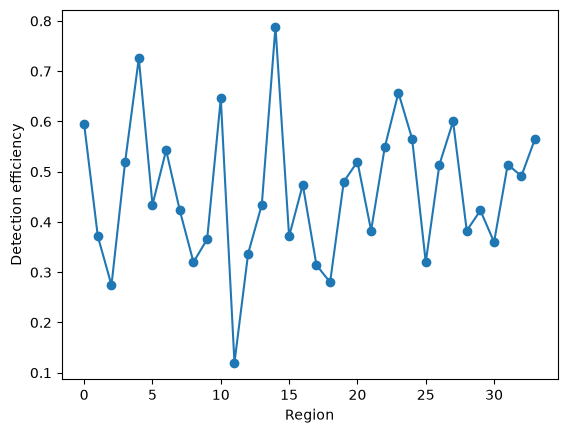

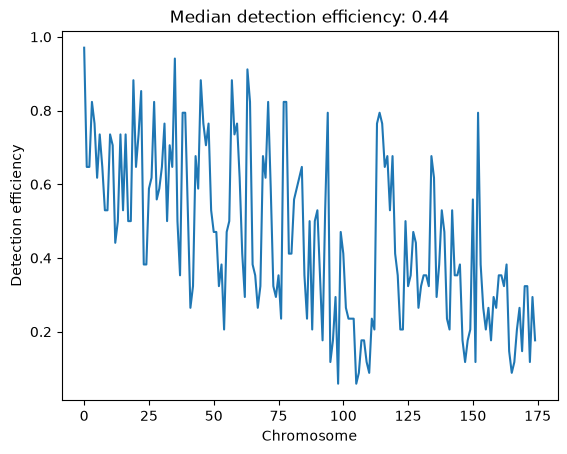

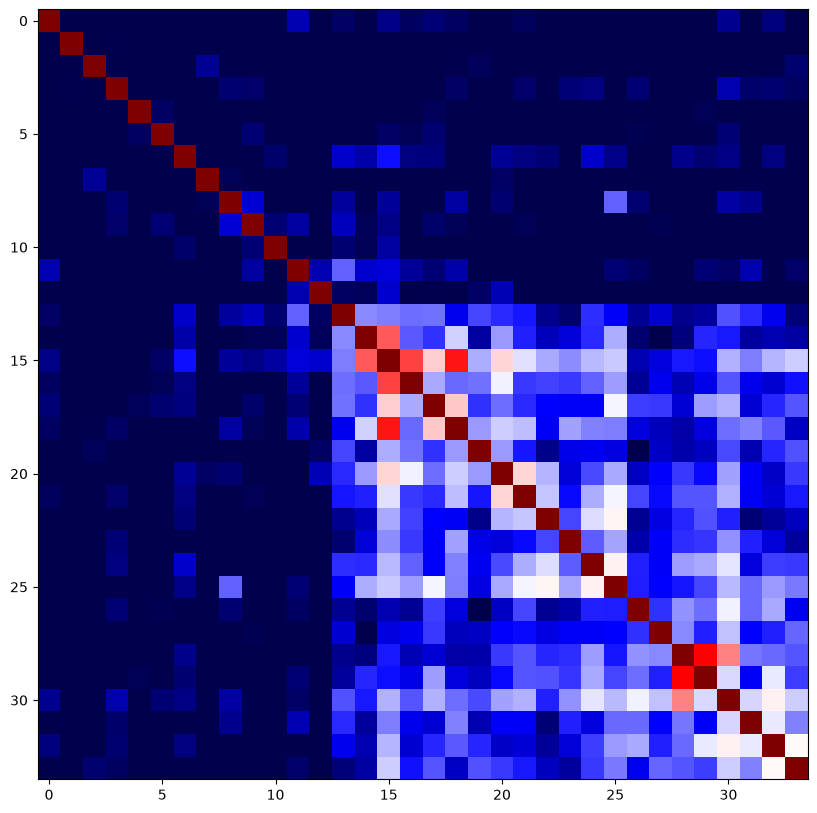

 70%|███████   | 85/121 [1:37:27<31:13, 52.03s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__084--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__085--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__085--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:24,  1.64it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(12810), np.int64(6703)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__085--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__085--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 304/304 [00:00<00:00, 360.27it/s]


fraction the same: 0.9602360681114551
fraction nan: 0.11232585139318886
EM iteration number:  4



100%|██████████| 304/304 [00:00<00:00, 366.08it/s]


fraction the same: 0.9839396284829721
fraction nan: 0.11232585139318886


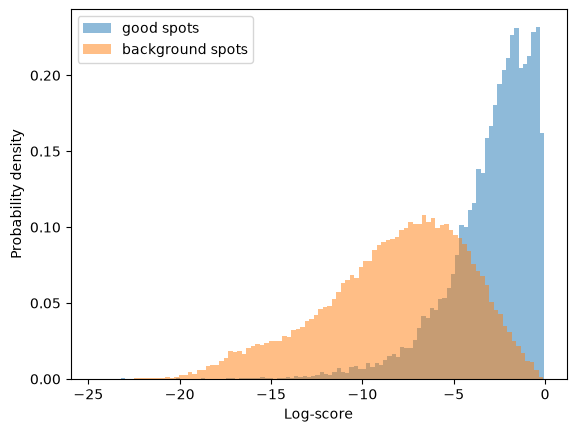

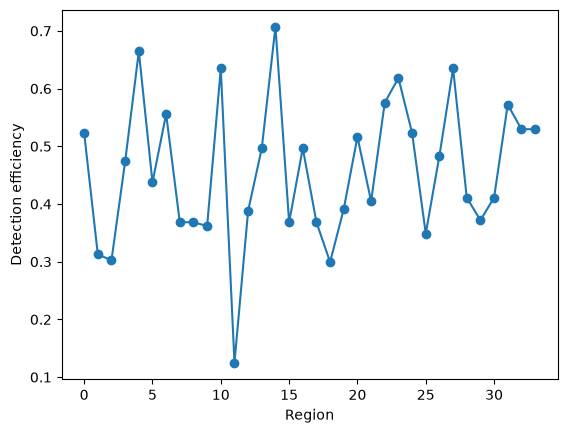

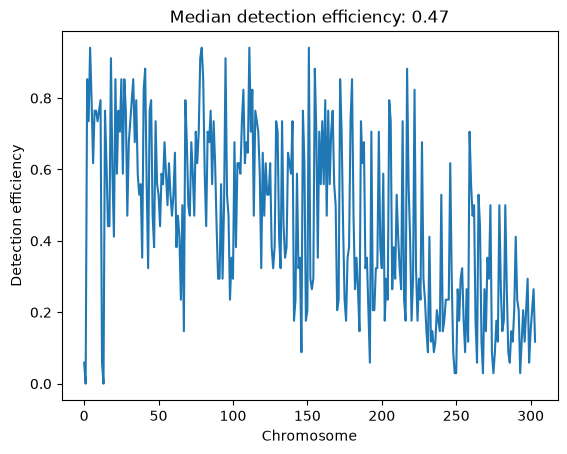

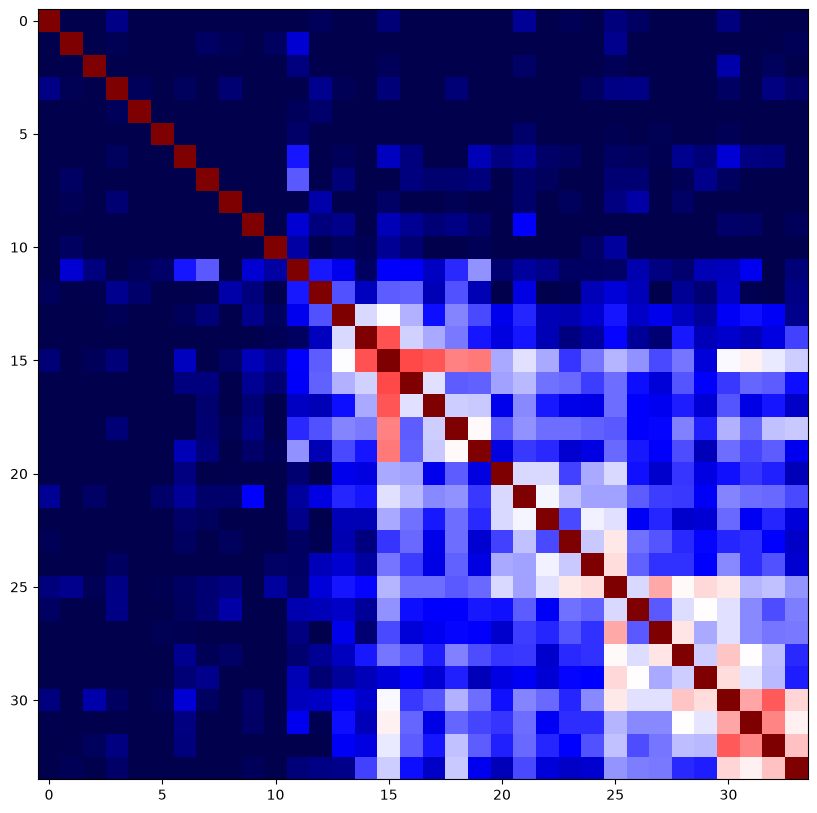

 71%|███████   | 86/121 [1:38:02<27:20, 46.88s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__085--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__086--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__086--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:26,  1.56it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(7773), np.int64(2675)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__086--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__086--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 84/84 [00:00<00:00, 484.48it/s]


fraction the same: 0.9733893557422969
fraction nan: 0.2338935574229692
EM iteration number:  4



100%|██████████| 84/84 [00:00<00:00, 537.56it/s]


fraction the same: 0.9898459383753502
fraction nan: 0.2338935574229692


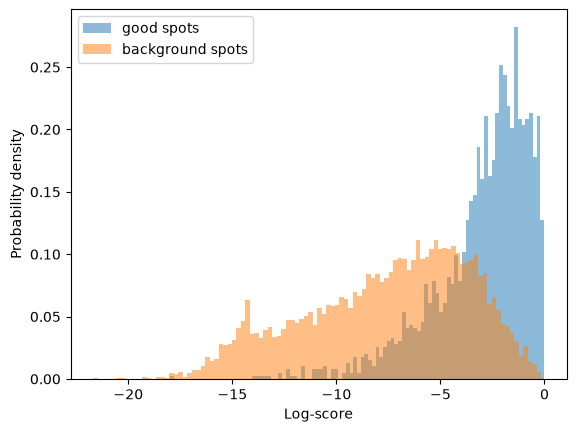

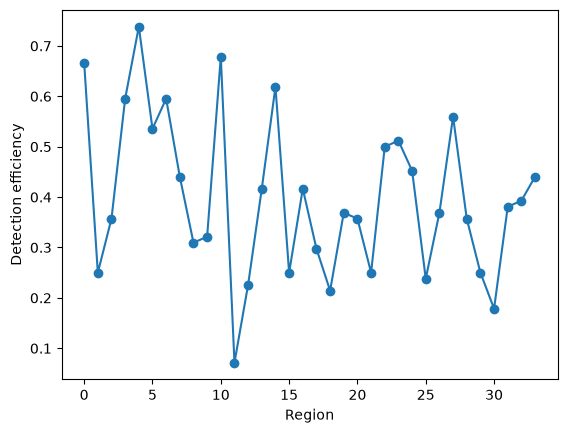

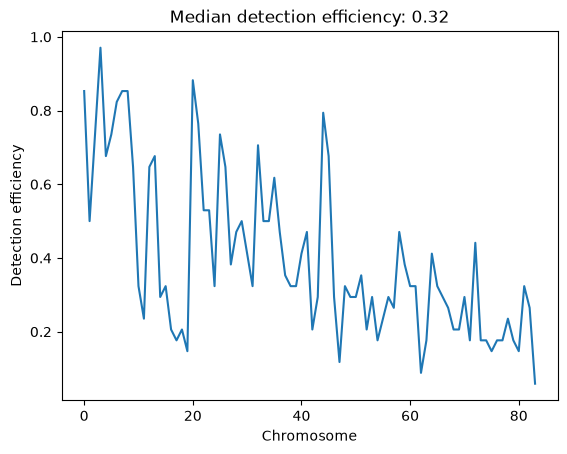

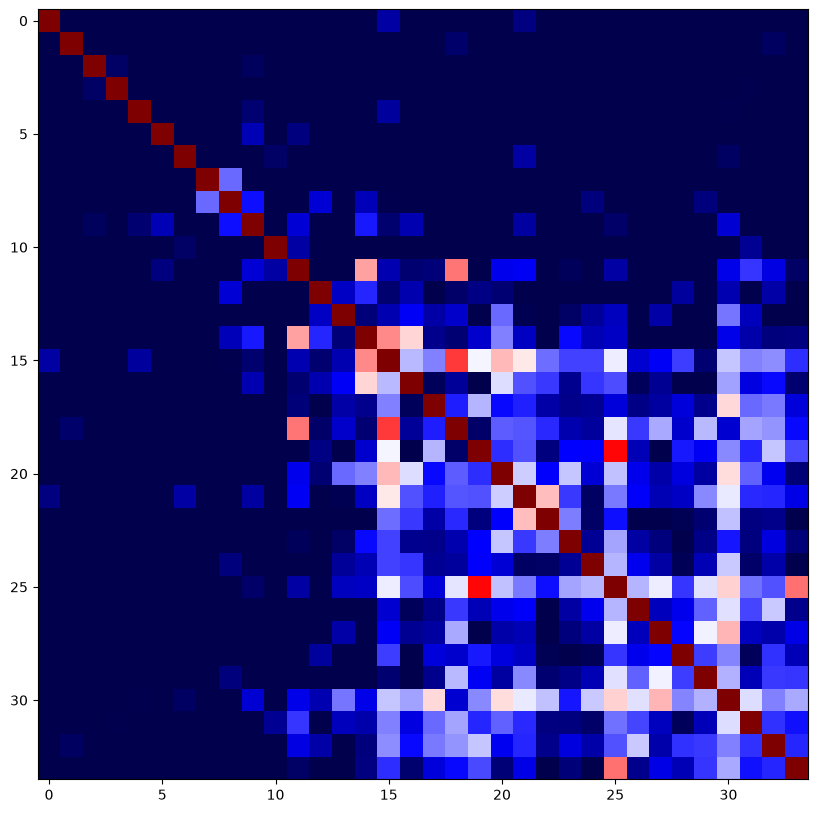

 72%|███████▏  | 87/121 [1:38:33<23:54, 42.19s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__086--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__087--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__087--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:25,  1.64it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(21068), np.int64(8656)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__087--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__087--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 740/740 [00:02<00:00, 302.98it/s]


fraction the same: 0.9536963434022258
fraction nan: 0.07384737678855326
EM iteration number:  4



100%|██████████| 740/740 [00:02<00:00, 302.84it/s]


fraction the same: 0.9794912559618442
fraction nan: 0.07384737678855326


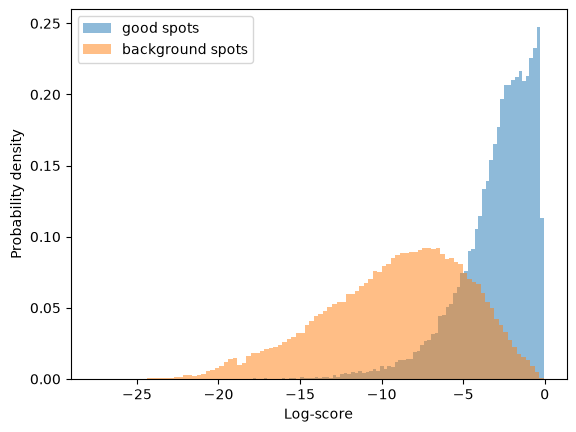

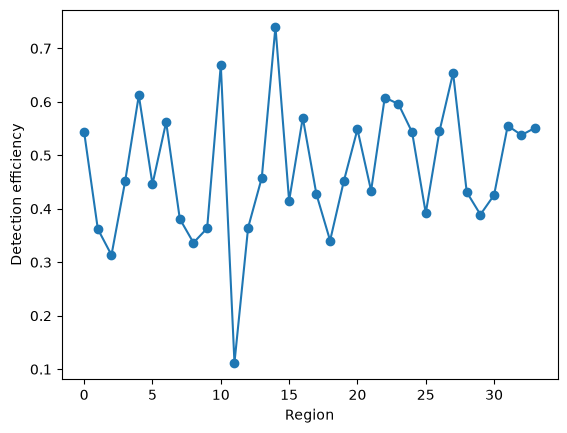

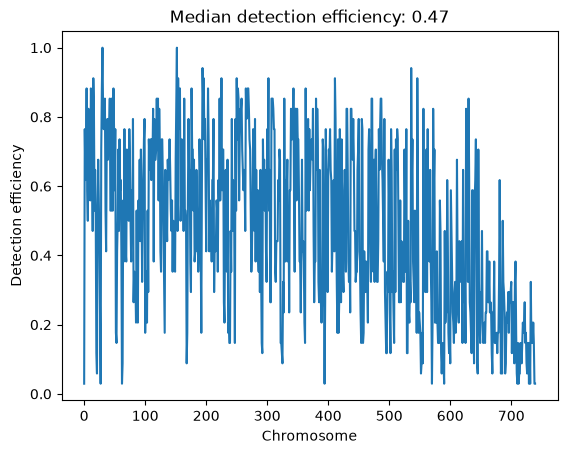

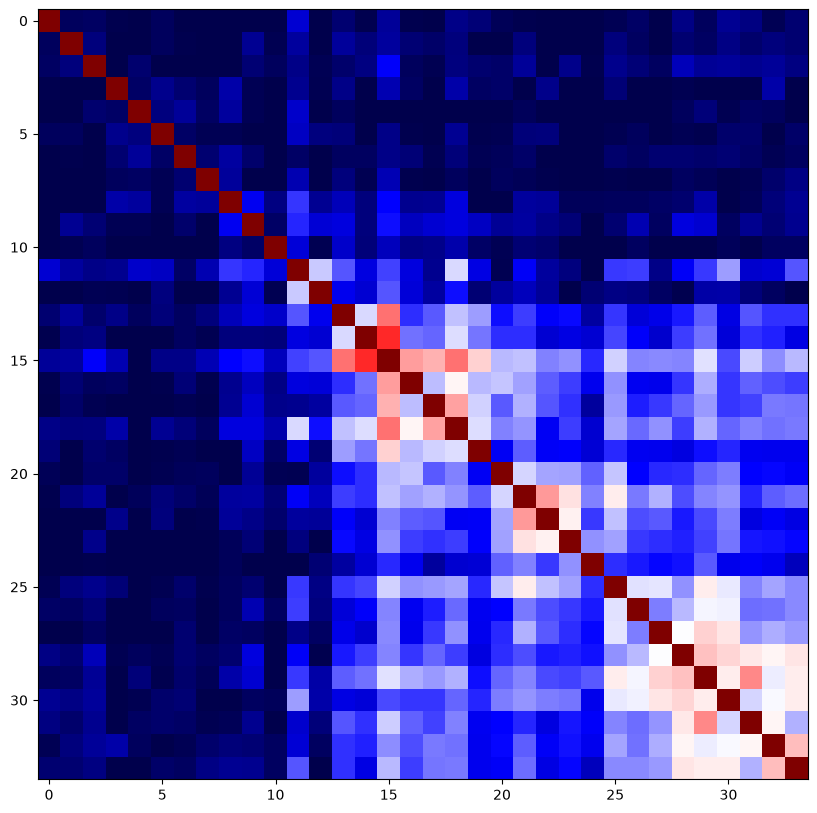

 73%|███████▎  | 88/121 [1:39:27<25:14, 45.89s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__087--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__088--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__088--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:23,  1.77it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(2336), np.int64(2045)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__088--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__088--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 911/911 [00:02<00:00, 332.58it/s]


fraction the same: 0.9599018531671725
fraction nan: 0.30561115774520564
EM iteration number:  4



100%|██████████| 911/911 [00:02<00:00, 367.92it/s]


fraction the same: 0.9812423322786854
fraction nan: 0.30561115774520564


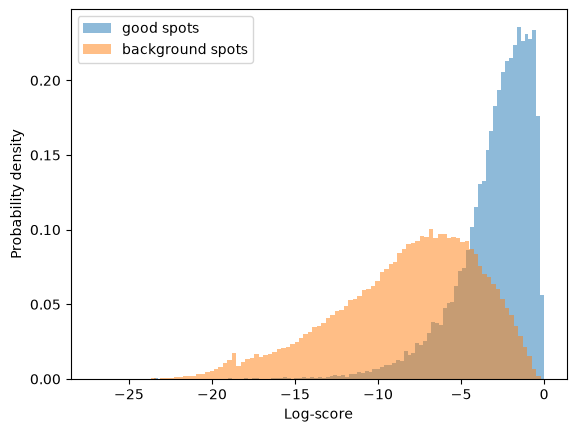

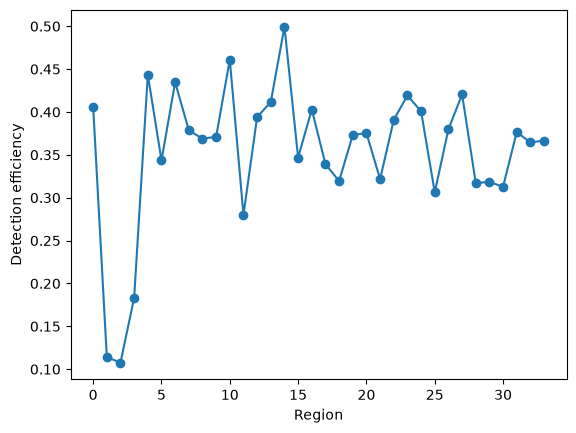

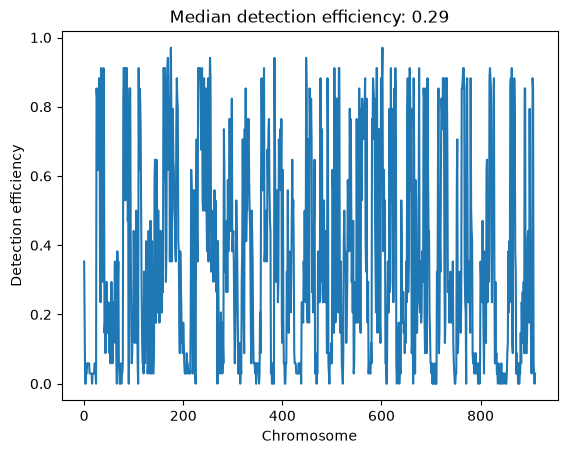

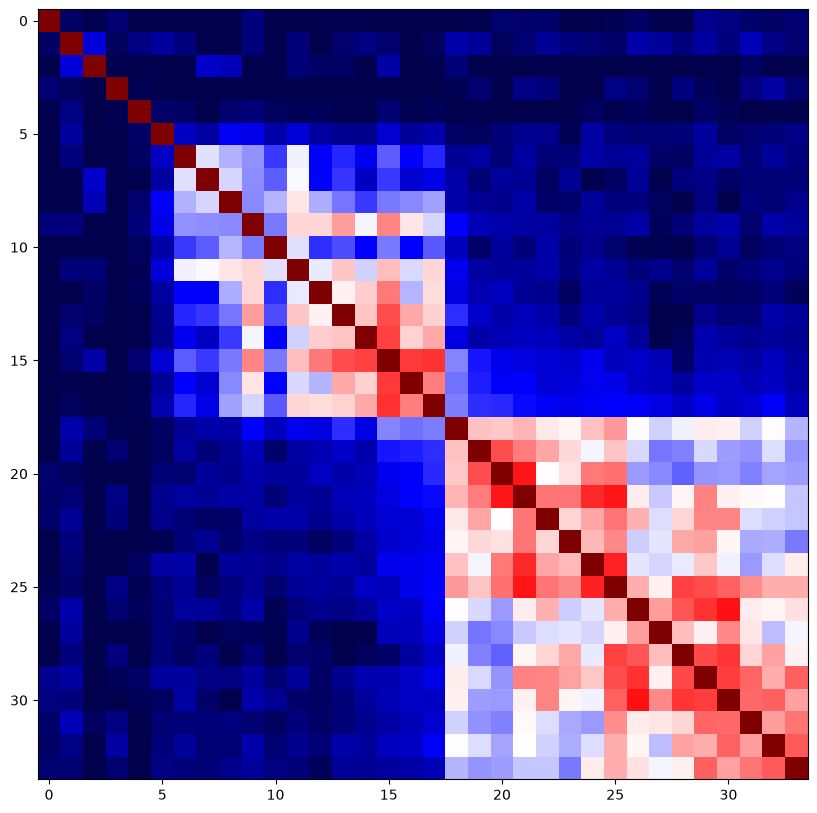

 74%|███████▎  | 89/121 [1:40:32<27:24, 51.39s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__088--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__089--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__089--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:20,  2.00it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(9485), np.int64(3283)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__089--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__089--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 347/347 [00:01<00:00, 340.84it/s]


fraction the same: 0.950330564502458
fraction nan: 0.0934904221054416
EM iteration number:  4



100%|██████████| 347/347 [00:01<00:00, 340.82it/s]


fraction the same: 0.9797423292083404
fraction nan: 0.0934904221054416


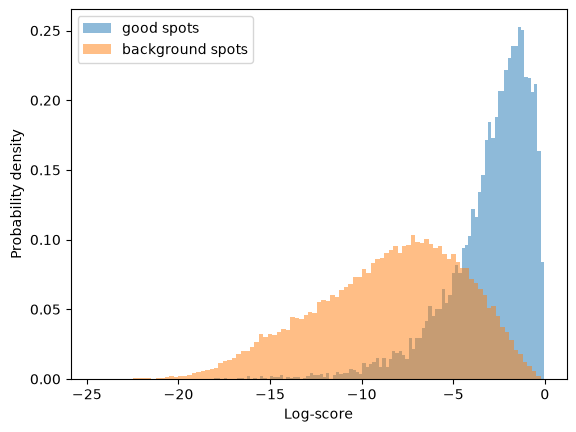

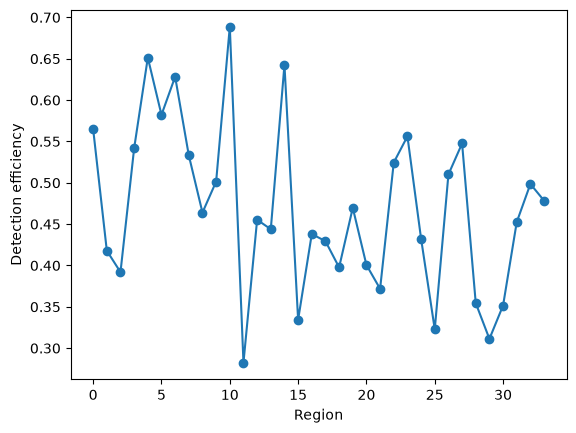

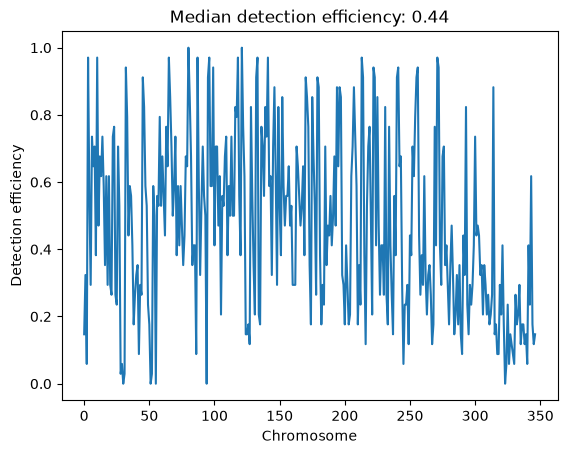

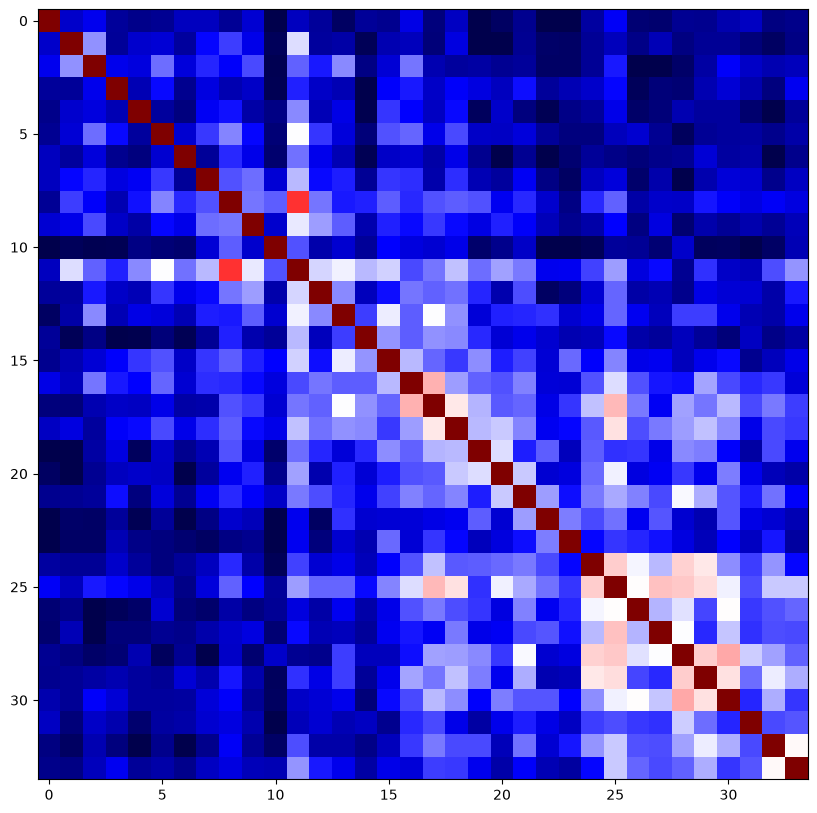

 74%|███████▍  | 90/121 [1:41:10<24:27, 47.35s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__089--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__090--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__090--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:19,  2.13it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(2919), np.int64(2693)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__090--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__090--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 586/586 [00:00<00:00, 705.46it/s]


fraction the same: 0.9852439269223048
fraction nan: 0.6233186107207388
EM iteration number:  4



100%|██████████| 586/586 [00:00<00:00, 707.58it/s]


fraction the same: 0.9932744428829552
fraction nan: 0.6233186107207388


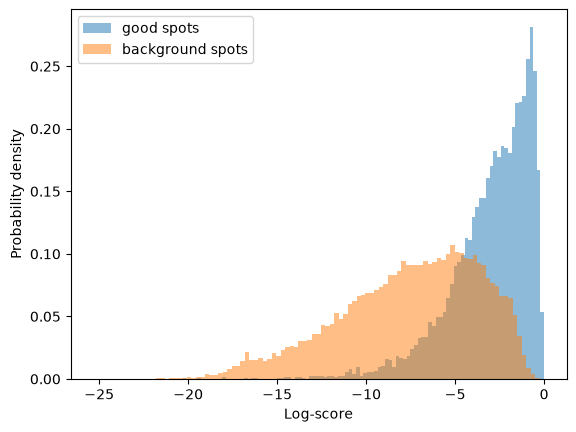

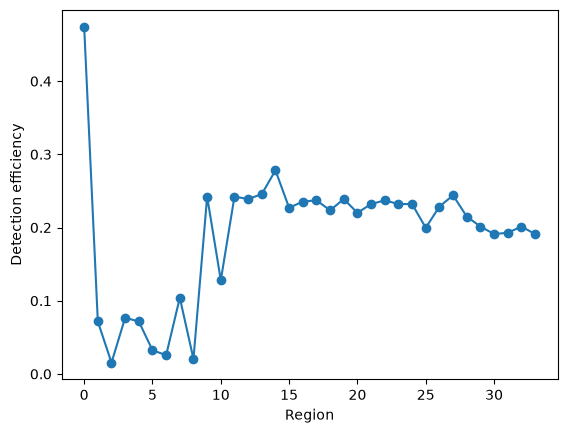

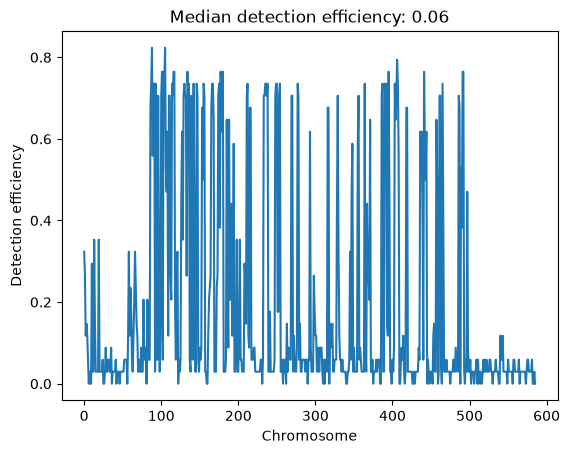

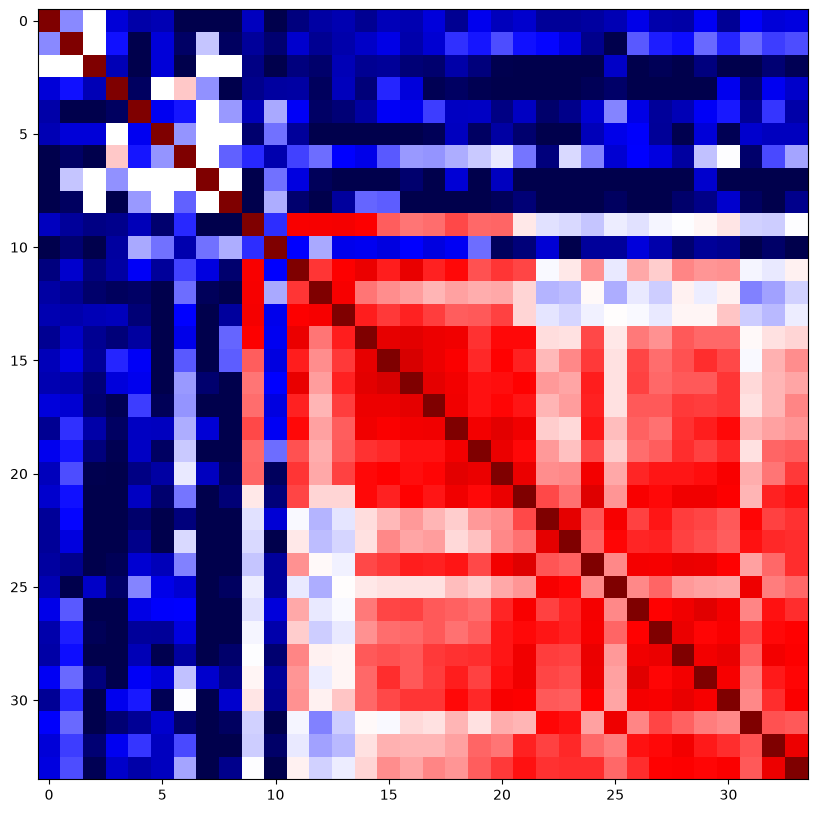

 75%|███████▌  | 91/121 [1:41:54<23:14, 46.48s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__090--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__091--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__091--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.45it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(11337), np.int64(6561)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__091--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__091--H10_NC_set1--dapiFeatures.npz


... (180 outputs left out)


100%|██████████| 282/282 [00:00<00:00, 316.16it/s]


fraction the same: 0.950250312891114
fraction nan: 0.06967042136003337
EM iteration number:  4



100%|██████████| 282/282 [00:00<00:00, 321.45it/s]


fraction the same: 0.9756987901543596
fraction nan: 0.06967042136003337


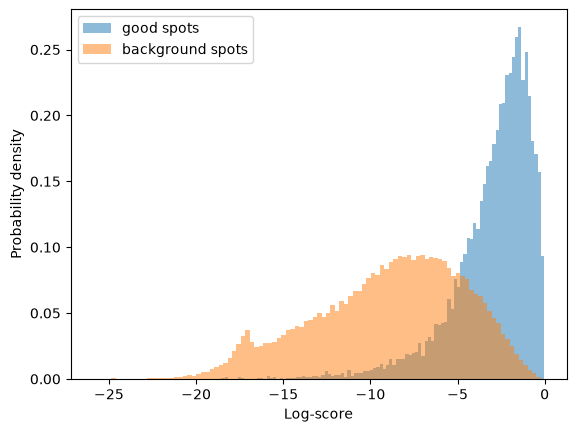

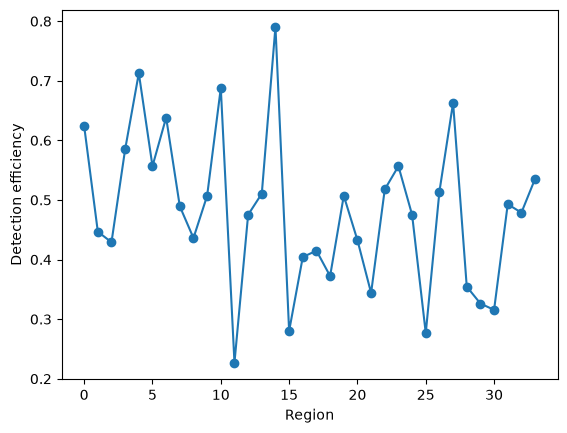

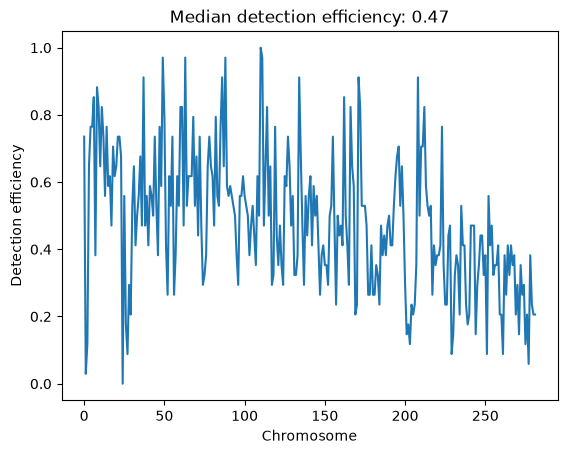

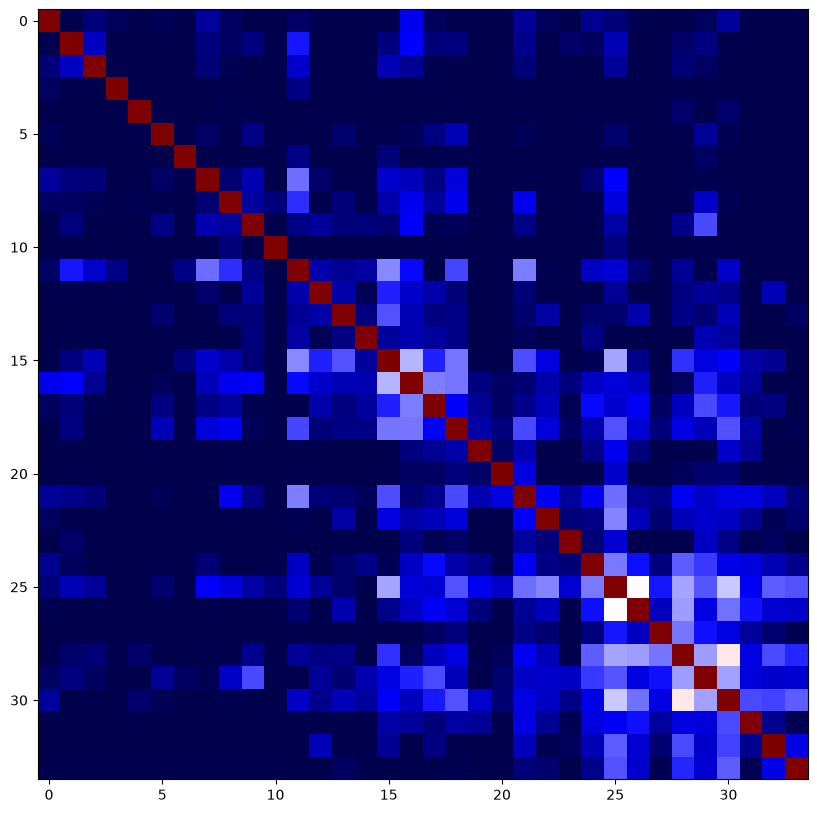

 77%|███████▋  | 93/121 [1:43:00<18:31, 39.70s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__092--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__093--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__093--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(7271), np.int64(1579)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__093--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__093--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 15/15 [00:00<00:00, 481.90it/s]


fraction the same: 0.9098039215686274
fraction nan: 0.058823529411764705
EM iteration number:  4



100%|██████████| 15/15 [00:00<00:00, 482.86it/s]


fraction the same: 0.9588235294117647
fraction nan: 0.058823529411764705


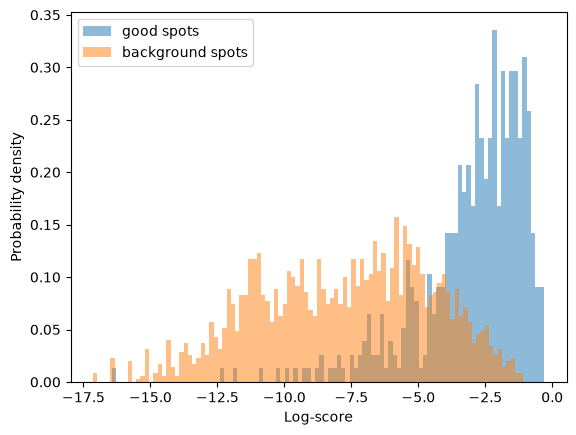

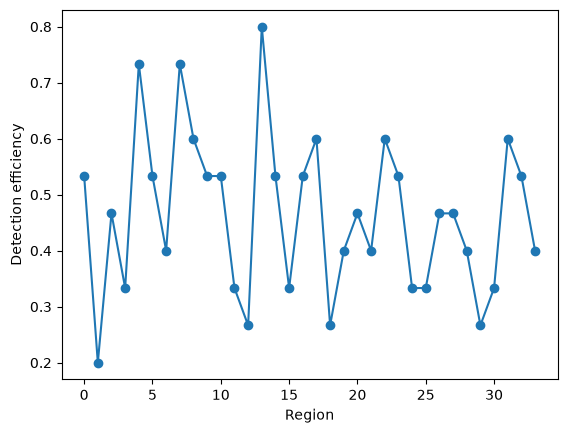

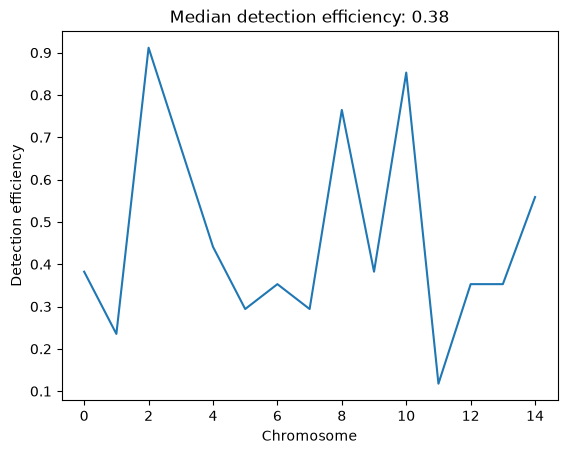

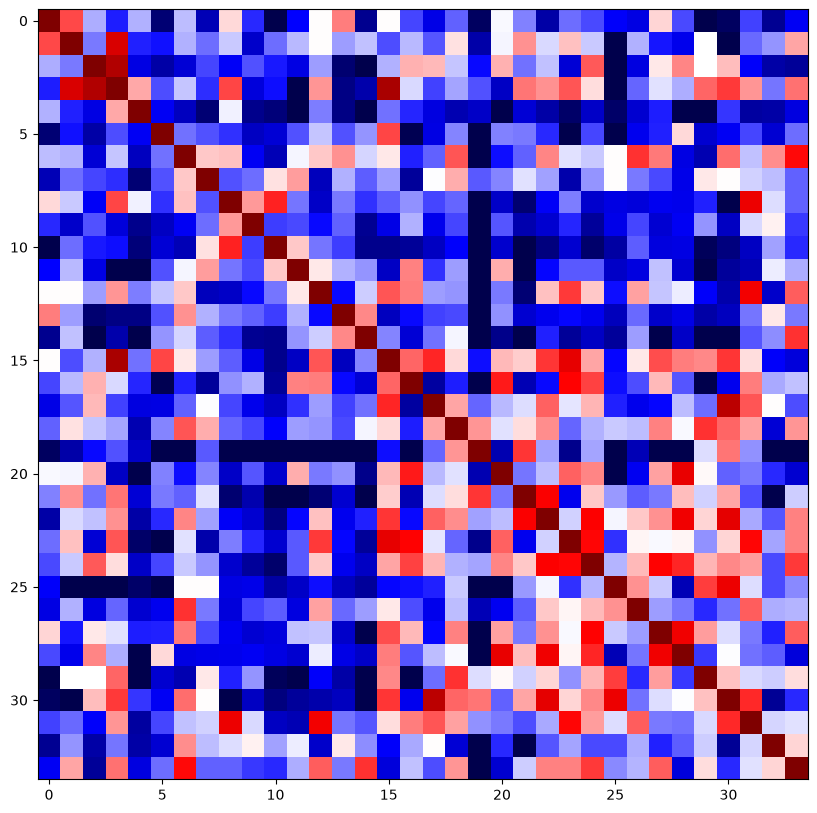

 78%|███████▊  | 94/121 [1:43:30<16:33, 36.81s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__093--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__094--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__094--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.36it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(25279), np.int64(3766)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__094--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__094--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1271/1271 [00:05<00:00, 246.81it/s]


fraction the same: 0.9403434072291387
fraction nan: 0.06412273800157356
EM iteration number:  4



100%|██████████| 1271/1271 [00:04<00:00, 261.86it/s]


fraction the same: 0.9732262692645902
fraction nan: 0.06412273800157356


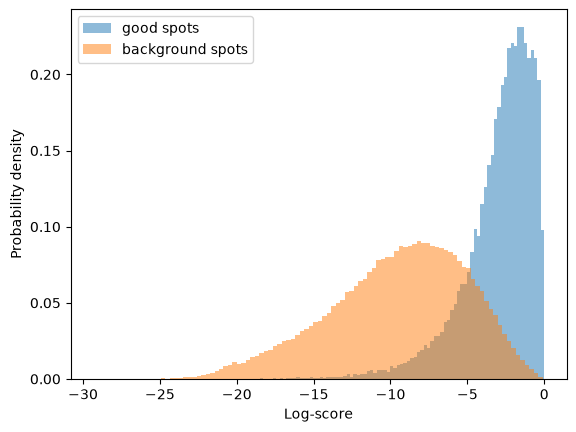

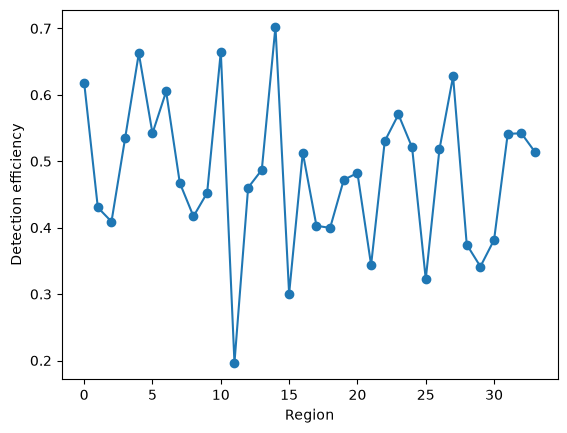

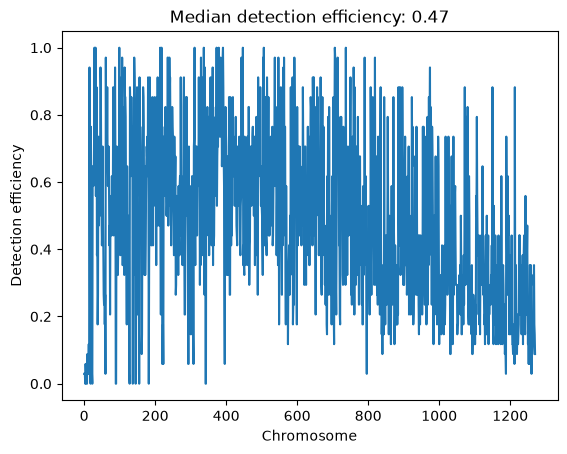

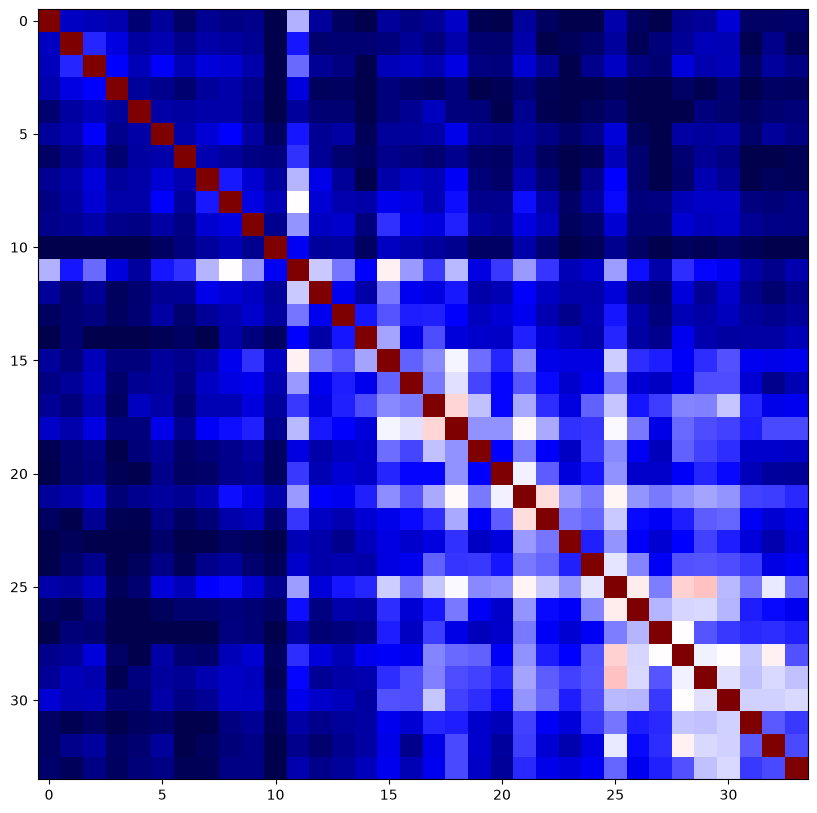

 79%|███████▊  | 95/121 [1:44:58<22:42, 52.39s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__094--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__095--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__095--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.31it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24886), np.int64(4558)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__095--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__095--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1135/1135 [00:04<00:00, 249.44it/s]


fraction the same: 0.943586421352682
fraction nan: 0.056413578647317955
EM iteration number:  4



100%|██████████| 1135/1135 [00:04<00:00, 266.06it/s]


fraction the same: 0.9749157812904897
fraction nan: 0.056413578647317955


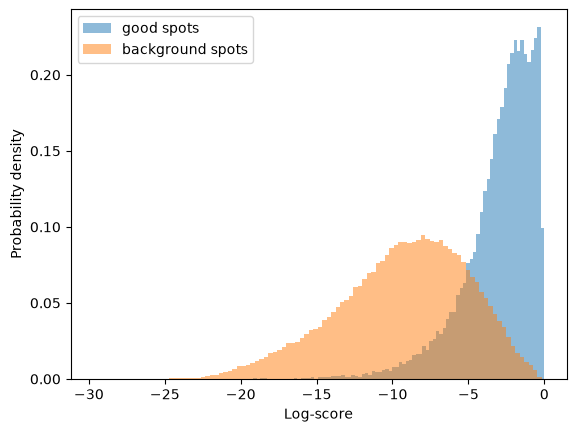

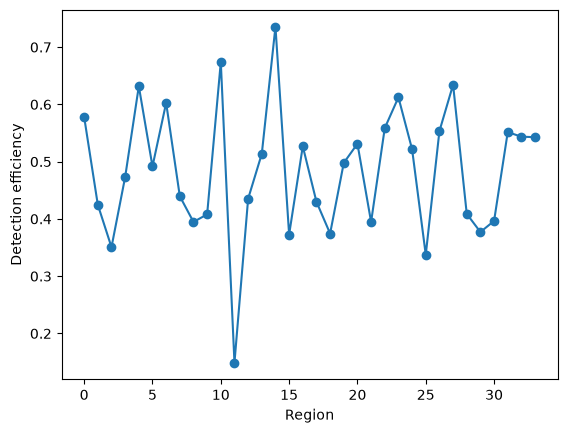

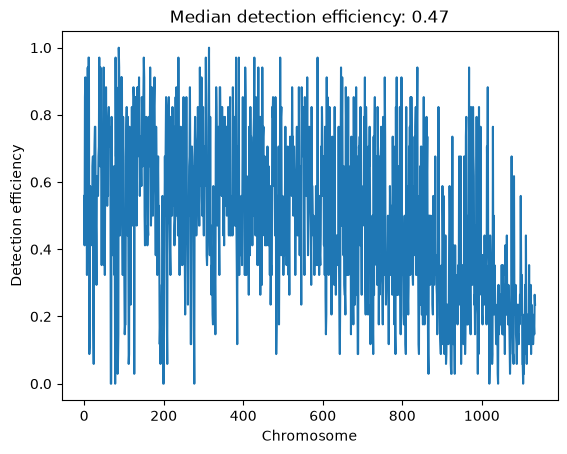

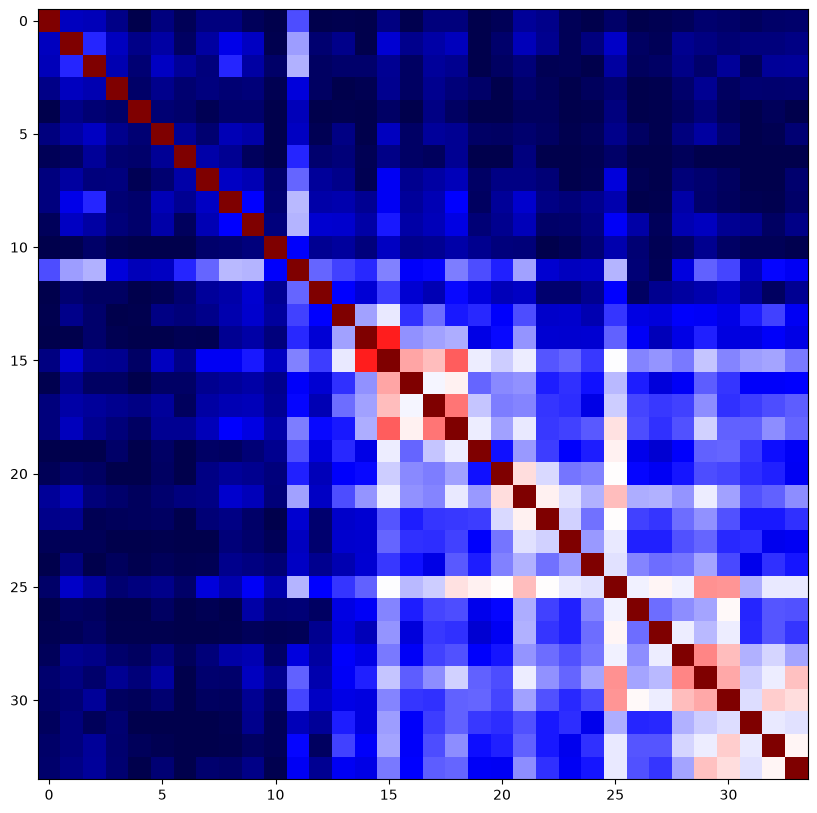

 79%|███████▉  | 96/121 [1:46:20<25:30, 61.21s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__095--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__096--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__096--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.25it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(26326), np.int64(4038)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__096--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__096--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1351/1351 [00:05<00:00, 242.89it/s]


fraction the same: 0.9492315060739321
fraction nan: 0.047350546436191056
EM iteration number:  4



100%|██████████| 1351/1351 [00:05<00:00, 256.68it/s]


fraction the same: 0.9787303522445248
fraction nan: 0.047350546436191056


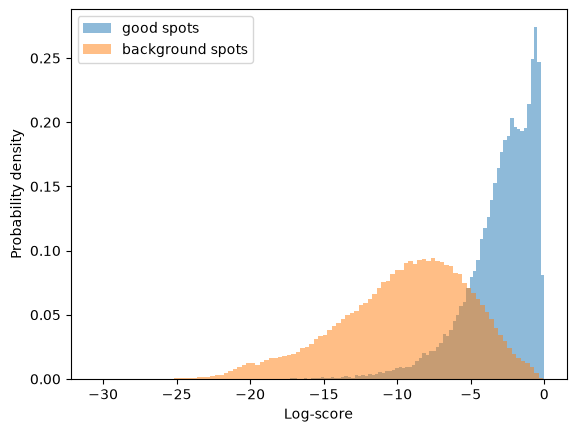

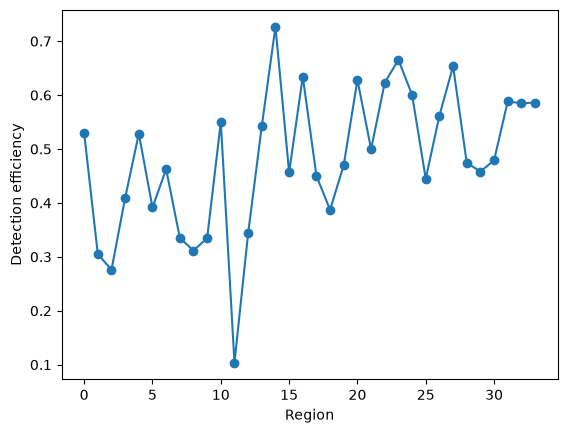

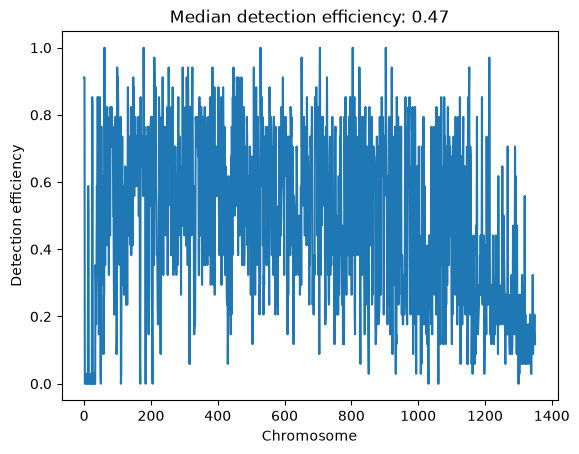

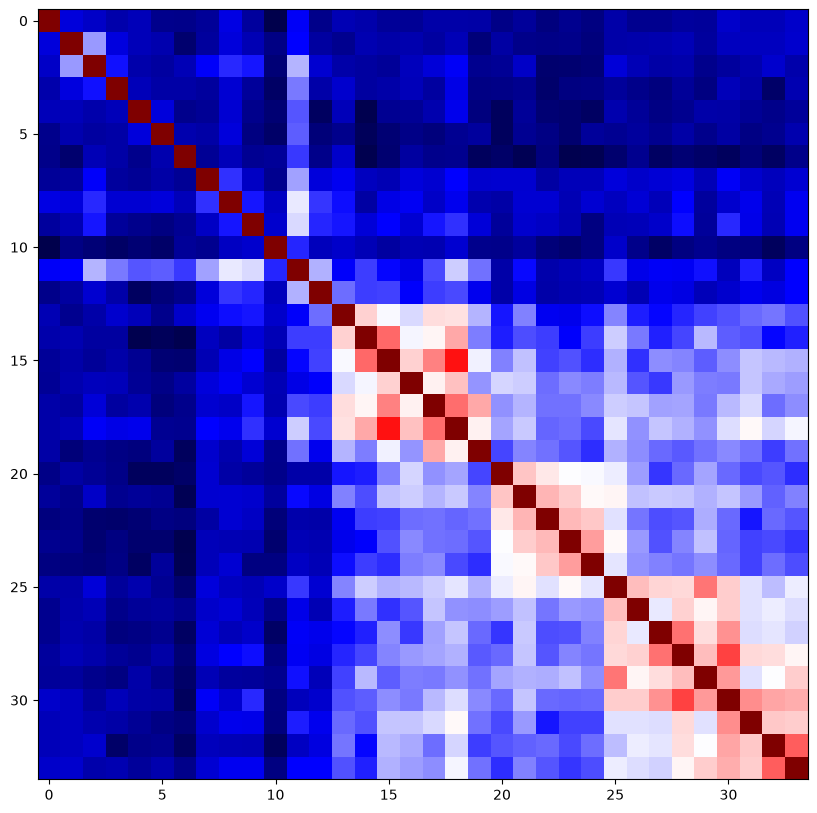

 80%|████████  | 97/121 [1:47:56<28:40, 71.69s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__096--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__097--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__097--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(17857), np.int64(3735)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__097--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__097--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 404/404 [00:01<00:00, 310.93it/s]


fraction the same: 0.9517326732673267
fraction nan: 0.06850611531741409
EM iteration number:  4



100%|██████████| 404/404 [00:01<00:00, 316.60it/s]


fraction the same: 0.9801980198019802
fraction nan: 0.06850611531741409


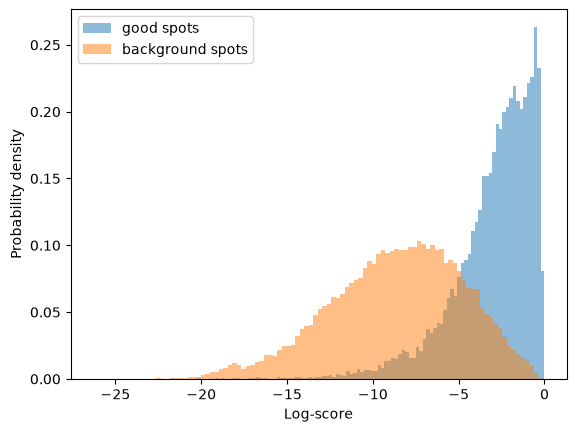

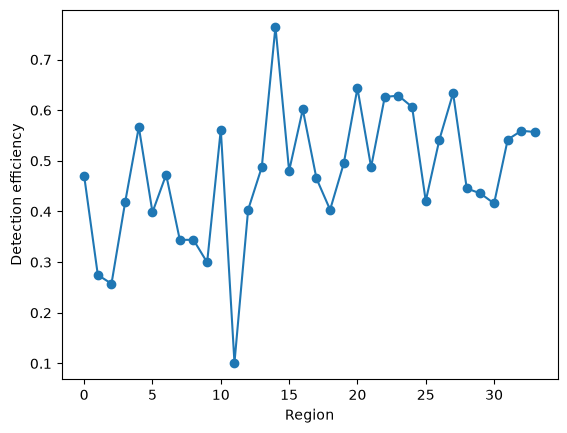

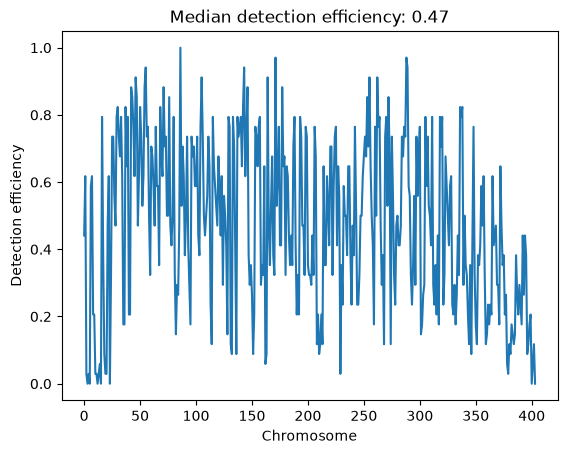

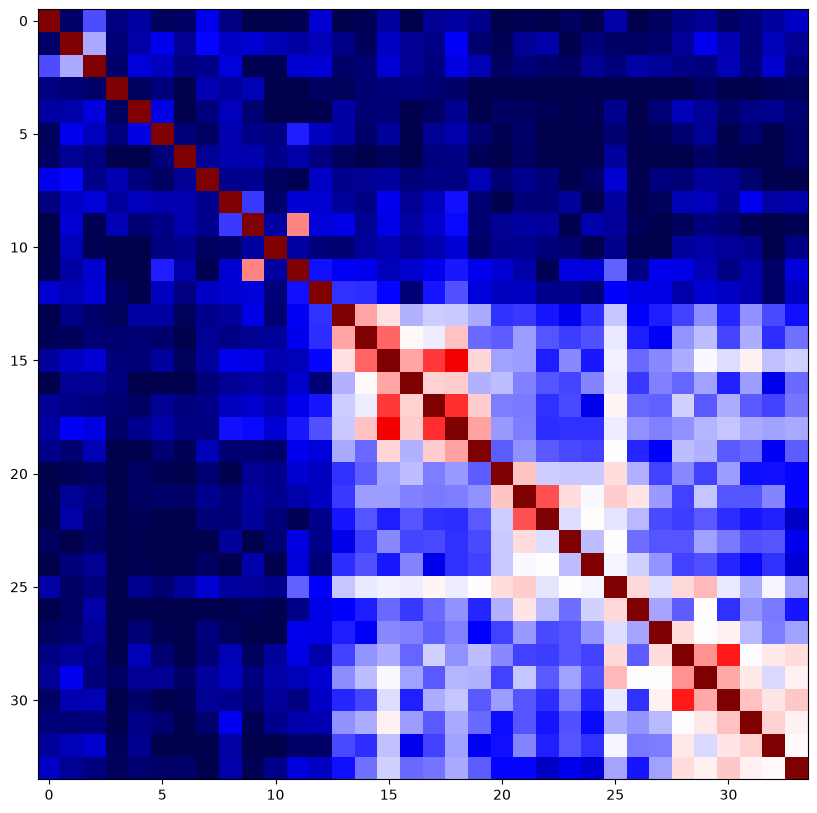

 81%|████████  | 98/121 [1:48:45<24:50, 64.81s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__097--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__098--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__098--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.30it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(21795), np.int64(4800)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__098--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__098--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 473/473 [00:01<00:00, 307.86it/s]


fraction the same: 0.9513120258674295
fraction nan: 0.06672055714463375
EM iteration number:  4



100%|██████████| 473/473 [00:01<00:00, 308.41it/s]


fraction the same: 0.9782365377440617
fraction nan: 0.06672055714463375


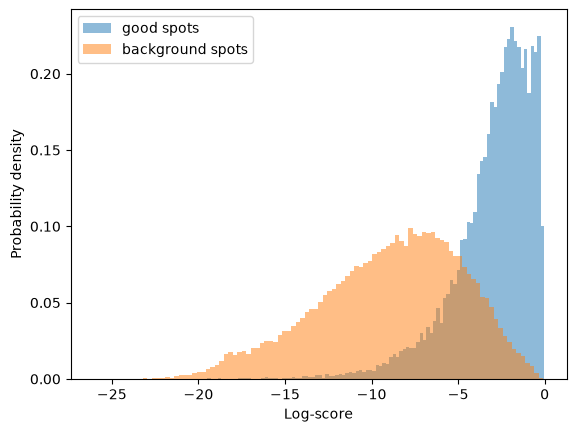

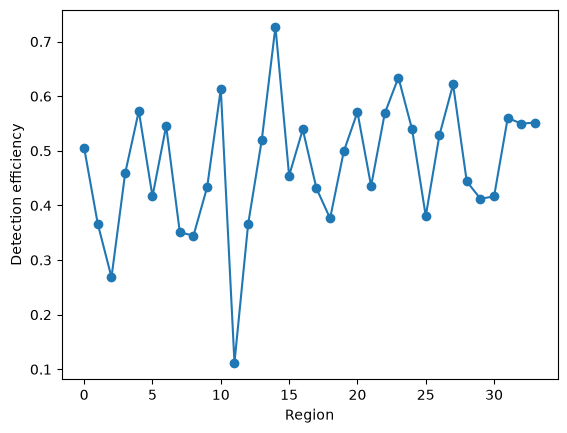

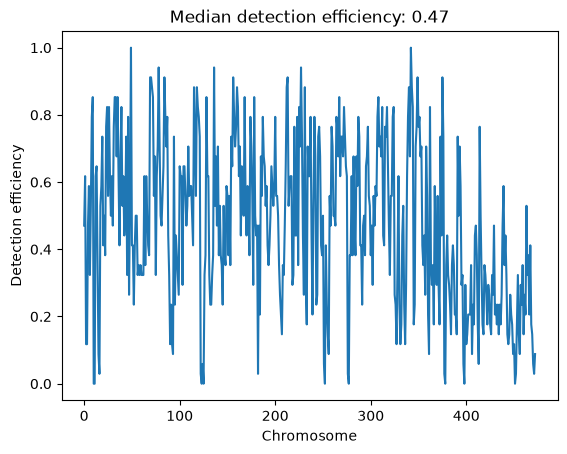

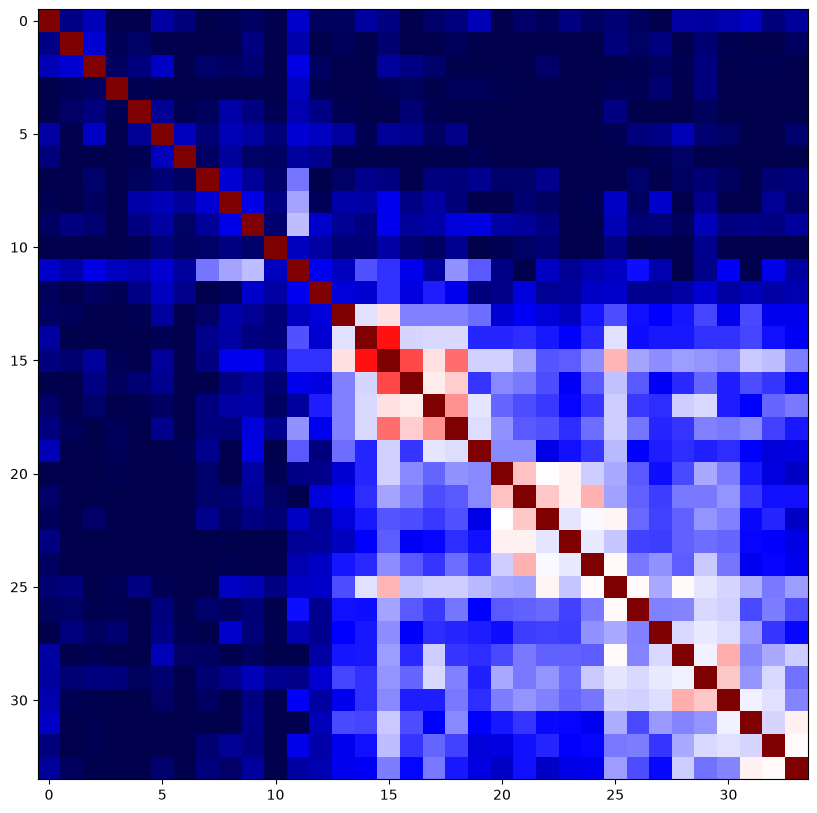

 82%|████████▏ | 99/121 [1:49:38<22:26, 61.22s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__098--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__099--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__099--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.36it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(23518), np.int64(7102)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__099--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__099--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 541/541 [00:01<00:00, 316.58it/s]


fraction the same: 0.9601500489289986
fraction nan: 0.08263564205719257
EM iteration number:  4



100%|██████████| 541/541 [00:01<00:00, 317.21it/s]


fraction the same: 0.9824399260628466
fraction nan: 0.08263564205719257


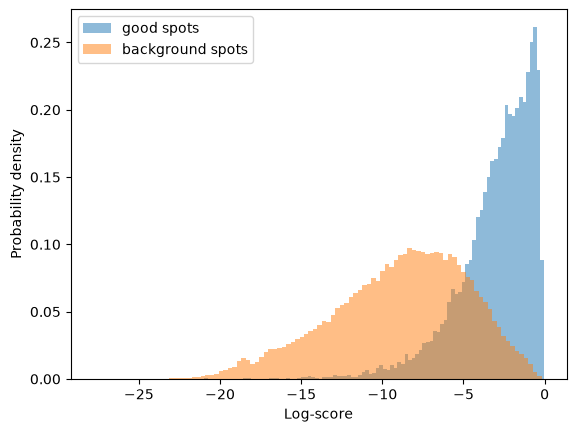

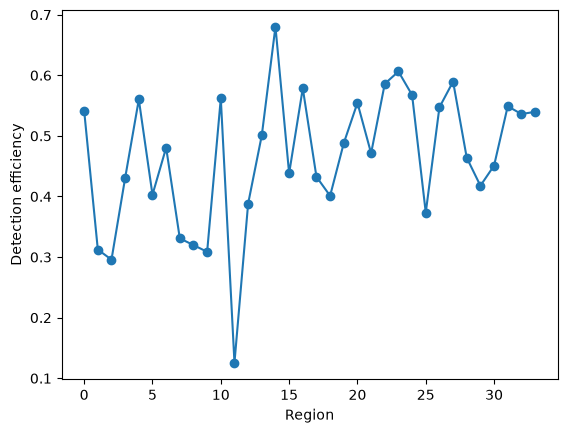

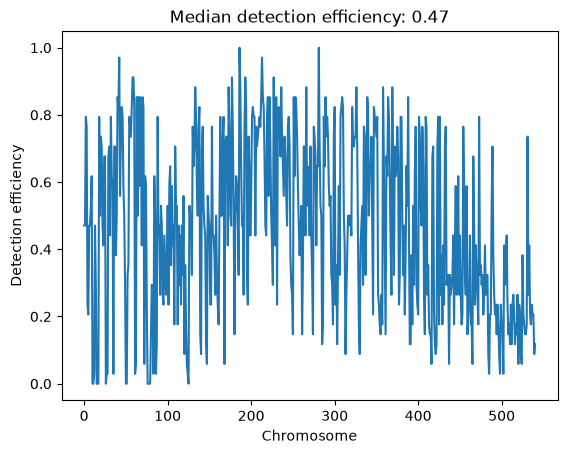

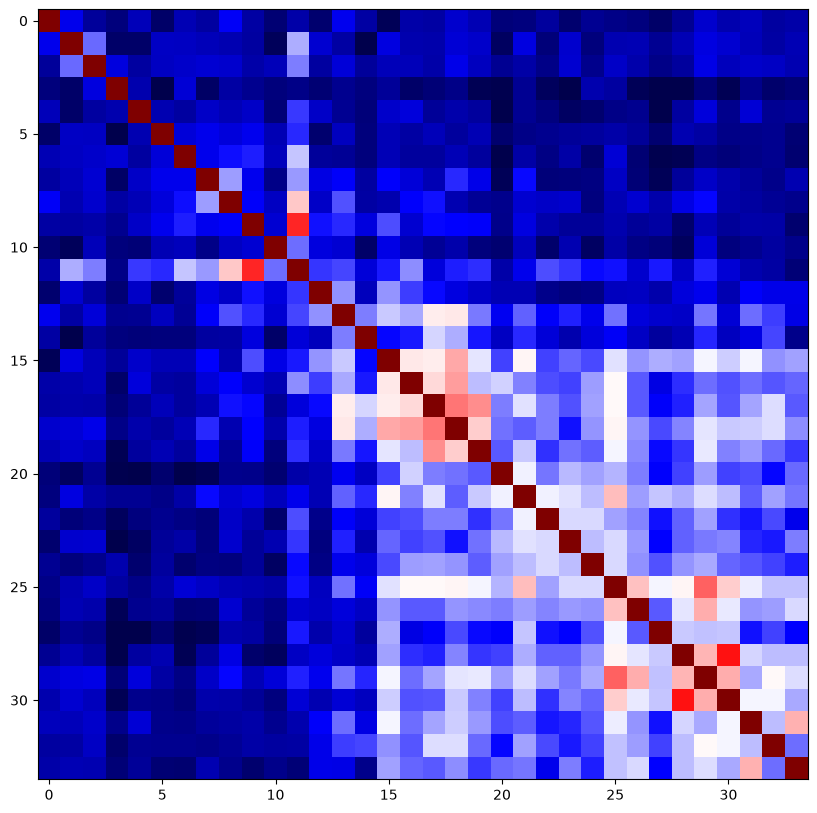

 83%|████████▎ | 100/121 [1:50:29<20:22, 58.21s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__099--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__100--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__100--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(25819), np.int64(6100)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__100--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__100--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 662/662 [00:02<00:00, 270.47it/s]


fraction the same: 0.9543273502754576
fraction nan: 0.053803092233872404
EM iteration number:  4



100%|██████████| 662/662 [00:02<00:00, 272.36it/s]


fraction the same: 0.9799626799360227
fraction nan: 0.053803092233872404


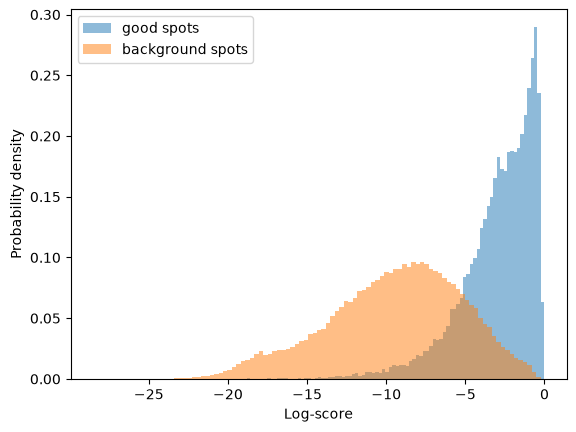

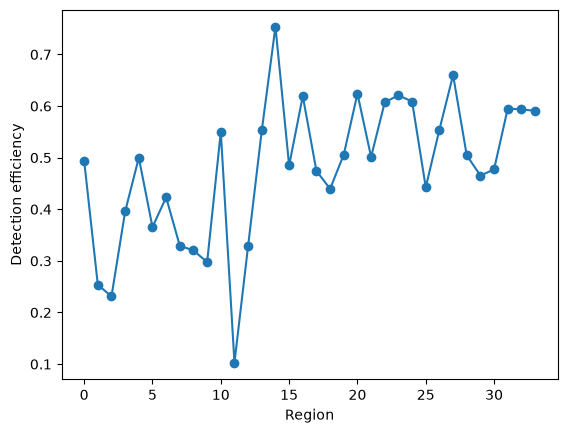

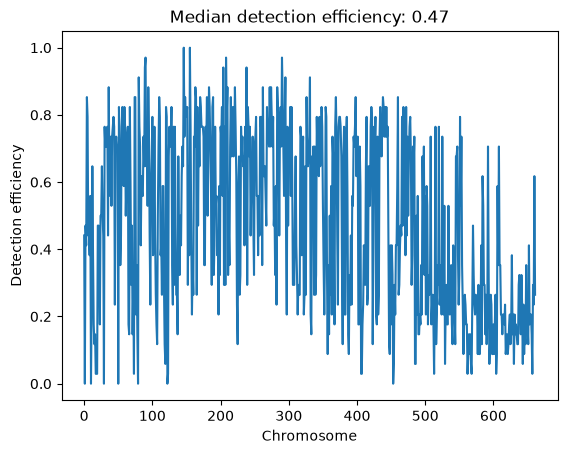

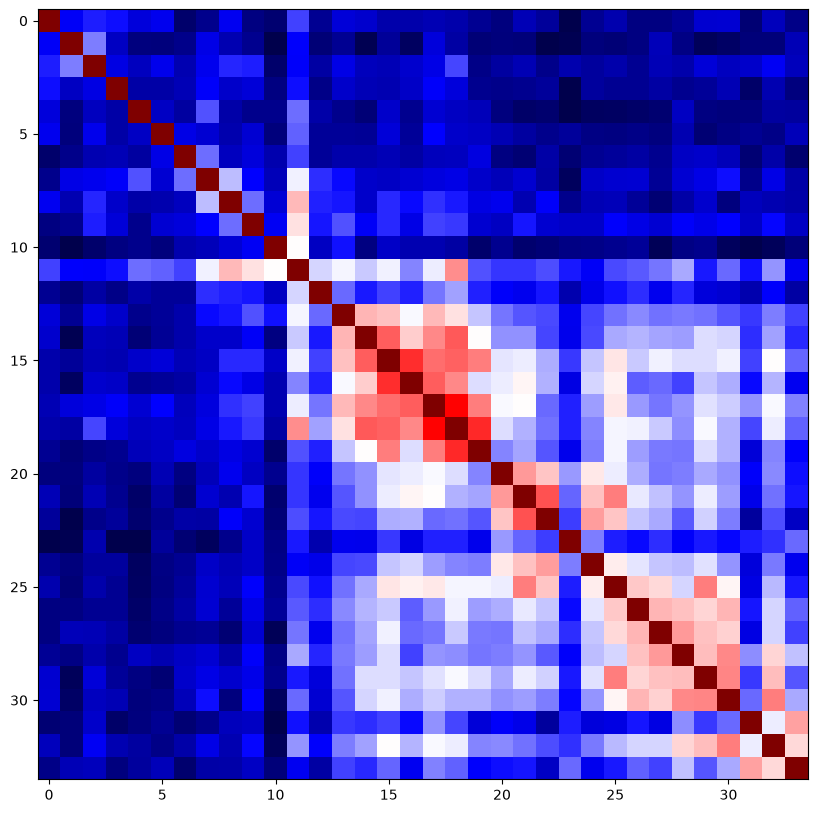

 83%|████████▎ | 101/121 [1:51:29<19:31, 58.56s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__100--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__101--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__101--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.31it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(17784), np.int64(6330)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__101--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__101--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 248/248 [00:00<00:00, 296.84it/s]


fraction the same: 0.9454459203036053
fraction nan: 0.038662239089184064
EM iteration number:  4



100%|██████████| 248/248 [00:00<00:00, 298.28it/s]


fraction the same: 0.9747390891840607
fraction nan: 0.038662239089184064


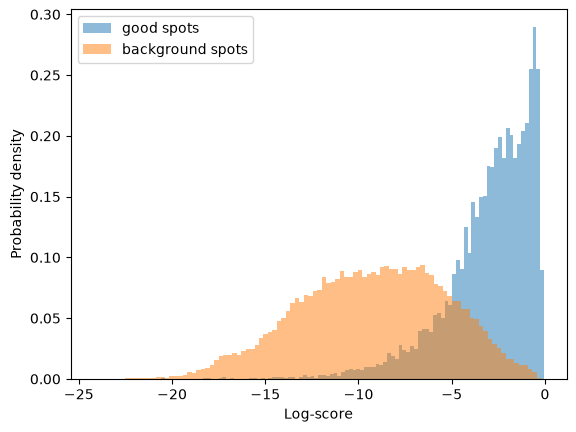

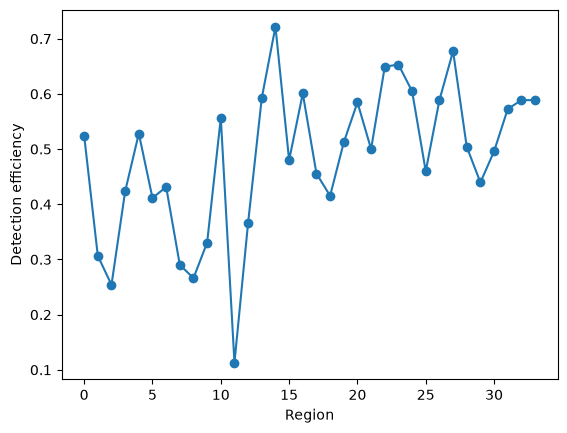

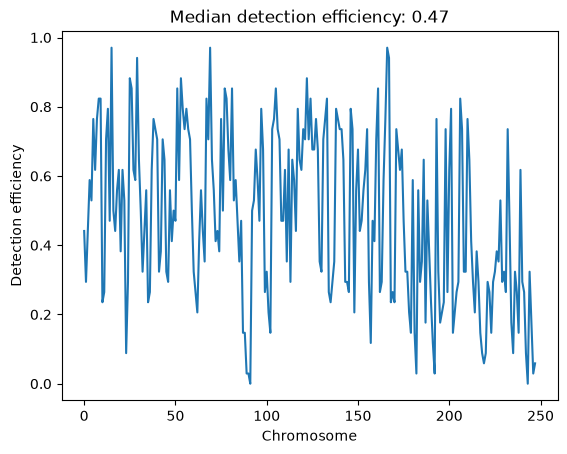

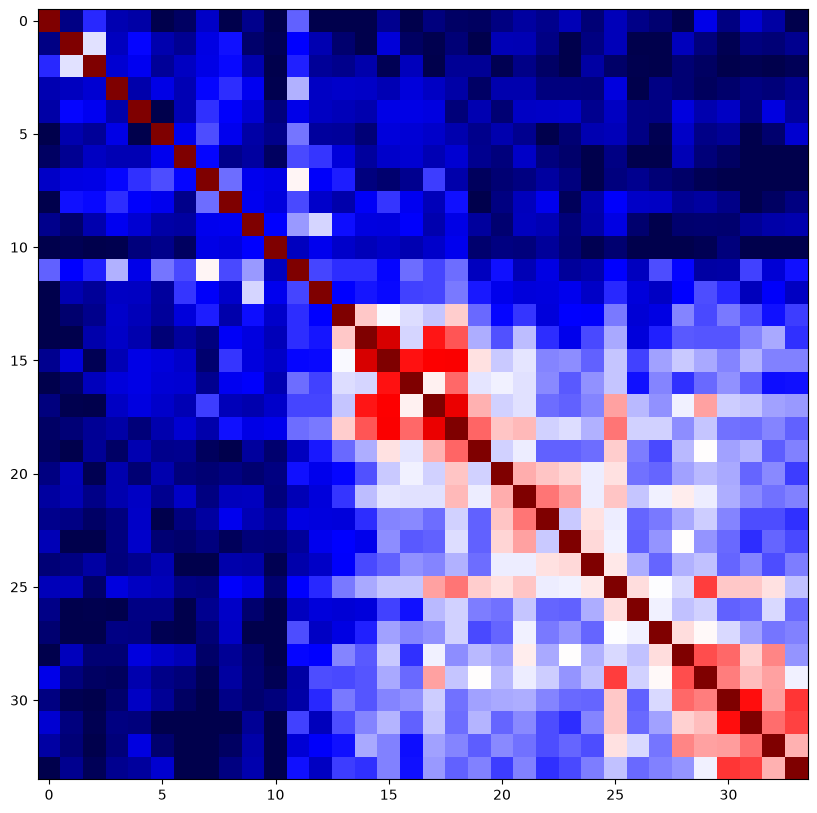

 84%|████████▍ | 102/121 [1:52:13<17:13, 54.42s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__101--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__102--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__102--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:32,  1.25it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28060), np.int64(3261)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__102--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__102--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1678/1678 [00:06<00:00, 250.28it/s]


fraction the same: 0.949221762602538
fraction nan: 0.047605693051952606
EM iteration number:  4



100%|██████████| 1678/1678 [00:06<00:00, 250.83it/s]


fraction the same: 0.9789665568253523
fraction nan: 0.047605693051952606


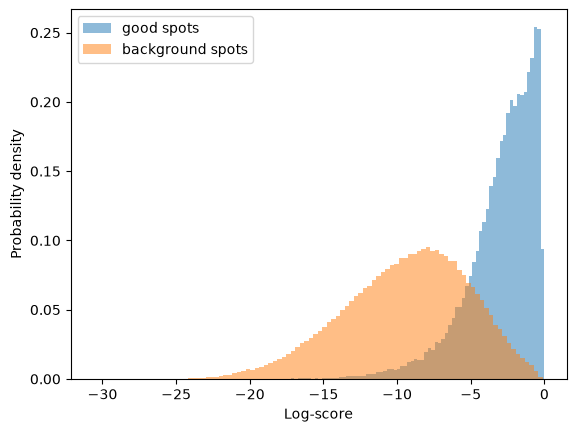

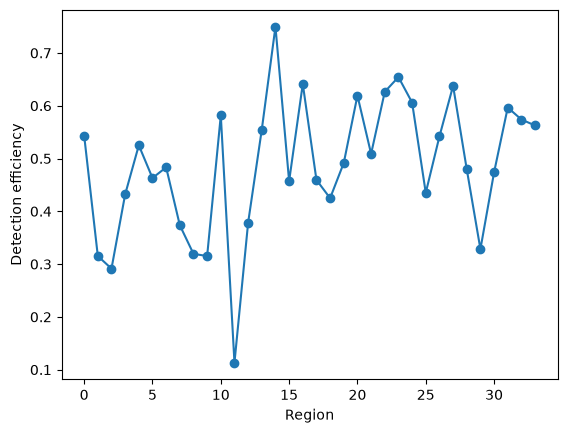

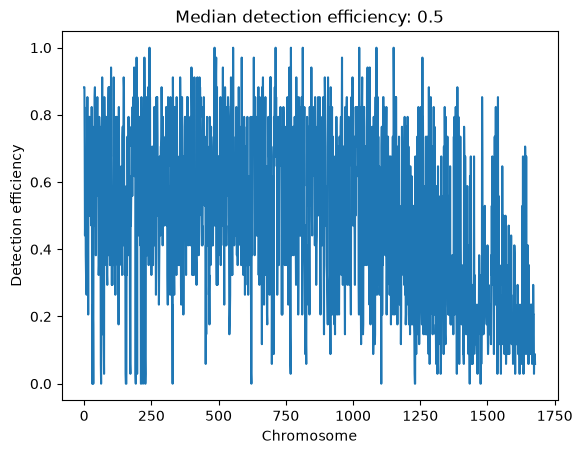

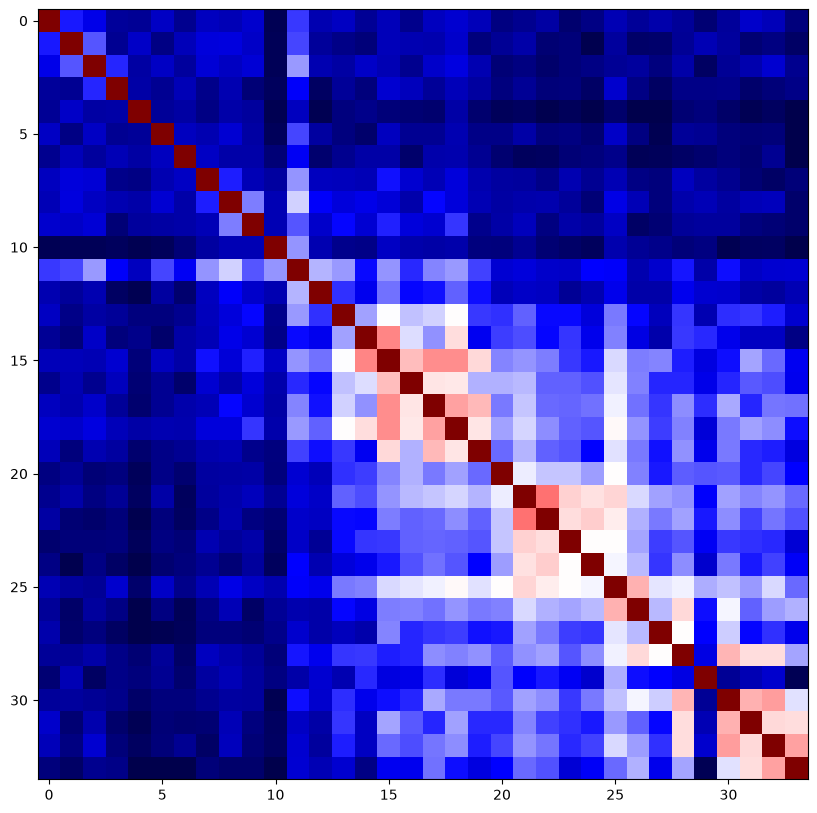

 85%|████████▌ | 103/121 [1:54:09<21:52, 72.94s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__102--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__103--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__103--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19568), np.int64(7916)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__103--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__103--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 375/375 [00:01<00:00, 281.81it/s]


fraction the same: 0.9447843137254902
fraction nan: 0.058980392156862745
EM iteration number:  4



100%|██████████| 375/375 [00:01<00:00, 281.74it/s]


fraction the same: 0.9752941176470589
fraction nan: 0.058980392156862745


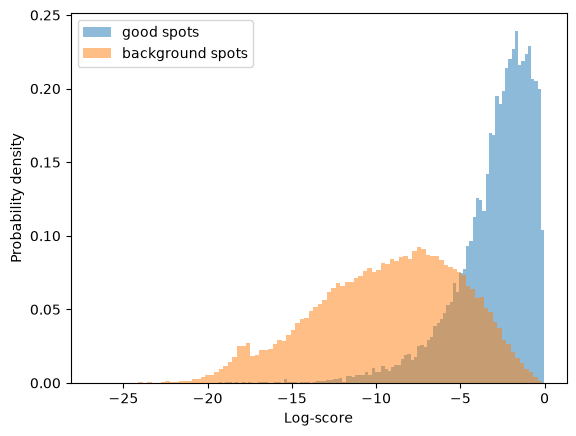

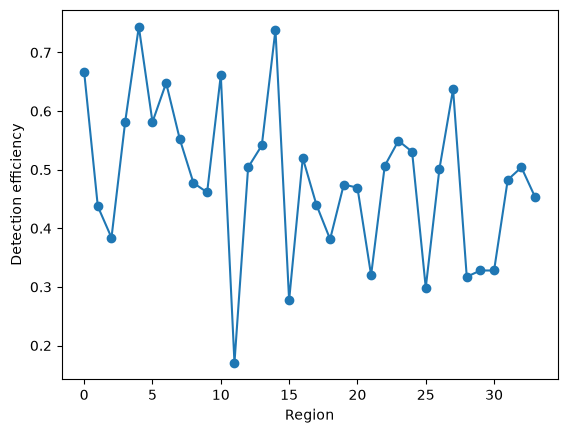

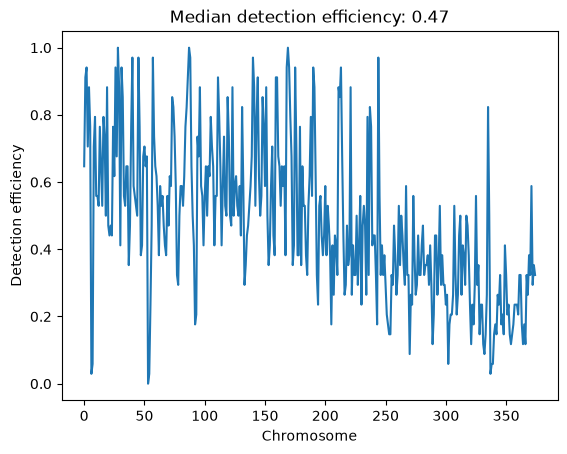

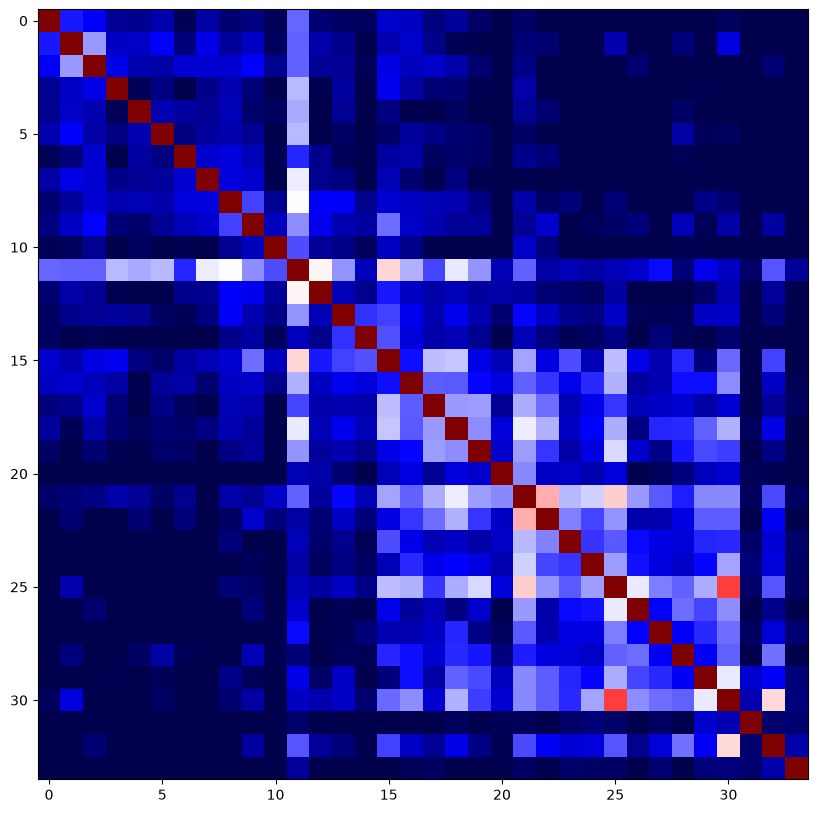

 86%|████████▌ | 104/121 [1:54:56<18:24, 64.94s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__103--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__104--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__104--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.30it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(26580), np.int64(5116)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__104--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__104--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1292/1292 [00:05<00:00, 238.53it/s]


fraction the same: 0.9398333636860317
fraction nan: 0.042979420870515386
EM iteration number:  4



100%|██████████| 1292/1292 [00:05<00:00, 251.20it/s]


fraction the same: 0.9721362229102167
fraction nan: 0.042979420870515386


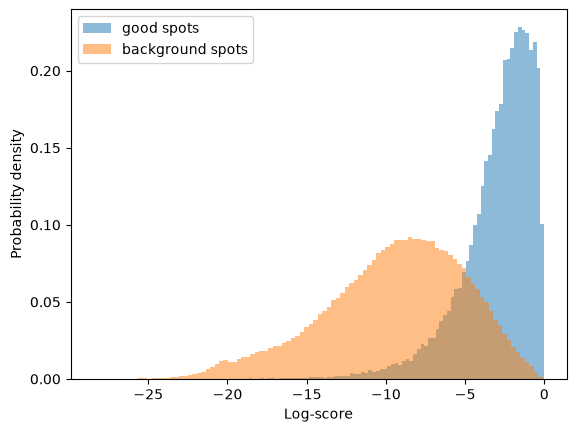

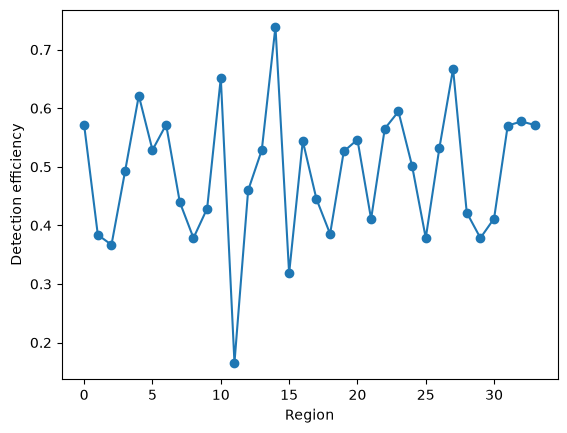

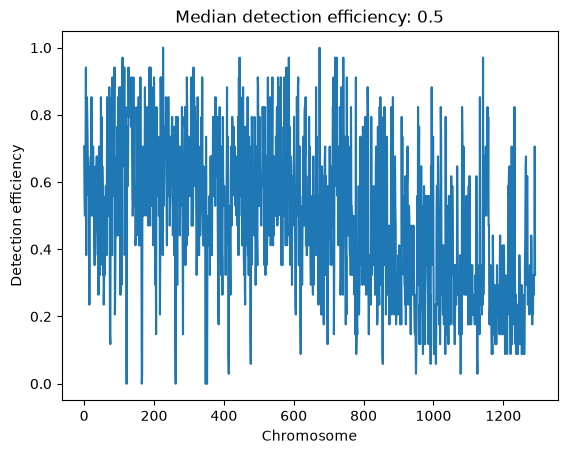

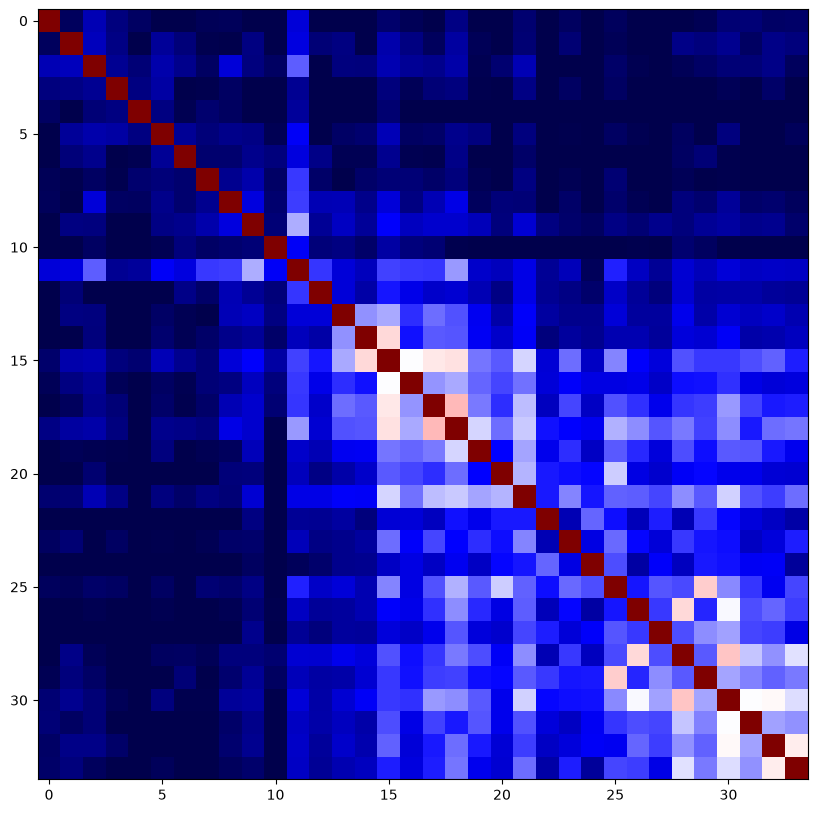

 87%|████████▋ | 105/121 [1:56:30<19:39, 73.74s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__104--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__105--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__105--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:30,  1.36it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(16661), np.int64(4607)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__105--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__105--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 332/332 [00:01<00:00, 268.43it/s]


fraction the same: 0.9346208362863218
fraction nan: 0.04376328844790928
EM iteration number:  4



100%|██████████| 332/332 [00:01<00:00, 267.85it/s]


fraction the same: 0.9707654145995748
fraction nan: 0.04376328844790928


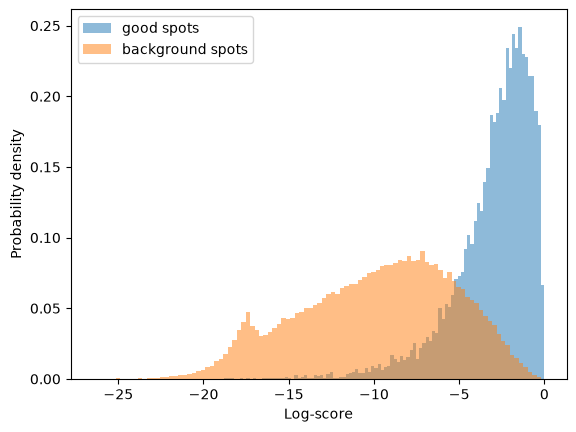

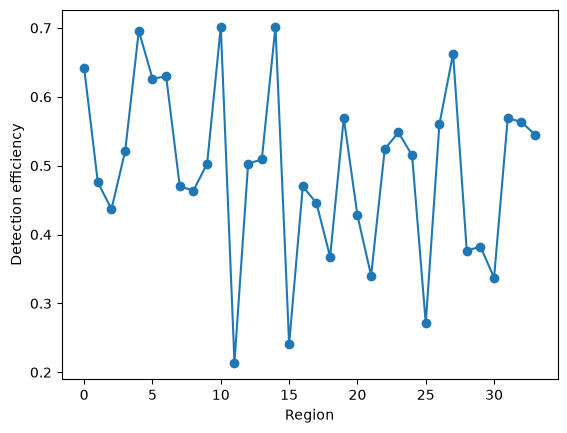

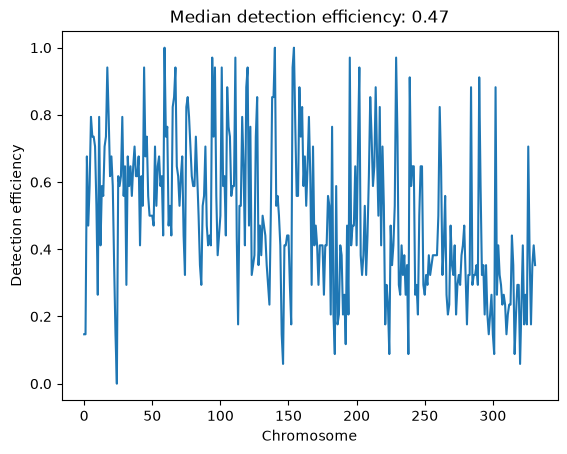

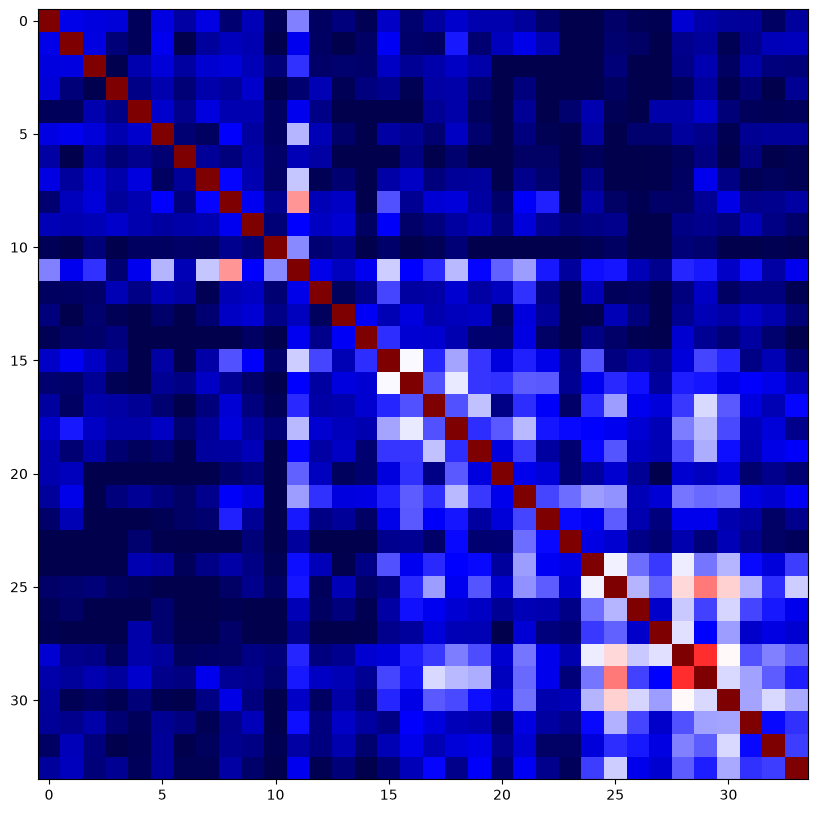

 88%|████████▊ | 106/121 [1:57:16<16:23, 65.57s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__105--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__106--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__106--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:36,  1.12it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(20200), np.int64(6236)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__106--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__106--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 475/475 [00:01<00:00, 288.86it/s]


fraction the same: 0.9443962848297214
fraction nan: 0.06173374613003096
EM iteration number:  4



100%|██████████| 475/475 [00:01<00:00, 288.93it/s]


fraction the same: 0.976532507739938
fraction nan: 0.06173374613003096


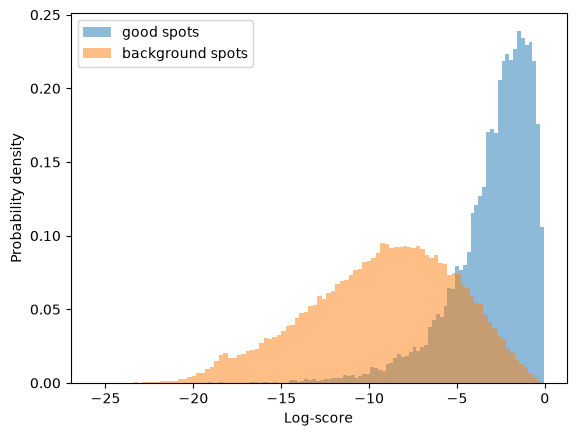

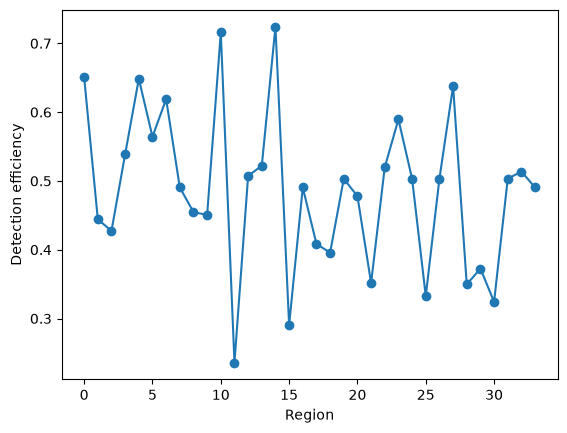

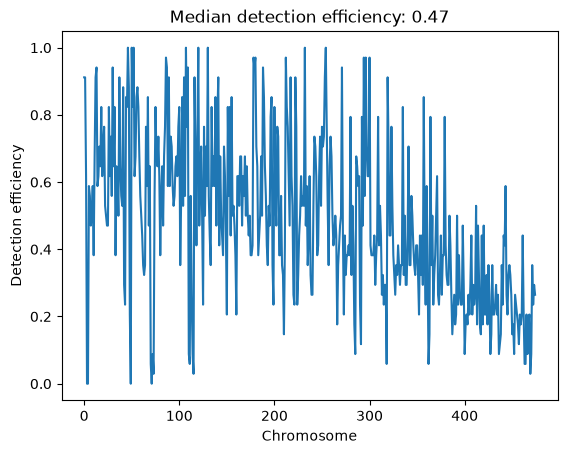

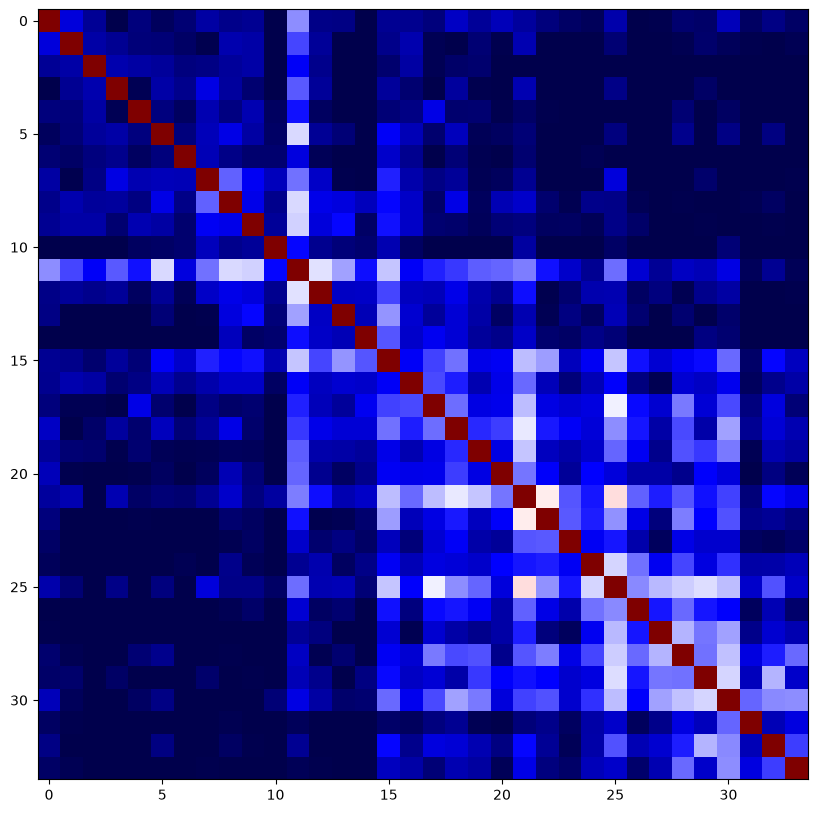

 88%|████████▊ | 107/121 [1:58:11<14:31, 62.26s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__106--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__107--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__107--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:33,  1.23it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(28065), np.int64(3184)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__107--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__107--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1202/1202 [00:04<00:00, 271.26it/s]


fraction the same: 0.9394881080552021
fraction nan: 0.06692277576588039
EM iteration number:  4



100%|██████████| 1202/1202 [00:04<00:00, 271.81it/s]


fraction the same: 0.9723500048938044
fraction nan: 0.06692277576588039


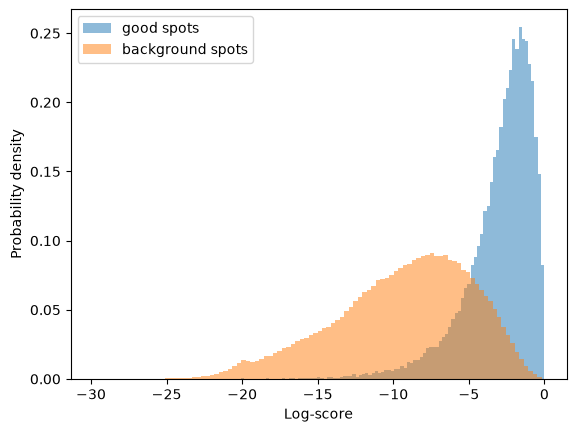

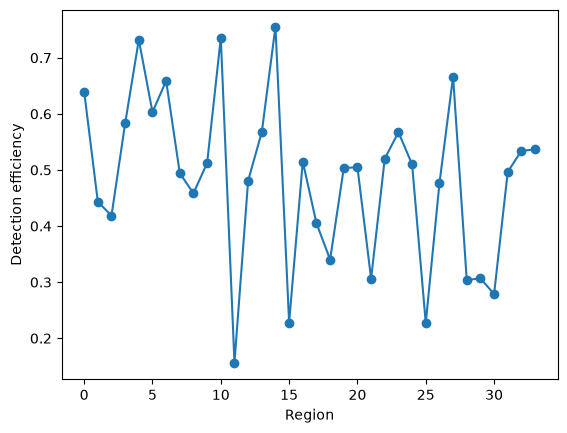

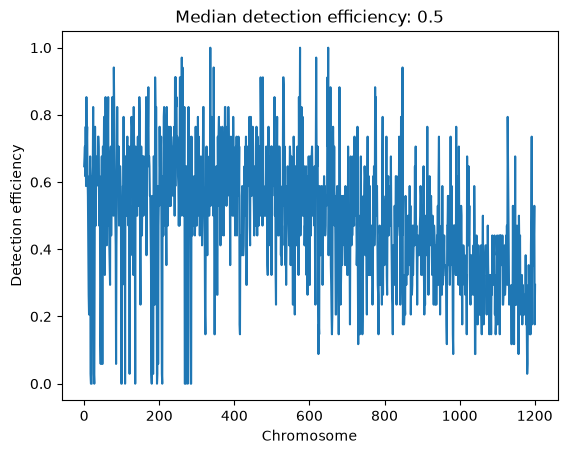

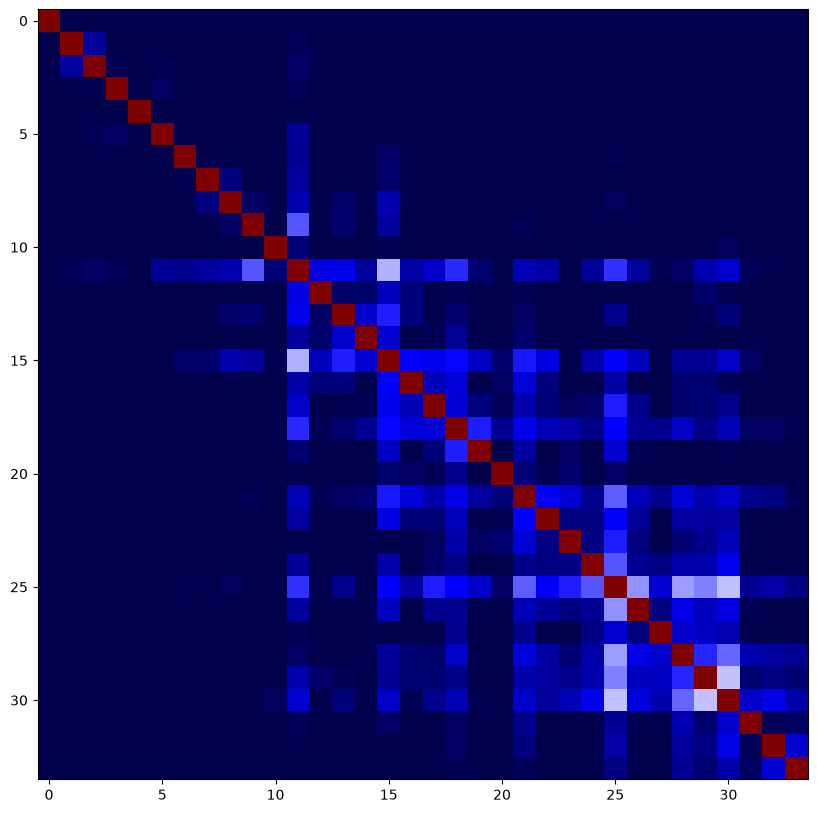

 89%|████████▉ | 108/121 [1:59:43<15:24, 71.11s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__107--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__108--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__108--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:40,  1.01it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(26492), np.int64(3737)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__108--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__108--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 886/886 [00:02<00:00, 300.97it/s]


fraction the same: 0.9528615057761254
fraction nan: 0.08710662594608949
EM iteration number:  4



100%|██████████| 886/886 [00:02<00:00, 302.67it/s]


fraction the same: 0.9791860310715709
fraction nan: 0.08710662594608949


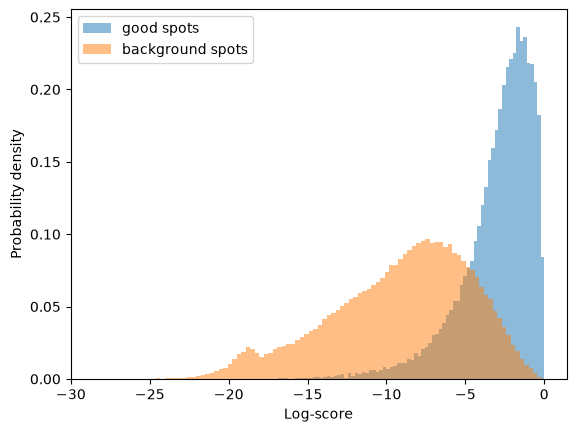

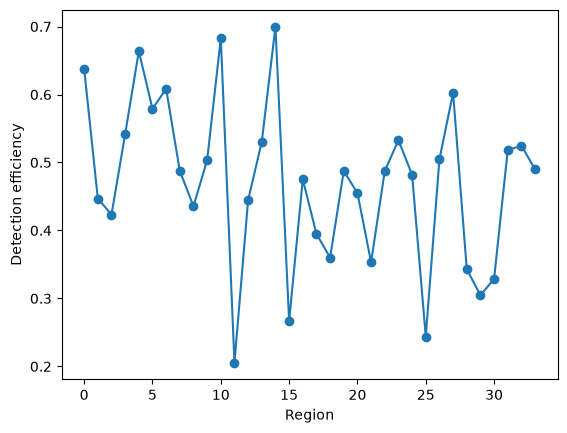

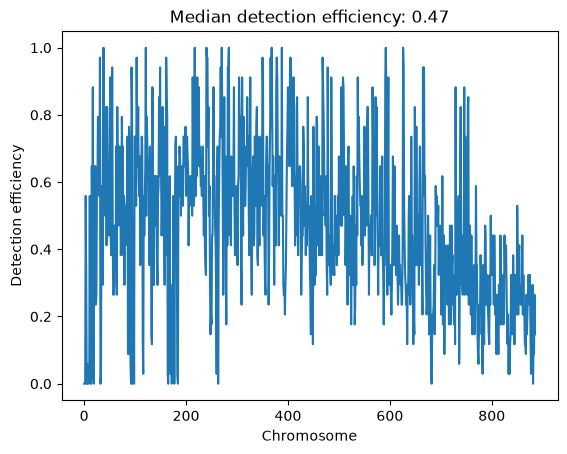

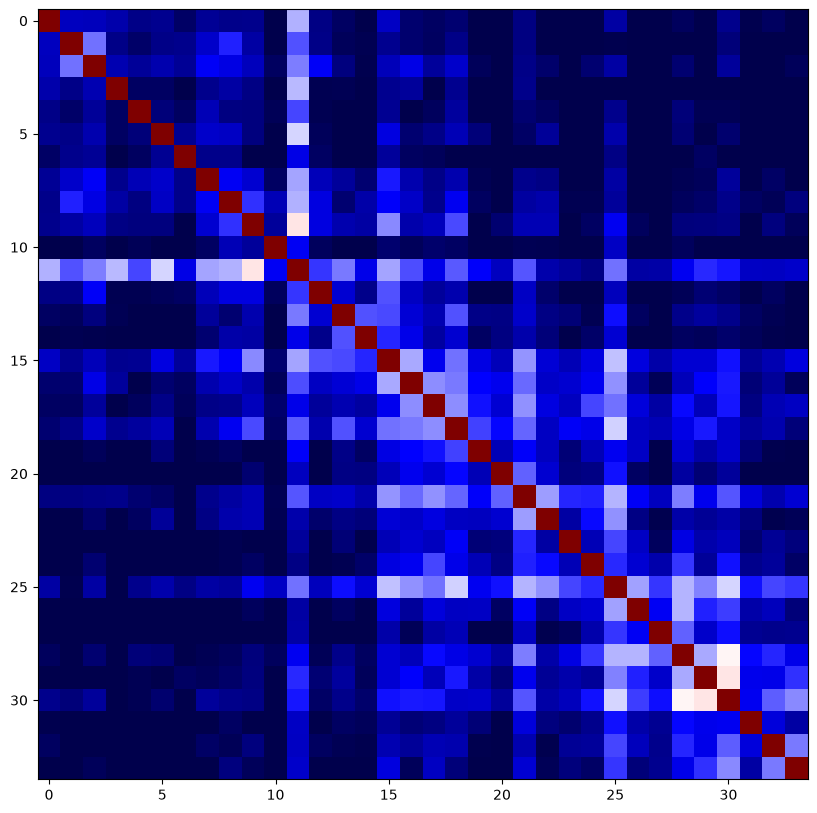

 90%|█████████ | 109/121 [2:00:58<14:26, 72.21s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__108--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__109--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__109--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(19888), np.int64(4454)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__109--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__109--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 457/457 [00:01<00:00, 289.10it/s]


fraction the same: 0.9552709486420389
fraction nan: 0.10406744754794697
EM iteration number:  4



100%|██████████| 457/457 [00:01<00:00, 351.77it/s]


fraction the same: 0.9806281374694298
fraction nan: 0.10406744754794697


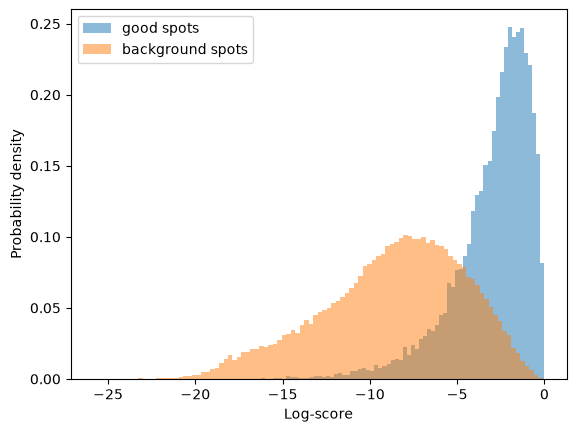

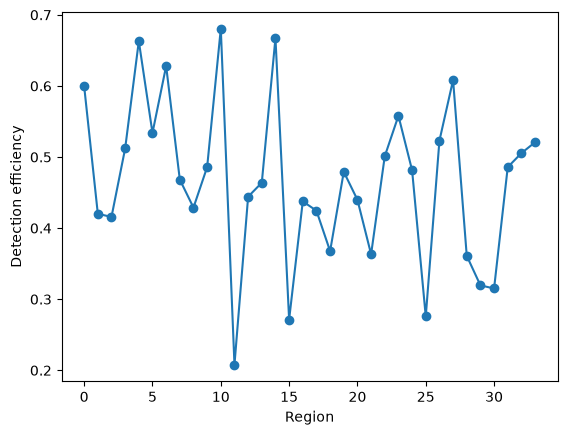

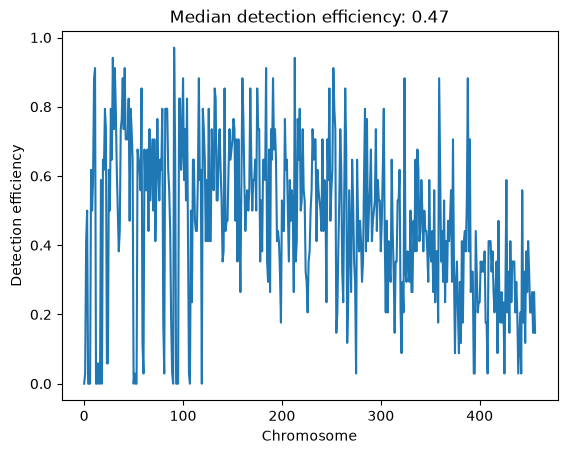

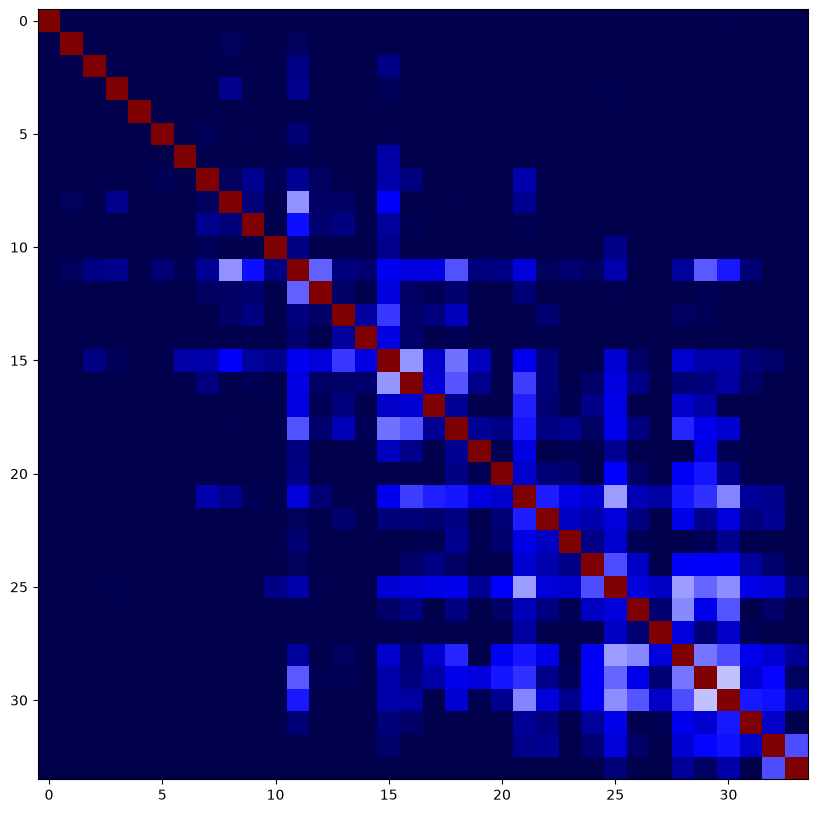

 91%|█████████ | 110/121 [2:01:50<12:09, 66.30s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__109--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__110--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__110--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:25,  1.60it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(5725), np.int64(1690)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__110--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__110--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 35/35 [00:00<00:00, 559.97it/s]


fraction the same: 0.9571428571428572
fraction nan: 0.16974789915966387
EM iteration number:  4



100%|██████████| 35/35 [00:00<00:00, 559.96it/s]


fraction the same: 0.9823529411764705
fraction nan: 0.16974789915966387


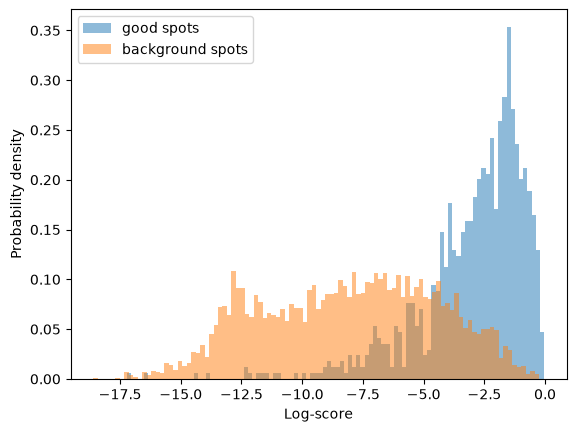

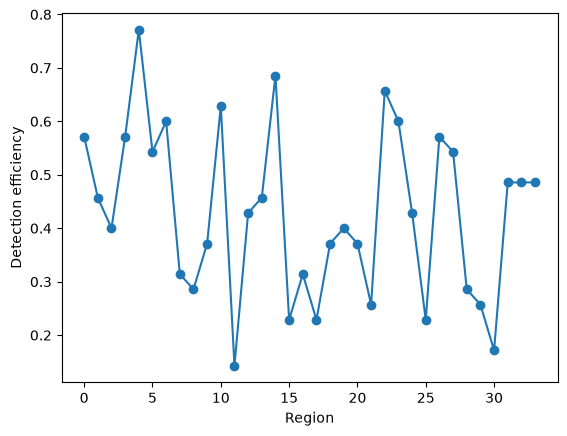

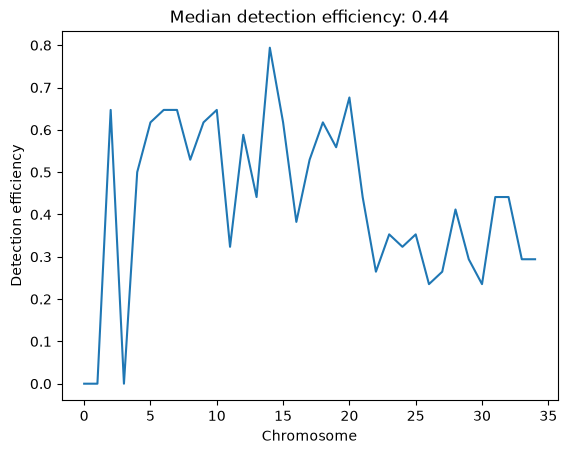

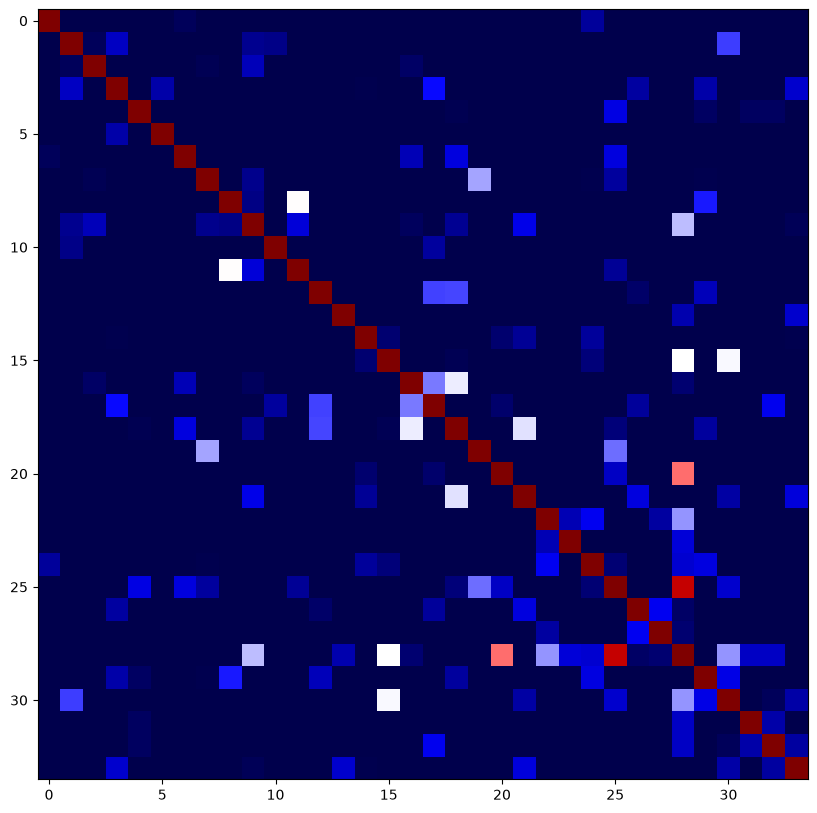

 92%|█████████▏| 111/121 [2:02:20<09:13, 55.31s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__110--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__111--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__111--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:24,  1.68it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(12420), np.int64(5053)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__111--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__111--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 324/324 [00:00<00:00, 339.06it/s]


fraction the same: 0.9497095134350036
fraction nan: 0.07416485112563544
EM iteration number:  4



100%|██████████| 324/324 [00:00<00:00, 339.07it/s]


fraction the same: 0.9774872912127814
fraction nan: 0.07416485112563544


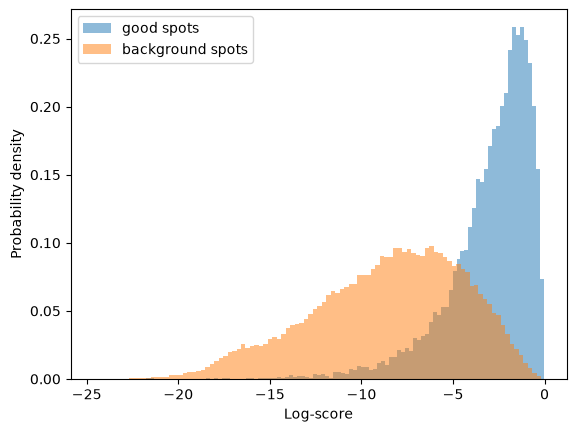

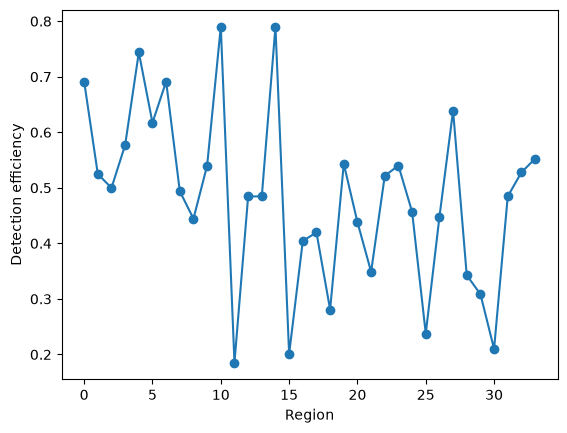

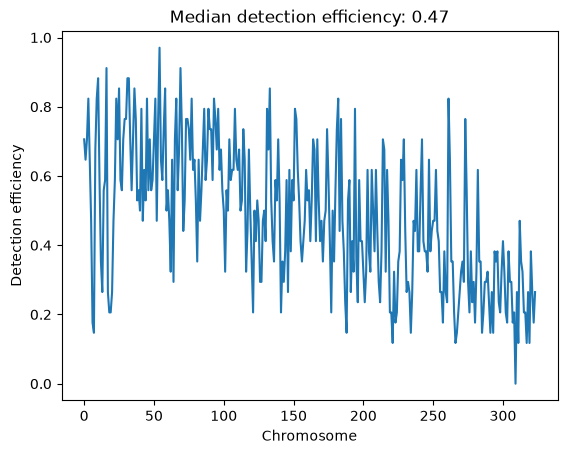

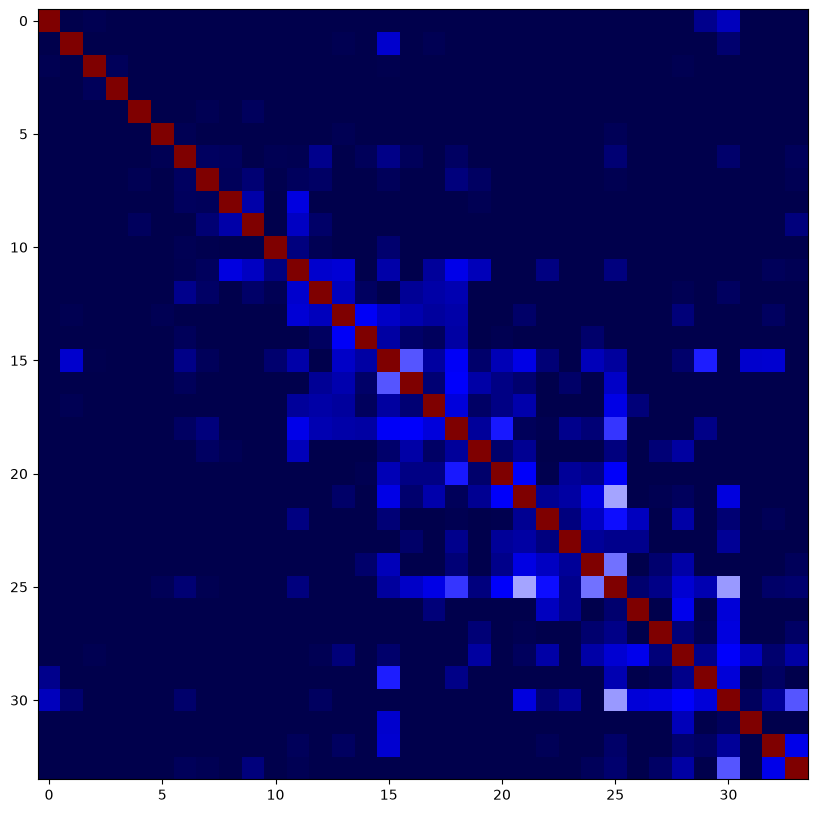

 93%|█████████▎| 112/121 [2:02:57<07:30, 50.04s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__111--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__112--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__112--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.41it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(21662), np.int64(2650)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__112--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__112--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1143/1143 [00:03<00:00, 310.36it/s]


fraction the same: 0.946091297411353
fraction nan: 0.09487417014049715
EM iteration number:  4



100%|██████████| 1143/1143 [00:03<00:00, 311.48it/s]


fraction the same: 0.9772013792393598
fraction nan: 0.09487417014049715


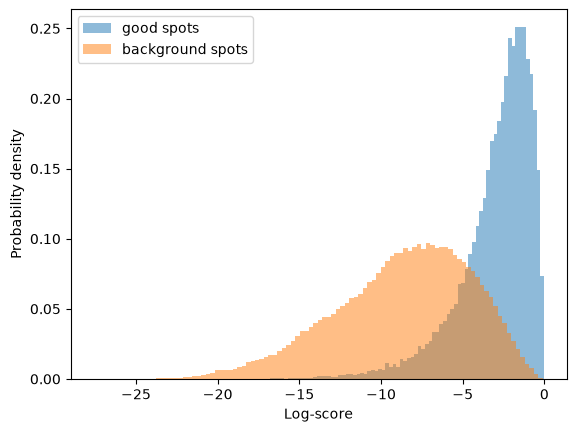

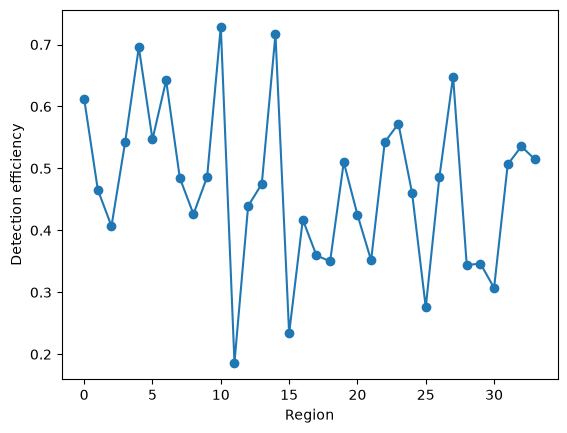

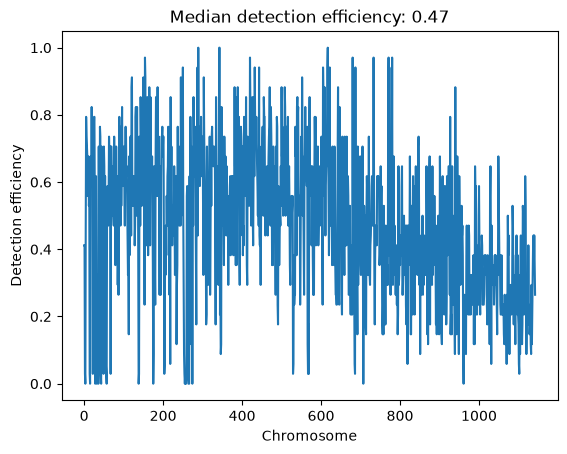

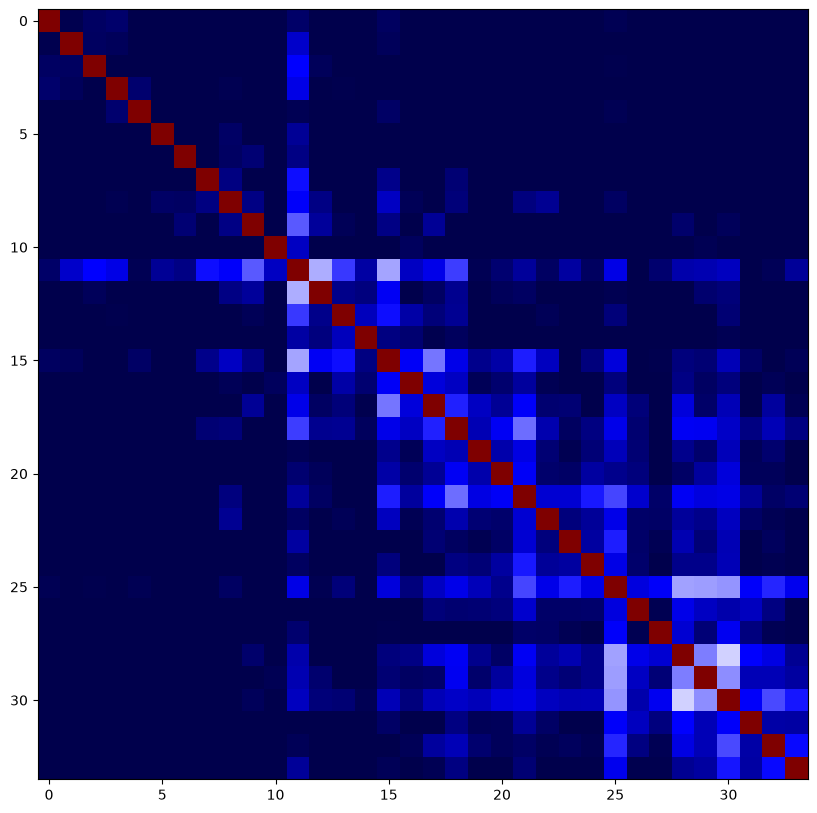

 93%|█████████▎| 113/121 [2:04:18<07:52, 59.06s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__112--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__113--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__113--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:31,  1.28it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(18619), np.int64(4081)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__113--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__113--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1107/1107 [00:03<00:00, 319.67it/s]


fraction the same: 0.9487751740262501
fraction nan: 0.0914766990807163
EM iteration number:  4



100%|██████████| 1107/1107 [00:03<00:00, 317.12it/s]


fraction the same: 0.9773101652585153
fraction nan: 0.0914766990807163


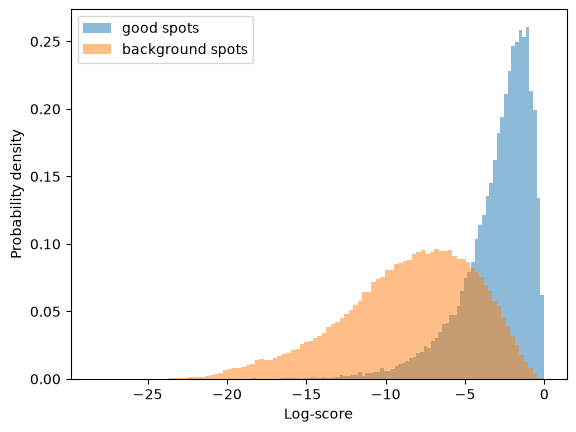

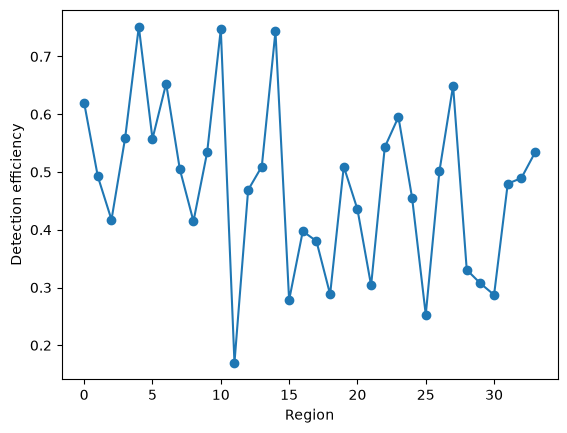

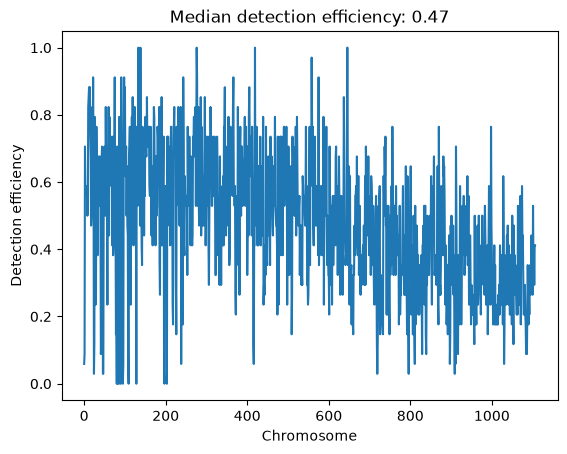

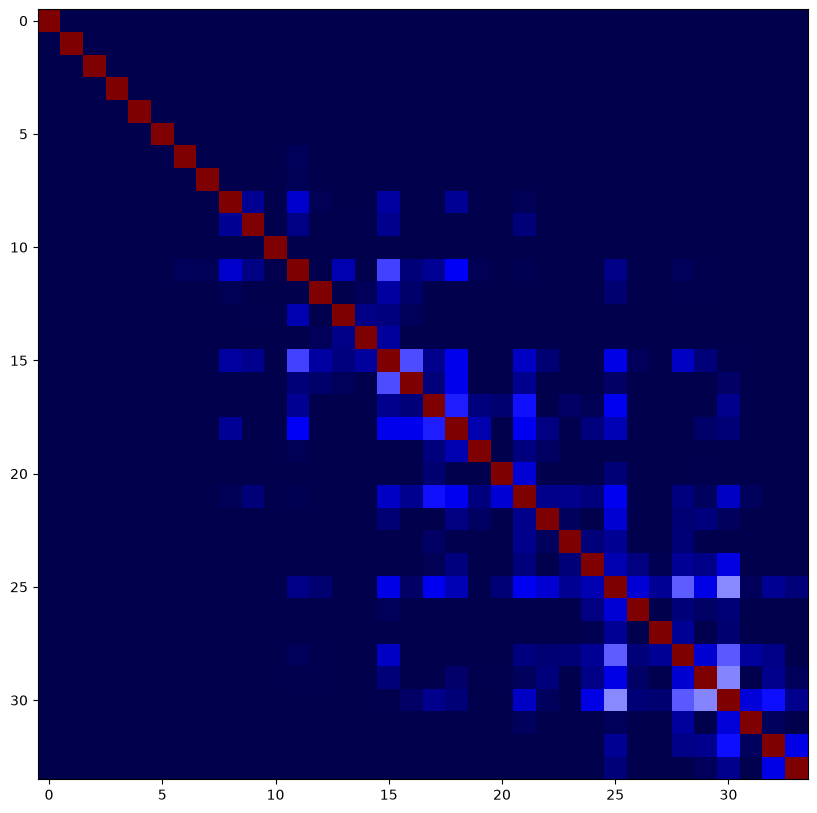

 94%|█████████▍| 114/121 [2:05:36<07:33, 64.79s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__113--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__114--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__114--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:26,  1.56it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(7964), np.int64(3378)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__114--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__114--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 164/164 [00:00<00:00, 383.46it/s]


fraction the same: 0.9553443328550932
fraction nan: 0.1327116212338594
EM iteration number:  4



100%|██████████| 164/164 [00:00<00:00, 374.82it/s]


fraction the same: 0.9818866571018652
fraction nan: 0.1327116212338594


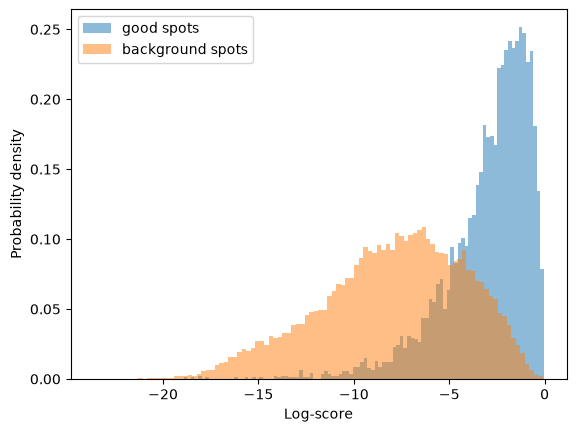

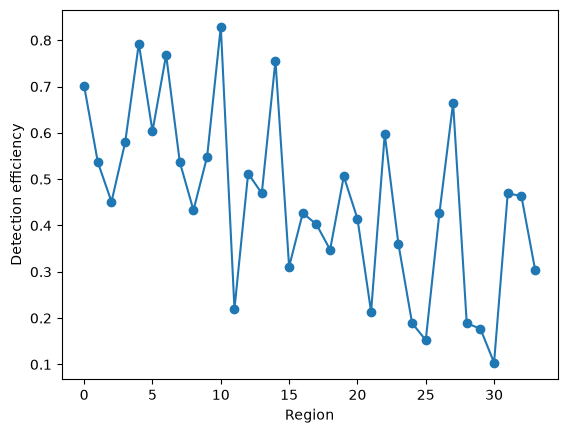

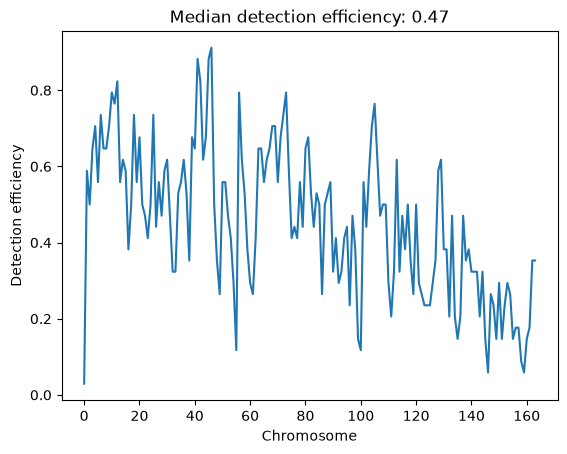

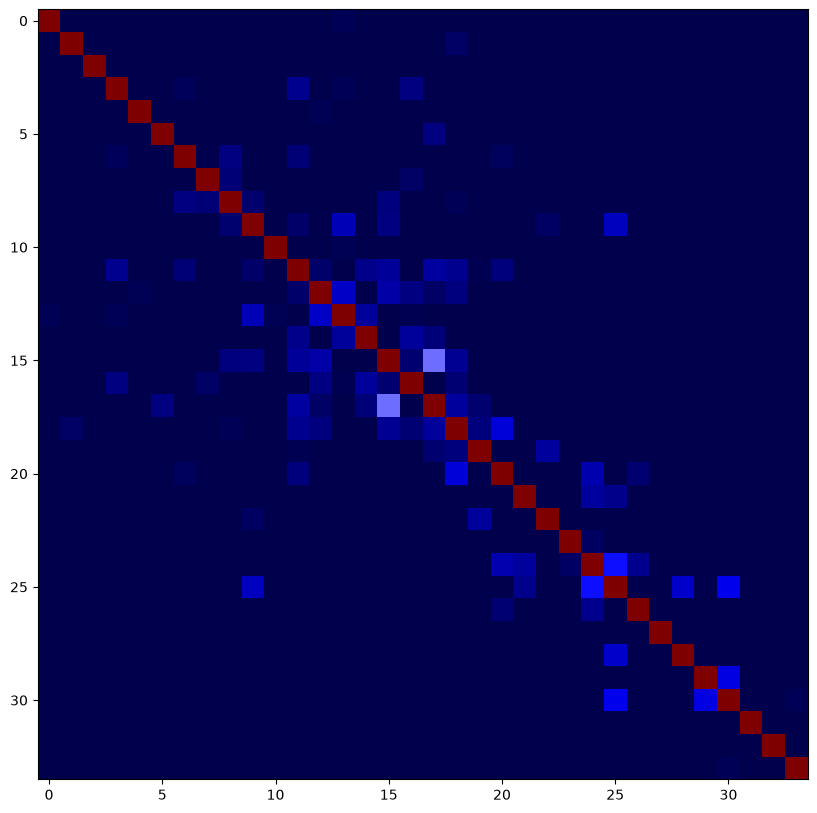

 95%|█████████▌| 115/121 [2:06:21<05:53, 58.84s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__114--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__115--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__115--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:28,  1.42it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(12874), np.int64(8475)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__115--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__115--H10_NC_set1--dapiFeatures.npz


... (180 outputs left out)


100%|██████████| 500/500 [00:01<00:00, 329.07it/s]


fraction the same: 0.9482941176470588
fraction nan: 0.08252941176470588
EM iteration number:  4



100%|██████████| 500/500 [00:01<00:00, 328.82it/s]


fraction the same: 0.9761176470588235
fraction nan: 0.08252941176470588


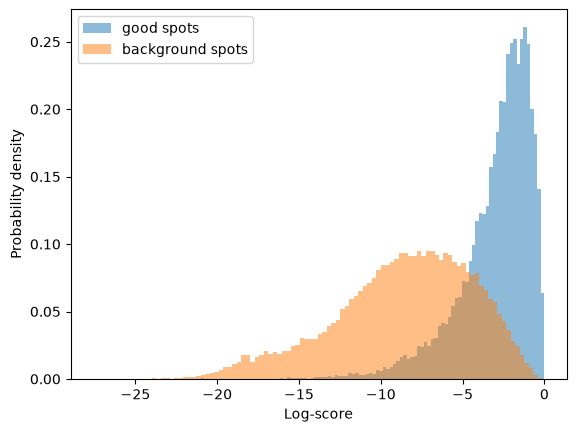

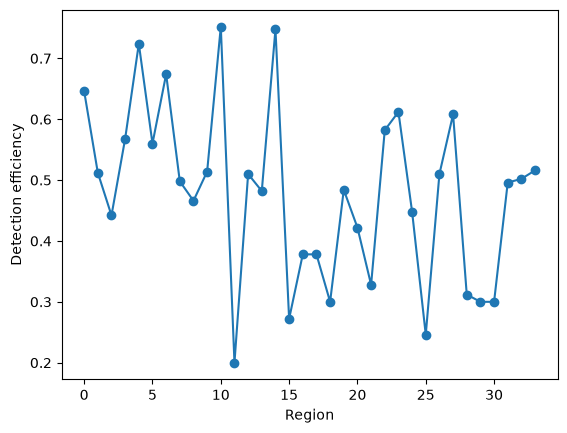

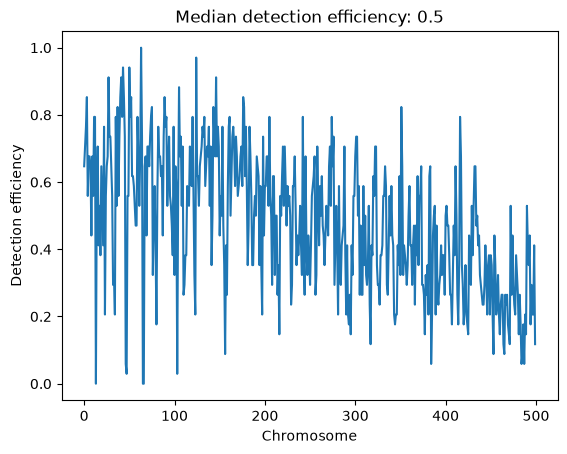

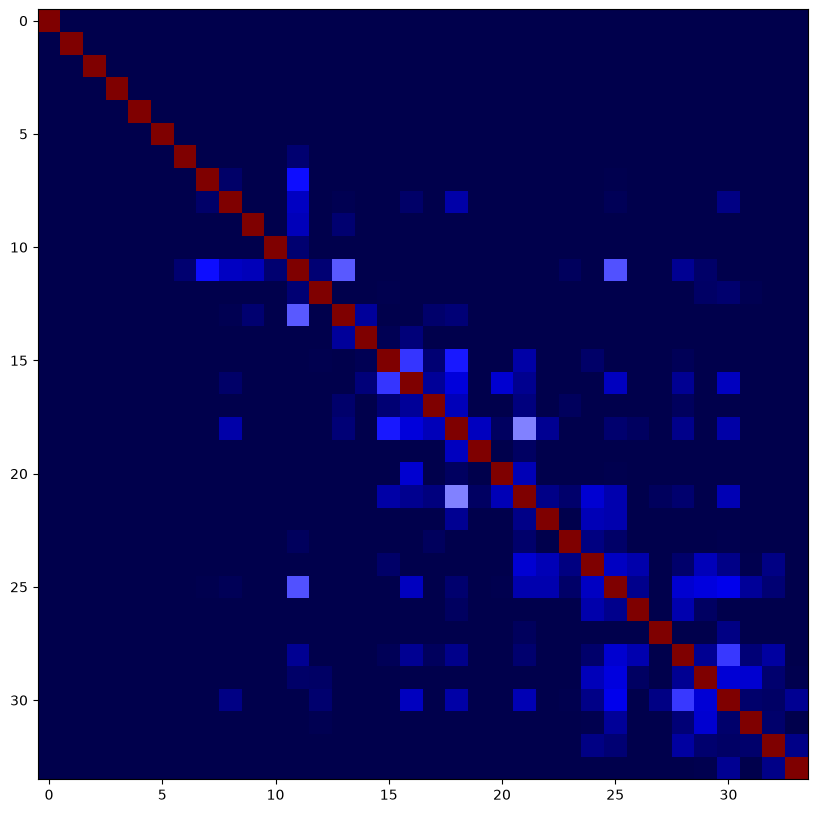

 97%|█████████▋| 117/121 [2:07:46<03:25, 51.39s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__116--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__117--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__117--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:18,  2.20it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(7991), np.int64(3073)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__117--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__117--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 62/62 [00:00<00:00, 491.89it/s]


fraction the same: 0.9549335863377609
fraction nan: 0.15749525616698293
EM iteration number:  4



100%|██████████| 62/62 [00:00<00:00, 495.97it/s]


fraction the same: 0.9796015180265655
fraction nan: 0.15749525616698293


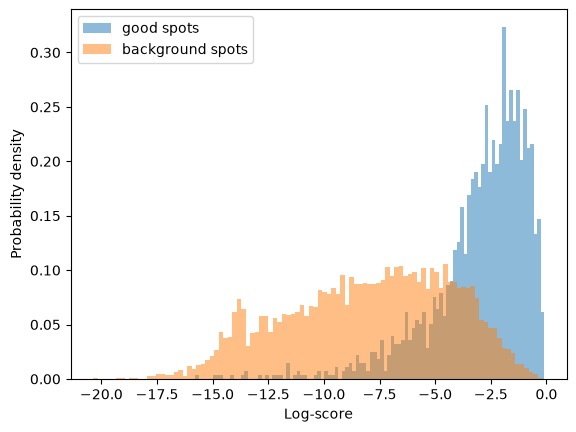

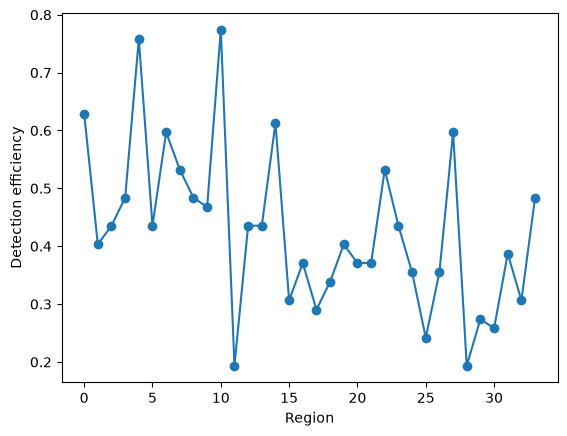

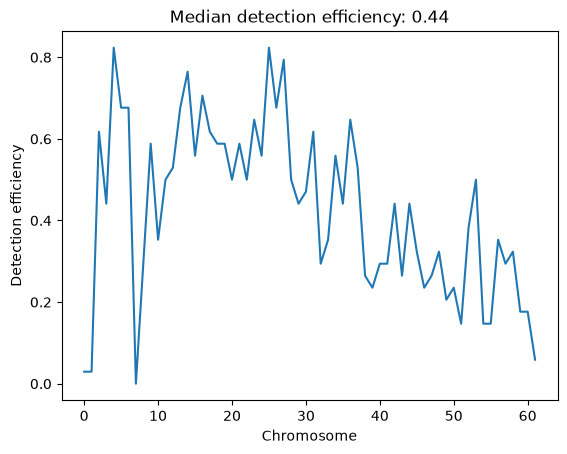

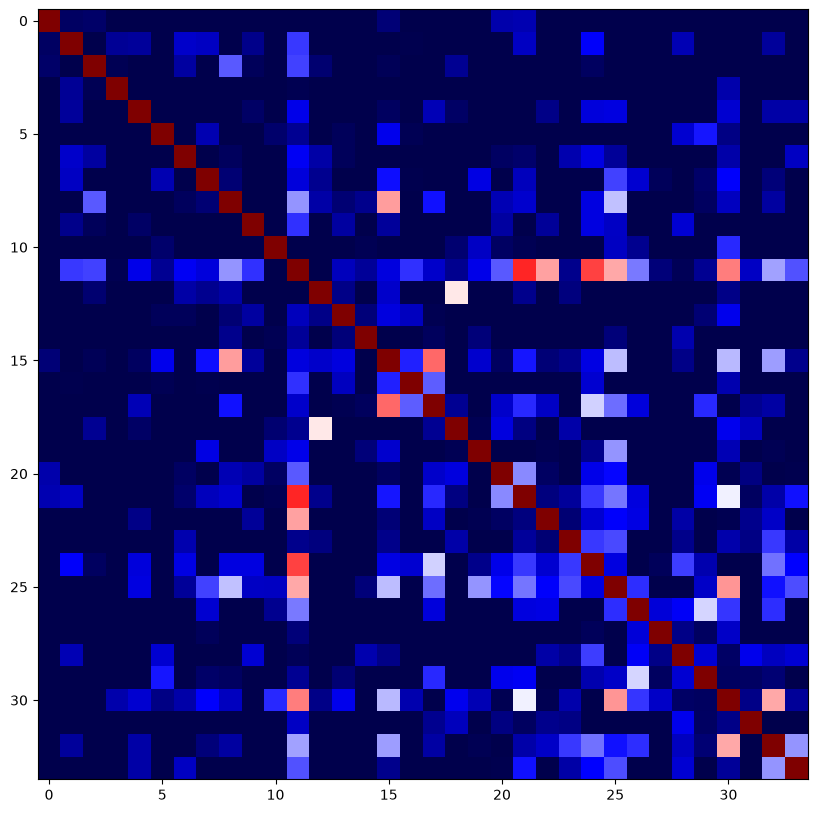

 98%|█████████▊| 118/121 [2:08:09<02:08, 42.92s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__117--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__118--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__118--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:26,  1.52it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(24941), np.int64(4786)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__118--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__118--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 1177/1177 [00:04<00:00, 283.57it/s]


fraction the same: 0.9404018191813683
fraction nan: 0.0677695037233245
EM iteration number:  4



100%|██████████| 1177/1177 [00:04<00:00, 264.66it/s]


fraction the same: 0.9738367734519466
fraction nan: 0.0677695037233245


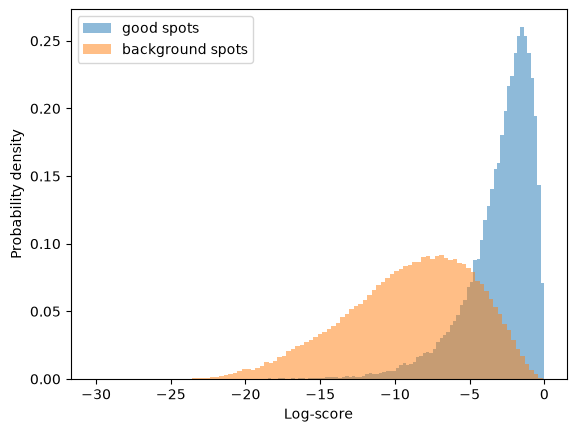

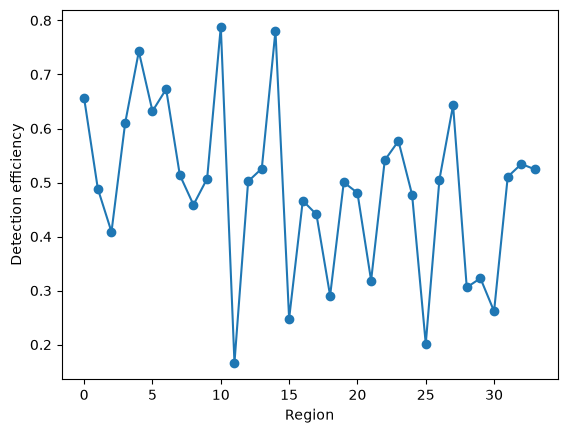

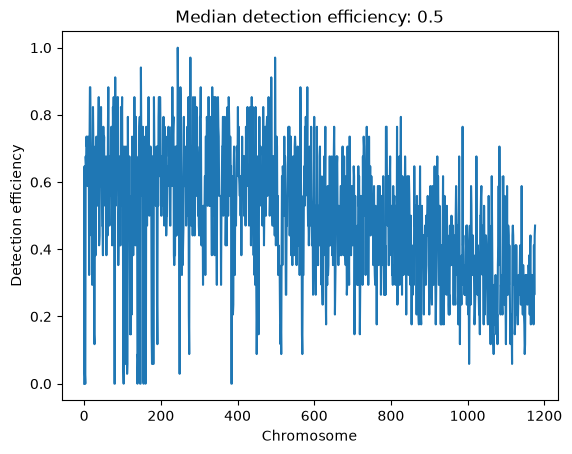

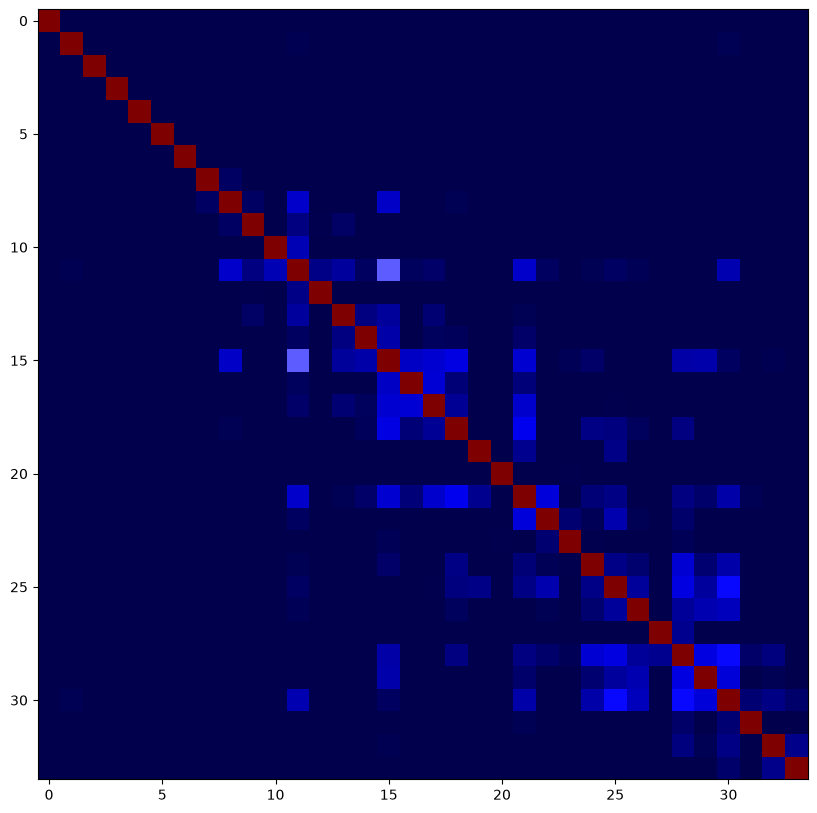

 98%|█████████▊| 119/121 [2:09:28<01:47, 53.66s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__118--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__119--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__119--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:29,  1.39it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(8076), np.int64(3161)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__119--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__119--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 3/3 [00:00<?, ?it/s]


fraction the same: 0.8823529411764706
fraction nan: 0.2647058823529412
EM iteration number:  4



100%|██████████| 3/3 [00:00<?, ?it/s]

fraction the same: 0.9117647058823529
fraction nan: 0.2647058823529412


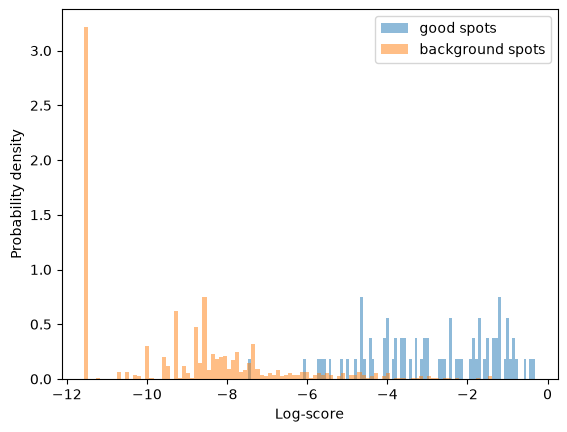

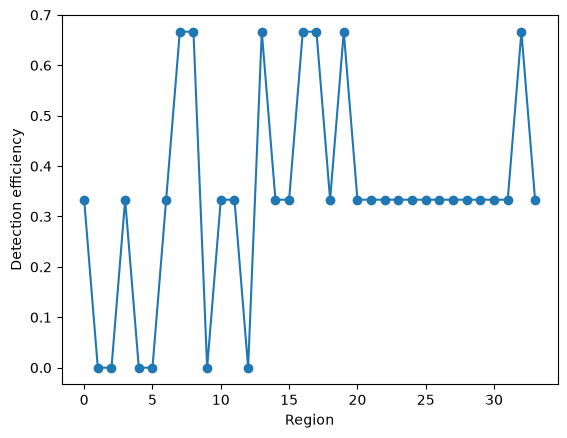

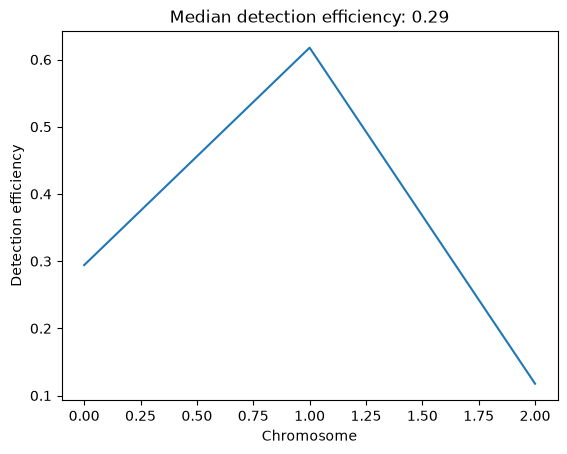

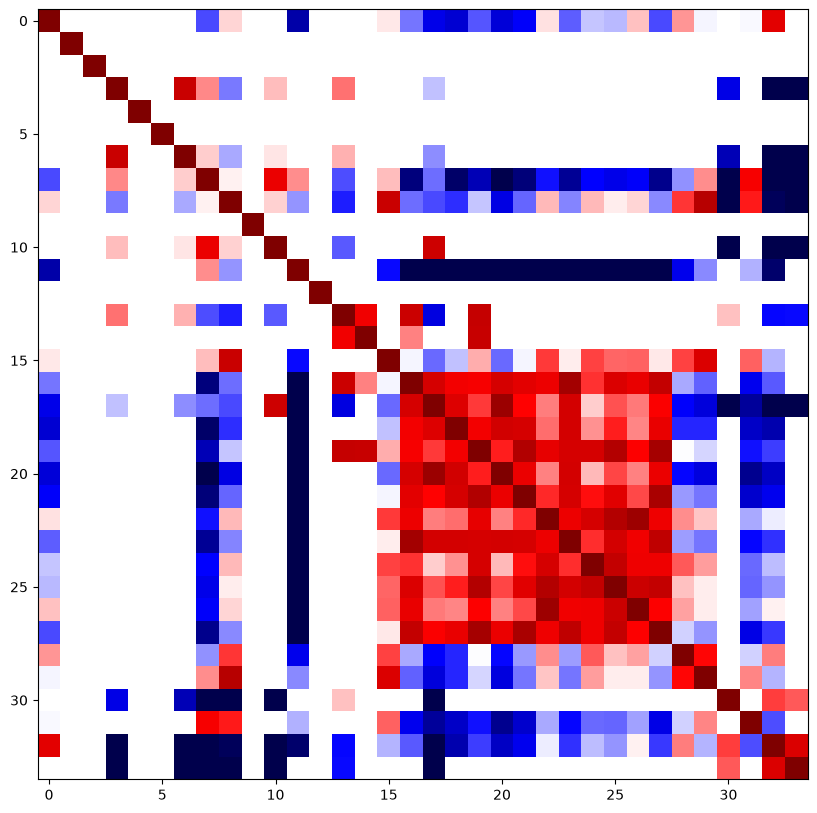

 99%|█████████▉| 120/121 [2:09:59<00:47, 47.04s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__119--__XHfs_finedrft_save.npz



  0%|          | 0/42 [00:00<?, ?it/s]

\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__120--H10_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__120--H10_NC_set1--dapiFeatures.npz



  2%|▏         | 1/42 [00:00<00:27,  1.52it/s]

[array([-0., -0., -0.]), array([0., 0., 0.], dtype=float32), array([0., 0., 0.], dtype=float32), np.int64(6770), np.int64(2000)]
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__120--H11_NC_set1--dapiFeatures.npz
\\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\Conv_zscan__120--H10_NC_set1--dapiFeatures.npz


... (92 outputs left out)


100%|██████████| 30/30 [00:00<00:00, 383.98it/s]


fraction the same: 0.9382352941176471
fraction nan: 0.07647058823529412
EM iteration number:  4



100%|██████████| 30/30 [00:00<00:00, 383.97it/s]


fraction the same: 0.961764705882353
fraction nan: 0.07647058823529412


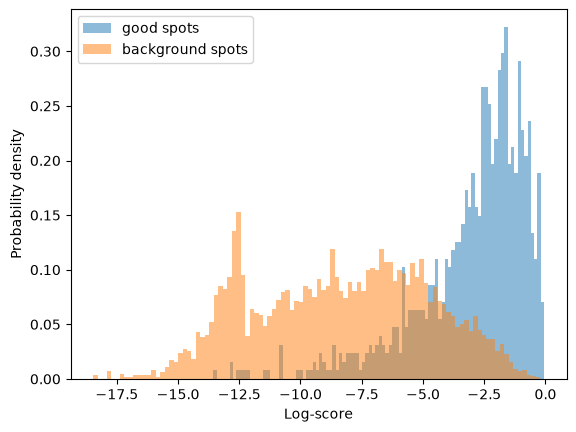

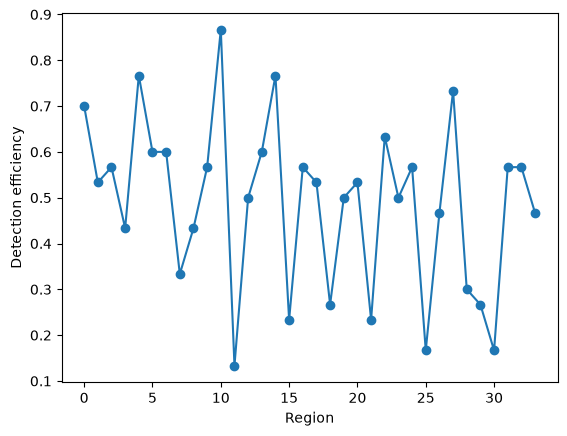

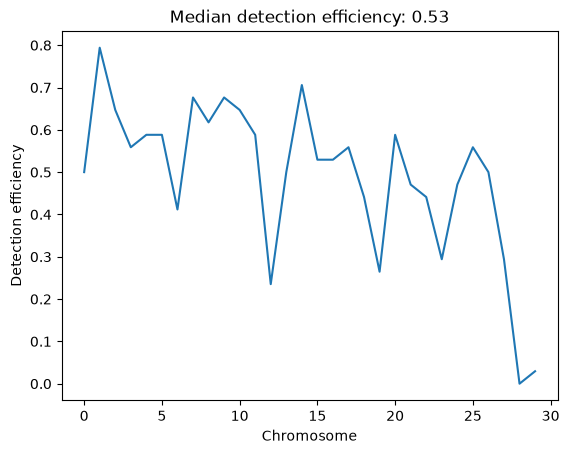

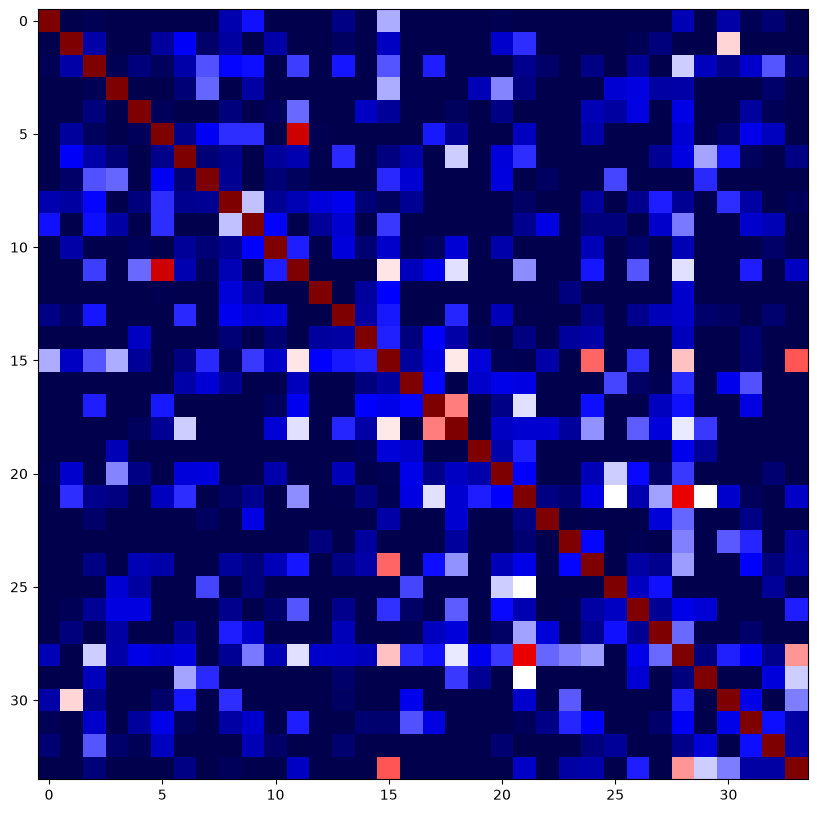

100%|██████████| 121/121 [2:10:29<00:00, 64.71s/it]

Saved: \\merfish13\Public\Fugui_Jess\Myh67_mouse_Kiwi_09_21_2026\xfits\best_per_cell\Conv_zscan__120--__XHfs_finedrft_save.npz


In [142]:
for ifov in tqdm(cp.completed_fovs):
    try:
        set_fls(cp,ifov,tag_save='best_per_cell')
        if not os.path.exists(cp.save_fl):
            load_XH(cp)
            load_segmentation(cp)
            nRegs = 34
            uRs = np.arange(nRegs)
            XH_f = np.concatenate([cp.XR_um,cp.XH,cp.cellids[:,np.newaxis]],axis=-1)
            XH_f = XH_f[XH_f[:,-2]<nRegs]
            XH_f = XH_f[XH_f[:,-1]>0]
            cp.XH_f=XH_f
            XH_fs = keep_best_per_cell_fast(XH_f,nbest=100)
            cp.XH_fs=XH_fs
            np.savez(cp.save_fl,XH_fs=XH_fs)
            # XH_f = np.concatenate([cp.XR_um,cp.XH,cp.cellids[:,np.newaxis]],axis=-1)
            # XH_f = XH_f[XH_f[:,-1]>0]
            # cp.XH_f=XH_f
            # XH_fs = keep_best_per_cell_fast(XH_f,nbest=30)
            # cp.XH_fs=XH_fs
            # np.savez(cp.save_fl,XH_fs=XH_fs)
        else:
            XH_fs = np.load(cp.save_fl)['XH_fs']
        
        
        cp.save_flf= cp.save_fl.replace('.npz','_save.npz')
        print(cp.save_flf)
        if not os.path.exists(cp.save_flf):

            get_X_cands(cp,keep_best_per_cell_fast(XH_fs,100),nchr_=2,pix=[1,1,1],
                     radius_chr = 1.5,radius_cand =2,fr_th=0.4,nelems=5,plt_val = False)

            #uRs = np.arange(42)#np.unique(XH_fs[:,-2],axis=-1).astype(int)
            initialize_with_max_brightness(cp,nkeep = 8000,Rs_u = uRs)
            
            #normalize_color_brightnesses(cp)
            cp.X_cands_=cp.X_cands
            run_EM(cp,nkeep = 80000,niter = 4,Rs_u = uRs)
            
            get_scores_and_threshold(cp,th_score = -2.5)
            plot_matrix(cp,th_score=-2.5,lazy_color_correction = False,vmin=0,vmax=0.6)
            plt.show()
            np.savez(cp.save_flf,zxys_f = cp.zxys_f,hs_f = cp.hs_f,cells_f=cp.icell_cands,scores_f=cp.scores_f)
            print("Saved:",cp.save_flf)
            # get_X_cands(cp,keep_best_per_cell_fast(XH_fs,10),nchr_=3,pix=[1,1,1],
            #                      radius_chr = 1.25,radius_cand =1.25,fr_th=0.4,nelems=5,plt_val = False)
            
            
            # uRs = np.arange(42)#np.unique(XH_fs[:,-2],axis=-1).astype(int)
            # initialize_with_max_brightness(cp,nkeep = 8000,Rs_u = uRs)
            
            # normalize_color_brightnesses(cp)
            
            # run_EM(cp,nkeep = 80000,niter = 4,Rs_u = uRs)
            
            
            # get_scores_and_threshold(cp,th_score = -2.5)
            # plot_matrix(cp,th_score=-2.5,lazy_color_correction = False,vmin=0,vmax=0.75)
            # plt.show()
            # np.savez(cp.save_flf,zxys_f = cp.zxys_f,hs_f = cp.hs_f,cells_f=cp.icell_cands,scores_f=cp.scores_f)
            # print("Saved:",cp.save_flf)
    except:
        print("Error:",ifov)